In [ ]:
# ======= Cell 1: Imports and paths ==========
import json, math, time, importlib
import numpy as np
import os
import sys
import ee
import torch
from google.colab import drive
drive.mount('/content/drive')
import rasterio
import gc


# ==================================
# PATHS
# ==================================


PROJECT_NAME = "dsm_dtm_calibration_TTT"
BASE_DIR = f"/content/drive/MyDrive/{PROJECT_NAME}"

DIGIMAP_RAW = f"{BASE_DIR}/digimap_raw"
SATMAE_DIR = f"{BASE_DIR}/satmae"
GEE_DIR = f"{BASE_DIR}/gee"

for folder in [BASE_DIR, SATMAE_DIR, GEE_DIR, DIGIMAP_RAW]:
  if not os.path.exists(folder):
    os.makedirs(folder)

if SATMAE_DIR not in sys.path:
  sys.path.append(SATMAE_DIR)

COPR_DSM_PTH = f"{GEE_DIR}/Copernicus_GLO30_v2.tif"
DTM_FOLDER = f"{BASE_DIR}/digimap_raw/digimap_dtm/v2"
FEAT_STACK_PTH = f"{GEE_DIR}/DSM_Calibration_Feature_Stack.tif"
COPR_DSM_PTH = f"{GEE_DIR}/Copernicus_GLO30_v2.tif"

print("CELL 1: PASSED")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
CELL 1: PASSED


## Model architecture

Components:
- Encoder: CNN convolution, not ViT - 2d convolution into a latent space of 64
- Spatial Memory Bank: instantiated with the same number of nodes (pixels) as the DSM
- Retriever: a GAT that routes the TTT memory stored in the bank using dynamic similarity and distance penalties, and the weights are learned with a lighweight MLP
- Decoder: output = [B, c_mem+c_feat, H, W], using NLL instead of conventional MSE or MAE, hence the output dim = 2 (mean and variance)

In [ ]:
# ======= MODEL ARCHITECTURE =============
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
from torch.utils.checkpoint import checkpoint


# ---- helper classes and features -------
class ChannelNorm(nn.Module):
  """ layernorm over channels at each pixel. Unlike GroupNorm does not use statistics over the window, a pixel's features does not change with the window"""
  def __init__(self, c):
    super().__init__()
    self.ln = nn.LayerNorm(c)

  def forward(self, x):
    return self.ln(x.permute(0, 2, 3, 1)).permute(0, 3, 1, 2) # [B, C, H W]

def hann_2d(ph, pw, device, floor=0.1):
  """Seperable hann window with a floor to ensure edge pixels never get 0 weight"""
  wy = torch.hann_window(ph, periodic=False, device=device)
  wx = torch.hann_window(pw, periodic=False, device=device)
  wy, wx = floor + (1 - floor) * wy, floor + (1 - floor) * wx
  return wy[:, None] * wx[None, :]

def window_starts(n, p, stride):
  """window start position that covers (0, n) completely, last window flush with edge"""
  if n <= p:
    return [0]
  s = list(range(0, n - p + 1, stride))
  if s[-1] != n - p:
    s.append(n - p)
  return s


# ==============
# FEATURE ENCODING
# - CNN-conv encoding into a latent space for feature map
# ==============
class DSMEncoder(nn.Module):
  "Processes Geotiff into a dense topological feature map F"
  def __init__(self, in_channels=9, feature_dim=64):
    super().__init__()
    self.net = nn.Sequential(
        nn.Conv2d(in_channels, 32, kernel_size=3, padding=1),
        ChannelNorm(32),
        nn.GELU(),
        # Dilated convolution to expand physical receptive field
        nn.Conv2d(32, 64, kernel_size=3, padding=2, dilation=2),
        ChannelNorm(64),
        nn.GELU(),
        nn.Conv2d(64, feature_dim, kernel_size=3, padding=1)
    )

  def forward(self, x):
    return self.net(x)

class Trunk(nn.Module):
  """
  Seperated: The two convolutional layers prior to the final layer. Previous version TTT is not implemented well
  """
  def __init__(self, feature_dim=64, hidden_dim=64):
    super().__init__()
    self.net = nn.Sequential(
        nn.Conv2d(feature_dim, feature_dim * 2, kernel_size=3, padding=1),
        ChannelNorm(feature_dim * 2),
        nn.GELU(),
        nn.Conv2d(feature_dim*2, hidden_dim, 3, padding=1),
        ChannelNorm(hidden_dim),
    )

  def forward(self, f):
    return self.net(f)

# ================
# DIFFUSER MECHANISM USING GAT AND MULTILAYER COARSE GRID
# ================
class Grid_Diffuser(nn.Module):
  """
  Diffuser class motivated by Graph Attention Networks (GAT)
  - Coarse Memory Grid motivated by Instant Neural Graphics Primitives with a Multiresolution Hash Encoding (NVIDIA 2022)
  Changed implementation 10/10/26 - additive GATv2-style attention
  """
  def __init__(self, feature_dim=64, n_levels=3, hidden_dim=32):
    super().__init__()
    self.q = nn.Linear(feature_dim, hidden_dim)
    self.k = nn.Linear(feature_dim, hidden_dim)
    self.level_emb = nn.Parameter(torch.zeros(n_levels, hidden_dim))
    self.count_proj = nn.Linear(1, hidden_dim) # attention trusts well-sampled nodes
    self.mlp = nn.Sequential(nn.GELU(), nn.Linear(hidden_dim, hidden_dim), nn.GELU())
    self.sim_head = nn.Linear(hidden_dim, 1)
    self.gamma_head = nn.Sequential(nn.Linear(hidden_dim, 1), nn.Softplus())

  def forward(self, q_feat, pix_xy, levels):
    """
    q_feat: [B, F], pix_xy: [B, 2] = (x,y) pixel indices
    levels: list of dicts with k [G, hidden], w [G, Dh], count [G]
    Returns dW [N, Dh] and aux [B, 3] = (support, log1p(dist_to_data), has_data)
    """
    q = self.q(q_feat)
    scores, ws, logcs, dist, mask = [], [], [], [], []
    for li, L in enumerate(levels):
      # node i = sum pixel [i*r, (i+1)*r], sits at (i + 0.5)*r
      gx = pix_xy[:, 0] / L['rx'] - 0.5
      gy = pix_xy[:, 1] / L['ry'] - 0.5
      x0, y0 = gx.floor().long(), gy.floor().long()
      xs = torch.stack([x0, x0+1, x0, x0+1], -1) # TL, TR, BL, BR
      ys = torch.stack([y0, y0, y0+1, y0+1], -1)
      inb = (xs >= 0) & (xs < L['Wg']) & (ys >= 0) & (ys < L['Hg'])
      idx = ys.clamp(0, L['Hg'] - 1) * L['Wg'] + xs.clamp(0, L['Wg'] - 1)

      count = L['count'][idx]
      valid = inb & (count > 0) # empty nodes dont vote for diffusion
      d2 = (gx[:, None] - xs.float()) ** 2 + (gy[:, None] - ys.float()) ** 2
      lc = torch.log1p(count)

      e = self.mlp(q[:, None] + L['k'][idx] + self.level_emb[li] + self.count_proj(lc.unsqueeze(-1)))
      s = self.sim_head(e).squeeze(-1) - self.gamma_head(e).squeeze(-1) * d2

      scores.append(s)
      ws.append(L['w'][idx])
      logcs.append(lc)
      dist.append(d2.sqrt() * L['res_km'])
      mask.append(valid)

    S = torch.cat(scores, -1).float()
    M = torch.cat(mask, -1)
    alpha = torch.softmax(S.masked_fill(~M, -1e4), -1) * M # all zero if no valid node
    dW = (alpha.unsqueeze(-1) * torch.cat(ws, 1)).sum(1)

    support = (alpha * torch.cat(logcs, -1)).sum(-1)
    dmin = torch.cat(dist, -1).masked_fill(~M, 1e3).amin(-1).clamp(max=100.0)
    aux = torch.stack([support, torch.log1p(dmin), M.any(-1).float()], -1)

    return dW, aux

# =====
# TTT-layer: previously undefined - which is an oversight
# =====
def ttt_fit_final_layer(h_obs, r_obs, node_flat, n_nodes, lam, weight=None, chunk=8192):
  """
  Per-node n: dW_n = argmin sum_{i in n} w_i (r_i - dW . h_i)^2 + lam * |dW|^2
  Closed form via accumulated normal equations (no padding).
  Memory ~ U*Dh*Dh + chunk*Dh*Dh floats, independent of points per node.
  """
  N, Dh = h_obs.shape
  dev, dt = h_obs.device, torch.float32

  with torch.autocast(device_type=dev.type, enabled=False):
      if weight is None:
          weight = torch.ones(N, device=dev, dtype=dt)
      count = torch.zeros(n_nodes, device=dev, dtype=dt).index_add(0, node_flat, weight.detach().to(dt))
      w_grid = torch.zeros(n_nodes, Dh, device=dev, dtype=dt)
      if N == 0:
          return w_grid, count

      h = h_obs.to(dt)
      r = r_obs.to(dt)
      w = weight.to(dt)

      # compact to nodes that actually have data
      uniq, inv = torch.unique(node_flat, return_inverse=True)
      U = uniq.numel()

      A = torch.zeros(U, Dh, Dh, device=dev, dtype=dt)
      b = torch.zeros(U, Dh, device=dev, dtype=dt)
      for s in range(0, N, chunk):
          hc, rc, wc, ic = h[s:s + chunk], r[s:s + chunk], w[s:s + chunk], inv[s:s + chunk]
          hw = hc * wc[:, None]                                    # w_i * h_i
          A = A.index_add(0, ic, hw[:, :, None] * hc[:, None, :])  # sum w h h^T
          b = b.index_add(0, ic, hw * rc[:, None])                 # sum w h r

      A = A + lam.to(dt) * torch.eye(Dh, device=dev, dtype=dt)

      # CPU solve as before (batched GPU solver issue on T4 + CUDA 13)
      dW = torch.linalg.solve(A.cpu(), b.cpu()).to(dev)

      return w_grid.index_copy(0, uniq, dW), count

# =====================
# FINAL ARCHITECTURE
# - hann window sliding structure
# - fixed node_res in meters (the spatial length of one grid node)
# v2 - updated for using sigma to bound loss_variance window for more efficient and less hardcoded predictions
# =====================

class ProbabilisticCalibrator(nn.Module):
  def __init__(self, in_channels=9, feature_dim=64, hidden_dim=64, pixel_m=30.0,
                level_res_m=(1000.0, 4000.0, 16000.0), diffuser_hid=32,
                patch_size=64, overlap=32, win_batch=64, chunk=64*64,
                sigma_min=0.1, sigma_max=30.0, grad_checkpoint=True):
      super().__init__()
      self.feature_dim = feature_dim
      self.hidden_dim = hidden_dim
      self.pixel_m = pixel_m
      self.level_res_m = tuple(level_res_m)
      self.patch_size = patch_size
      self.stride = patch_size - overlap
      self.win_batch = win_batch  # windows per encoder call
      self.chunk = chunk  # pixels per diffuser call
      self.grad_checkpoint = grad_checkpoint
      # predicted sigma is bounded to [sigma_min, sigma_max] metres
      self.lv_min = 2 * math.log(sigma_min)
      self.lv_max = 2 * math.log(sigma_max)

      self.encoder = DSMEncoder(in_channels, feature_dim)
      self.decoder_body = Trunk(feature_dim, hidden_dim)
      self.grid_gat = Grid_Diffuser(feature_dim, len(level_res_m), diffuser_hid)

      # Final layer on [h, 1]. Shared default; TTT adds dW(x) from the grid.
      self.final_mu = nn.Linear(hidden_dim + 1, 1, bias=False)
      nn.init.zeros_(self.final_mu.weight)
      # Variance head: basis + how much ICESat supports this pixel
      self.final_logvar = nn.Sequential(nn.Linear(hidden_dim + 3, 32), nn.GELU(), nn.Linear(32, 1))
      # Learned weight decay of the TTT fit, one per grid level
      self.log_lam = nn.Parameter(torch.zeros(len(level_res_m)))

  def _device(self):
      return next(self.parameters()).device

  # ---------- geometry ----------
  def _grid_levels(self, dsm_h, dsm_w):
      """Grid anchored to the full DSM: node count and spacing fixed by the DSM extent."""
      out = []
      for res_m in self.level_res_m:
          res_px = res_m / self.pixel_m
          Hg, Wg = max(1, math.ceil(dsm_h / res_px)), max(1, math.ceil(dsm_w / res_px))
          rx, ry = dsm_w / Wg, dsm_h / Hg
          out.append(dict(Hg=Hg, Wg=Wg, rx=rx, ry=ry, G=Hg * Wg,
                          res_km=0.5 * (rx + ry) * self.pixel_m / 1000.0))
      return out

  @staticmethod
  def _node_index(g, gy, gx):
      """Global pixel (y, x) -> flat node index on level g."""
      ny = (gy.float() / g['ry']).floor().long().clamp(0, g['Hg'] - 1)
      nx = (gx.float() / g['rx']).floor().long().clamp(0, g['Wg'] - 1)
      return ny * g['Wg'] + nx

  def _windows(self, H, W, data_dev, dev):
      """Window corners, Hann weight and the summed weight
      per pixel `total`"""
      ph, pw = min(self.patch_size, H), min(self.patch_size, W)
      wins = [(y, x) for y in window_starts(H, ph, self.stride)
                      for x in window_starts(W, pw, self.stride)]
      w2d = hann_2d(ph, pw, dev)
      w2d_d = w2d.to(data_dev)
      total = torch.zeros(H, W, device=data_dev)
      for y, x in wins:
          total[y:y + ph, x:x + pw] += w2d_d
      return wins, ph, pw, w2d, total

  @staticmethod
  def _stack(t, wl, ph, pw, dev):
      """Cut windows wl = [(y0, x0), ...] out of t [..., H, W] -> [g, ..., ph, pw]"""
      return torch.stack([t[..., y:y + ph, x:x + pw] for y, x in wl]).to(dev)

  @staticmethod
  def _coords(wl, ph, pw, oy, ox, dev):
      """Global DSM coordinates of every pixel of windows wl -> gy, gx [g, ph, pw]."""
      y0 = torch.tensor([y for y, _ in wl], device=dev)[:, None, None]
      x0 = torch.tensor([x for _, x in wl], device=dev)[:, None, None]
      gy = (y0 + torch.arange(ph, device=dev)[None, :, None] + oy).expand(-1, ph, pw)
      gx = (x0 + torch.arange(pw, device=dev)[None, None, :] + ox).expand(-1, ph, pw)
      return gy, gx

  def _encode_raw(self, xg):
      f = self.encoder(xg)
      h = self.decoder_body(f)
      h1 = torch.cat([h, torch.ones_like(h[:, :1])], 1)    # append 1 -> bias term
      return f.float(), h1.float()

  def _encode(self, xg):
      """xg [g, C, ph, pw] -> f [g, D, ph, pw], h1 [g, Dh, ph, pw]."""
      if self.grad_checkpoint and self.training and torch.is_grad_enabled():
          return checkpoint(self._encode_raw, xg, use_reentrant=False)
      return self._encode_raw(xg)

  # ---------- pass 1: WRITE ----------
  def _write_pass(self, xb, dh, mask, wins, ph, pw, w2d, total, geoms, oy, ox):
      """xb [C, H, W], dh [H, W], mask [H, W] bool. Returns the grid levels."""
      dev = self._device()
      D, Dh = self.feature_dim, self.hidden_dim + 1
      fsum = [torch.zeros(g['G'], D, device=dev) for g in geoms]
      fwt = [torch.zeros(g['G'], device=dev) for g in geoms]
      H_l, T_l, O_l = [], [], []                 # basis, target, omega at ICESat pixels
      N_l = [[] for _ in geoms]                  # node index per level at ICESat pixels

      for s in range(0, len(wins), self.win_batch):
          wl = wins[s:s + self.win_batch]
          f, h1 = self._encode(self._stack(xb, wl, ph, pw, dev))
          omega = (w2d[None] / self._stack(total, wl, ph, pw, dev)).reshape(-1)  # partition of unity
          gy, gx = self._coords(wl, ph, pw, oy, ox, dev)
          nodes = [self._node_index(g, gy.reshape(-1), gx.reshape(-1)) for g in geoms]

          # node features for the GAT: omega-weighted average of pixel features per node
          f_flat = f.permute(0, 2, 3, 1).reshape(-1, D)
          for li in range(len(geoms)):
              fsum[li] = fsum[li].index_add(0, nodes[li], omega[:, None] * f_flat)
              fwt[li] = fwt[li].index_add(0, nodes[li], omega)

          # ICESat pixels inside these windows (if any)
          m = self._stack(mask, wl, ph, pw, dev).reshape(-1)
          if m.any():
              idx = m.nonzero(as_tuple=True)[0]
              H_l.append(h1.permute(0, 2, 3, 1).reshape(-1, Dh)[idx])
              T_l.append(self._stack(dh, wl, ph, pw, dev).reshape(-1)[idx].float())
              O_l.append(omega[idx])
              for li in range(len(geoms)):
                  N_l[li].append(nodes[li][idx])

      if H_l:
          h_obs, dh_obs, w_obs = torch.cat(H_l), torch.cat(T_l), torch.cat(O_l)
          r_obs = dh_obs - (h_obs * self.final_mu.weight.float()).sum(-1)   # residual vs shared layer
      else:
          h_obs = torch.zeros(0, Dh, device=dev)
          r_obs, w_obs = torch.zeros(0, device=dev), torch.zeros(0, device=dev)

      levels = []
      for li, g in enumerate(geoms):
          node = torch.cat(N_l[li]) if H_l else torch.zeros(0, dtype=torch.long, device=dev)
          w, cnt = ttt_fit_final_layer(h_obs, r_obs, node, g['G'], self.log_lam[li].exp(), w_obs)
          k = self.grid_gat.k(fsum[li] / fwt[li].clamp_min(1e-6)[:, None])
          levels.append(dict(g, k=k, w=w, count=cnt))
      return levels

  # ---------- pass 2: READ ----------
  def _predict_points(self, f_pts, h1_pts, pix_xy, levels):
      dW, aux = self.grid_gat(f_pts, pix_xy, levels)
      mu = ((self.final_mu.weight + dW) * h1_pts).sum(-1)
      raw = self.final_logvar(torch.cat([h1_pts[:, :-1], aux], -1)).squeeze(-1)
      logvar = self.lv_min + (self.lv_max - self.lv_min) * torch.sigmoid(raw.float())
      return mu.float(), logvar

  def _read_dense(self, xb, wins, ph, pw, w2d, total, levels, oy, ox):
      """Every pixel of the region. Returns mu, logvar [H, W]."""
      dev, ddev = self._device(), total.device
      D, Dh = self.feature_dim, self.hidden_dim + 1
      H, W = total.shape
      mu_c = torch.zeros(H, W, device=ddev)
      lv_c = torch.zeros(H, W, device=ddev)
      for s in range(0, len(wins), self.win_batch):           # left -> right, top -> bottom
          wl = wins[s:s + self.win_batch]
          g = len(wl)
          f, h1 = self._encode(self._stack(xb, wl, ph, pw, dev))
          gy, gx = self._coords(wl, ph, pw, oy, ox, dev)
          pix = torch.stack([gx, gy], -1).reshape(-1, 2).float()
          f_flat = f.permute(0, 2, 3, 1).reshape(-1, D)
          h_flat = h1.permute(0, 2, 3, 1).reshape(-1, Dh)
          mus, lvs = [], []
          for c in range(0, f_flat.shape[0], self.chunk):
              mu, lv = self._predict_points(f_flat[c:c + self.chunk], h_flat[c:c + self.chunk],
                                            pix[c:c + self.chunk], levels)
              mus.append(mu); lvs.append(lv)
          mu_w = (torch.cat(mus).view(g, ph, pw) * w2d).to(ddev)     # Hann-weighted
          lv_w = (torch.cat(lvs).view(g, ph, pw) * w2d).to(ddev)
          for j, (y, x) in enumerate(wl):
              mu_c[y:y + ph, x:x + pw] += mu_w[j]
              lv_c[y:y + ph, x:x + pw] += lv_w[j]
      return mu_c / total, lv_c / total

  def _read_queries(self, xb, q, wins, ph, pw, w2d, levels, oy, ox):
      """Only the query pixels q [Q, 2] (y, x in region coords), Hann-blended across the
      windows that contain them. Returns mu, logvar [Q] on the model device."""
      dev = self._device()
      q = q.to(dev).long()
      qy, qx = q[:, 0], q[:, 1]
      Q = q.shape[0]
      starts = torch.tensor(wins, device=dev)                  # [nW, 2]
      inw = ((qy[None] >= starts[:, 0, None]) & (qy[None] < starts[:, 0, None] + ph) &
              (qx[None] >= starts[:, 1, None]) & (qx[None] < starts[:, 1, None] + pw))
      wi, qi = inw.nonzero(as_tuple=True)                      # (window, query) pairs
      need = torch.unique(wi)                                  # windows holding a query
      local = torch.full((len(wins),), -1, dtype=torch.long, device=dev)

      acc_mu = torch.zeros(Q, device=dev)
      acc_lv = torch.zeros(Q, device=dev)
      acc_w = torch.zeros(Q, device=dev)
      for s in range(0, need.numel(), self.win_batch):
          sel = need[s:s + self.win_batch]
          wl = [wins[i] for i in sel.tolist()]
          f, h1 = self._encode(self._stack(xb, wl, ph, pw, dev))
          local.fill_(-1)
          local[sel] = torch.arange(sel.numel(), device=dev)
          pm = local[wi] >= 0                                  # pairs in this batch
          wj, pq = local[wi[pm]], qi[pm]
          ly = qy[pq] - starts[wi[pm], 0]
          lx = qx[pq] - starts[wi[pm], 1]
          f_pts = f.permute(0, 2, 3, 1)[wj, ly, lx]
          h_pts = h1.permute(0, 2, 3, 1)[wj, ly, lx]
          pix = torch.stack([qx[pq] + ox, qy[pq] + oy], -1).float()
          mu, lv = self._predict_points(f_pts, h_pts, pix, levels)
          wq = w2d[ly, lx]
          acc_mu = acc_mu.index_add(0, pq, wq * mu)
          acc_lv = acc_lv.index_add(0, pq, wq * lv)
          acc_w = acc_w.index_add(0, pq, wq)
      return acc_mu / acc_w, acc_lv / acc_w

  # ---------- forward ----------
  def forward(self, x, obs_dh, obs_mask, query_yx=None, origin_yx=(0, 0), dsm_hw=None):
      """
      x: [B, C, H, W]  standardised input stack (whole DSM, or a crop of it).
                              May live on the CPU; windows go to the model's device.
      obs_dh: [B, 1, H, W]  delta_h at ICESat pixels (anything elsewhere, may be NaN)
      obs_mask: [B, 1, H, W]  bool, True where an ICESat point exists
      query_yx: [B, Q, 2]     optional (y, x) pixels to predict, in x's coordinates.
                              None -> dense mu / logvar over all of x.
      origin_yx: (y, x) offset of x inside the full DSM ((0, 0) when x is the whole DSM)
      dsm_hw: (H, W) of the full DSM the grid is anchored to (default: x.size)
      Returns mu, logvar as [B, Q] on the model device (query mode)
                      or [B, 1, H, W] on x's device (dense mode).
      DTM = raw_dsm + mu
      """
      B, _, H, W = x.shape
      oy, ox = origin_yx
      dsm_h, dsm_w = dsm_hw if dsm_hw is not None else (H, W)
      obs_mask = obs_mask.bool()
      obs_dh = torch.where(obs_mask, obs_dh, torch.zeros_like(obs_dh))  # NaN-proof

      geoms = self._grid_levels(dsm_h, dsm_w)
      wins, ph, pw, w2d, total = self._windows(H, W, x.device, self._device())

      mus, lvs = [], []
      for b in range(B):
          levels = self._write_pass(x[b], obs_dh[b, 0], obs_mask[b, 0],
                                    wins, ph, pw, w2d, total, geoms, oy, ox)
          if query_yx is not None:
              mu, lv = self._read_queries(x[b], query_yx[b], wins, ph, pw, w2d, levels, oy, ox)
          else:
              mu, lv = self._read_dense(x[b], wins, ph, pw, w2d, total, levels, oy, ox)
              mu, lv = mu[None], lv[None]
          mus.append(mu); lvs.append(lv)
      return torch.stack(mus), torch.stack(lvs)


## Pre-training downloads and Vertical Datum shift


### ALL GEE AND COPERNICUS DOWNLOADS

In [ ]:
# ======== Cell 2: GEE copernicus and ALOS file download ==============

import ee

ee.Authenticate()
ee.Initialize(project='capable-hangout-510214-k5')

# Define the Bounding Box for SK28
roi = ee.Geometry.BBox(-2.077, 53.452, -1.021, 53.181)

# 4. Fetch the Datasets
# Copernicus GLO-30 (InSAR)
copernicus_dem = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1") \
    .select('DEM') \
    .mosaic() \
    .clip(roi)

# 5. Export Copernicus to its own folder
print("Queuing Copernicus Export...")
task_copernicus = ee.batch.Export.image.toDrive(
    image=copernicus_dem,
    description='Copernicus_GLO30_SK28',
    folder='DEM_SK28_Copernicus', # Creates a distinct folder in Google Drive
    scale=30,
    region=roi,
    crs='EPSG:27700',             # Force British National Grid (OSGB36)
    maxPixels=1e10
)
task_copernicus.start()


print("Cell 2: Success.")

Queuing Copernicus Export...
Queuing ALOS Export...
Both tasks successfully sent to Earth Engine
They will process in the cloud and appear in your Drive shortly.
Cell 2: Success.


In [ ]:
import ee
import time

ee.Authenticate()
ee.Initialize(project='capable-hangout-510214-k5')

TARGET_SCALE = 30
roi = ee.Geometry.BBox(-2.077, 53.452, -1.021, 53.181)

cop_col = (ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1")
           .filterBounds(roi)
           .select('DEM'))
fused_dsm = (cop_col.mosaic().setDefaultProjection(crs='EPSG:27700')
           .reproject(crs='EPSG:27700', scale=TARGET_SCALE)
           .rename('Fused_DSM'))



slope = ee.Terrain.slope(fused_dsm).rename('Slope')
aspect = ee.Terrain.aspect(fused_dsm).rename('Aspect')

weight = ee.Kernel.fixed(3, 3, [
                         [1, 1, 1],
                         [1, 0, 1],
                         [1, 1, 1]
                        ])
focal_sum = fused_dsm.reduceNeighborhood(reducer=ee.Reducer.sum(), kernel=weight)
focal_sum_sq = fused_dsm.pow(2).reduceNeighborhood(reducer=ee.Reducer.sum(), kernel=weight)

tri = (focal_sum_sq
        .subtract(fused_dsm.multiply(focal_sum).multiply(2))
        .add(fused_dsm.pow(2).multiply(8))
        .sqrt()
        .rename('TRI'))

canopy_height = ee.Image('users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1').rename('Canopy_Height')

# Note on LAI: I have left this as 'Lai' per your modification.
lai = (ee.ImageCollection('MODIS/061/MCD15A3H')
        .filterDate('2021-01-01', '2021-12-31')
        .select('Lai')
        .median()
        .multiply(0.1)
        .rename('LAI'))

def calculate_evi(image):
    evi = image.expression(
        '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 10000))', {
            'NIR': image.select('B8'),
            'RED': image.select('B4'),
            'BLUE': image.select('B2')
        }).rename('EVI')
    return image.addBands(evi)

evi = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(roi)
        .filterDate('2021-01-01', '2021-12-31')
        .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 70))
        .map(calculate_evi)
        .select('EVI')
        .median())

building_height = ee.Image("JRC/GHSL/P2023A/GHS_BUILT_H/2018").select('built_height').rename('Building_Height')

world_cover = ee.Image('ESA/WorldCover/v200/2021').select('Map')
valid_land_mask = world_cover.neq(80).multiply(world_cover.neq(70))

# THE FIX: Added .toFloat() to cast all bands to 32-bit float for GeoTIFF compatibility
feature_stack = ee.Image.cat(
    [fused_dsm, slope, aspect, tri, canopy_height, lai, evi, building_height]
).updateMask(valid_land_mask).clip(roi).toFloat()

print("Exporting to Google Drive to folder SK28_gee_download")
task = ee.batch.Export.image.toDrive(
    image=feature_stack,
    description='DSM_Calibration_Feature_Stack',
    folder='SK28_gee_download',
    region=roi,
    scale=TARGET_SCALE,
    crs='EPSG:4326',
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

task.start()

while task.active():
    print(f"Task status: {task.status()['state']}")
    time.sleep(30)

print(f"Export finished with status: {task.status()['state']}")

if task.status()['state'] == 'FAILED':
    print(f"\nFATAL ERROR DETAILS: {task.status()['error_message']}")

Exporting to Google Drive to folder SK28_gee_download
Task status: READY
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Task status: RUNNING
Export finished with status: COMPLETED


In [ ]:
# preprocessing of digimap for merging + aggregation
import glob
from rasterio.merge import merge
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from osgeo import gdal

def digimap_merge(input_folder, output_filepath):
  print("=" * 50)
  print("STARTING TILE MERGE (VRT)")
  print("=" * 50)

  raw_tiles = [f for f in glob.glob(f"{input_folder}/*.tif")
                if not f.endswith("_merge.tif") and not f.endswith("_average.tif")]
  if not raw_tiles:
      print(f"ERROR: No valid raw tiles found in {input_folder}")
      return None

  print(f"Building virtual mosaic from {len(raw_tiles)} tiles...")

  safe_nodata = -9999.0
  opts = gdal.BuildVRTOptions(
      outputSRS="EPSG:27700",   # same BNG forcing as before
      VRTNodata=safe_nodata,
      resampleAlg="nearest",
  )
  vrt = gdal.BuildVRT(output_filepath, raw_tiles, options=opts)
  vrt.FlushCache()
  vrt = None   # closes and writes the .vrt

  # Quick verification on a decimated read (cheap, doesn't load full 1 m grid)
  with rasterio.open(output_filepath) as src:
      print("\nMERGE COMPLETE. VERIFICATION:")
      print(f"  Shape:       {src.width} x {src.height} pixels")
      f = 50
      preview = src.read(1, out_shape=(src.height // f, src.width // f),
                          masked=True)
      valid = preview.compressed()
      valid = valid[~np.isnan(valid)]
      if valid.size:
          print(f"  Min Elev:    {valid.min():.2f}m (approx)")
          print(f"  Max Elev:    {valid.max():.2f}m (approx)")
          print(f"  Valid frac:  {valid.size / preview.size * 100:.1f}% (approx)")
      else:
          print("  CRITICAL ERROR: Mosaic appears blank!")
  print("=" * 50)
  return output_filepath


def align_digi_to_copernicus(
    digimap_filepath,
    copernicus_target_path,
    output_resampled_path
):
  print("=" * 60)
  print("STARTING DIGIMAP TO COPERNICUS ALIGNMENT & AGGREGATION")
  print("=" * 60)

  # inspection of target parameters
  with rasterio.open(copernicus_target_path) as src_cop:
      target_profile = src_cop.profile.copy()
      copernicus_crs = src_cop.crs
      copernicus_transform = src_cop.transform
      copernicus_width = src_cop.width
      copernicus_height = src_cop.height
      copernicus_bounds = src_cop.bounds
      copernicus_nodata = src_cop.nodata if src_cop.nodata is not None else np.nan

  print(f"[TARGET COPERNICUS]")
  print(f"  Shape:       {copernicus_width} x {copernicus_height} pixels")
  print(f"  CRS:         {copernicus_crs}")
  print(f"  Bounds:      {copernicus_bounds}")
  print(f"  NoData Val:  {copernicus_nodata}")

  # inspection of source parameters
  with rasterio.open(digimap_filepath) as src_digi:
      digimap_crs = src_digi.crs
      digimap_bounds = src_digi.bounds
      digimap_nodata = src_digi.nodata if src_digi.nodata is not None else np.nan

      print(f"\n[SOURCE DIGIMAP]")
      print(f"  Shape:       {src_digi.width} x {src_digi.height} pixels")
      print(f"  CRS:         {digimap_crs}")
      print(f"  Bounds:      {digimap_bounds}")
      print(f"  NoData Val:  {digimap_nodata}")

      # initialization with explicit array
      resampled = np.full(
          shape=(copernicus_height, copernicus_width),
          fill_value=copernicus_nodata,
          dtype=np.float32
      )

      # Reprojection and resampling
      print(f"\nResampling {digimap_filepath} (1m) -> Copernicus (30m)...")
      reproject(
          source=rasterio.band(src_digi, 1),
          destination=resampled,
          src_transform=src_digi.transform,
          src_crs=digimap_crs,
          src_nodata=digimap_nodata,
          dst_transform=copernicus_transform,
          dst_crs=copernicus_crs,
          dst_nodata=copernicus_nodata,
          resampling=Resampling.average
      )

  target_profile.update({
      'dtype': rasterio.float32,
      'count': 1,
      'nodata': copernicus_nodata,
      'compress': 'lzw'
  })

  # Save resampled raster
  with rasterio.open(output_resampled_path, 'w', **target_profile) as dst:
      dst.write(resampled, 1)

  # Debug diagnostics
  total_pixels = resampled.size
  nan_pixels = np.isnan(resampled).sum() if np.isnan(copernicus_nodata) else (resampled == copernicus_nodata).sum()
  valid_data = resampled[~np.isnan(resampled)] if np.isnan(copernicus_nodata) else resampled[resampled != copernicus_nodata]

  print("\n" + "-" * 40)
  print("RESAMPLING DIAGNOSTIC RESULTS:")
  print("-" * 40)
  print(f"Output File:       {output_resampled_path}")
  print(f"Total Grid Cells:  {total_pixels} ({resampled.shape[0]}x{resampled.shape[1]})")
  print(f"NoData/NaN Cells:  {nan_pixels} ({nan_pixels / total_pixels * 100:.2f}%)")
  print(f"Valid Data Cells:  {len(valid_data)} ({len(valid_data) / total_pixels * 100:.2f}%)")

  if len(valid_data) > 0:
      print(f"Elevation Min:     {valid_data.min():.2f} meters")
      print(f"Elevation Max:     {valid_data.max():.2f} meters")
      print(f"Elevation Mean:    {valid_data.mean():.2f} meters")
  else:
      print("CRITICAL WARNING: Output raster contains NO valid elevation data!")
  print("=" * 60 + "\n")

In [ ]:
merge_dir = f"{DTM_FOLDER}/merge"
os.makedirs(merge_dir, exist_ok=True)

output_merge_file = f"{merge_dir}/digimap_merge_DTM_1m.vrt"   # .vrt, not .tif
if os.path.exists(output_merge_file):
    os.remove(output_merge_file)

digimap_merge(DTM_FOLDER, output_merge_file)

output_file = f"{merge_dir}/digimap_30m_average_DTM.tif"
if os.path.exists(output_file):
    os.remove(output_file)

align_digi_to_copernicus(
    output_merge_file,   # was f"{DTM_PATH_RAW}/merge/..." — points at the wrong folder
    COPR_DSM_PTH,
    output_file
)

STARTING TILE MERGE (VRT)
Building virtual mosaic from 162 tiles...


/usr/local/lib/python3.13/dist-packages/osgeo/gdal.py:312: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(



MERGE COMPLETE. VERIFICATION:
  Shape:       70000 x 60000 pixels
  Min Elev:    3.74m (approx)
  Max Elev:    635.90m (approx)
  Valid frac:  96.4% (approx)
STARTING DIGIMAP TO COPERNICUS ALIGNMENT & AGGREGATION
[TARGET COPERNICUS]
  Shape:       2353 x 1021 pixels
  CRS:         EPSG:27700
  Bounds:      BoundingBox(left=394950.0, bottom=364860.0, right=465540.0, top=395490.0)
  NoData Val:  nan

[SOURCE DIGIMAP]
  Shape:       70000 x 60000 pixels
  CRS:         EPSG:27700
  Bounds:      BoundingBox(left=395000.0, bottom=335000.0, right=465000.0, top=395000.0)
  NoData Val:  -9999.0

Resampling /content/drive/MyDrive/dsm_dtm_calibration_TTT/digimap_raw/digimap_dtm/v2/merge/digimap_merge_DTM_1m.vrt (1m) -> Copernicus (30m)...

----------------------------------------
RESAMPLING DIAGNOSTIC RESULTS:
----------------------------------------
Output File:       /content/drive/MyDrive/dsm_dtm_calibration_TTT/digimap_raw/digimap_dtm/v2/merge/digimap_30m_average_DTM.tif
Total Grid Cells:  2

In [ ]:
# align gee features to the master grid
from rasterio.warp import reproject, Resampling
import rasterio
import numpy as np
import os


GEE_FEATURES_FILE = f"{GEE_DIR}/DSM_Calibration_Feature_Stack.tif"

def align_gee_features_to_master(gee_filepath, master_filepath, output_filepath):
  print("=" * 60)
  print("SNAPPING GEE FEATURES TO MASTER GRID")
  print("=" * 60)

  # 1. Read Master Parameters (The Fused DSM)
  with rasterio.open(master_filepath) as master:
      master_meta = master.profile.copy()
      master_transform = master.transform
      master_crs = master.crs
      master_width = master.width
      master_height = master.height

  # 2. Read GEE Features
  with rasterio.open(gee_filepath) as gee:
      gee_crs = gee.crs
      gee_transform = gee.transform
      gee_nodata = gee.nodata if gee.nodata is not None else np.nan
      num_bands = gee.count

      # Prepare an empty array to hold all the bands (Shape: Bands, Height, Width)
      resampled_stack = np.empty((num_bands, master_height, master_width), dtype=np.float32)

      print(f"Resampling {num_bands} GEE feature bands to match master grid...")

      # 3. Loop through each band and reproject it to the master grid
      for i in range(1, num_bands + 1):
          # Using bilinear for continuous variables (Slope, EVI, Height, etc.)
          reproject(
              source=rasterio.band(gee, i),
              destination=resampled_stack[i-1],
              src_transform=gee_transform,
              src_crs=gee_crs,
              src_nodata=gee_nodata,
              dst_transform=master_transform,
              dst_crs=master_crs,
              dst_nodata=np.nan, # Force NaNs for empty space
              resampling=Resampling.bilinear
          )
          print(f" - Band {i} aligned.")

  # 4. Update metadata for the new multi-band file
  master_meta.update({
      'dtype': rasterio.float32,
      'count': num_bands,       # Keep the 8 bands
      'nodata': np.nan,         # Use standard NaN
      'compress': 'lzw'
  })

  # 5. Save the aligned feature stack
  with rasterio.open(output_filepath, 'w', **master_meta) as dst:
      dst.write(resampled_stack)

  print(f"\nSUCCESS: GEE Features aligned. New shape: {resampled_stack.shape}")
  print("=" * 60)

# run the fix to master grid
GEE_ALIGNED_FILE = f"{GEE_DIR}/DSM_Calibration_Feature_Stack_Aligned.tif"
if os.path.exists(GEE_ALIGNED_FILE):
  os.remove(GEE_ALIGNED_FILE)
align_gee_features_to_master(GEE_FEATURES_FILE, COPR_DSM_PTH, GEE_ALIGNED_FILE)

SNAPPING GEE FEATURES TO MASTER GRID


RasterioIOError: /content/drive/MyDrive/dsm_dtm_calibration_TTT/gee_data/Copernicus_GLO30_v2.tif: No such file or directory

### Vertical Datum shift
- now all projection is in OSGB36 for x,y and EGM2008 for vertical

In [ ]:
from pyproj.transformer import TransformerGroup
pyproj.network.set_network_enabled(True)
tg = TransformerGroup("EPSG:27700", rasterio.open(f"{DTM_FOLDER}/merge/digimap_30m_average_DTM.tif").crs, always_xy=True)
for t in tg.transformers[:3]:
    print(f"accuracy {t.accuracy} m | {t.description}")
print("best transformation available:", tg.best_available)

accuracy 0.0 m | Inverse of British National Grid + British National Grid
best transformation available: True


In [ ]:
# ============ new: preprocessing to align vertical datum of DTM frm ODN -> EGM2008 ==================
# Per pixel height changes: H_EGM2008 = H_ODN + N_OSGM15 - N_EGM2008

import os, ssl, shutil, urllib.request
import numpy as np, rasterio, pyproj, certifi
from pyproj import CRS, Transformer

GRID_DIR = f"{BASE_DIR}/pyproj/pyproj_grids"
if not os.path.exists(GRID_DIR):
    os.makedirs(GRID_DIR)
GRIDS = ("uk_os_OSGM15_GB.tif",
         "us_nga_egm08_25.tif")
ctx = ssl.create_default_context(cafile=certifi.where())
for f in GRIDS:
  path = os.path.join(GRID_DIR, f)
  if os.path.exists(path) and os.path.getsize(path) > 0:
    print(f"found {f} ({os.path.getsize(path) / 1e6:.1f} MB)")
    continue
  print(f"downloading {f} ...")
  tmp = path + ".part"
  try:
    with urllib.request.urlopen(f"https://cdn.proj.org/{f}", context=ctx) as r, open(tmp, "wb") as out:
      shutil.copyfileobj(r, out)
  except Exception as err:                                   # fall back to the system downloader
    print(f"  python download failed ({err}); trying wget")
    os.system(f"wget -q -O {tmp} https://cdn.proj.org/{f}")
  assert os.path.exists(tmp) and os.path.getsize(tmp) > 0, f"could not download {f}: download it in a browser from https://cdn.proj.org/{f} and put it in {GRID_DIR}"
  os.replace(tmp, path)
  print(f"saved {path} ({os.path.getsize(path) / 1e6:.1f} MB")

pyproj.datadir.append_data_dir(GRID_DIR)
pyproj.network.set_network_enabled(False)                    # local grids only

downloading uk_os_OSGM15_GB.tif ...
saved /content/drive/MyDrive/dsm_dtm_calibration_TTT/pyproj/pyproj_grids/uk_os_OSGM15_GB.tif (1.5 MB
downloading us_nga_egm08_25.tif ...
saved /content/drive/MyDrive/dsm_dtm_calibration_TTT/pyproj/pyproj_grids/us_nga_egm08_25.tif (80.6 MB


In [ ]:
to_odn = Transformer.from_crs("EPSG:4937", "EPSG:4258+5701", always_xy=True, allow_ballpark=False)
to_egm = Transformer.from_crs("EPSG:4979", "EPSG:4326+3855", always_xy=True, allow_ballpark=False)
print("ODN step:    ", to_odn.description)
print("EGM2008 step:", to_egm.description)
_, _, t_odn = to_odn.transform(-1.47, 53.38, 0.0, errcheck=True)   # = -N_OSGM15
_, _, t_egm = to_egm.transform(-1.47, 53.38, 0.0, errcheck=True)   # = -N_EGM2008
print(f"test point: N_OSGM15 {-t_odn:.3f} m | N_EGM2008 {-t_egm:.3f} m | offset {t_egm - t_odn:+.3f} m")
assert -60 < t_odn < -40 and -60 < t_egm < -40, "geoid heights implausible for GB: check the grid files"

ODN step:     ETRS89 to ODN height (2) (with axis order normalized for visualization)
EGM2008 step: WGS 84 to EGM2008 height (1) (with axis order normalized for visualization)
test point: N_OSGM15 49.370 m | N_EGM2008 49.972 m | offset -0.602 m


In [ ]:
SRC_DTM = f"{DTM_FOLDER}/merge/digimap_30m_average_DTM.tif"
DST_DTM = f"{DTM_FOLDER}/merge/digimap_30m_average_DTM_EGM2008.tif"
with rasterio.open(SRC_DTM) as src:
  dtm = src.read(1).astype(np.float64)
  prof, T, crs, nodata = src.profile, src.transform, CRS.from_user_input(src.crs), src.nodata
ok = np.isfinite(dtm) if nodata is None or np.isnan(nodata) else (np.isfinite(dtm) & (dtm != nodata))

r, c = np.nonzero(ok)
x = T.c + (c + 0.5) * T.a + (r + 0.5) * T.b
y = T.f + (c + 0.5) * T.d + (r + 0.5) * T.e
if crs.is_geographic:
  lon, lat = x, y
else:
  lon, lat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True).transform(x, y)
print(f"{len(lon):,} valid pixels | lon {lon.min():.3f} to {lon.max():.3f} | lat {lat.min():.3f} to {lat.max():.3f}")

_, _, H_odn0 = to_odn.transform(lon, lat, np.zeros_like(lon), errcheck=True)
_, _, H_egm0 = to_egm.transform(lon, lat, np.zeros_like(lon), errcheck=True)
assert np.all(np.isfinite(H_odn0)) and np.all(np.isfinite(H_egm0)), "non-finite geoid heights"
offset = H_egm0 - H_odn0

out = np.full(dtm.shape, np.nan if nodata is None else nodata, np.float32)
out[r, c] = (dtm[r, c] + offset).astype(np.float32)
prof.update(dtype="float32", compress="deflate")
with rasterio.open(DST_DTM, "w", **prof) as dst:
  dst.write(out, 1)
  dst.update_tags(VERTICAL_DATUM="EGM2008 height (EPSG:3855), converted from ODN (EPSG:5701) via OSGM15")
print(f"offset (EGM2008 - ODN): min {offset.min():+.3f} | mean {offset.mean():+.3f} | max {offset.max():+.3f} m")
print("saved", DST_DTM)

2,345,002 valid pixels | lon -2.077 to -1.023 | lat 53.177 to 53.452
offset (EGM2008 - ODN): min -0.639 | mean -0.593 | max -0.555 m
saved /content/drive/MyDrive/dsm_dtm_calibration_TTT/digimap_raw/digimap_dtm/v2/merge/digimap_30m_average_DTM_EGM2008.tif


In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def map(arr, transform, title="", cmap="viridis", vmin=None, vmax=None, cbar_label="",
              symmetric=False, ticks=None, ticklabels=None, max_px=2000, figsize=(7, 8)):
  """arr [H, W] (NaN = blank) on the grid of `transform`. symmetric=True: colour limits ±99th pct of |arr|.
  ticks / ticklabels: label a categorical colour bar."""
  h, w = arr.shape
  k = max(1, math.ceil(max(h, w) / max_px))                 # thin large rasters, display only
  a = arr[::k, ::k]
  left, top = transform.c / 1000, transform.f / 1000         # km
  right, bottom = left + transform.a * w / 1000, top + transform.e * h / 1000
  if symmetric:
      lim = np.nanpercentile(np.abs(a), 99); vmin, vmax = -lim, lim
  fig, ax = plt.subplots(figsize=figsize)
  im = ax.imshow(a, extent=(left, right, bottom, top), cmap=cmap, vmin=vmin, vmax=vmax, interpolation="nearest")
  cb = fig.colorbar(im, ax=ax, shrink=0.8, label=cbar_label)
  if ticks is not None:
    cb.set_ticks(ticks); cb.set_ticklabels(ticklabels)
  ax.set_title(title); ax.set_xlabel("Easting (km)"); ax.set_ylabel("Northing (km)")
  ax.grid(True, color="black", lw=0.5, alpha=0.35)
  plt.tight_layout(); plt.show()

## Model training

### Data preparation


In [ ]:
merge_dir = f"{DTM_FOLDER}/merge"
CORP_DSM = f"{GEE_DIR}/Copernicus_GLO30_v2.tif"
TARG_DTM = f"{merge_dir}/digimap_30m_average_DTM_EGM2008.tif"
FEAT = f"{GEE_DIR}/DSM_Calibration_Feature_Stack_Aligned.tif"

In [ ]:
def read_raster(path, band=None):
  # returns (array float32, valid bool, profile). valid excludes nodata / nan
  with rasterio.open(path) as src:
    arr = (src.read(band) if band is not None else src.read()).astype(np.float32)
    nodata, profile = src.nodata, src.profile
  valid = np.isfinite(arr)
  if nodata is not None and np.isfinite(nodata):
    valid &= arr != nodata
  return arr, valid, profile

dsm, dsm_valid, DSM_PROFILE = read_raster(CORP_DSM, 1)
dtm, dtm_valid, TARGET_PROFILE = read_raster(TARG_DTM, 1)
features, features_valid, FEATURES_PROFILE = read_raster(FEAT)
print(dsm.shape, dtm.shape, features.shape)
assert dsm.shape == dtm.shape == features.shape[1:], "All arrays must have the same bounding areas"

H_DSM, W_DSM = dsm.shape
PIXEL_M = abs(DSM_PROFILE["transform"].a)
print(f"DSM Pixel Size: {PIXEL_M} meters, ({H_DSM * PIXEL_M / 1000: .1f} x {W_DSM * PIXEL_M/1000:.1f})")

# configure the target
both = dsm_valid & dtm_valid
target = np.where(both, dtm - dsm, np.nan).astype(np.float32)
pct = [0.1, 1, 5, 25, 50, 75, 95, 99, 99.9]
print("delta_h = DTM - DSM percentiles (m):")
print({p: round(float(v), 2) for p, v in zip(pct, np.nanpercentile(target, pct))})

(1021, 2353) (1021, 2353) (8, 1021, 2353)
DSM Pixel Size: 30.0 meters, ( 30.6 x 70.6)
delta_h = DTM - DSM percentiles (m):
{0.1: -26.17, 1: -18.8, 5: -11.48, 25: -1.67, 50: -0.25, 75: 0.39, 95: 1.78, 99: 3.97, 99.9: 9.0}


In [ ]:
TARGET_MIN, TARGET_MAX = -30.0, 10.0

valid = both & (target >= TARGET_MIN) & (target <= TARGET_MAX)
print(f"valid target pixels: {valid.mean()*100:.1f}%  "
      f"(removed as outliers: {(both & ~valid).sum():,})")

valid target pixels: 97.0%  (removed as outliers: 2,608)


In [ ]:
# ===================================================
# Data preperation for training, including masking (IMPORTANT!) and splitting (ALSO IMPORTANT!)
# ===================================================
import json

# ---- spatial split: train | gap | val | gap | test, strips along the longer axis ----
VAL_FRAC, TEST_FRAC = 0.15, 0.15   # CHANGED: train gets the rest (70%)
GAP_PX = 128    # unused buffer between two areas, limits spatial leakage

def split_strips(n):
  v0 = int(n * (1 - VAL_FRAC - TEST_FRAC))         # validation
  t0 = int(n * (1 - TEST_FRAC))                    # test
  return (0, v0 - GAP_PX), (v0, t0 - GAP_PX), (t0, n)


if W_DSM >= H_DSM:                                  # strips side by side (split along x)
  (a0, a1), (b0, b1), (c0, c1) = split_strips(W_DSM)
  TRAIN_BOX, VAL_BOX, TEST_BOX = (0, a0, H_DSM, a1), (0, b0, H_DSM, b1), (0, c0, H_DSM, c1)
else:                                               # strips stacked (split along y)
  (a0, a1), (b0, b1), (c0, c1) = split_strips(H_DSM)
  TRAIN_BOX, VAL_BOX, TEST_BOX = (a0, 0, a1, W_DSM), (b0, 0, b1, W_DSM), (c0, 0, c1, W_DSM)

for name, (y0, x0, y1, x1) in (("train", TRAIN_BOX), ("val", VAL_BOX), ("test", TEST_BOX)):   # NEW
  print(f"{name:5s} box {(y0, x0, y1, x1)} | {(y1 - y0) * PIXEL_M / 1000:.1f} x {(x1 - x0) * PIXEL_M / 1000:.1f} km"
        f" | valid target {valid[y0:y1, x0:x1].mean() * 100:.1f}%")

# --- input stack as defined in GEE stacking (above) -------
CHANNELS = ["DSM", "Slope", "Aspect_E", "Aspect_N", "TRI", "Canopy", "LAI", "EVI", "Bldg"]

def build_inputs(dsm, dsm_ok, feat, feat_ok):
  assert feat.shape[0] == 8, f"Expected length 8 got length {feat.shape[0]}"
  # radian-ize the aspect
  aspect = np.radians(feat[2])
  X = np.stack([dsm, feat[1], np.sin(aspect), np.cos(aspect), feat[3], feat[4], feat[5], feat[6], feat[7]]).astype(np.float32)
  X_ok = np.stack([dsm_ok, feat_ok[1], feat_ok[2], feat_ok[2], feat_ok[3], feat_ok[4], feat_ok[5], feat_ok[6], feat_ok[7]])
  return X, X_ok

def standardize(X, X_ok, means, stds):
  Xn = (X - np.asarray(means, np.float32)[:, None, None]) / np.asarray(stds, np.float32)[:, None, None]
  Xn[~X_ok] = 0.0
  return Xn.astype(np.float32)

X, X_ok = build_inputs(dsm, dsm_valid, features, features_valid)

ty0, tx0, ty1, tx1 = TRAIN_BOX
means, stds = [], []
for c in range(X.shape[0]):
  v = X[c, ty0:ty1, tx0:tx1][X_ok[c, ty0:ty1, tx0:tx1]].astype(np.float64)
  if not v.size:
    raise ValueError("train box is empty i.e. no data")
  m, s = v.mean(), v.std()
  means.append(float(m)); stds.append(float(s) if s > 1e-6 else 1.0) # constant channel guard

X_norm = standardize(X, X_ok, means, stds)
del X # save ram

STATS = dict(channels=CHANNELS, global_means=means, global_stds=stds, target_min=TARGET_MIN, target_max=TARGET_MAX,
             pixel_m=PIXEL_M, val_box=VAL_BOX, train_box=TRAIN_BOX, test_box=TEST_BOX, dsm_hw=(H_DSM, W_DSM))
STATS_PTH = f"{BASE_DIR}/model_v3/stats/stats.json"
if os.path.exists(STATS_PTH):
    os.remove(STATS_PTH)
if not os.path.exists(os.path.dirname(STATS_PTH)):
  os.makedirs(os.path.dirname(STATS_PTH))


with open(STATS_PTH, "w") as f:
  json.dump(STATS, f, indent=2)
for name, m, s in zip(CHANNELS, means, stds):
  print(f"{name:9s}: mean {m:10.3f}, std {s:9.3f}")

# ----- tensor preparation for traiing --------
X_t = torch.from_numpy(X_norm)
TARGET_t = torch.from_numpy(np.nan_to_num(target, nan=0.0))
VALID_t = torch.from_numpy(valid)
RAW_DSM = dsm
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda" and X_t.numel() * 4 < 0.2 * torch.cuda.get_device_properties(0).total_memory:
    X_t, TARGET_t, VALID_t = X_t.to(DEVICE), TARGET_t.to(DEVICE), VALID_t.to(DEVICE)
print("data tensors on", X_t.device)

train box (0, 0, 1021, 1519) | 30.6 x 45.6 km | valid target 98.0%
val   box (0, 1647, 1021, 1872) | 30.6 x 6.8 km | valid target 97.6%
test  box (0, 2000, 1021, 2353) | 30.6 x 10.6 km | valid target 92.2%
DSM      : mean    278.630, std   114.768
Slope    : mean      7.723, std     5.792
Aspect_E : mean      0.069, std     0.737
Aspect_N : mean     -0.126, std     0.660
TRI      : mean      9.801, std     7.490
Canopy   : mean      9.876, std     5.079
LAI      : mean      1.137, std     0.309
EVI      : mean      0.382, std     0.128
Bldg     : mean      1.265, std     2.510
data tensors on cuda:0


In [ ]:
def simulate_icesat_mask(h, w, pixel_m=30.0, rgt_spacing_km=(3.0, 40.0), max_heading=15.0,
                         pair_sep_km=3.3, beam_sep_m=90.0, along_step_m=100.0,
                         p_beam_drop=0.2, p_cloud_gap=0.3, gap_len_km=(1.0, 8.0),
                         generator=None, device="cuda"):
  # bool [h, w] mask for simulated ICESat-2 ground points over h x w pixel region
  rnd = lambda: float(torch.rand((), generator=generator))
  lo, hi = rgt_spacing_km
  S = math.exp(math.log(lo) + rnd() * (math.log(hi) - math.log(lo))) * 1000 / pixel_m # px
  a = math.radians((2 * rnd() - 1) * max_heading)
  dy, dx = math.cos(a), math.sin(a) # along track (north-south)
  ny, nx = -math.sin(a), math.cos(a) # across track (east-west)
  cy, cx = (h - 1) / 2, (w - 1) / 2
  R = 0.5 * math.hypot(h, w)
  P = pair_sep_km * 1000 / pixel_m
  b = beam_sep_m / pixel_m
  step = along_step_m / pixel_m

  phase = rnd() * S
  offsets = []
  for k in range(math.floor((-R - P - phase) / S), math.ceil((R + P - phase) / S) + 1):
    c = phase + k * S
    for p in (-P, 0.0, P):
      for s in (-b / 2, b / 2):
        if abs(c + p + s) <= R + 1:
          offsets.append(c + p + s)

  t = torch.arange(-R, R + step, step, device=device)
  mask = torch.zeros(h, w, device=device, dtype=torch.bool)
  for o in offsets:
    if rnd() < p_beam_drop:
      continue
    keep = torch.ones_like(t, dtype=torch.bool)
    if rnd() < p_cloud_gap:
      L = (gap_len_km[0] + rnd() * (gap_len_km[1] - gap_len_km[0])) * 1000 / pixel_m
      t0 = -R + rnd() * 2 * R
      keep &= ~((t >= t0) & (t < t0 + L))

    tt = t[keep]
    yy = (cy + o * ny + tt * dy).round().long()
    xx = (cx + o * nx + tt * dx).round().long()
    inb = (yy >= 0) & (yy < h) & (xx >= 0) & (xx < w)
    mask[yy[inb], xx[inb]] = True

  return mask

### TRAINING HYPERPARAMETERS

In [ ]:
# ---- training / AMP configuration (Colab implementation) ----
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    props = torch.cuda.get_device_properties(0)
    CAP = torch.cuda.get_device_capability(0)
    print(f"GPU: {props.name} | compute capability {CAP} | {props.total_memory / 1e9:.1f} GB | "
          f"torch {torch.__version__} (CUDA {torch.version.cuda})")
    torch.backends.cudnn.benchmark = True                          # COLAB: fixed window size -> tune once
else:
    CAP = (0, 0)
    print("No GPU: running on the CPU (slow). Runtime > Change runtime type > GPU.")


USE_AMP        = True
AMP_DTYPE      = torch.bfloat16 if CAP >= (8, 0) else torch.float16
AMP_ON         = USE_AMP and DEVICE == "cuda"
SCALER_ON      = AMP_ON and AMP_DTYPE == torch.float16
ACCUM_STEPS    = 4
TOTAL_STEPS    = 3000
LR             = 3e-4
WARMUP_STEPS   = 150
GRAD_CLIP      = 1.0
PRINT_EVERY    = 5
VAL_EVERY      = 100
CKPT_EVERY_MIN = 10
SOLVE_ON_CPU   = True

CKPT_DIR = f"{BASE_DIR}/model_v3/checkpoints"
os.makedirs(CKPT_DIR, exist_ok=True)


print(f"AMP: {AMP_ON} ({str(AMP_DTYPE).replace('torch.', '')}) | GradScaler: {SCALER_ON} | "
      f"accumulation: {ACCUM_STEPS} | CPU solve: {SOLVE_ON_CPU}")

def amp_ctx():
    # COLAB: one place that switches autocast on or off for training, evaluation and deployment
    return torch.autocast(device_type="cuda" if DEVICE == "cuda" else "cpu",
                          dtype=AMP_DTYPE, enabled=AMP_ON)

torch.manual_seed(42); np.random.seed(42)

GPU: Tesla T4 | compute capability (7, 5) | 15.6 GB | torch 2.14.1+cu130 (CUDA 13.0)
AMP: True (float16) | GradScaler: True | accumulation: 4 | CPU solve: True


### LOSS FUNCTION (the most update as per 16-10-2026)

In [ ]:
# ============
# NEW LOSS FUNCTION DEFINITION (added augmentation)
# ============

CROP_PX = 2048
MIN_VALID_FRAC = 0.5 # resample crops that are mostly nodata
ICESAT_NOISE_M = 1.0 # simulated icesat noise error (m) added to observation
N_QUERIES = 4096 # off-track pixels scored per episode

def sample_episode(box, gen, VALID_t, TARGET_t, MIN_VALID_FRAC, crop=CROP_PX, noise_m=ICESAT_NOISE_M,
                   DEVICE="cuda"):                    # CHANGED: new argument `augment`
  y0b, x0b, y1b, x1b = box
  ch, cw = min(crop, y1b - y0b), min(crop, x1b - x0b)
  for _ in range(50):
    oy = y0b + int(torch.randint(0, y1b - y0b - ch + 1, (1, ), generator=gen))
    ox = x0b + int(torch.randint(0, x1b - x0b - cw + 1, (1, ), generator=gen))
    val = VALID_t[oy:oy + ch, ox: ox + cw]
    if val.float().mean() >= MIN_VALID_FRAC:
      break

  x   = X_t[:, oy:oy + ch, ox:ox + cw]
  tgt = TARGET_t[oy:oy + ch, ox:ox + cw]
  origin, dsm_hw = (oy, ox), (H_DSM, W_DSM)


  tracks = simulate_icesat_mask(ch, cw, pixel_m=PIXEL_M, generator=gen, device=val.device)
  obs = tracks & val
  noise = torch.randn(ch, cw, generator=gen).to(tgt.device) * noise_m
  return dict(
      x = x[None].to(DEVICE),
      target = tgt[None, None].to(DEVICE),
      valid = val[None, None].to(DEVICE),
      obs_mask = obs[None, None].to(DEVICE),
      obs_dh = (tgt + noise)[None, None].to(DEVICE),
      origin = origin,
      dsm_hw = dsm_hw
  )

# training helpers
def sample_queries(valid, obs_mask, n):
  """Sample n off-track pixels with valid lidar per sample -> [B, n, 2] (y, x)"""
  out = []
  for b in range(valid.shape[0]):
    cand = (valid[b, 0].bool() & ~obs_mask[b, 0].bool()).nonzero()
    if len(cand) == 0:
      raise ValueError(f"sample {b} has no valid off-track pixels to query")

    out.append(cand[torch.randint(len(cand), (n,), device=cand.device)])
  return torch.stack(out)

def gaussian_nll(mu, lv, y, beta=0.0):
  nll = 0.5 * (lv + (y - mu) ** 2 * torch.exp(-lv))
  if beta > 0:
    nll = nll * torch.exp(lv).detach() ** beta # beta-NLL
  return nll.mean()

def episode_loss(mu, lv, y, warmup=False, beta=0.0):
  if warmup:
    return F.mse_loss(mu, y) + gaussian_nll(mu.detach(), lv, y)
  return gaussian_nll(mu, lv, y, beta=beta)

@torch.no_grad()
def point_metrics(mu, lv, y):
  err, sig = mu - y, torch.exp(0.5 * lv)
  return dict(
      rmse = err.pow(2).mean().sqrt().item(),
      rmse_dsm=y.pow(2).mean().sqrt().item(), # err with no corr (mu = 0)
      mae=err.abs().mean().item(),
      bias=err.mean().item(),
      cover95=(err.abs() < 1.96 * sig).float().mean().item(), # ~0.95 if sigma is calibated
      sigma=sig.mean().item())

In [ ]:
# ===========
# Build model and one-episode sanity check
# ===========

MODEL_CFG = dict(in_channels=9, feature_dim=32, hidden_dim=64, pixel_m=PIXEL_M, level_res_m=(1000.0, 4000.0, 16000.0),
                  diffuser_hid=32, patch_size=64, overlap=32, win_batch=64, sigma_min=0.1, sigma_max=30.0, grad_checkpoint=True)
model = ProbabilisticCalibrator(**MODEL_CFG).to(DEVICE)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

# one training step, no updates
gen = torch.Generator().manual_seed(42)
ep = sample_episode(TRAIN_BOX, gen, VALID_t, TARGET_t, MIN_VALID_FRAC)
q = sample_queries(ep["valid"], ep["obs_mask"], 1024)
y = ep["target"][0, 0][q[0, :, 0], q[0, :, 1]]
if DEVICE == "cuda":
  torch.cuda.reset_peak_memory_stats()
t0 = time.time()
model.train()
mu, lv = model(ep["x"], ep["obs_dh"], ep["obs_mask"], q, origin_yx=ep["origin"], dsm_hw=(H_DSM, W_DSM))
loss = gaussian_nll(mu[0], lv[0], y)
loss.backward()
print(f"ICESat pixels: {int(ep['obs_mask'].sum())} | loss {loss.item():.3f} | finite: {torch.isfinite(loss).item()}"
      f" | {time.time() - t0:.1f} s")
if DEVICE == "cuda":
    print(f"peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.2f} GB")
no_grad = [n for n, p in model.named_parameters() if p.grad is None]
bad     = [n for n, p in model.named_parameters() if p.grad is not None and not torch.isfinite(p.grad).all()]
print("params without grad:", no_grad or "none", "| non-finite grads:", bad or "none")
model.zero_grad(set_to_none=True)

# consistency: dense prediction at the query pixels should match query-mode prediction
model.eval()
with torch.no_grad():
    mu_q, _ = model(ep["x"], ep["obs_dh"], ep["obs_mask"], q, origin_yx=ep["origin"], dsm_hw=(H_DSM, W_DSM))
    mu_d, _ = model(ep["x"], ep["obs_dh"], ep["obs_mask"], origin_yx=ep["origin"], dsm_hw=(H_DSM, W_DSM))
diff = (mu_q[0] - mu_d[0, 0][q[0, :, 0], q[0, :, 1]].to(mu_q.device)).abs().max().item()
print(f"dense vs query max difference: {diff:.2e} m (should be ~1e-5 or smaller)")

parameters: 101,127
ICESat pixels: 8252 | loss 2.554 | finite: True | 11.0 s
peak GPU memory: 6.73 GB
params without grad: none | non-finite grads: none
dense vs query max difference: 6.32e-05 m (should be ~1e-5 or smaller)


In [ ]:
model.eval()
with torch.no_grad():
    x = ep["x"][0]                                          # [C, H, W]
    hA = model._encode_raw(x[None, :, 0:64, 0:64])[1]       # window A
    hB = model._encode_raw(x[None, :, 0:64, 32:96])[1]      # window B, 32 px to the right
    # pixel (row 32, col 40) of A is (row 32, col 8) of B; > 6 px from both windows' edges
    print((hA[0, :, 32, 40] - hB[0, :, 32, 8]).abs().max().item())

0.0


### TRANINING AND EVAL AND TEST

In [ ]:
# ====== Updated: one evaluation episode per held out block, scoring held on the block itself ======
BLOCK_KM = 8.0   # target block size: boxes are split into equal blocks
CTX_PX = 64      # context around each block in the crop (>= receptive field + one hann window)
MIN_SCORED_PX = 500   # skip for block < min pixels

# ========== SET SPLITTING FUNCTIONS ================
def split_into_blocks(box, block_km=BLOCK_KM):
  """Equal size blocks, tiling = (y0, x0, y1, x1)"""
  y0, x0, y1, x1 = box
  bp = block_km * 1000 / PIXEL_M
  ny, nx = max(1, round((y1 - y0)/ bp)), max(1, round((x1 - x0)/ bp))
  ey = np.linspace(y0, y1, ny + 1).round().astype(int)
  ex = np.linspace(x0, x1, nx + 1).round().astype(int)
  return [(ey[i], ex[j], ey[i + 1], ex[j + 1]) for i in range(ny) for j in range(nx)]

def block_episode(block, box, gen, noise_m=ICESAT_NOISE_M):
  """Crop = block + CTX_PX context, clipped to spatial box. score_mask = pixel inside the box"""
  by0, bx0, by1, bx1 = block
  y0b, x0b, y01, x01 = box
  cy0, cx0 = max(y0b, by0 - CTX_PX), max(x0b, bx0 - CTX_PX)
  cy1, cx1 = min(y01, by1 + CTX_PX), min(x01, bx1 + CTX_PX)
  ch, cw = cy1 - cy0, cx1 - cx0
  x = X_t[:, cy0:cy1, cx0:cx1]
  tgt = TARGET_t[cy0:cy1, cx0:cx1]
  val = VALID_t[cy0:cy1, cx0:cx1]
  score = torch.zeros(ch, cw, dtype=torch.bool, device=val.device)
  score[by0 - cy0: by1 - cy0, bx0 - cx0: bx1 - cx0] = True
  tracks = simulate_icesat_mask(ch, cw, pixel_m=PIXEL_M, generator=gen, device=val.device)
  obs = tracks & val
  noise = torch.randn(ch, cw, generator=gen).to(tgt.device) * noise_m
  return dict(x=x[None].to(DEVICE), target=tgt[None, None].to(DEVICE), valid=val[None, None].to(DEVICE),
              obs_mask=obs[None, None].to(DEVICE), obs_dh=(tgt + noise)[None, None].to(DEVICE),
              score_mask=score[None, None].to(DEVICE), origin=(cy0, cx0), dsm_hw=(H_DSM, W_DSM), block=block)

def make_eval_set(box, seed, block_km=BLOCK_KM, n_layouts=1):
  """one episode per block (n_layouts > 1: several track layouts per block, kept apart for validation) """
  gen = torch.Generator().manual_seed(seed)
  eps = []
  for b_id, block in enumerate(split_into_blocks(box, block_km)):
    for k in range(n_layouts):
      e = block_episode(block, box, gen)
      n_scored = int((e["valid"] & ~e["obs_mask"] & e["score_mask"]).sum())
      if n_scored < MIN_SCORED_PX:
        continue
      e.update(block_id=b_id, layout=k, n_scored=n_scored)
      eps.append(e)
  return eps

VAL_SET = make_eval_set(VAL_BOX, seed=42)
TEST_SET = make_eval_set(TEST_BOX, seed=42)
for name, S in (("val", VAL_SET), ("test", TEST_SET)):
  print(f"{name}: {len(S)} blocks | block size (px) "
        f"{[(e['block'][2] - e['block'][0], e['block'][3] - e['block'][1]) for e in S]} | "
        f"ICESat px {[int(e['obs_mask'].sum()) for e in S]}")

# ======== evaluate function and helpers ====================

@torch.no_grad()
def evaluate(model, episodes):
  model.eval()
  tot, n = {}, 0
  for ep in episodes:
    with amp_ctx():
      mu, lv = model(ep["x"], ep["obs_dh"], ep["obs_mask"], origin_yx=ep["origin"], dsm_hw=(H_DSM, W_DSM))
      mu, lv = mu[0, 0].float().to(DEVICE), lv[0, 0].float().to(DEVICE)   # [1,1,H,W] -> [H,W]
      sel = ep["valid"][0, 0] & ~ep["obs_mask"][0, 0]                      # off-track valid pixels (bool)
      yv = ep["target"][0,0][sel].float()
      m = point_metrics(mu[sel], lv[sel], yv)
      m["nll"] = gaussian_nll(mu[sel], lv[sel], yv).item()
      for k, v in m.items():
        tot[k] = tot.get(k, 0.0) + v
      n += 1
    gc.collect()
    if DEVICE == "cuda":
      torch.cuda.empty_cache()
  return {k:v / n for k, v in tot.items()}

# ---------- checkpoint helpers (COLAB) ----------
def atomic_save(obj, path):
  # COLAB: write to a temp file, then rename, so a disconnect cannot leave a half-written file
  tmp = path + ".tmp"
  torch.save(obj, tmp)
  os.replace(tmp, path)

def rng_state(gen):
  st = dict(gen=gen.get_state(), torch=torch.get_rng_state())
  if torch.cuda.is_available():
      st["cuda"] = torch.cuda.get_rng_state_all()
  return st

def set_rng_state(gen, st):
  # RNG states must be CPU byte tensors; map_location may have moved them to the GPU
  gen.set_state(st["gen"].cpu())
  torch.set_rng_state(st["torch"].cpu())
  if "cuda" in st and torch.cuda.is_available():
      torch.cuda.set_rng_state_all([s.cpu() for s in st["cuda"]])

val: 4 blocks | block size (px) [(np.int64(255), np.int64(225)), (np.int64(255), np.int64(225)), (np.int64(256), np.int64(225)), (np.int64(255), np.int64(225))] | ICESat px [0, 700, 647, 279]
test: 4 blocks | block size (px) [(np.int64(255), np.int64(353)), (np.int64(255), np.int64(353)), (np.int64(256), np.int64(353)), (np.int64(255), np.int64(353))] | ICESat px [0, 520, 370, 436]


In [ ]:
import gc, torch

# 1. Drop references to anything on the GPU you no longer need
for name in ["mu", "lv", "loss", "ep", "opt", "model"]:
    globals().pop(name, None)

# 2. Collect the Python garbage, then release PyTorch's cached blocks
gc.collect()
torch.cuda.empty_cache()

# 3. Reset the peak counter so the next sanity check measures only itself
torch.cuda.reset_peak_memory_stats()

print(f"allocated {torch.cuda.memory_allocated()/1e9:.2f} GB | "
      f"reserved {torch.cuda.memory_reserved()/1e9:.2f} GB")

allocated 0.14 GB | reserved 0.23 GB


In [ ]:
MODEL_CFG = dict(in_channels=9, feature_dim=32, hidden_dim=64, pixel_m=PIXEL_M, level_res_m=(1000.0, 4000.0, 16000.0),
                  diffuser_hid=32, patch_size=64, overlap=32, win_batch=64, sigma_min=0.1, sigma_max=30.0, grad_checkpoint=True)
model = ProbabilisticCalibrator(**MODEL_CFG).to(DEVICE)
print(f"parameters: {sum(p.numel() for p in model.parameters()):,}")

parameters: 101,127


In [ ]:
import gc

def train_meta(model, steps=TOTAL_STEPS, lr=LR, warmup_steps=WARMUP_STEPS, beta=0.0,
               accum=ACCUM_STEPS, ckpt_dir=CKPT_DIR, resume=True, seed=0):
  opt = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=lr)
  sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps, eta_min=lr * 0.05)
  scaler = torch.amp.GradScaler("cuda", enabled=SCALER_ON)
  last_path, best_path = f"{ckpt_dir}/last.pt", f"{ckpt_dir}/best.pt"
  gen = torch.Generator().manual_seed(seed)
  start, best = 0, float("inf")
  history = dict(train_step=[], train_loss=[], val_step=[], val_loss=[])

  if resume and os.path.exists(last_path):
      # our own checkpoint (trusted): weights_only=False because it holds RNG states and lists
      ck = torch.load(last_path, map_location=DEVICE, weights_only=False)
      model.load_state_dict(ck["model"]); opt.load_state_dict(ck["opt"])
      sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
      set_rng_state(gen, ck["rng"])
      start, best = ck["step"] + 1, ck["best"]
      history = ck.get("history", history)
      print(f"resumed at step {start} (best validation loss {best:.4f})")

  def save(path, step):
      atomic_save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                        scaler=scaler.state_dict(), rng=rng_state(gen), step=step, best=best,
                        history=history, cfg=MODEL_CFG, stats=STATS), path)

  t_ckpt = time.time()
  running, n_run, step = 0.0, 0, start - 1
  try:
      for step in range(start, steps):
          model.train()
          warm = step < warmup_steps
          opt.zero_grad(set_to_none=True)
          step_loss, ok = 0.0, True

          # ---- gradient accumulation over `accum` episodes ----
          for _ in range(accum):
              ep = sample_episode(TRAIN_BOX, gen, VALID_t=VALID_t, TARGET_t=TARGET_t,
                      MIN_VALID_FRAC=MIN_VALID_FRAC)
              q = sample_queries(ep["valid"], ep["obs_mask"], N_QUERIES)
              y = ep["target"][0, 0][q[0, :, 0], q[0, :, 1]].float()
              with amp_ctx():
                  mu, lv = model(ep["x"], ep["obs_dh"], ep["obs_mask"], q,
                                  origin_yx=ep["origin"], dsm_hw=(H_DSM, W_DSM))
              loss = episode_loss(mu[0].float(), lv[0].float(), y,
                                  warmup=warm, beta=beta)
              if not torch.isfinite(loss):
                  ok = False
                  break
              scaler.scale(loss / accum).backward()
              step_loss += loss.item() / accum
              del ep, q, y, mu, lv, loss

          if not ok:
              opt.zero_grad(set_to_none=True)
              print(f"step {step + 1}: non-finite loss, step skipped")
              continue

          scaler.unscale_(opt)
          gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
          if not SCALER_ON and not torch.isfinite(gnorm):
              opt.zero_grad(set_to_none=True)
              print(f"step {step + 1}: non-finite gradient, step skipped")
              continue
          scale_before = scaler.get_scale() if SCALER_ON else 1.0
          scaler.step(opt)
          scaler.update()
          if not (SCALER_ON and scaler.get_scale() < scale_before):
              sched.step()

          history["train_step"].append(step + 1)
          history["train_loss"].append(step_loss)
          running += step_loss
          n_run += 1
          if (step + 1) % PRINT_EVERY == 0:
              print(f"step {step + 1:6d} | loss {running / n_run:.4f}")
              running, n_run = 0.0, 0

          if (step + 1) % VAL_EVERY == 0 or step + 1 == steps:
              v = evaluate(model, VAL_SET)
              history["val_step"].append(step + 1)
              history["val_loss"].append(v["nll"])
              print(f"   validation loss {v['nll']:.4f}")
              if v["nll"] < best:
                  best = v["nll"]
                  save(best_path, step)
                  print("   saved best.pt")
              save(last_path, step); t_ckpt = time.time()

          if time.time() - t_ckpt > CKPT_EVERY_MIN * 60:
              save(last_path, step); t_ckpt = time.time()

  except KeyboardInterrupt:
      print("interrupted: saving last.pt")
      save(last_path, max(step, start - 1))
  finally:
      gc.collect()
      if DEVICE == "cuda":
          torch.cuda.empty_cache()
  return history

In [ ]:
ckpt_no_augment = f"{BASE_DIR}/model_v3/checkpoints/no_augmentation"  # augmentation deleted but all the chkpts are saved here

if not os.path.exists(ckpt_no_augment):
  os.makedirs(ckpt_no_augment, exist_ok=True)

ckpt_realistic_icesat = f"{BASE_DIR}/model_v3/checkpoints/realistic_icesat"

if not os.path.exists(ckpt_realistic_icesat):
  os.makedirs(ckpt_realistic_icesat, exist_ok=True)


### Pre-training

In [ ]:
# make sure to load model, the loss is loaded in the cell above
history_no_augment = train_meta(model, ckpt_dir=ckpt_no_augment, seed=42, resume=False, beta=0.5)

step      5 | loss 14.9389
step     10 | loss 11.6417
step     15 | loss 9.4766
step     20 | loss 8.9011
step     25 | loss 8.1718
step     30 | loss 7.7770
step     35 | loss 8.1776
step     40 | loss 7.4613
step     45 | loss 7.2523
step     50 | loss 7.3154
step     55 | loss 7.4269
step     60 | loss 7.1071
step     65 | loss 6.7986
step     70 | loss 6.9894
step     75 | loss 6.8073
step     80 | loss 6.9883
step     85 | loss 6.8559
step     90 | loss 7.1885
step     95 | loss 7.0814
step    100 | loss 6.8457
   validation loss 0.5135
   saved best.pt
step    105 | loss 6.2289
step    110 | loss 6.7362
step    115 | loss 6.3046
step    120 | loss 6.3592
step    125 | loss 6.3307
step    130 | loss 6.9053
step    135 | loss 6.2266
step    140 | loss 6.5135
step    145 | loss 6.2156
step    150 | loss 5.9120
step    155 | loss 0.9140
step    160 | loss 0.8983
step    165 | loss 0.9430
step    170 | loss 0.9199
step    175 | loss 0.8752
step    180 | loss 0.8908
step    185 | loss 

In [ ]:
history_realistic_icesat = train_meta(model, ckpt_dir=ckpt_realistic_icesat, seed=42, resume=False, beta=0.5)

step      5 | loss 8.1301
step     10 | loss 8.0869
step     15 | loss 7.3472
step     20 | loss 7.3246
step     25 | loss 7.7146
step     30 | loss 6.9970
step     35 | loss 7.3811
step     40 | loss 7.0090
step     45 | loss 6.7136
step     50 | loss 6.8057
step     55 | loss 6.9735
step     60 | loss 6.8497
step     65 | loss 6.6684
step     70 | loss 6.6565
step     75 | loss 6.3682
step     80 | loss 6.7296
step     85 | loss 6.7279
step     90 | loss 6.8873
step     95 | loss 6.6926
step    100 | loss 6.4164
   validation loss 0.5431
   saved best.pt
step    105 | loss 5.9824
step    110 | loss 6.3767
step    115 | loss 6.2770
step    120 | loss 6.1207
step    125 | loss 6.1729
step    130 | loss 6.6542
step    135 | loss 5.8784
step    140 | loss 6.4165
step    145 | loss 6.1202
step    150 | loss 5.7884
step    155 | loss 2.4840
step    160 | loss 2.3855
step    165 | loss 2.5642
step    170 | loss 2.5806
step    175 | loss 2.3963
step    180 | loss 2.4390
step    185 | loss 2.

### RESULTS

In [ ]:
CKPT_TEST = f"{ckpt_realistic_icesat}/best.pt"

ck = torch.load(CKPT_TEST, map_location=DEVICE, weights_only=False)

model = ProbabilisticCalibrator(**ck["cfg"]).to(DEVICE)
model.load_state_dict(ck["model"])
model.eval()

print(f"loaded {CKPT_TEST} | step {ck['step'] + 1} | best validation loss {ck['best']:.4f}")

v = evaluate(model, VAL_SET)
print(f"RMSE {v['rmse']:.2f} m | MAE {v['mae']:.2f} m | uncorrected DSM {v['rmse_dsm']:.2f} m | "
      f"mean sigma {v['sigma']:.2f} m | cover95 {v['cover95']:.2f}")

loaded /content/drive/MyDrive/dsm_dtm_calibration_TTT/model_v3/checkpoints/realistic_icesat/best.pt | step 2200 | best validation loss 0.3199
RMSE 1.47 m | MAE 0.82 m | uncorrected DSM 2.70 m | mean sigma 1.06 m | cover95 0.96


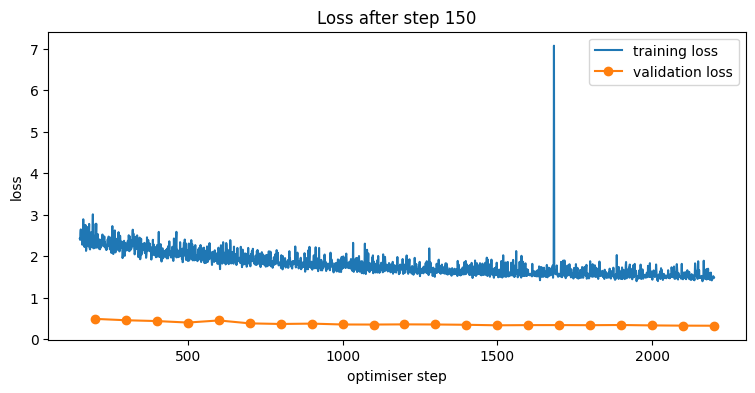

In [ ]:
# ---- loss graph ----
import matplotlib.pyplot as plt
import numpy as np

if "history" not in globals():
    history = torch.load(f"{ckpt_realistic_icesat}/best.pt", map_location="cpu", weights_only=False)["history"]

SKIP_STEPS = WARMUP_STEPS

tr_step = np.asarray(history["train_step"]); tr_loss = np.asarray(history["train_loss"])
va_step = np.asarray(history["val_step"]);   va_loss = np.asarray(history["val_loss"])
tr_keep = tr_step > SKIP_STEPS
va_keep = va_step > SKIP_STEPS

plt.figure(figsize=(9, 4))
plt.plot(tr_step[tr_keep], tr_loss[tr_keep], label="training loss")
plt.plot(va_step[va_keep], va_loss[va_keep], "o-", label="validation loss")
plt.xlabel("optimiser step"); plt.ylabel("loss"); plt.legend()
plt.title(f"Loss after step {SKIP_STEPS}")
plt.show()

In [ ]:
ck = torch.load(f"{ckpt_realistic_icesat}/best.pt", map_location=DEVICE, weights_only=False)
model.load_state_dict(ck["model"])
res = evaluate(model, TEST_SET)                     # CHANGED: was VAL_SET
print(f"test loss (held-out test strip): {res['nll']:.4f}")

TEST_EPISODE = 2                                   # which held-out episode to plot
ep = TEST_SET[TEST_EPISODE]
model.eval()
with torch.no_grad(), amp_ctx():
    mu, lv = model(ep["x"], ep["obs_dh"], ep["obs_mask"], origin_yx=ep["origin"], dsm_hw=(H_DSM, W_DSM))
mu_np  = mu[0, 0].float().cpu().numpy()                     # predicted correction (m)
var_np = np.exp(lv[0, 0].float().cpu().numpy())             # variance sigma^2 = exp(log sigma^2), m^2
tgt_np = np.where(ep["valid"][0, 0].cpu().numpy(),          # target correction; blank where no lidar
                  ep["target"][0, 0].cpu().numpy(), np.nan)
lim = np.nanpercentile(np.abs(tgt_np), 99)                  # same colour range for mu and delta_h

test loss (held-out test strip): 0.6351


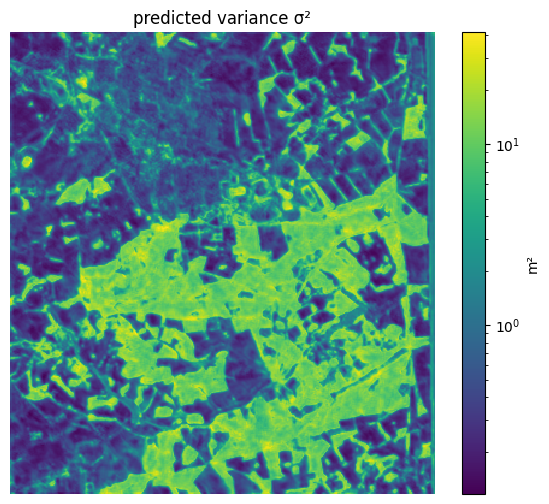

In [ ]:
# ---- predicted variance ----
from matplotlib.colors import LogNorm
plt.figure(figsize=(7, 6))
plt.imshow(var_np, cmap="viridis", norm=LogNorm(), interpolation="nearest")   # log: spans 0.01-900 m^2
plt.colorbar(label="m²"); plt.title("predicted variance σ²"); plt.axis("off")
plt.show()

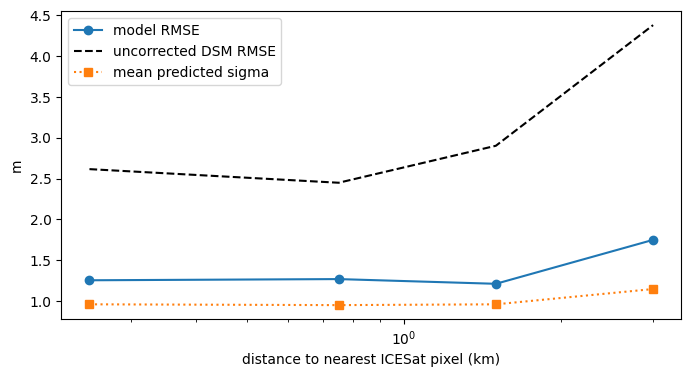

In [ ]:
# ---- error and sigma vs distance to the nearest ICESat pixel (all held-out episodes) ----
from scipy.ndimage import distance_transform_edt

bins_km = np.array([0, 0.5, 1, 2, 4, 8, 16, 32])
se, se0, sg, cnt = (np.zeros(len(bins_km) - 1) for _ in range(4))
model.eval()
for e in VAL_SET:
    with torch.no_grad(), amp_ctx():
        m_, l_ = model(e["x"], e["obs_dh"], e["obs_mask"], origin_yx=e["origin"], dsm_hw=(H_DSM, W_DSM))
    m_, sig = m_[0, 0].float().cpu().numpy(), np.exp(0.5 * l_[0, 0].float().cpu().numpy())
    tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
    dist = distance_transform_edt(~obs) * PIXEL_M / 1000 if obs.any() else np.full(obs.shape, np.inf)
    sel = val & ~obs
    b = np.digitize(dist[sel], bins_km) - 1
    ok = (b >= 0) & (b < len(bins_km) - 1)
    np.add.at(se,  b[ok], ((m_ - tgt)[sel][ok]) ** 2)
    np.add.at(se0, b[ok], (tgt[sel][ok]) ** 2)
    np.add.at(sg,  b[ok], sig[sel][ok])
    np.add.at(cnt, b[ok], 1)

centres, has = 0.5 * (bins_km[:-1] + bins_km[1:]), cnt > 0
plt.figure(figsize=(8, 4))
plt.plot(centres[has], np.sqrt(se[has] / cnt[has]), "o-", label="model RMSE")
plt.plot(centres[has], np.sqrt(se0[has] / cnt[has]), "k--", label="uncorrected DSM RMSE")
plt.plot(centres[has], sg[has] / cnt[has], "s:", label="mean predicted sigma")
plt.xscale("log"); plt.xlabel("distance to nearest ICESat pixel (km)"); plt.ylabel("m"); plt.legend()
plt.show()

In [ ]:
# diagnostic plotting functions
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


def _nice_step(span, n=5):
  """A round step (1, 2, 2.5, 5 x 10^k) giving about n gridlines over `span`."""
  raw = span / n
  mag = 10 ** math.floor(math.log10(raw))
  for m in (1, 2, 2.5, 5, 10):
      if m * mag >= 0.7 * raw:                               # nearest round step, not always the larger one
          return m * mag


def _deg_label(v, step, pos, neg):
  dec = max(0, -math.floor(math.log10(step)) + (1 if step / 10 ** math.floor(math.log10(step)) == 2.5 else 0))
  return f"{abs(v):.{dec}f}°{pos if v >= 0 else neg}"


def _to_lonlat(crs):
  """Function (x, y) -> (lon, lat) for the raster's CRS."""
  import pyproj
  tr = pyproj.Transformer.from_crs(pyproj.CRS.from_user_input(crs), "EPSG:4326", always_xy=True)
  return lambda x, y: tr.transform(x, y)


def show_map(arr, transform, crs, title="", cmap="viridis", vmin=None, vmax=None, log=False,
             cbar_label="", coords="en", n_lines=5, max_px=2000, figsize=(7, 9)):
  """Plot a raster in map coordinates with gridlines, coordinates only on the edges.
  arr       2-D array (NaN = not shown)
  transform the raster's affine transform (rasterio profile["transform"]); for a crop, see notes
  crs       the raster's CRS (rasterio profile["crs"])
  coords    "en": easting / northing in km;  "lonlat": longitude / latitude graticule
  log       logarithmic colour scale (e.g. for variance)"""
  h, w = arr.shape
  left, top = transform.c, transform.f
  right, bottom = left + transform.a * w, top + transform.e * h
  k = max(1, math.ceil(max(h, w) / max_px))                  # thin large rasters for display only
  show = arr[::k, ::k]

  fig, ax = plt.subplots(figsize=figsize)
  finite = show[np.isfinite(show)]
  if log:
      lo = vmin if vmin is not None else np.percentile(finite[finite > 0], 1)
      hi = vmax if vmax is not None else np.percentile(finite, 99)
      norm, vmin_, vmax_ = LogNorm(vmin=lo, vmax=hi), None, None
  else:
      norm, vmin_, vmax_ = None, vmin, vmax
  im = ax.imshow(show, extent=(left, right, bottom, top), origin="upper", cmap=cmap,
                  norm=norm, vmin=vmin_, vmax=vmax_, interpolation="nearest")
  fig.colorbar(im, ax=ax, label=cbar_label, shrink=0.8)
  ax.set_title(title)
  ax.set_xlim(left, right); ax.set_ylim(bottom, top)

  geographic = getattr(crs, "is_geographic", False)
  if coords == "en" or geographic:
      # straight gridlines at round easting / northing values
      sx = _nice_step(right - left, n_lines)
      sy = _nice_step(top - bottom, n_lines)
      xt = np.arange(math.ceil(left / sx) * sx, right, sx)
      yt = np.arange(math.ceil(bottom / sy) * sy, top, sy)
      ax.set_xticks(xt); ax.set_yticks(yt)
      if geographic:
          ax.set_xticklabels([_deg_label(v, sx, "E", "W") for v in xt])
          ax.set_yticklabels([_deg_label(v, sy, "N", "S") for v in yt])
      else:
          ax.set_xticklabels([f"{v / 1000:g}" for v in xt])
          ax.set_yticklabels([f"{v / 1000:g}" for v in yt])
          ax.set_xlabel("Easting (km)"); ax.set_ylabel("Northing (km)")
      ax.grid(True, color="black", lw=0.5, alpha=0.4)
  else:
      # curved graticule: lines of constant lon / lat drawn as contours, labelled where they hit the edges
      to_ll = _to_lonlat(crs)
      gx, gy = np.meshgrid(np.linspace(left, right, 200), np.linspace(bottom, top, 200))
      lon, lat = (np.asarray(v).reshape(gx.shape) for v in to_ll(gx.ravel(), gy.ravel()))
      s_lon = _nice_step(lon.max() - lon.min(), n_lines)
      s_lat = _nice_step(lat.max() - lat.min(), n_lines)
      lon_lv = np.arange(math.ceil(lon.min() / s_lon) * s_lon, lon.max(), s_lon)
      lat_lv = np.arange(math.ceil(lat.min() / s_lat) * s_lat, lat.max(), s_lat)
      ax.contour(gx, gy, lon, levels=lon_lv, colors="black", linewidths=0.5, alpha=0.4, linestyles="solid")
      ax.contour(gx, gy, lat, levels=lat_lv, colors="black", linewidths=0.5, alpha=0.4, linestyles="solid")
      # where each line crosses the bottom edge (longitude) and the left edge (latitude)
      bx, blon = gx[0], lon[0]
      ly, llat = gy[:, 0], lat[:, 0]
      o = np.argsort(blon)
      xt = np.interp(lon_lv, blon[o], bx[o], left=np.nan, right=np.nan)
      o = np.argsort(llat)
      yt = np.interp(lat_lv, llat[o], ly[o], left=np.nan, right=np.nan)
      keep_x, keep_y = np.isfinite(xt), np.isfinite(yt)
      ax.set_xticks(xt[keep_x]); ax.set_xticklabels([_deg_label(v, s_lon, "E", "W") for v in lon_lv[keep_x]])
      ax.set_yticks(yt[keep_y]); ax.set_yticklabels([_deg_label(v, s_lat, "N", "S") for v in lat_lv[keep_y]])
  plt.tight_layout()
  plt.show()
  return fig, ax


def plot_lai_evi(feat, feat_ok, transform, crs, coords="en", lai_band=4, evi_band=5):
  """LAI and EVI from the 7-band feature stack (Slope, Aspect, TRI, Canopy, LAI, EVI, Bldg),
  as two separate maps. Colour limits: 1st-99th percentile of valid pixels."""
  for name, b, cmap, unit in (("LAI", lai_band, "YlGn", "m² / m²"), ("EVI", evi_band, "YlGn", "")):
      a = np.where(feat_ok[b], feat[b], np.nan)
      v = a[np.isfinite(a)]
      print(f"{name}: valid {feat_ok[b].mean() * 100:.1f}% | min {v.min():.3f} | "
            f"median {np.median(v):.3f} | max {v.max():.3f}")
      show_map(a, transform, crs, title=name, cmap=cmap, cbar_label=unit, coords=coords,
                vmin=np.percentile(v, 1), vmax=np.percentile(v, 99))


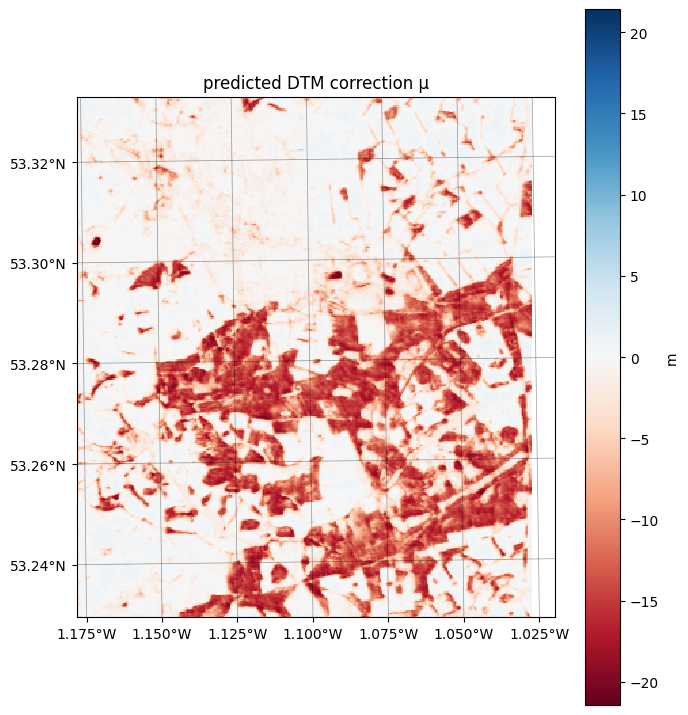

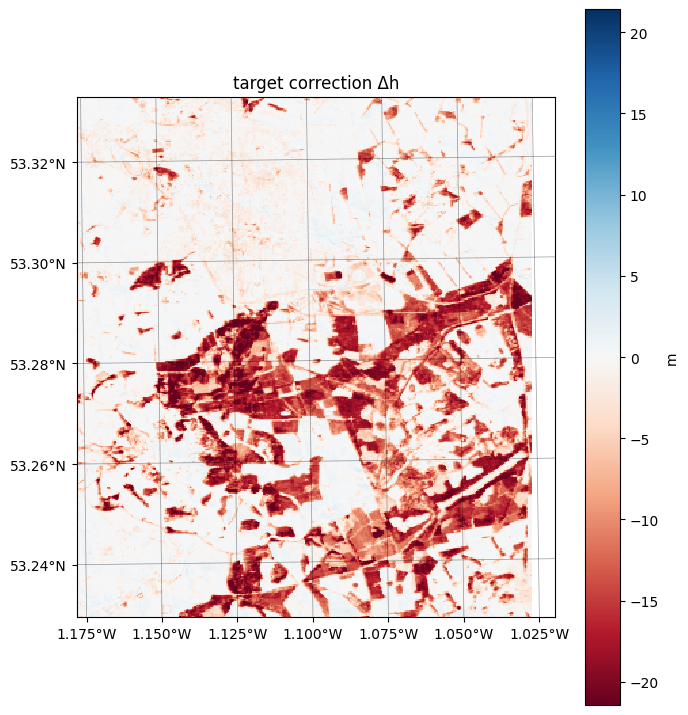

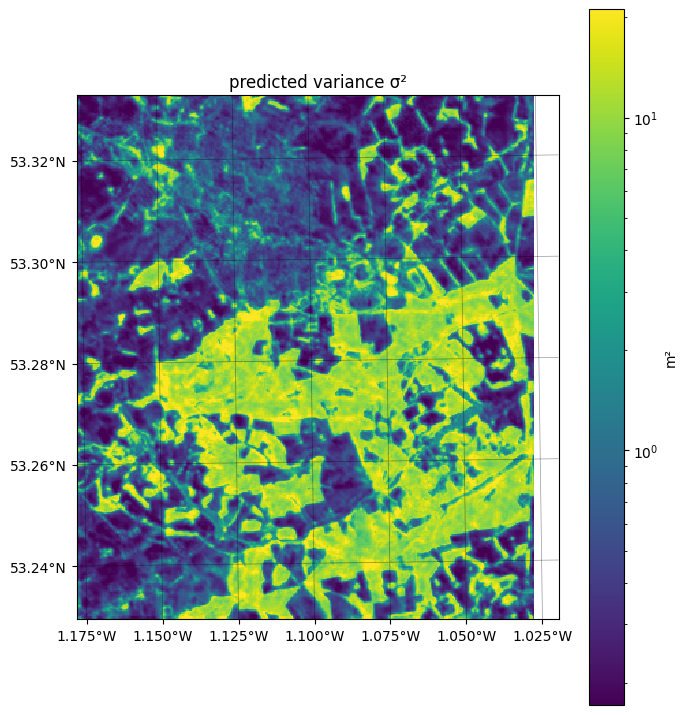

(<Figure size 700x900 with 2 Axes>,
 <Axes: title={'center': 'predicted variance σ²'}>)

In [ ]:
from affine import Affine

oy, ox = ep["origin"]                                       # crop corner (row, col) in the full DSM
T_ep = DSM_PROFILE["transform"] * Affine.translation(ox, oy)   # note: (col, row) order
CRS = DSM_PROFILE["crs"]
valid_np = ep["valid"][0, 0].cpu().numpy()                  # lidar pixels; hides the edge frame

show_map(np.where(valid_np, mu_np, np.nan), T_ep, CRS, title="predicted DTM correction μ",
         cmap="RdBu", vmin=-lim, vmax=lim, cbar_label="m", coords="longlat")
show_map(tgt_np, T_ep, CRS, title="target correction Δh",
         cmap="RdBu", vmin=-lim, vmax=lim, cbar_label="m", coords="longlat")
show_map(np.where(valid_np, var_np, np.nan), T_ep, CRS, title="predicted variance σ²",
         log=True, cbar_label="m²", coords="longlat")

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt
from scipy.stats import norm


C_MODEL, C_SIGMA, C_REF = "#2a78d6", "#eb6834", "#8a8a85"
F_CANOPY, F_LAI, F_EVI, F_BLDG = 4, 5, 6, 7

def collect_pixels(model, episodes):
    """Off-track pixels with valid lidar from every episode -> dict of 1-D arrays."""
    keys = ("err", "tgt", "sigma", "dist_km", "canopy", "lai", "evi", "bldg")
    out = {k: [] for k in keys}
    model.eval()
    for e in episodes:
        with torch.no_grad(), amp_ctx():
            m_, l_ = model(e["x"], e["obs_dh"], e["obs_mask"], origin_yx=e["origin"],
                           dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
        mu = m_[0, 0].float().cpu().numpy()
        sig = np.exp(0.5 * l_[0, 0].float().cpu().numpy())
        tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
        dist = distance_transform_edt(~obs) * PIXEL_M / 1000 if obs.any() else np.full(obs.shape, np.inf)
        sel = val & ~obs
        oy, ox = e["origin"]
        h, w = tgt.shape
        out["err"].append((mu - tgt)[sel]); out["tgt"].append(tgt[sel])
        out["sigma"].append(sig[sel]);      out["dist_km"].append(dist[sel])
        for key, b in (("canopy", F_CANOPY), ("lai", F_LAI), ("evi", F_EVI), ("bldg", F_BLDG)):
            band = features[b, oy:oy + h, ox:ox + w]                     # raw values, not standardised
            ok = features_valid[b, oy:oy + h, ox:ox + w]
            out[key].append(np.where(ok, band, np.nan)[sel])
    return {k: np.concatenate(v).astype(np.float32) for k, v in out.items()}


def summary(P):
    err = P["err"]
    rmse, mae = np.sqrt(np.mean(err ** 2)), np.mean(np.abs(err))
    print(f"{len(err):,} off-track test pixels | RMSE {rmse:.2f} m | MAE {mae:.2f} m | "
          f"RMSE/MAE {rmse / mae:.2f} (normally distributed errors: 1.25)")


In [ ]:
LEVELS = np.array([0.50, 0.68, 0.80, 0.90, 0.95, 0.99])

def coverage_plot(P, levels=LEVELS):
    z = P["err"] / P["sigma"]
    k = norm.ppf(0.5 + levels / 2)                      # interval half-width in sigmas
    observed = np.array([np.mean(np.abs(z) <= kk) for kk in k])
    print("nominal   ±k·σ    observed   difference")
    for p, kk, o in zip(levels, k, observed):
        print(f"  {p:4.0%}   ±{kk:.3f}σ    {o:6.1%}     {o - p:+6.1%}")
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.plot([0.4, 1], [0.4, 1], color=C_REF, ls="--", lw=1, label="perfect calibration")
    ax.plot(levels, observed, color=C_MODEL, marker="o", ms=8, lw=2, label="model")
    ax.set_xlim(0.4, 1); ax.set_ylim(0.4, 1); ax.set_aspect("equal")
    ax.set_xlabel("nominal coverage (interval μ ± k·σ)"); ax.set_ylabel("observed coverage")
    ax.grid(alpha=0.3); ax.legend(loc="upper left"); ax.set_title("Interval coverage, test strip")
    plt.tight_layout(); plt.show()


In [ ]:
def tail_plot(P):
    err, z = P["err"], P["err"] / P["sigma"]
    se = err ** 2
    tail = np.abs(z) > 3
    top1 = np.abs(err) >= np.quantile(np.abs(err), 0.99)
    print(f"|z| > 3: {tail.mean():.2%} of pixels (normal: 0.27%), carrying {se[tail].sum() / se.sum():.1%} of the squared error")
    print(f"largest 1% of |error| (>= {np.quantile(np.abs(err), 0.99):.1f} m) carry {se[top1].sum() / se.sum():.1%} of the squared error")
    bins = np.linspace(-10, 10, 161)
    xs = np.linspace(-10, 10, 400)
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(np.clip(z, -10, 10), bins=bins, density=True, histtype="step", color=C_MODEL, lw=2,
            label="z = error / σ (clipped at ±10)")
    ax.plot(xs, norm.pdf(xs), color=C_REF, ls="--", lw=1.5, label="normal N(0, 1)")
    ax.set_yscale("log"); ax.set_ylim(1e-6, 1)
    ax.set_xlabel("standardised error z"); ax.set_ylabel("density (log)")
    ax.grid(alpha=0.3); ax.legend(); ax.set_title("Standardised errors vs normal, test strip")
    plt.tight_layout(); plt.show()


In [ ]:
from matplotlib.ticker import LogLocator, NullFormatter

def log_ticks(ax):
    """Readable labels (0.2, 0.5, 1, 2, 5 ...) on a logarithmic y axis."""
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 5)))
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())

def qedges(x, n=8):
    """Edges giving about equal pixel counts per bin."""
    e = np.unique(np.nanquantile(x, np.linspace(0, 1, n + 1)))
    e[-1] += 1e-6
    return e

def breakdown(P, key, edges, label):
    x = P[key]
    ok = np.isfinite(x)
    err, tgt, sig = P["err"][ok], P["tgt"][ok], P["sigma"][ok]
    x = x[ok]
    b = np.digitize(x, edges) - 1
    nb = len(edges) - 1
    se_total, n_total = np.sum(err ** 2), len(err)
    rows = []
    for i in range(nb):
        m = b == i
        if m.sum() == 0:
            continue
        rows.append(dict(i=i, n=m.sum(), rmse=np.sqrt(np.mean(err[m] ** 2)), mae=np.mean(np.abs(err[m])),
                         rmse_dsm=np.sqrt(np.mean(tgt[m] ** 2)), sigma=np.sqrt(np.mean(sig[m] ** 2)),   # RMS sigma
                         cover95=np.mean(np.abs(err[m]) <= 1.96 * sig[m]),
                         share_px=m.sum() / n_total, share_se=np.sum(err[m] ** 2) / se_total))
    fmt = lambda v: "inf" if not np.isfinite(v) else f"{v:g}"
    names = [f"{fmt(round(edges[r['i']], 2))}–{fmt(round(edges[r['i'] + 1], 2))}" for r in rows]
    print(f"{label:>14s} |  pixels   | RMSE   MAE  | DSM RMSE |  RMS σ | cover95 | share px | share sq.err")
    for nm, r in zip(names, rows):
        print(f"{nm:>14s} | {r['n']:9,d} | {r['rmse']:5.2f} {r['mae']:5.2f} | {r['rmse_dsm']:8.2f} | "
              f"{r['sigma']:6.2f} | {r['cover95']:7.2f} | {r['share_px']:8.1%} | {r['share_se']:8.1%}")

    pos = np.arange(len(rows))
    get = lambda k: np.array([r[k] for r in rows])
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
    a1.plot(pos, get("rmse"), color=C_MODEL, marker="o", ms=8, lw=2, label="model RMSE")
    a1.plot(pos, get("sigma"), color=C_SIGMA, marker="s", ms=8, lw=2, label="RMS predicted σ (matches RMSE if calibrated)")
    a1.plot(pos, get("rmse_dsm"), color=C_REF, ls="--", lw=1.5, label="uncorrected DSM RMSE")
    a1.set_yscale("log"); log_ticks(a1)
    a1.set_ylabel("m (log scale)"); a1.grid(alpha=0.3); a1.legend(); a1.set_title(f"Error by {label}, test strip")
    w = 0.38
    a2.bar(pos - w / 2, get("share_px") * 100, width=w - 0.02, color=C_REF, label="share of pixels")
    a2.bar(pos + w / 2, get("share_se") * 100, width=w - 0.02, color=C_MODEL, label="share of squared error")
    a2.set_ylabel("%"); a2.grid(alpha=0.3, axis="y")
    a2.set_ylim(0, 1.4 * max(get("share_px").max(), get("share_se").max()) * 100)
    a2.legend(loc="upper left", ncol=2)
    a2.set_xticks(pos); a2.set_xticklabels(names, rotation=30, ha="right"); a2.set_xlabel(label)
    plt.tight_layout(); plt.show()


In [ ]:
def sigma_vs(P, key, label, n_bins=12):
    x, sig, err = P[key], P["sigma"], P["err"]
    ok = np.isfinite(x)
    x, sig, err = x[ok], sig[ok], err[ok]
    edges = qedges(x, n_bins)
    b = np.digitize(x, edges) - 1
    c, med, rm = [], [], []
    for i in range(len(edges) - 1):
        m = b == i
        if m.sum() > 50:
            c.append(np.median(x[m])); med.append(np.sqrt(np.mean(sig[m] ** 2))); rm.append(np.sqrt(np.mean(err[m] ** 2)))
    fig, ax = plt.subplots(figsize=(8, 4.5))
    hb = ax.hexbin(x, sig, gridsize=60, yscale="log", bins="log", cmap="Blues", mincnt=1)
    fig.colorbar(hb, ax=ax, label="pixels (log)")
    ax.plot(c, med, color=C_SIGMA, marker="s", ms=7, lw=2, label="RMS σ per bin")
    ax.plot(c, rm, color="black", marker="o", ms=6, lw=1.5, ls="--", label="model RMSE per bin")
    log_ticks(ax)
    ax.set_xlabel(label); ax.set_ylabel("m (log scale)")
    ax.grid(alpha=0.3); ax.legend(loc="upper left"); ax.set_title(f"Predicted σ vs {label}, test strip")
    plt.tight_layout(); plt.show()


In [ ]:
P = collect_pixels(model, TEST_SET)
summary(P)

459,458 off-track test pixels | RMSE 2.31 m | MAE 1.23 m | RMSE/MAE 1.88 (normally distributed errors: 1.25)


nominal   ±k·σ    observed   difference
   50%   ±0.674σ     55.3%      +5.3%
   68%   ±0.994σ     72.9%      +4.9%
   80%   ±1.282σ     83.6%      +3.6%
   90%   ±1.645σ     91.8%      +1.8%
   95%   ±1.960σ     95.5%      +0.5%
   99%   ±2.576σ     98.5%      -0.5%


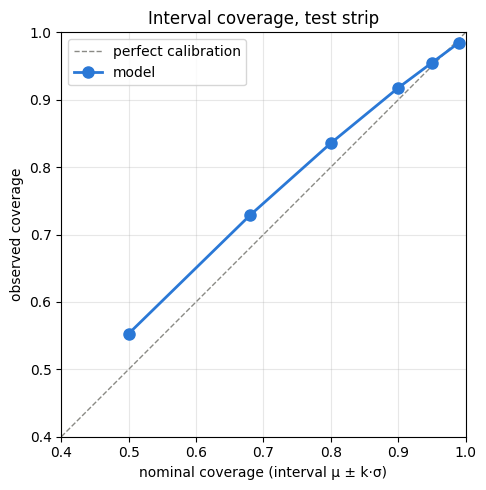

|z| > 3: 0.86% of pixels (normal: 0.27%), carrying 12.1% of the squared error
largest 1% of |error| (>= 10.0 m) carry 31.5% of the squared error


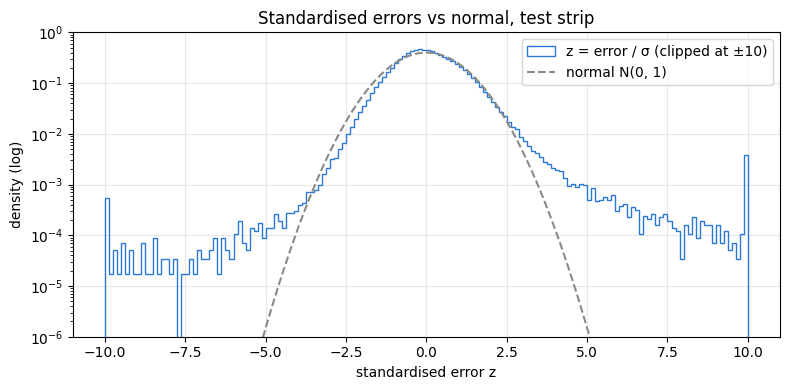

In [ ]:
coverage_plot(P)
tail_plot(P)


true correction Δh (m) |  pixels   | RMSE   MAE  | DSM RMSE |  RMS σ | cover95 | share px | share sq.err
       inf–-20 |     4,838 |  8.06  6.99 |    21.74 |   4.22 |    0.64 |     1.1% |    12.8%
       -20–-10 |    55,020 |  4.80  3.53 |    14.76 |   4.23 |    0.93 |    12.0% |    51.8%
        -10–-5 |    29,859 |  3.59  2.90 |     7.53 |   3.64 |    0.91 |     6.5% |    15.7%
         -5–-2 |    32,944 |  2.30  1.73 |     3.36 |   2.34 |    0.91 |     7.2% |     7.1%
       -2–-0.5 |    69,216 |  1.19  0.78 |     1.11 |   1.29 |    0.96 |    15.1% |     4.0%
      -0.5–0.5 |   228,228 |  0.71  0.42 |     0.26 |   0.80 |    0.99 |    49.7% |     4.7%
         0.5–2 |    37,991 |  1.28  0.96 |     0.85 |   0.94 |    0.92 |     8.3% |     2.5%
         2–inf |     1,362 |  4.74  4.20 |     4.03 |   2.00 |    0.30 |     0.3% |     1.2%


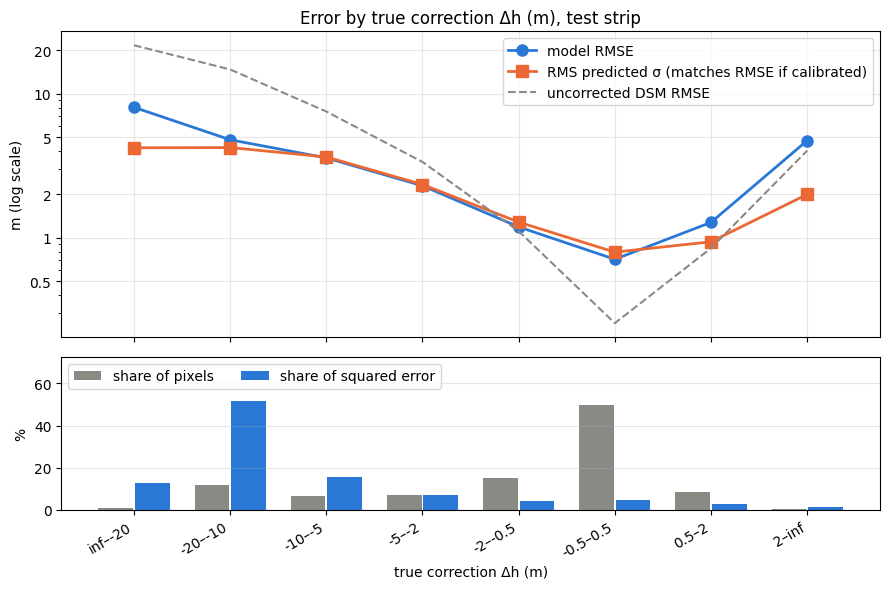

distance to nearest context pixel (km) |  pixels   | RMSE   MAE  | DSM RMSE |  RMS σ | cover95 | share px | share sq.err
         0–0.5 |    93,524 |  1.90  1.10 |     6.02 |   1.78 |    0.96 |    26.1% |    21.7%
         0.5–1 |    80,061 |  2.17  1.22 |     6.28 |   1.82 |    0.95 |    22.4% |    24.1%
           1–2 |   127,519 |  1.98  1.16 |     6.09 |   1.79 |    0.95 |    35.6% |    32.1%
           2–4 |    56,849 |  2.46  1.51 |     8.10 |   2.11 |    0.93 |    15.9% |    22.1%


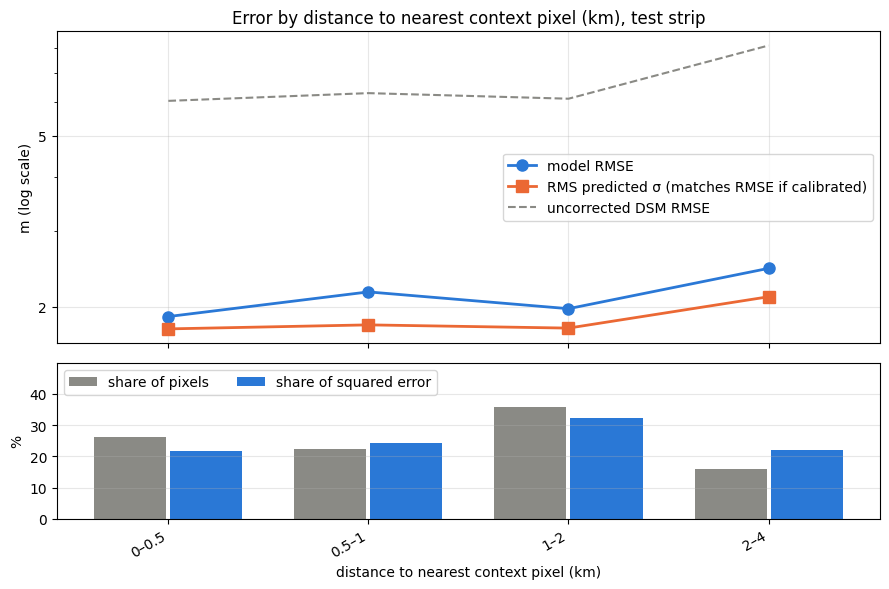

canopy height (m) |  pixels   | RMSE   MAE  | DSM RMSE |  RMS σ | cover95 | share px | share sq.err
         0–0.5 |    52,116 |  0.64  0.38 |     0.72 |   0.64 |    0.98 |    12.0% |     0.9%
         0.5–2 |    25,113 |  0.79  0.42 |     1.01 |   0.70 |    0.98 |     5.8% |     0.7%
           2–5 |    86,682 |  0.69  0.40 |     0.78 |   0.67 |    0.97 |    19.9% |     1.7%
          5–10 |    99,867 |  1.15  0.60 |     1.54 |   0.93 |    0.97 |    23.0% |     5.6%
         10–15 |    63,032 |  1.97  1.24 |     3.24 |   1.64 |    0.94 |    14.5% |    10.3%
         15–20 |    54,000 |  3.72  2.70 |     8.42 |   3.30 |    0.92 |    12.4% |    31.5%
         20–30 |    54,304 |  4.64  3.49 |    14.56 |   4.25 |    0.93 |    12.5% |    49.3%
        30–inf |         2 |  0.95  0.92 |    13.59 |   4.64 |    1.00 |     0.0% |     0.0%


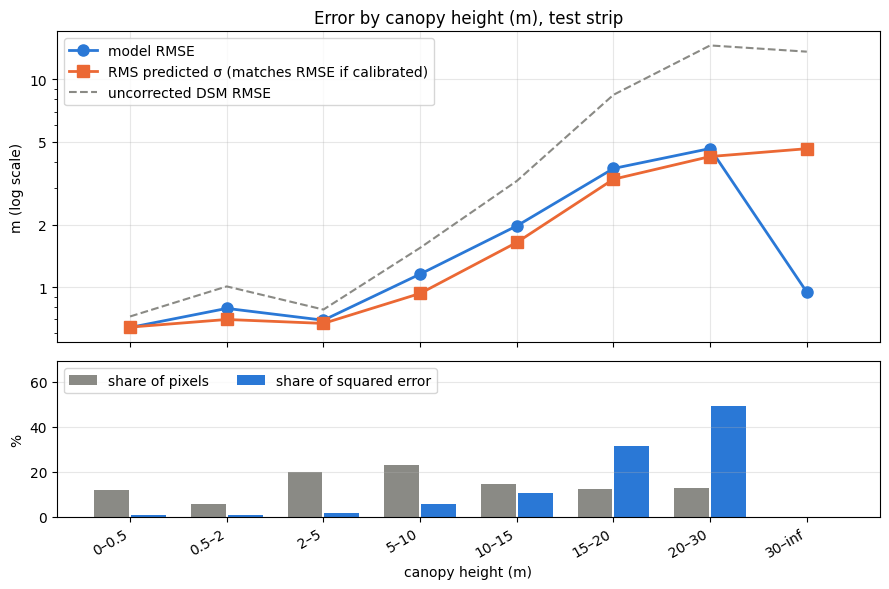

building height (m) |  pixels   | RMSE   MAE  | DSM RMSE |  RMS σ | cover95 | share px | share sq.err
        0–0.01 |   334,955 |  2.47  1.31 |     6.66 |   2.18 |    0.96 |    73.4% |    84.4%
        0.01–3 |    64,519 |  1.91  1.04 |     4.07 |   1.84 |    0.96 |    14.1% |     9.7%
           3–6 |    33,631 |  1.75  1.04 |     3.47 |   1.69 |    0.95 |     7.4% |     4.2%
          6–10 |    21,320 |  1.34  0.83 |     2.40 |   1.23 |    0.94 |     4.7% |     1.6%
         10–20 |     2,049 |  1.06  0.77 |     2.19 |   1.01 |    0.93 |     0.4% |     0.1%


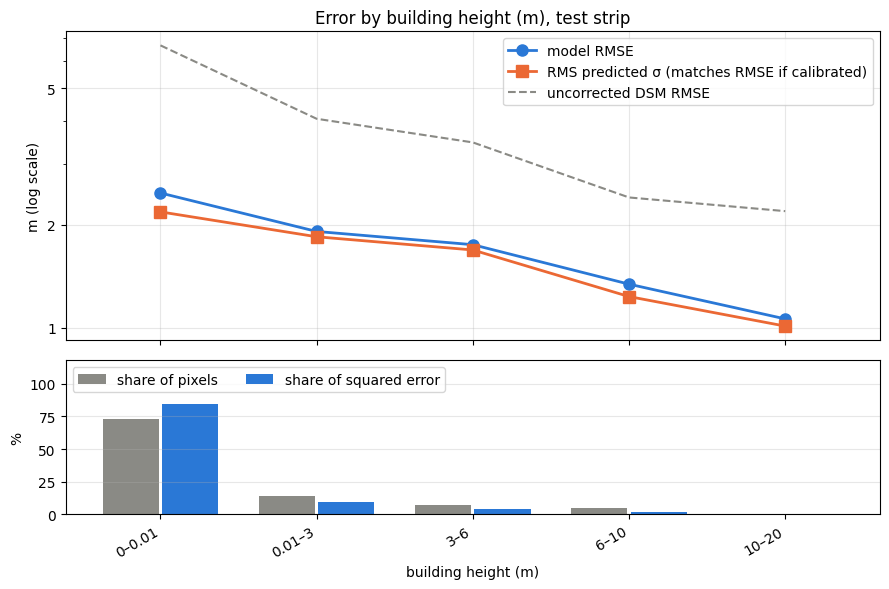

In [ ]:
breakdown(P, "tgt", [-np.inf, -20, -10, -5, -2, -0.5, 0.5, 2, np.inf], "true correction Δh (m)")
breakdown(P, "dist_km", [0, 0.5, 1, 2, 4, 8, 16, 32, np.inf], "distance to nearest context pixel (km)")
breakdown(P, "canopy", [0, 0.5, 2, 5, 10, 15, 20, 30, np.inf], "canopy height (m)")
breakdown(P, "bldg", [0, 0.01, 3, 6, 10, 20, np.inf], "building height (m)")



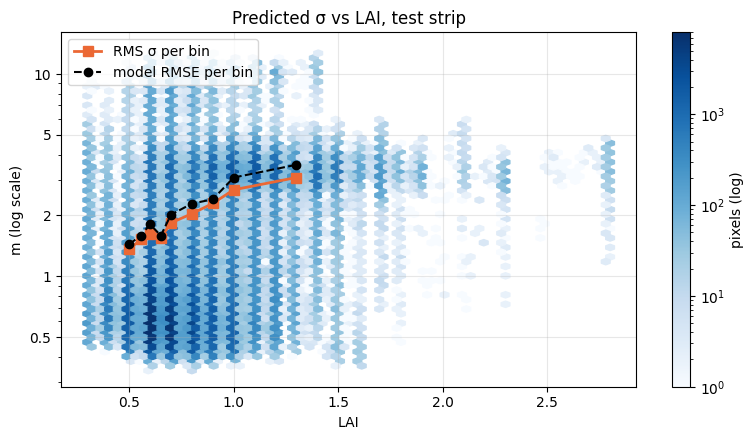

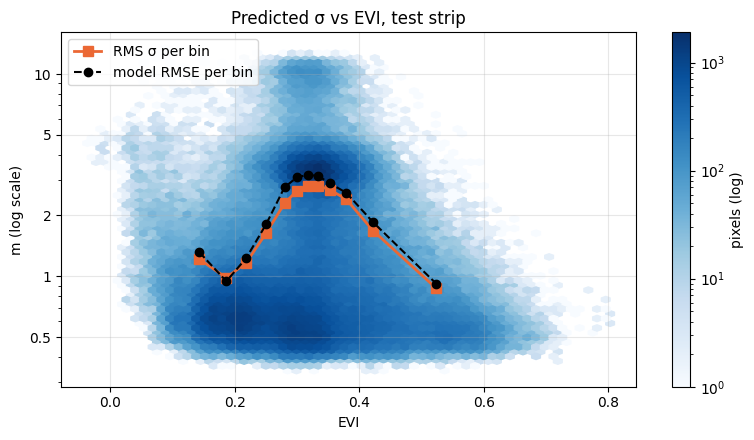

In [ ]:
sigma_vs(P, "lai", "LAI")
sigma_vs(P, "evi", "EVI")


In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm


def _nice_step(span, n=5):
    """A round step (1, 2, 2.5, 5 x 10^k) giving about n gridlines over `span`."""
    raw = span / n
    mag = 10 ** math.floor(math.log10(raw))
    for m in (1, 2, 2.5, 5, 10):
        if m * mag >= 0.7 * raw:                               # nearest round step, not always the larger one
            return m * mag


def _deg_label(v, step, pos, neg):
    dec = max(0, -math.floor(math.log10(step)) + (1 if step / 10 ** math.floor(math.log10(step)) == 2.5 else 0))
    return f"{abs(v):.{dec}f}°{pos if v >= 0 else neg}"


def _to_lonlat(crs):
    """Function (x, y) -> (lon, lat) for the raster's CRS."""
    import pyproj
    tr = pyproj.Transformer.from_crs(pyproj.CRS.from_user_input(crs), "EPSG:4326", always_xy=True)
    return lambda x, y: tr.transform(x, y)


def show_map(arr, transform, crs, title="", cmap="viridis", vmin=None, vmax=None, log=False,
             cbar_label="", coords="en", n_lines=5, max_px=2000, figsize=(7, 9),
             background=None, bg_cmap="gray", extra=None):        # NEW: grey layer underneath; extra(ax) draws on top
    """Plot a raster in map coordinates with gridlines, coordinates only on the edges.
    arr       2-D array (NaN = not shown)
    transform the raster's affine transform (rasterio profile["transform"]); for a crop, see notes
    crs       the raster's CRS (rasterio profile["crs"])
    coords    "en": easting / northing in km;  "lonlat": longitude / latitude graticule
    log       logarithmic colour scale (e.g. for variance)
    background optional 2-D array (same shape) drawn underneath in grey; NaN pixels of arr let it show
    extra     optional function extra(ax), called before the plot is shown (e.g. to draw lines)"""
    h, w = arr.shape
    left, top = transform.c, transform.f
    right, bottom = left + transform.a * w, top + transform.e * h
    k = max(1, math.ceil(max(h, w) / max_px))                  # thin large rasters for display only
    show = arr[::k, ::k]

    fig, ax = plt.subplots(figsize=figsize)
    finite = show[np.isfinite(show)]
    if log:
        lo = vmin if vmin is not None else np.percentile(finite[finite > 0], 1)
        hi = vmax if vmax is not None else np.percentile(finite, 99)
        norm, vmin_, vmax_ = LogNorm(vmin=lo, vmax=hi), None, None
    else:
        norm, vmin_, vmax_ = None, vmin, vmax
    if background is not None:                                 # NEW: context layer underneath
        bg = background[::k, ::k]
        ax.imshow(bg, extent=(left, right, bottom, top), origin="upper", cmap=bg_cmap, interpolation="nearest",
                  vmin=np.nanpercentile(bg, 2), vmax=np.nanpercentile(bg, 98))
    im = ax.imshow(show, extent=(left, right, bottom, top), origin="upper", cmap=cmap,
                   norm=norm, vmin=vmin_, vmax=vmax_, interpolation="nearest")
    fig.colorbar(im, ax=ax, label=cbar_label, shrink=0.8)
    ax.set_title(title)
    ax.set_xlim(left, right); ax.set_ylim(bottom, top)

    geographic = getattr(crs, "is_geographic", False)
    if coords == "en" or geographic:
        # straight gridlines at round easting / northing values
        sx = _nice_step(right - left, n_lines)
        sy = _nice_step(top - bottom, n_lines)
        xt = np.arange(math.ceil(left / sx) * sx, right, sx)
        yt = np.arange(math.ceil(bottom / sy) * sy, top, sy)
        ax.set_xticks(xt); ax.set_yticks(yt)
        if geographic:
            ax.set_xticklabels([_deg_label(v, sx, "E", "W") for v in xt])
            ax.set_yticklabels([_deg_label(v, sy, "N", "S") for v in yt])
        else:
            ax.set_xticklabels([f"{v / 1000:g}" for v in xt])
            ax.set_yticklabels([f"{v / 1000:g}" for v in yt])
            ax.set_xlabel("Easting (km)"); ax.set_ylabel("Northing (km)")
        ax.grid(True, color="black", lw=0.5, alpha=0.4)
    else:
        # curved graticule: lines of constant lon / lat drawn as contours, labelled where they hit the edges
        to_ll = _to_lonlat(crs)
        gx, gy = np.meshgrid(np.linspace(left, right, 200), np.linspace(bottom, top, 200))
        lon, lat = (np.asarray(v).reshape(gx.shape) for v in to_ll(gx.ravel(), gy.ravel()))
        s_lon = _nice_step(lon.max() - lon.min(), n_lines)
        s_lat = _nice_step(lat.max() - lat.min(), n_lines)
        lon_lv = np.arange(math.ceil(lon.min() / s_lon) * s_lon, lon.max(), s_lon)
        lat_lv = np.arange(math.ceil(lat.min() / s_lat) * s_lat, lat.max(), s_lat)
        ax.contour(gx, gy, lon, levels=lon_lv, colors="black", linewidths=0.5, alpha=0.4, linestyles="solid")
        ax.contour(gx, gy, lat, levels=lat_lv, colors="black", linewidths=0.5, alpha=0.4, linestyles="solid")
        # where each line crosses the bottom edge (longitude) and the left edge (latitude)
        bx, blon = gx[0], lon[0]
        ly, llat = gy[:, 0], lat[:, 0]
        o = np.argsort(blon)
        xt = np.interp(lon_lv, blon[o], bx[o], left=np.nan, right=np.nan)
        o = np.argsort(llat)
        yt = np.interp(lat_lv, llat[o], ly[o], left=np.nan, right=np.nan)
        keep_x, keep_y = np.isfinite(xt), np.isfinite(yt)
        ax.set_xticks(xt[keep_x]); ax.set_xticklabels([_deg_label(v, s_lon, "E", "W") for v in lon_lv[keep_x]])
        ax.set_yticks(yt[keep_y]); ax.set_yticklabels([_deg_label(v, s_lat, "N", "S") for v in lat_lv[keep_y]])
    if extra is not None:                                      # NEW
        extra(ax)
    plt.tight_layout()
    plt.show()
    return fig, ax



def plot_lai_evi(feat, feat_ok, transform, crs, coords="en", lai_band=4, evi_band=5):
    """LAI and EVI from the 7-band feature stack (Slope, Aspect, TRI, Canopy, LAI, EVI, Bldg),
    as two separate maps. Colour limits: 1st-99th percentile of valid pixels."""
    for name, b, cmap, unit in (("LAI", lai_band, "YlGn", "m² / m²"), ("EVI", evi_band, "YlGn", "")):
        a = np.where(feat_ok[b], feat[b], np.nan)
        v = a[np.isfinite(a)]
        print(f"{name}: valid {feat_ok[b].mean() * 100:.1f}% | min {v.min():.3f} | "
              f"median {np.median(v):.3f} | max {v.max():.3f}")
        show_map(a, transform, crs, title=name, cmap=cmap, cbar_label=unit, coords=coords,
                 vmin=np.percentile(v, 1), vmax=np.percentile(v, 99))


|z| > 5: 315 px too high, 2 px too low (of 128,270 evaluated px)


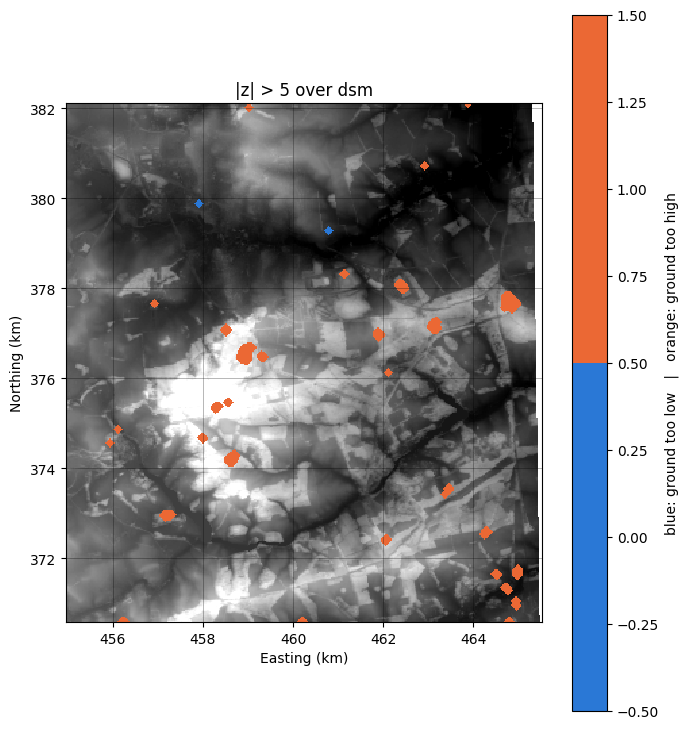

In [ ]:
from scipy.ndimage import binary_dilation
from matplotlib.colors import ListedColormap
from affine import Affine

def show_outliers(ep, z_thresh=5.0, grow_px=3, background="canopy"):
    """Pixels with |error / sigma| > z_thresh in one episode, over a grey context layer.
    orange: z > +z_thresh (mu too high: ground left too high, correction not negative enough)
    blue:   z < -z_thresh (mu too low:  ground pushed too low)
    grow_px only enlarges the marks so single pixels are visible; counts use the real pixels."""
    model.eval()
    with torch.no_grad(), amp_ctx():
        m_, l_ = model(ep["x"], ep["obs_dh"], ep["obs_mask"], origin_yx=ep["origin"],
                       dsm_hw=ep.get("dsm_hw", (H_DSM, W_DSM)))
    mu = m_[0, 0].float().cpu().numpy()
    sig = np.exp(0.5 * l_[0, 0].float().cpu().numpy())
    tgt, val, obs = (ep[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
    z = np.where(val & ~obs, (mu - tgt) / sig, np.nan)

    hi, lo = z > z_thresh, z < -z_thresh                     # NaN compares False
    print(f"|z| > {z_thresh:g}: {hi.sum():,} px too high, {lo.sum():,} px too low "
          f"(of {np.isfinite(z).sum():,} evaluated px)")
    cls = np.full(z.shape, np.nan)
    cls[binary_dilation(lo, iterations=grow_px)] = 0
    cls[binary_dilation(hi, iterations=grow_px)] = 1

    oy, ox = ep["origin"]
    h, w = z.shape
    T = DSM_PROFILE["transform"] * Affine.translation(ox, oy)
    bands = {"canopy": 4, "lai": 5, "evi": 6, "bldg": 7}      # GEE feature stack
    bg = RAW_DSM[oy:oy + h, ox:ox + w] if background == "dsm" else features[bands[background], oy:oy + h, ox:ox + w]
    show_map(cls, T, DSM_PROFILE["crs"], title=f"|z| > {z_thresh:g} over {background}",
             cmap=ListedColormap(["#2a78d6", "#eb6834"]), vmin=-0.5, vmax=1.5,
             cbar_label="blue: ground too low   |   orange: ground too high", background=bg)
    return z

z = show_outliers(TEST_SET[2], background="dsm")

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from affine import Affine
from scipy.ndimage import distance_transform_edt

SET_NAMES = ["train", "val", "test"]
SET_COLOURS = ["#2a78d6", "#eb6834", "#1baf7a"]          # fixed: train blue, val orange, test green
F_CANOPY, F_BLDG = 4, 7                                   # bands of the GEE feature stack


@torch.no_grad()
def predict_full(model, seed=0, win_batch=128):
    """mu, sigma and the ICESat mask over the whole DSM (one TTT write, one dense read)."""
    dev = X_t.device
    gen = torch.Generator().manual_seed(seed)
    sim = simulate_icesat_mask(H_DSM, W_DSM, pixel_m=PIXEL_M, generator=gen, device="cpu").to(dev)
    obs = sim & VALID_t.to(dev).bool()
    noise = (torch.randn(H_DSM, W_DSM, generator=gen) * ICESAT_NOISE_M).to(dev)
    obs_dh = torch.where(obs, TARGET_t.to(dev) + noise, torch.zeros((), device=dev))
    model.eval()
    old = model.win_batch
    model.win_batch = win_batch
    try:
        with amp_ctx():
            mu, lv = model(X_t[None], obs_dh[None, None].float(), obs[None, None],
                           origin_yx=(0, 0), dsm_hw=(H_DSM, W_DSM))
    finally:
        model.win_batch = old
    return (mu[0, 0].float().cpu().numpy(), np.exp(0.5 * lv[0, 0].float().cpu().numpy()),
            obs.cpu().numpy())


def make_set_map():
    """Per pixel: 0 train, 1 val, 2 test, -1 gap."""
    s = np.full((H_DSM, W_DSM), -1, np.int8)
    for i, (y0, x0, y1, x1) in enumerate((TRAIN_BOX, VAL_BOX, TEST_BOX)):
        s[y0:y1, x0:x1] = i
    return s


def draw_split(ax):
    """Draw the train / val / test boundaries on a map (map coordinates)."""
    T = DSM_PROFILE["transform"]
    for (y0, x0, y1, x1), c in zip((TRAIN_BOX, VAL_BOX, TEST_BOX), SET_COLOURS):
        xs = [T.c + x0 * T.a, T.c + x1 * T.a]
        ys = [T.f + y0 * T.e, T.f + y1 * T.e]
        ax.plot([xs[0], xs[1], xs[1], xs[0], xs[0]], [ys[0], ys[0], ys[1], ys[1], ys[0]], color=c, lw=2)


# run once (a few minutes on a large DSM):
MU_FULL, SIG_FULL, OBS_FULL = predict_full(model, seed=0)
SET_MAP = make_set_map()
ERR_FULL = np.where(valid & ~OBS_FULL, MU_FULL - np.nan_to_num(target), np.nan)   # off-track, valid only
print("NOTE: errors in the training strip are in-sample (the model was trained there)")


NOTE: errors in the training strip are in-sample (the model was trained there)


36 blocks of 8 km (267 px) with >= 10% valid pixels
 set  | blocks | canopy>5m | bldg>2m | elev (m) | Δh std | RMSE | RMS σ | cover95
train |     24 |     82.4% |   26.9% |      269 |   3.91 | 1.69 |  1.69 |    0.95
val   |      4 |     63.3% |   38.0% |      103 |   2.60 | 1.27 |  1.17 |    0.95
test  |      8 |     60.4% |   22.6% |       61 |   4.65 | 1.85 |  1.55 |    0.95


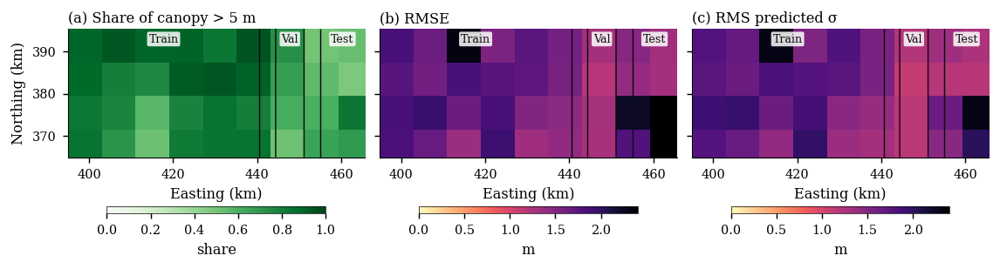

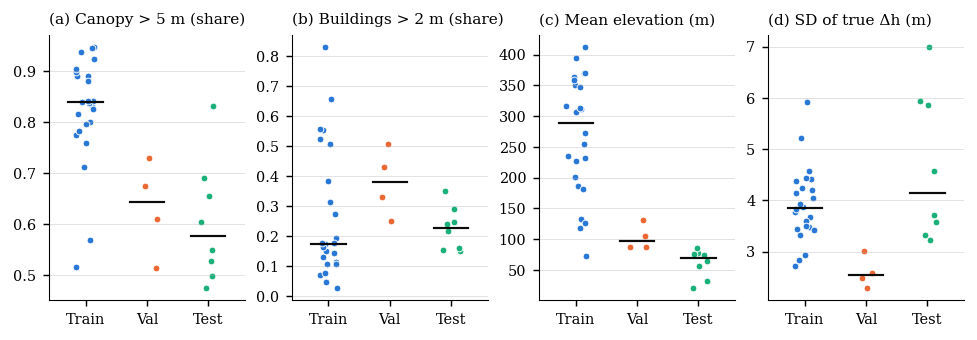

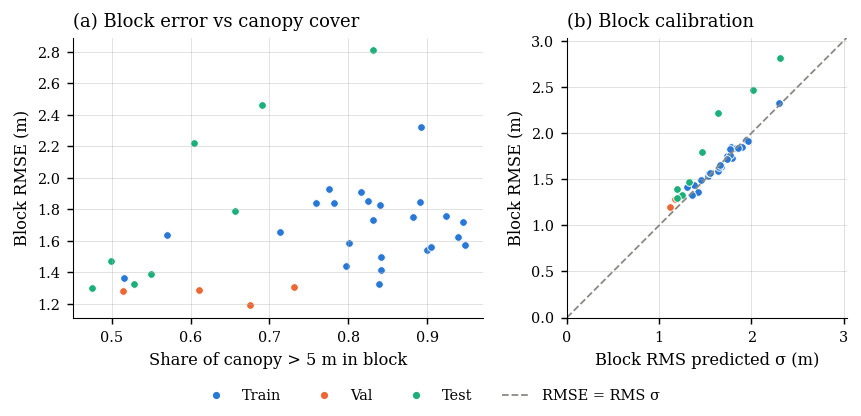

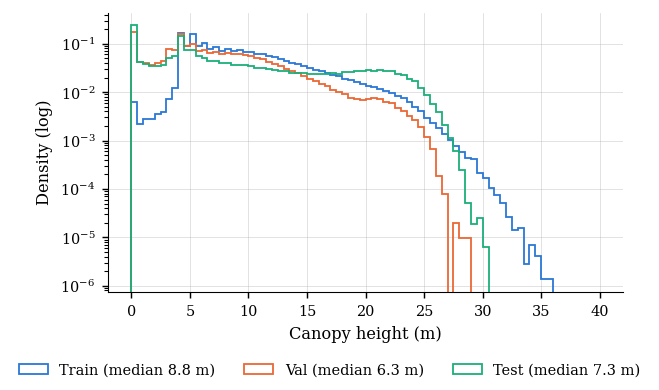

In [ ]:
import math
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ---------- block_table: UNCHANGED (your original) ----------
def block_table(block_km=8.0, tall_m=5.0, bldg_m=2.0, min_valid=0.1):
    """One row per block with enough valid pixels. Set = the set of the block's centre pixel."""
    B = int(round(block_km * 1000 / PIXEL_M))
    canopy = np.where(features_valid[F_CANOPY], features[F_CANOPY], np.nan)
    bldg = np.where(features_valid[F_BLDG], features[F_BLDG], np.nan)
    rows = []
    for by in range(0, H_DSM, B):
        for bx in range(0, W_DSM, B):
            sl = (slice(by, by + B), slice(bx, bx + B))
            ok = np.isfinite(ERR_FULL[sl])
            if ok.sum() < min_valid * B * B:
                continue
            c = canopy[sl][np.isfinite(canopy[sl])]
            b = bldg[sl][np.isfinite(bldg[sl])]
            e, s, t = ERR_FULL[sl][ok], SIG_FULL[sl][ok], target[sl][ok]
            rows.append(dict(
                by=by, bx=bx, set=int(SET_MAP[min(by + B // 2, H_DSM - 1), min(bx + B // 2, W_DSM - 1)]),
                canopy_frac=(c > tall_m).mean() if c.size else np.nan,
                bldg_frac=(b > bldg_m).mean() if b.size else np.nan,
                elev=RAW_DSM[sl][dsm_valid[sl]].mean(), dh_std=t.std(),
                rmse=np.sqrt(np.mean(e ** 2)), rms_sigma=np.sqrt(np.mean(s ** 2)),
                cover95=np.mean(np.abs(e) <= 1.96 * s), n=int(ok.sum())))
    print(f"{len(rows)} blocks of {block_km:g} km ({B} px) with >= {min_valid:.0%} valid pixels")
    print(" set  | blocks | canopy>5m | bldg>2m | elev (m) | Δh std | RMSE | RMS σ | cover95")
    for i, name in enumerate(SET_NAMES):
        r = [x for x in rows if x["set"] == i]
        if not r:
            print(f"{name:5s} |      0 |"); continue
        m = lambda k: np.nanmean([x[k] for x in r])
        print(f"{name:5s} | {len(r):6d} | {m('canopy_frac'):9.1%} | {m('bldg_frac'):7.1%} | {m('elev'):8.0f} | "
              f"{m('dh_std'):6.2f} | {m('rmse'):4.2f} | {m('rms_sigma'):5.2f} | {m('cover95'):7.2f}")
    return rows, B


def pub_style(font_size=9, family="serif"):
    """Print settings (call once): small serif text, thin spines, light grid, 300 dpi when saved."""
    plt.rcParams.update({
        "font.family": family, "font.size": font_size, "axes.titlesize": font_size + 1,
        "axes.labelsize": font_size, "xtick.labelsize": font_size - 1, "ytick.labelsize": font_size - 1,
        "legend.fontsize": font_size - 1, "axes.spines.top": False, "axes.spines.right": False,
        "axes.linewidth": 0.6, "grid.linewidth": 0.4, "grid.alpha": 0.5, "lines.linewidth": 1.6,
        "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight", "axes.titlelocation": "left"})


def _save(fig, save):
    if save:
        fig.savefig(save); print("saved", save)


def _tile_extent_km():
    T = DSM_PROFILE["transform"]
    return (T.c / 1000, (T.c + W_DSM * T.a) / 1000, (T.f + H_DSM * T.e) / 1000, T.f / 1000)


def _set_outlines(ax, ext, color="#0b0b0b"):
    """Outline of each set (train / val / test) separately, labelled just inside the top edge;
    the gaps between the sets are the space between the outlines."""
    T = DSM_PROFILE["transform"]
    for i, name in enumerate(SET_NAMES):
        m = (SET_MAP == i).astype(float)
        if not m.any():
            continue
        ax.contour(m, levels=[0.5], extent=ext, origin="upper", colors=color, linewidths=0.8)
        cols = np.nonzero(m.any(0))[0]                                   # x-range of this set
        x_mid = (T.c + (cols.min() + cols.max() + 1) / 2 * T.a) / 1000
        ax.annotate(name.capitalize(), xy=(x_mid, 1), xycoords=("data", "axes fraction"),
                    xytext=(0, -3), textcoords="offset points", ha="center", va="top", fontsize=7,
                    color=color, bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))


def block_maps(rows, B, keys=(("canopy_frac", "Share of canopy > 5 m", "Greens", (0, 1), "share"),
                              ("rmse", "RMSE", "magma_r", None, "m"),
                              ("rms_sigma", "RMS predicted σ", "magma_r", None, "m")), save=None):
    """One row of block maps (one cell per block), train / val / test boundaries drawn on top.
    RMSE and σ share one colour scale so they can be compared directly."""
    nby, nbx = math.ceil(H_DSM / B), math.ceil(W_DSM / B)
    ext = _tile_extent_km()
    T = DSM_PROFILE["transform"]
    ext_blk = (T.c / 1000, (T.c + nbx * B * T.a) / 1000, (T.f + nby * B * T.e) / 1000, T.f / 1000)
    grids = {}
    for key, *_ in keys:
        g = np.full((nby, nbx), np.nan)
        for r in rows:
            g[r["by"] // B, r["bx"] // B] = r[key]
        grids[key] = g
    shared = [k for k, _, _, lim, _ in keys if lim is None]
    vmax = float(np.nanpercentile(np.concatenate([grids[k].ravel() for k in shared]), 98)) if shared else None
    a = H_DSM / W_DSM
    fig, axes = plt.subplots(1, len(keys), figsize=(2.9 * len(keys), 2.9 * a + 1.0), constrained_layout=True)
    for i, (ax, (key, title, cmap, lim, unit)) in enumerate(zip(np.atleast_1d(axes), keys)):
        v0, v1 = lim if lim is not None else (0, vmax)
        im = ax.imshow(grids[key], cmap=cmap, vmin=v0, vmax=v1, extent=ext_blk, interpolation="nearest")
        _set_outlines(ax, ext)
        ax.set_xlim(ext[0], ext[1]); ax.set_ylim(ext[2], ext[3]); ax.set_aspect("equal")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03, aspect=30)
        cb.set_label(unit); cb.outline.set_linewidth(0.4)
        ax.set_title(f"({'abcdef'[i]}) {title}", fontsize=9, pad=4)
        ax.set_xlabel("Easting (km)")
        if i == 0:
            ax.set_ylabel("Northing (km)")
        else:
            ax.tick_params(labelleft=False)
    _save(fig, save); plt.show()


def block_sets_plot(rows, save=None, seed=0):
    """What each set contains, one dot per block: (a) canopy share (b) building share (c) elevation
    (d) spread of the true Δh. Thin bar = median per set."""
    keys = (("canopy_frac", "Canopy > 5 m (share)"), ("bldg_frac", "Buildings > 2 m (share)"),
            ("elev", "Mean elevation (m)"), ("dh_std", "SD of true Δh (m)"))
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(1, 4, figsize=(7.4, 2.5), constrained_layout=True)
    for j, (ax, (key, label)) in enumerate(zip(axes, keys)):
        for i, (name, col) in enumerate(zip(SET_NAMES, SET_COLOURS)):
            v = np.array([r[key] for r in rows if r["set"] == i], dtype=float)
            v = v[np.isfinite(v)]
            if not v.size:
                continue
            ax.scatter(i + rng.uniform(-0.16, 0.16, v.size), v, s=14, color=col, edgecolor="white", linewidth=0.5)
            ax.plot([i - 0.28, i + 0.28], [np.median(v)] * 2, color="#0b0b0b", lw=1.2)
        ax.set_xticks(range(len(SET_NAMES))); ax.set_xticklabels([n.capitalize() for n in SET_NAMES])
        ax.set_xlim(-0.6, len(SET_NAMES) - 0.4)
        ax.set_title(f"({'abcd'[j]}) {label}", fontsize=8.5); ax.grid(True, axis="y")
    _save(fig, save); plt.show()


def block_error_plot(rows, save=None):
    """(a) block RMSE vs share of tall canopy; (b) block calibration, RMSE vs RMS σ (on the dashed line =
    σ honest on average, above = overconfident). One colour per set."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.0, 3.1), constrained_layout=True)
    for i, (name, col) in enumerate(zip(SET_NAMES, SET_COLOURS)):
        r = [x for x in rows if x["set"] == i]
        kw = dict(s=18, color=col, edgecolor="white", linewidth=0.5)
        a1.scatter([x["canopy_frac"] for x in r], [x["rmse"] for x in r], **kw)
        a2.scatter([x["rms_sigma"] for x in r], [x["rmse"] for x in r], **kw)
    a1.set_xlabel("Share of canopy > 5 m in block"); a1.set_ylabel("Block RMSE (m)")
    a1.set_title("(a) Block error vs canopy cover"); a1.grid(True)
    lim = 1.08 * max(max(x["rmse"] for x in rows), max(x["rms_sigma"] for x in rows))
    a2.plot([0, lim], [0, lim], color="#8a8a85", ls="--", lw=1)
    a2.set_xlim(0, lim); a2.set_ylim(0, lim); a2.set_aspect("equal")
    a2.set_xlabel("Block RMS predicted σ (m)"); a2.set_ylabel("Block RMSE (m)")
    a2.set_title("(b) Block calibration"); a2.grid(True)
    handles = [Line2D([], [], marker="o", ls="none", color=c, markeredgecolor="white", ms=5, label=n.capitalize())
               for n, c in zip(SET_NAMES, SET_COLOURS)]
    handles.append(Line2D([], [], color="#8a8a85", ls="--", lw=1, label="RMSE = RMS σ"))
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), frameon=False)
    _save(fig, save); plt.show()


def canopy_hist_by_set(max_m=40, save=None):
    """Pixel-level canopy-height distribution of each set (log density), median in the legend."""
    canopy = np.where(features_valid[F_CANOPY], features[F_CANOPY], np.nan)
    bins = np.linspace(0, max_m, 81)
    fig, ax = plt.subplots(figsize=(4.6, 2.9), constrained_layout=True)
    for i, (name, col) in enumerate(zip(SET_NAMES, SET_COLOURS)):
        v = canopy[(SET_MAP == i) & valid]
        v = v[np.isfinite(v)]
        if not v.size:
            continue
        ax.hist(np.clip(v, 0, max_m), bins=bins, density=True, histtype="step", lw=1.5, color=col,
                label=f"{name.capitalize()} (median {np.median(v):.1f} m)")
    ax.set_yscale("log"); ax.set_xlabel("Canopy height (m)"); ax.set_ylabel("Density (log)"); ax.grid(True)
    fig.legend(loc="outside lower center", ncol=len(SET_NAMES), frameon=False)
    _save(fig, save); plt.show()


pub_style()
ROWS, B = block_table(block_km=8.0)
block_maps(ROWS, B)
block_sets_plot(ROWS)
block_error_plot(ROWS)
canopy_hist_by_set()

true correction Δh: variance 17.26 m², 95% of it reached at ~11 km
model error (val + test): variance 2.85 m², 95% of it reached at ~0.39 km


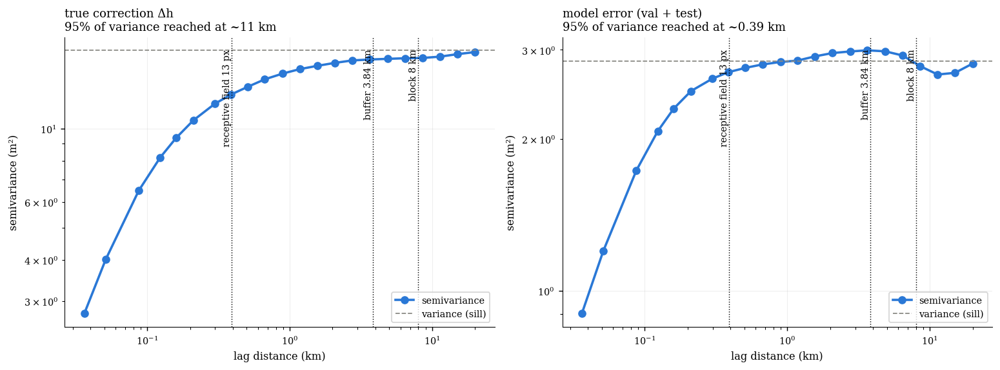

In [ ]:
def _pair(a, sy, sx):
    """a[y, x] and a[y + sy, x + sx] over the overlapping area."""
    H, W = a.shape
    y0, y1 = max(0, -sy), H - max(0, sy)
    x0, x1 = max(0, -sx), W - max(0, sx)
    return a[y0:y1, x0:x1], a[y0 + sy:y1 + sy, x0 + sx:x1 + sx]


def semivariogram(a, max_km=20.0, n_lags=24, max_pairs=2_000_000, seed=0):
    """gamma(h) = 0.5 * mean((a(x) - a(x+h))^2), averaged over 4 directions (E, S, SE, SW)."""
    rng = np.random.default_rng(seed)
    lags = np.unique(np.round(np.geomspace(1, max_km * 1000 / PIXEL_M, n_lags)).astype(int))
    dist_km, gamma = [], []
    for L in lags:
        d2, dd = [], []
        for dy, dx in ((0, 1), (1, 0), (1, 1), (1, -1)):
            n = math.hypot(dy, dx)
            sy, sx = int(round(dy * L / n)), int(round(dx * L / n))
            p, q = _pair(a, sy, sx)
            d = (p - q)[np.isfinite(p) & np.isfinite(q)]
            if d.size > max_pairs:
                d = rng.choice(d, max_pairs, replace=False)
            d2.append(d ** 2); dd.append(np.full(d.size, math.hypot(sy, sx)))
        d2, dd = np.concatenate(d2), np.concatenate(dd)
        if d2.size:
            gamma.append(0.5 * d2.mean()); dist_km.append(dd.mean() * PIXEL_M / 1000)
    return np.array(dist_km), np.array(gamma)


def variogram_plot(block_km=8.0, buffer_km=1.0):
    """Left: true correction. Right: model error on held-out pixels (val + test)."""
    held_err = np.where(SET_MAP >= 1, ERR_FULL, np.nan)
    tgt = np.where(valid, target, np.nan)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, a, name in ((axes[0], tgt, "true correction Δh"), (axes[1], held_err, "model error (val + test)")):
        h, g = semivariogram(a)
        sill = np.nanvar(a)
        reach = h[np.argmax(g >= 0.95 * sill)] if np.any(g >= 0.95 * sill) else np.nan
        ax.plot(h, g, color="#2a78d6", marker="o", ms=6, lw=2, label="semivariance")
        ax.axhline(sill, color="#8a8a85", ls="--", lw=1, label="variance (sill)")
        for x, lab in ((13 * PIXEL_M / 1000, "receptive field 13 px"), (buffer_km, f"buffer {buffer_km:g} km"),
                       (block_km, f"block {block_km:g} km")):
            ax.axvline(x, color="black", lw=0.8, ls=":")
            ax.text(x, 0.97, f"{lab} ", transform=ax.get_xaxis_transform(), rotation=90, va="top", ha="right", fontsize=8)
        ax.set_xscale("log"); ax.set_yscale("log")
        ax.set_xlabel("lag distance (km)"); ax.set_ylabel("semivariance (m²)")
        ax.set_title(f"{name}\n95% of variance reached at ~{reach:.2g} km"); ax.grid(alpha=0.3); ax.legend(loc="lower right")
        print(f"{name}: variance {sill:.2f} m², 95% of it reached at ~{reach:.2g} km")
    plt.tight_layout(); plt.show()


variogram_plot(block_km=8.0, buffer_km=GAP_PX * PIXEL_M / 1000)


  distance (km)   pixels  RMSE (m)  bias (m)
   3.0 –   4.0     4956     1.742     0.064
   4.0 –   5.0    32663     1.503     0.019
   5.0 –   6.0    32720     1.683     0.112
   6.0 –   7.0    33647     1.885     0.214
   7.0 –   8.0    32806     1.727     0.243
   8.0 –   9.0    32805     1.007     0.153
   9.0 –  10.0    33709     1.131     0.072
  10.0 –  11.0    19898     1.532     0.008


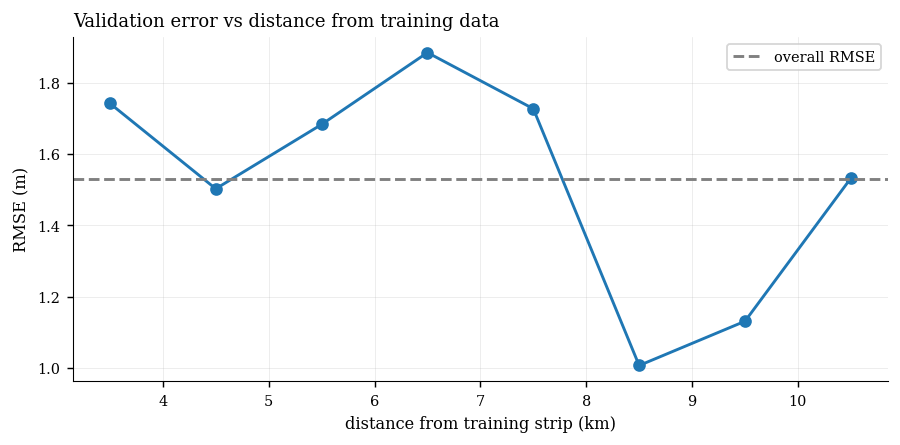

In [ ]:
# CHECK FOR LEAKAGE - DISTANCE OF VALIDATION FROM TRAINING DATA

import numpy as np
import matplotlib.pyplot as plt

# ----  per-pixel errors and global columns on the validation blocks ----
errs, xs_all = [], []
model.eval()
with torch.no_grad():
    for ep in VAL_SET:
        with amp_ctx():
            mu, lv = model(ep["x"], ep["obs_dh"], ep["obs_mask"],
                           origin_yx=ep["origin"], dsm_hw=(H_DSM, W_DSM))
        mu = mu[0, 0].float().to(DEVICE)
        sel = ep["valid"][0, 0] & ~ep["obs_mask"][0, 0] & ep["score_mask"][0, 0]
        yy, xx = sel.nonzero(as_tuple=True)
        err = mu[sel] - ep["target"][0, 0][sel].float()
        errs.append(err.cpu().numpy())
        if W_DSM >= H_DSM:                                   # strips split along x
            xs_all.append((xx + ep["origin"][1]).cpu().numpy())
        else:                                                # strips split along y
            xs_all.append((yy + ep["origin"][0]).cpu().numpy())

err = np.concatenate(errs)
pos = np.concatenate(xs_all)

# ----  distance from the training strip ----
train_end = TRAIN_BOX[3] if W_DSM >= H_DSM else TRAIN_BOX[2]   # first column/row after training
d_km = (pos - (train_end - 1)) * PIXEL_M / 1000

# ----  RMSE per 1 km bin ----
edges = np.arange(np.floor(d_km.min()), np.ceil(d_km.max()) + 1, 1.0)
idx = np.digitize(d_km, edges) - 1
print(f"{'distance (km)':>15s} {'pixels':>8s} {'RMSE (m)':>9s} {'bias (m)':>9s}")
centres, rmses = [], []
for k in range(len(edges) - 1):
    e = err[idx == k]
    if len(e) < 500:                      # skip near-empty bins
        continue
    centres.append(0.5 * (edges[k] + edges[k + 1]))
    rmses.append(np.sqrt(np.mean(e ** 2)))
    print(f"{edges[k]:6.1f} – {edges[k+1]:5.1f} {len(e):8d} {rmses[-1]:9.3f} {e.mean():9.3f}")

# ----  plot ----
plt.figure(figsize=(7, 3.5))
plt.plot(centres, rmses, "o-")
plt.axhline(np.sqrt(np.mean(err ** 2)), ls="--", c="grey", label="overall RMSE")
plt.xlabel("distance from training strip (km)")
plt.ylabel("RMSE (m)")
plt.title("Validation error vs distance from training data")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

Building edges > 2 m: 549,993 held-out px within ±30 px | distances drawn -30 to 29 px (classes with > 200 px)
Canopy edges > 5 m: 553,461 held-out px within ±30 px | distances drawn -12 to 28 px (classes with > 200 px)


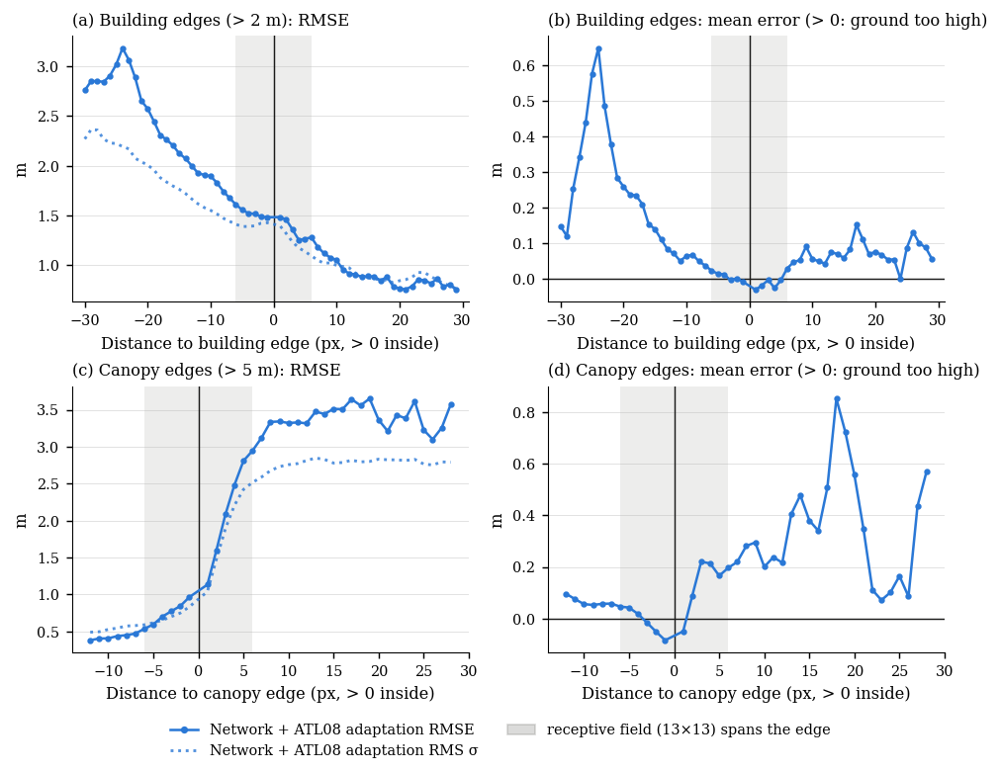

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.ndimage import distance_transform_edt

C_OURS, C_OTHER = "#2a78d6", "#6250d6"              # site B colours: corrected DTM blue, comparison (FABDEM) purple
OURS = "Network + ATL08 adaptation"

if "pub_style" not in globals():                     # same print settings as the block figures
    def pub_style(font_size=9, family="serif"):
        plt.rcParams.update({
            "font.family": family, "font.size": font_size, "axes.titlesize": font_size + 1,
            "axes.labelsize": font_size, "xtick.labelsize": font_size - 1, "ytick.labelsize": font_size - 1,
            "legend.fontsize": font_size - 1, "axes.spines.top": False, "axes.spines.right": False,
            "axes.linewidth": 0.6, "grid.linewidth": 0.4, "grid.alpha": 0.5, "lines.linewidth": 1.6,
            "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight", "axes.titlelocation": "left"})


def _signed_distance(band, thresh_m):
    """Signed distance (px) to the edge of `band` > thresh_m: > 0 inside the object, < 0 outside."""
    v = np.where(features_valid[band], features[band], 0.0)
    tall = v > thresh_m
    return np.where(tall, distance_transform_edt(tall), -distance_transform_edt(~tall))


def _edge_curve(err, signed, max_px, sig=None, min_px=200):
    """Per signed distance k (px): RMSE, mean error and (if sig is given) RMS sigma, held-out pixels only."""
    sel = np.isfinite(err) & (SET_MAP >= 1) & (np.abs(signed) <= max_px)
    if sig is not None:
        sel &= np.isfinite(sig)
    d = np.round(signed[sel]).astype(int)
    e = err[sel]; s = sig[sel] if sig is not None else None
    out = dict(k=[], rmse=[], bias=[], rsig=[], n=[])
    for k in range(-max_px, max_px + 1):
        m = d == k
        if m.sum() > min_px:
            out["k"].append(k); out["n"].append(int(m.sum()))
            out["rmse"].append(np.sqrt(np.mean(e[m] ** 2))); out["bias"].append(np.mean(e[m]))
            out["rsig"].append(np.sqrt(np.mean(s[m] ** 2)) if s is not None else np.nan)
    return {k: np.asarray(v) for k, v in out.items()}


def edge_profiles(layers=("bldg", "canopy"), max_px=30, rf_px=13, others=None):
    """CHANGED: one 2 x 2 figure. Rows = edge types (buildings > 2 m, canopy > 5 m); columns =
    RMSE (+ RMS predicted σ of the corrected DTM, dotted) | mean error (> 0: ground too high).
    others: optional {label: error map on the tile A grid} drawn in purple, e.g. {"Network only (B6)": ERR_NET}."""
    spec = {"bldg": (F_BLDG, "Building", 2.0), "canopy": (F_CANOPY, "Canopy", 5.0)}
    half = rf_px // 2
    fig, axes = plt.subplots(len(layers), 2, figsize=(7.4, 2.6 * len(layers) + 0.7), constrained_layout=True,
                             squeeze=False)
    for r, layer in enumerate(layers):
        band, name, thr = spec[layer]
        signed = _signed_distance(band, thr)
        curves = [(OURS, C_OURS, _edge_curve(ERR_FULL, signed, max_px, SIG_FULL))]
        for lab, err in (others or {}).items():
            curves.append((lab, C_OTHER, _edge_curve(err, signed, max_px)))
        a1, a2 = axes[r]
        for ax in (a1, a2):
            ax.axvspan(-half, half, color="#8a8a85", alpha=0.15, lw=0)
            ax.axvline(0, color="#1a1a19", lw=0.8)
            ax.set_xlabel(f"Distance to {name.lower()} edge (px, > 0 inside)"); ax.set_ylabel("m")
            ax.grid(True, axis="y")
        a2.axhline(0, color="#1a1a19", lw=0.8)
        for lab, col, c in curves:
            a1.plot(c["k"], c["rmse"], color=col, marker="o", ms=2.5, lw=1.4)
            a2.plot(c["k"], c["bias"], color=col, marker="o", ms=2.5, lw=1.4)
            if lab == OURS:
                a1.plot(c["k"], c["rsig"], color=col, ls=":", lw=1.6, alpha=0.8)
        k_lo = min(c["k"].min() for _, _, c in curves); k_hi = max(c["k"].max() for _, _, c in curves)
        for ax in (a1, a2):                              # x range = the distances that have data, as at site B
            ax.set_xlim(min(k_lo, -half) - 2, max(k_hi, half) + 2)
        i = 2 * r
        a1.set_title(f"({'abcdefgh'[i]}) {name} edges (> {thr:g} m): RMSE", fontsize=9)
        a2.set_title(f"({'abcdefgh'[i + 1]}) {name} edges: mean error (> 0: ground too high)", fontsize=9)
        ours = curves[0][2]
        print(f"{name} edges > {thr:g} m: {ours['n'].sum():,} held-out px within ±{max_px} px | "
              f"distances drawn {ours['k'].min()} to {ours['k'].max()} px (classes with > 200 px)")

    handles = [Line2D([], [], color=C_OURS, marker="o", ms=3, lw=1.4, label=f"{OURS} RMSE"),
               Line2D([], [], color=C_OURS, ls=":", lw=1.6, alpha=0.8, label=f"{OURS} RMS σ")]
    handles += [Line2D([], [], color=C_OTHER, marker="o", ms=3, lw=1.4, label=f"{lab} RMSE") for lab in (others or {})]
    handles.append(Patch(color="#8a8a85", alpha=0.3, label=f"receptive field ({rf_px}×{rf_px}) spans the edge"))
    fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False)
    plt.show()


pub_style()
edge_profiles()

## STUDIES (UK and Europe)

###Ablation

loaded /content/drive/MyDrive/dsm_dtm_calibration_TTT/model_v3/checkpoints/realistic_icesat/best.pt | step 2200 | best validation loss 0.3199
test strip: {'rmse': 2.044, 'rmse_dsm': 6.249, 'mae': 1.231, 'bias': 0.119, 'cover95': 0.947, 'sigma': 1.449, 'nll': 0.742}
357,953 off-track test pixels | uncorrected DSM RMSE 6.475 m

            with ICESat   empty mask     change
rmse              2.087        4.954     +2.868 m
mae               1.213        2.629     +1.416 m
bias              0.095        2.142     +2.047 m
rms_sigma         1.847        4.429     +2.582 m
cover95           0.947        0.973     +0.025 
nll               0.718        0.931     +0.213 

episode  ICESat px  RMSE with  RMSE empty  TTT gain
      0        520      1.289       2.756    +1.467
      1        370      2.395       5.956    +3.560
      2        436      2.447       5.661    +3.214
ICESat lowers RMSE in 3 of 3 episodes (mean gain +2.747 m)


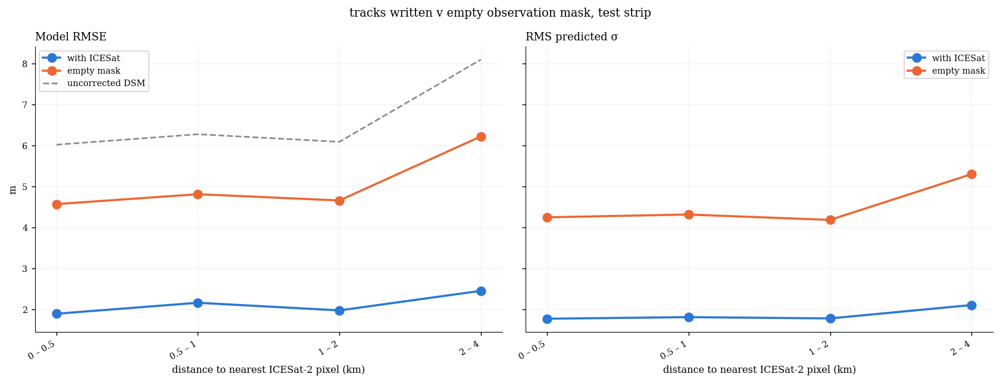

({'with ICESat': {'rmse': np.float32(2.0866013),
   'mae': np.float32(1.2134184),
   'bias': np.float32(0.095178194),
   'rms_sigma': np.float32(1.8468434),
   'cover95': np.float64(0.9473282805284493),
   'nll': np.float32(0.718497)},
  'empty mask': {'rmse': np.float32(4.954204),
   'mae': np.float32(2.6293368),
   'bias': np.float32(2.1418118),
   'rms_sigma': np.float32(4.4286666),
   'cover95': np.float64(0.9727561998362914),
   'nll': np.float32(0.9314835)}},
 [{'ep': 0,
   'icesat_px': 520,
   'with ICESat': np.float32(1.2894946),
   'empty mask': np.float32(2.7560077)},
  {'ep': 1,
   'icesat_px': 370,
   'with ICESat': np.float32(2.395255),
   'empty mask': np.float32(5.9556317)},
  {'ep': 2,
   'icesat_px': 436,
   'with ICESat': np.float32(2.4468918),
   'empty mask': np.float32(5.660848)}])

In [ ]:
# ======= test with zero-mask for no icesat pixels ==========
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt

C_WITH, C_EMPTY, C_REF = "#2a78d6", "#eb6834", "#8a8a85"

@torch.no_grad()
def run_episode(model, e, empty=False):
  """mu and log-var [H, W] for one episode, with tracks or with empty mask"""
  obs = torch.zeros_like(e["obs_mask"]) if empty else e["obs_mask"]
  obs_dh = torch.zeros_like(e["obs_dh"]) if empty else e["obs_dh"]
  with amp_ctx():
    mu, lv = model(e["x"], obs_dh, obs, origin_yx=e["origin"],
                   dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))

  return mu[0, 0].float().cpu().numpy(), lv[0, 0].float().cpu().numpy()

def _metrics(err, lv):
  sig2 = np.exp(lv)
  return dict(rmse=np.sqrt(np.mean(err ** 2)), mae=np.mean(np.abs(err)), bias=np.mean(err),
              rms_sigma=np.sqrt(np.mean(sig2)), cover95=np.mean(np.abs(err) <= 1.96 * np.sqrt(sig2)),
              nll=np.mean(0.5 * (lv + err ** 2 / sig2)))

def test(model, episodes, dist_edges_km=(0, 0.5, 1, 2, 4, 8, 16, 32, np.inf)):
  model.eval()
  conds = (("with ICESat", False), ("empty mask", True))
  pooled = {c: dict(err=[], lv=[]) for c, _ in conds}
  tgt_all, dist_all, per_ep = [], [], []

  for i, e in enumerate(episodes):
    tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
    sel = val & ~obs
    dist = distance_transform_edt(~obs) * PIXEL_M / 1000 if obs.any() else np.full(obs.shape, np.inf)
    row = dict(ep=i, icesat_px=int(obs.sum()))
    for c, empty in conds:
      mu, lv = run_episode(model, e, empty)
      err = (mu - tgt)[sel]
      pooled[c]["err"].append(err); pooled[c]["lv"].append(lv[sel])
      row[c] = np.sqrt(np.mean(err ** 2))

    tgt_all.append(tgt[sel]); dist_all.append(dist[sel]); per_ep.append(row)

  tgt_all, dist_all = np.concatenate(tgt_all), np.concatenate(dist_all)
  M = {c: _metrics(np.concatenate(pooled[c]["err"]), np.concatenate(pooled[c]["lv"])) for c, _ in conds}

  # --- pooled metrics ---
  print(f"{len(tgt_all):,} off-track test pixels | uncorrected DSM RMSE {np.sqrt(np.mean(tgt_all ** 2)):.3f} m\n")
  print(f"{'':10s} {'with ICESat':>12s} {'empty mask':>12s} {'change':>10s}")
  for k, unit in (("rmse", "m"), ("mae", "m"), ("bias", "m"), ("rms_sigma", "m"), ("cover95", ""), ("nll", "")):
    a, b = M["with ICESat"][k], M["empty mask"][k]
    print(f"{k:10s} {a:12.3f} {b:12.3f} {b - a:+10.3f} {unit}")

  # --- per episode (paired) ---
  print(f"\n{'episode':>7s} {'ICESat px':>10s} {'RMSE with':>10s} {'RMSE empty':>11s} {'TTT gain':>9s}")
  for r in per_ep:
    print(f"{r['ep']:7d} {r['icesat_px']:10,d} {r['with ICESat']:10.3f} {r['empty mask']:11.3f} {r['empty mask'] - r['with ICESat']:+9.3f}")

  gains = np.array([r["empty mask"] - r["with ICESat"] for r in per_ep])
  print(f"ICESat lowers RMSE in {np.sum(gains > 0)} of {len(gains)} episodes (mean gain {gains.mean():+.3f} m)")

  # --- track gains by distance to original tracks ---
  edges = np.asarray(dist_edges_km, float)
  b = np.digitize(dist_all, edges) - 1
  keep = (b >= 0) & (b < len(edges) - 1)
  labels, stats = [], {c: dict(rmse=[], rsig=[]) for c, _ in conds}
  dsm_rmse = []

  for j in range(len(edges) - 1):
    m = keep & (b == j)
    if m.sum() < 200:
      continue
    labels.append(f"{edges[j]:g} – {edges[j + 1]:g}")
    dsm_rmse.append(np.sqrt(np.mean(tgt_all[m] ** 2)))
    for c, _ in conds:
      err = np.concatenate(pooled[c]["err"])[m]
      lv = np.concatenate(pooled[c]["lv"])[m]
      stats[c]["rmse"].append(np.sqrt(np.mean(err ** 2)))
      stats[c]["rsig"].append(np.sqrt(np.mean(np.exp(lv))))

  pos = np.arange(len(labels))
  fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
  for c, col in zip(stats, (C_WITH, C_EMPTY)):
    a1.plot(pos, stats[c]["rmse"], color=col, marker="o", ms=8, lw=2, label=c)
    a2.plot(pos, stats[c]["rsig"], color=col, marker="o", ms=8, lw=2, label=c)
  a1.plot(pos, dsm_rmse, color=C_REF, ls="--", lw=1.5, label="uncorrected DSM")
  a1.set_title("Model RMSE"); a2.set_title("RMS predicted σ")
  for ax in (a1, a2):
    ax.set_xticks(pos); ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_xlabel("distance to nearest ICESat-2 pixel (km)"); ax.grid(alpha=0.3); ax.legend()
  a1.set_ylabel("m")
  fig.suptitle("tracks written v empty observation mask, test strip")
  plt.tight_layout(); plt.show()

  return M, per_ep


# run the test and plot

CKPT_TEST = f"{BASE_DIR}/model_v3/checkpoints/realistic_icesat/best.pt"

ck = torch.load(CKPT_TEST, map_location=DEVICE, weights_only=False)

model = ProbabilisticCalibrator(**ck["cfg"]).to(DEVICE)
model.load_state_dict(ck["model"])
model.eval()

print(f"loaded {CKPT_TEST} | step {ck['step'] + 1} | best validation loss {ck['best']:.4f}")

res = evaluate(model, TEST_SET[1:])
print("test strip:", {k: round(float(v), 3) for k, v in res.items()})   # CHANGED: every metric

test(model, TEST_SET[1:])


In [ ]:
e = TEST_SET[2]                                                  # the block with 520 ICESat pixels
mu1, _ = run_episode(model, e, empty=False)
mu0, _ = run_episode(model, e, empty=True)
print(f"max |mu with - mu empty| {np.abs(mu1 - mu0).max():.4f} m | mean {np.abs(mu1 - mu0).mean():.5f} m")

# A) what the adaptation sees: ICESat values minus the network-alone prediction at the ICESat pixels
o = e["obs_mask"][0, 0].cpu().numpy().astype(bool)
r = e["obs_dh"][0, 0].cpu().numpy()[o] - mu0[o]
print(f"ICESat residuals vs network alone: mean {r.mean():+.3f} m | RMS {np.sqrt(np.mean(r ** 2)):.3f} m "
      f"(pure 1.0 m noise would give mean ~0, RMS ~1.0)")

# B) what the read actually applies: size of the blended dW and how many pixels have data
cap = []
hook = model.grid_gat.register_forward_hook(
    lambda m, i, out: cap.append((out[0].detach().abs().mean().item(),       # mean |dW|
                                  out[1][:, 2].float().mean().item())))       # share of pixels with a data node
run_episode(model, e, empty=False)
hook.remove()
dw = np.mean([c[0] for c in cap]); has = np.mean([c[1] for c in cap])
print(f"read pass: mean |dW| {dw:.5f} | share of pixels with a data node nearby {has:.1%}")

max |mu with - mu empty| 18.9192 m | mean 3.17785 m
ICESat residuals vs network alone: mean -1.980 m | RMS 4.661 m (pure 1.0 m noise would give mean ~0, RMS ~1.0)
read pass: mean |dW| 0.73452 | share of pixels with a data node nearby 100.0%


loaded /content/drive/MyDrive/dsm_dtm_calibration_TTT/model_v3/checkpoints/realistic_icesat/best.pt | step 2200 | best validation loss 0.3199
test strip: {'rmse': 2.272, 'rmse_dsm': 5.641, 'mae': 1.241, 'bias': 0.295, 'cover95': 0.955, 'sigma': 1.479, 'nll': 0.635}
357,953 off-track test pixels

                              RMSE     MAE    bias   RMS σ  cover95     NLL
A uncorrected DSM            6.475   3.421  +3.145      —        —       —
B ICESat mean only           5.535   3.941  +0.451  5.057    0.906   2.153
C network only               4.954   2.629  +2.142  4.429    0.973   0.931
D network + global offset    4.384   3.062  +0.359  4.429    0.624   3.166

 ep  ICESat px  ICESat mean  offset b RMSE A  RMSE B  RMSE C  RMSE D
  0        520       -1.396    -0.889  3.519   3.317   2.756   2.668
  1        370       -2.913    -1.980  7.799   6.642   5.956   5.239
  2        436       -4.042    -2.655  7.427   6.189   5.661   4.905
global offset lowers RMSE vs network alone in 3 of

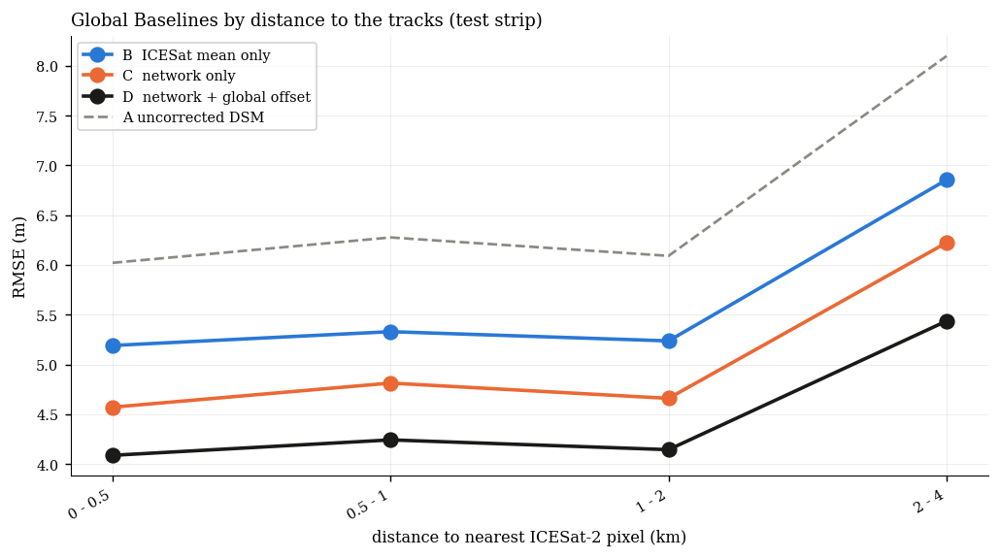

In [ ]:
# ------- global baseline test for the closed-form last-layer adaptation --------
# B: ICESat mean only: no network
# D: network + global offset: network with empty observation mask plus one scalar b = mean(ICESat delta_h - mu_C) over the ICESat-2 pixels; sigma = network sigma
# C: the model output above (network only no last-layer adaptation)

import numpy as np
import matplotlib.pyplot as plt
from affine import Affine
from scipy.ndimage import distance_transform_edt

C_B, C_C, C_D, C_REF = "#2a78d6", "#eb6834", "#1a1a19", "#8a8a85"
C_HIGH, C_LOW = "#eb6834", "#2a78d6"                               # error dots, high/low to GT

@torch.no_grad()
def network_empty(model, e):
  """empty observation mask network"""
  with amp_ctx():
    mu, lv = model(e["x"], torch.zeros_like(e["obs_dh"]), torch.zeros_like(e["obs_mask"]),
                   origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))

  return mu[0, 0].float().cpu().numpy(), lv[0, 0].float().cpu().numpy()


def global_baselines(model, e):
  """mu / log-variance maps of B, C and D for one episode, plus the scalars used for the inference"""
  obs = e["obs_mask"][0, 0].cpu().numpy().astype(bool)
  dh_obs = e["obs_dh"][0, 0].cpu().numpy()[obs]
  mu_c, lv_c = network_empty(model, e)
  shape = mu_c.shape
  if obs.any():
    m_b = dh_obs.mean()                                          # mean
    s_b = dh_obs.std()                                           # std
    b_d = np.mean(dh_obs - mu_c[obs])                            # global offset
  else:
    m_b, s_b, b_d = 0.0, np.nan, 0.0

  out = {
      "B": (np.full(shape, m_b), np.full(shape, 2 * np.log(s_b) if s_b > 0 else np.nan)),
      "C": (mu_c, lv_c),
      "D": (mu_c + b_d, lv_c)
  }
  return out, dict(icesat_px=int(obs.sum()), icesat_mean=m_b, icesat_std=s_b, offset_d=b_d)

def _m(err, lv):
  r = dict(rmse=np.sqrt(np.mean(err ** 2)), mae=np.mean(np.abs(err)), bias=np.mean(err))
  if np.all(np.isfinite(lv)):
    s2 = np.exp(lv)
    r.update(rms_sigma=np.sqrt(np.mean(s2)), cover95=np.mean(np.abs(err) <= 1.96 * np.sqrt(s2)),
             nll=np.mean(0.5 * (lv + err ** 2 / s2)))
  return r

def global_offset_test(model, episodes, dist_edges_km=(0, 0.5, 1, 2, 4, 8, 16, 32, np.inf)):
  model.eval()
  rows = ("B", "C", "D")
  names = {"A": "uncorrected DSM", "B": "ICESat mean only", "C": "network only", "D": "network + global offset"}
  pool = {k: dict(err=[], lv=[]) for k in rows}
  tgt_all, dist_all, per_ep = [], [], []
  for i, e in enumerate(episodes):
    tgt, val, obs = (e[k][0,0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
    obs = obs.astype(bool)
    sel = val.astype(bool) & ~obs
    maps, info = global_baselines(model, e)
    dist = distance_transform_edt(~obs) * PIXEL_M / 1000 if obs.any() else np.full(obs.shape, np.inf)
    r = dict(ep=i, **info)
    for k in rows:
      mu, lv = maps[k]
      err, lv_sel = (mu - tgt)[sel], lv[sel]
      assert err.shape == lv_sel.shape
      pool[k]["err"].append(err); pool[k]["lv"].append(lv_sel)
      r[k] = np.sqrt(np.mean(err ** 2))
    r["A"] = np.sqrt(np.mean(tgt[sel] ** 2))
    tgt_all.append(tgt[sel]); dist_all.append(dist[sel]); per_ep.append(r)

  tgt_all, dist_all = np.concatenate(tgt_all), np.concatenate(dist_all)
  E = {k: np.concatenate(pool[k]["err"]) for k in rows}
  LV = {k: np.concatenate(pool[k]["lv"]) for k in rows}
  M = {"A": _m(-tgt_all, np.full(tgt_all.shape, np.nan))}
  M.update({k: _m(E[k], LV[k]) for k in rows})

  # --- pooled table ---
  print(f"{len(tgt_all):,} off-track test pixels\n")
  print(f"{'':26s} {'RMSE':>7s} {'MAE':>7s} {'bias':>7s} {'RMS σ':>7s} {'cover95':>8s} {'NLL':>7s}")
  for k in ("A", "B", "C", "D"):
    m = M[k]
    g = lambda key, f: f.format(m[key]) if key in m else f"{'—':>{len(f.format(0.0))}}"
    print(f"{k} {names[k]:24s} {g('rmse', '{:7.3f}')} {g('mae', '{:7.3f}')} {g('bias', '{:+7.3f}')}"
          f"{g('rms_sigma', '{:7.3f}')} {g('cover95', '{:8.3f}')} {g('nll', '{:7.3f}')}")

  # --- per episode ---
  print(f"\n{'ep':>3s} {'ICESat px':>10s} {'ICESat mean':>12s} {'offset b':>9s}"
        f"{'RMSE A':>7s} {'RMSE B':>7s} {'RMSE C':>7s} {'RMSE D':>7s}")
  for r in per_ep:
    print(f"{r['ep']:3d} {r['icesat_px']:10,d} {r['icesat_mean']:+12.3f} {r['offset_d']:+9.3f}"
          f"{r['A']:7.3f} {r['B']:7.3f} {r['C']:7.3f} {r['D']:7.3f}")
  gain = np.array([r["C"] - r["D"] for r in per_ep])
  print(f"global offset lowers RMSE vs network alone in {np.sum(gain > 0)} of {len(gain)} episodes"
        f"(mean {gain.mean():+.3f} m)")

  # --- RMSE by distance to ICESat tracks ---
  edges = np.asarray(dist_edges_km, float)
  b = np.digitize(dist_all, edges) - 1
  labels , curves, dsm = [], {k: [] for k in rows}, []
  for j in range(len(edges) - 1):
    m = b == j
    if m.sum() < 200:
      continue
    labels.append(f"{edges[j]:g} - {edges[j + 1]:g}")
    dsm.append(np.sqrt(np.mean(tgt_all[m] ** 2)))
    for k in rows:
      curves[k].append(np.sqrt(np.mean(E[k][m] ** 2)))

  pos = np.arange(len(labels))
  plt.figure(figsize=(8, 4.5))
  for k, col in zip(rows, (C_B, C_C, C_D)):
    plt.plot(pos, curves[k], color=col, marker="o", ms=8, lw=2, label=f"{k}  {names[k]}")
  plt.plot(pos, dsm, color=C_REF, ls="--", lw=1.5, label=f"A {names['A']}")
  plt.xticks(pos, labels, rotation=30, ha="right")
  plt.xlabel("distance to nearest ICESat-2 pixel (km)"); plt.ylabel("RMSE (m)")
  plt.title("Global Baselines by distance to the tracks (test strip)"); plt.grid(alpha=0.3)
  plt.legend(); plt.tight_layout(); plt.show()

  return M, per_ep

# ------- map: corrected DRM with the large errors as dots ----------
def show_dtm_errors(model, e, method="D", err_thresh_m=2.0, max_dots=30000, show_tracks=True, seed=0):
  """Grey: Pred_DTM = DSM + mu of 'method' ("B", "C", "D")
  Dots: off-track pixels with |error| > err_thresh_m; orange = ground too high (mu > true delta_h),
  blue = ground too low (mu < true delta_h); small black dots: simulated ICESat pixels for the episode"""
  maps, info = global_baselines(model, e)
  mu, _ = network_full(model, e) if method == "full" else maps[method]
  tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
  obs = obs.astype(bool)
  sel = val.astype(bool) & ~obs
  oy, ox = e["origin"]
  h, w = mu.shape
  dsm = RAW_DSM[oy:oy + h, ox:ox + w]
  dtm_hat = np.where(np.isfinite(dsm), dsm + mu, np.nan)
  err = np.where(sel, mu - tgt, np.nan)

  T = DSM_PROFILE["transform"] * Affine.translation(ox, oy)
  to_xy = lambda r, c: (T.c + (c+0.5) * T.a, T.f + (r+0.5) * T.e)        # pixel center -> map
  rng = np.random.default_rng(seed)

  def draw(ax):
    if show_tracks and obs.any():
      r, c = np.nonzero(obs)
      ax.scatter(*to_xy(r, c), s=0.2, color="black", label="ICESat-2 pixels")
    for mask, col, lab in ((err > err_thresh_m, C_HIGH, f"ground too high (> +{err_thresh_m:g}m)"),
                            (err < -err_thresh_m, C_LOW, f"ground too low (< -{err_thresh_m:g}m)")):
      r, c = np.nonzero(mask)
      if len(r) > max_dots:
        k = rng.choice(len(r), max_dots, replace=False); r, c = r[k], c[k]
      ax.scatter(*to_xy(r, c), s=1.0, color=col, label=lab)
    ax.legend(loc="upper right", markerscale=8, fontsize=8, framealpha=0.9)

  big = np.abs(err[sel]) > err_thresh_m
  title = {"B": "ICESat mean only", "C": "network alone", "D": "network + global offset", "full": "full with last-layer adaptation"}[method]
  offset = f"offset {info['offset_d']:+.3f} m | " if method == "D" else ""
  print(f"{title}: {offset}|error| > {err_thresh_m:g} m at {big.mean():.1%} of off-track pixels")
  show_map(dtm_hat, T, DSM_PROFILE["crs"], title=f"Predicted DTM, {title}", cmap="gray",
           cbar_label="m", extra=draw)



ck = torch.load(CKPT_TEST, map_location=DEVICE, weights_only=False)

model = ProbabilisticCalibrator(**ck["cfg"]).to(DEVICE)
model.load_state_dict(ck["model"])
model.eval()

print(f"loaded {CKPT_TEST} | step {ck['step'] + 1} | best validation loss {ck['best']:.4f}")

res = evaluate(model, TEST_SET)
print("test strip:", {k: round(float(v), 3) for k, v in res.items()})   # CHANGED: every metric

@torch.no_grad()
def network_full(model, e):
    """Trained network with the closed-form last-layer adaptation from the episode's ICESat tracks."""
    with amp_ctx():
        mu, lv = model(e["x"], e["obs_dh"], e["obs_mask"],
                       origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
    return mu[0, 0].float().cpu().numpy(), lv[0, 0].float().cpu().numpy()

M_GLOB, PER_EP_GLOB = global_offset_test(model, TEST_SET[1:])






network + global offset: offset -1.980 m | |error| > 2 m at 69.9% of off-track pixels


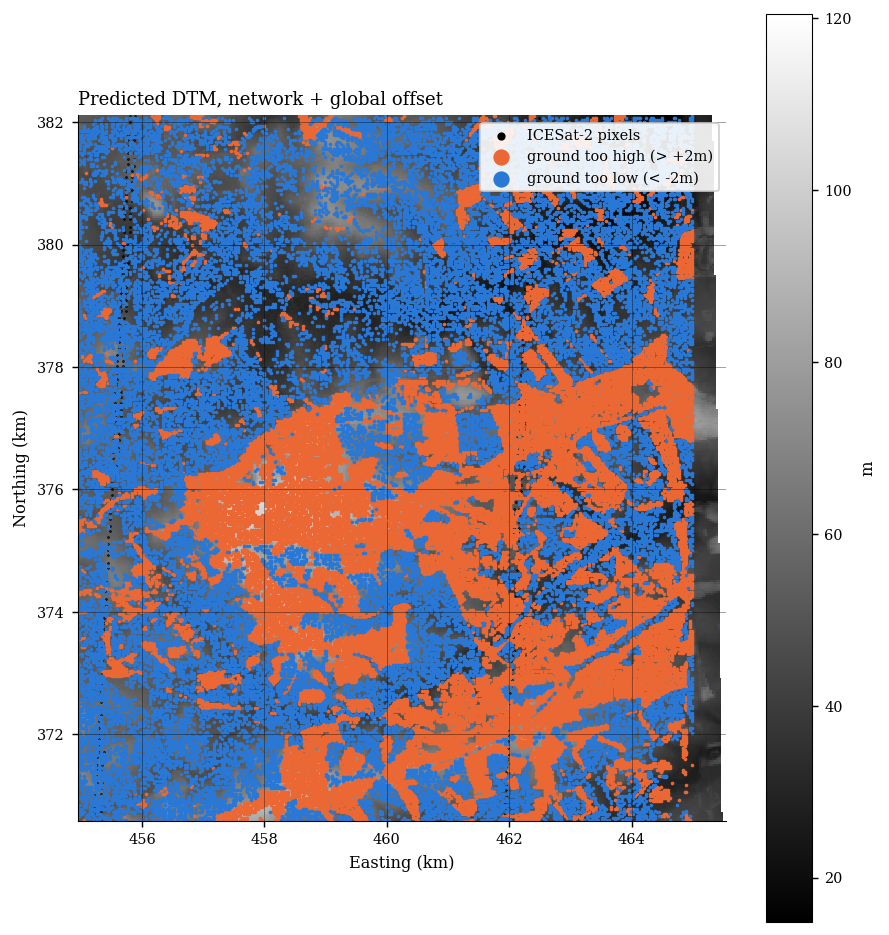

ICESat mean only: |error| > 2 m at 83.6% of off-track pixels


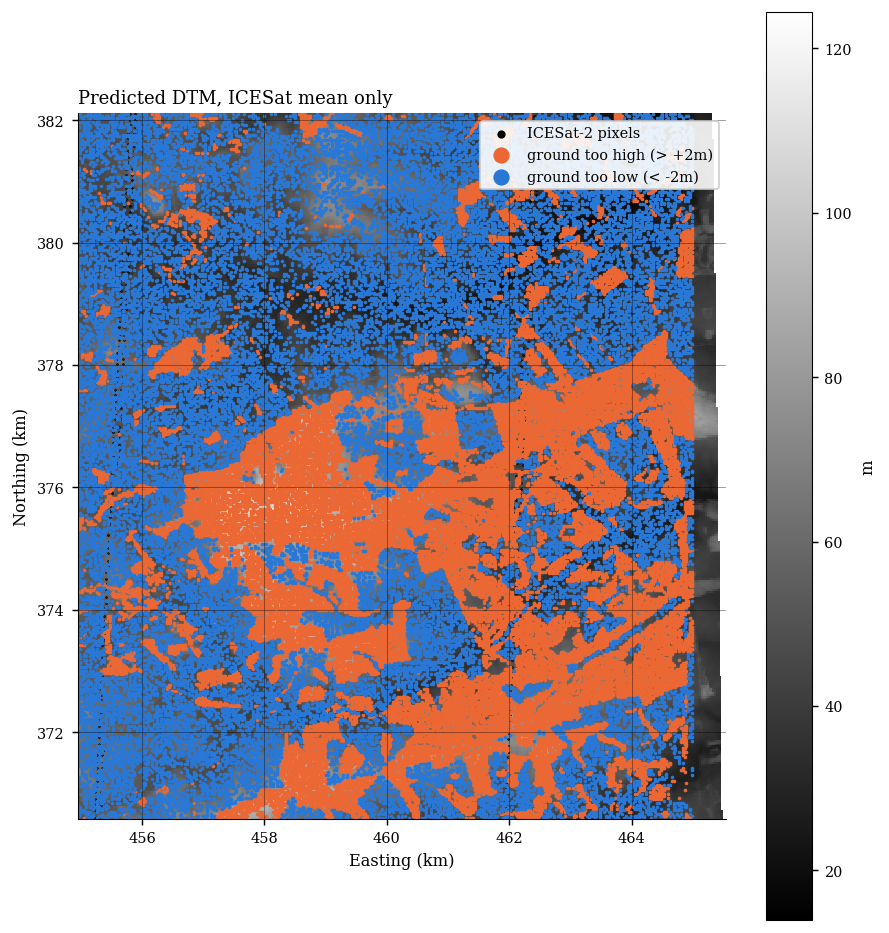

full with last-layer adaptation: |error| > 2 m at 24.2% of off-track pixels


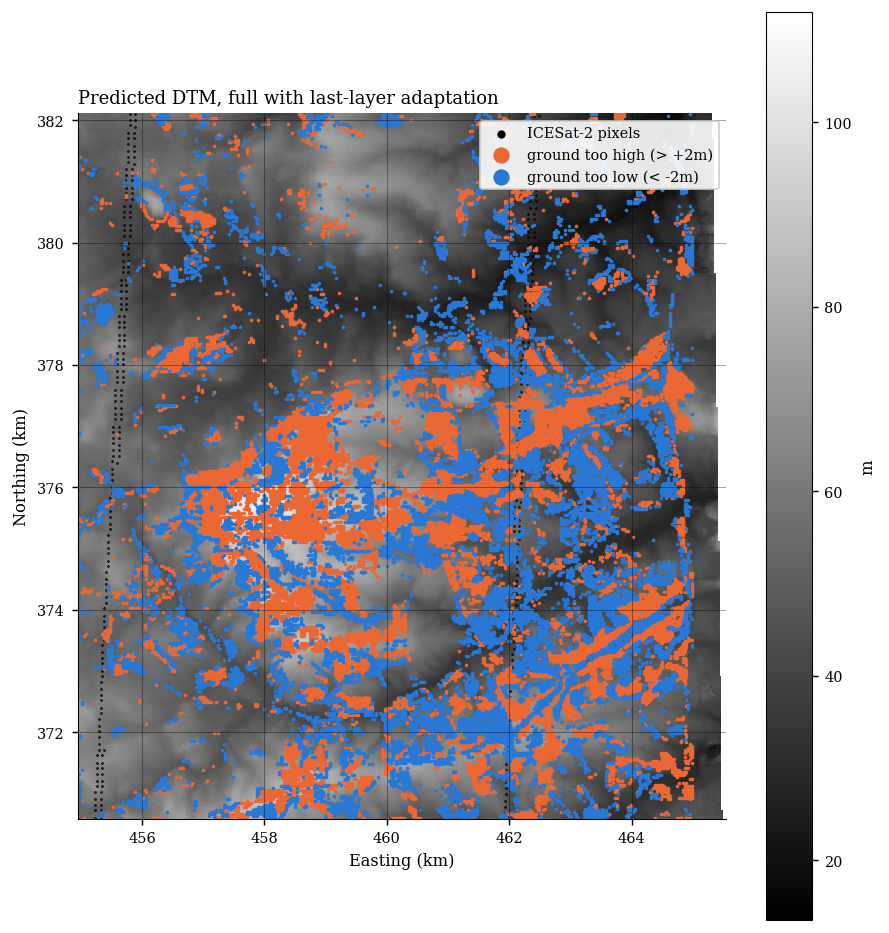

In [ ]:
show_dtm_errors(model, TEST_SET[2], method="D", err_thresh_m=2.0)
show_dtm_errors(model, TEST_SET[2], method="B", err_thresh_m=2.0)
show_dtm_errors(model, TEST_SET[2], method="full", err_thresh_m=2.0)

check: all-levels wrapper vs normal, max |difference 2.36e-03 m (should be about ~0)

357,953 off-track test pixels | uncorrected DSM RMSE 6.475 m
                      RMSE     MAE    bias   RMS σ  cover95     NLL  share of gain
C network alone      4.954   2.629  +2.142   4.429    0.973   0.931             0%
D global offset      4.384   3.062  +0.359   4.429    0.624   3.166            20%
1 km only            4.068   2.119  +1.257   3.542    0.925   1.087            31%
4 km only            2.203   1.289  +0.145   2.080    0.933   0.841            96%
16 km only           2.093   1.217  +0.093   1.860    0.948   0.718           100%
all levels           2.087   1.213  +0.095   1.847    0.947   0.718           100%
share of gain = (RMSE network alone - RMSE row) / (RMSE network alone - RMSE all levels)

 ep  ICESat px  C network alone  D global offset        1 km only        4 km only       16 km only       all levels
  0        520            2.756            2.668            2.136

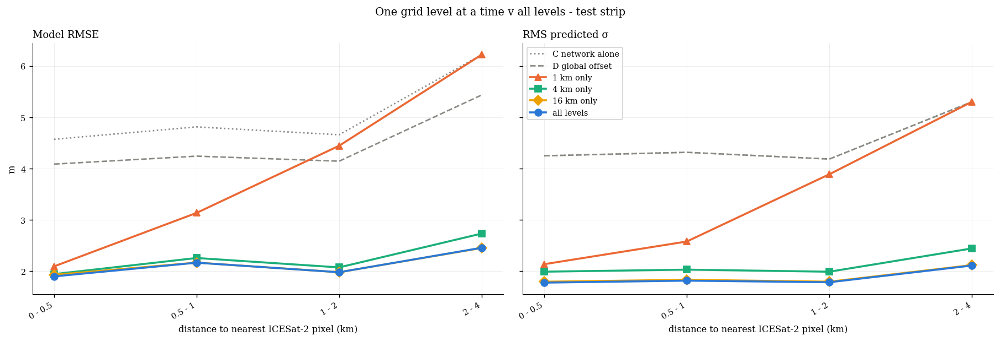

levels 1 km: |error| > 2 m at 32.6% of off-track pixels


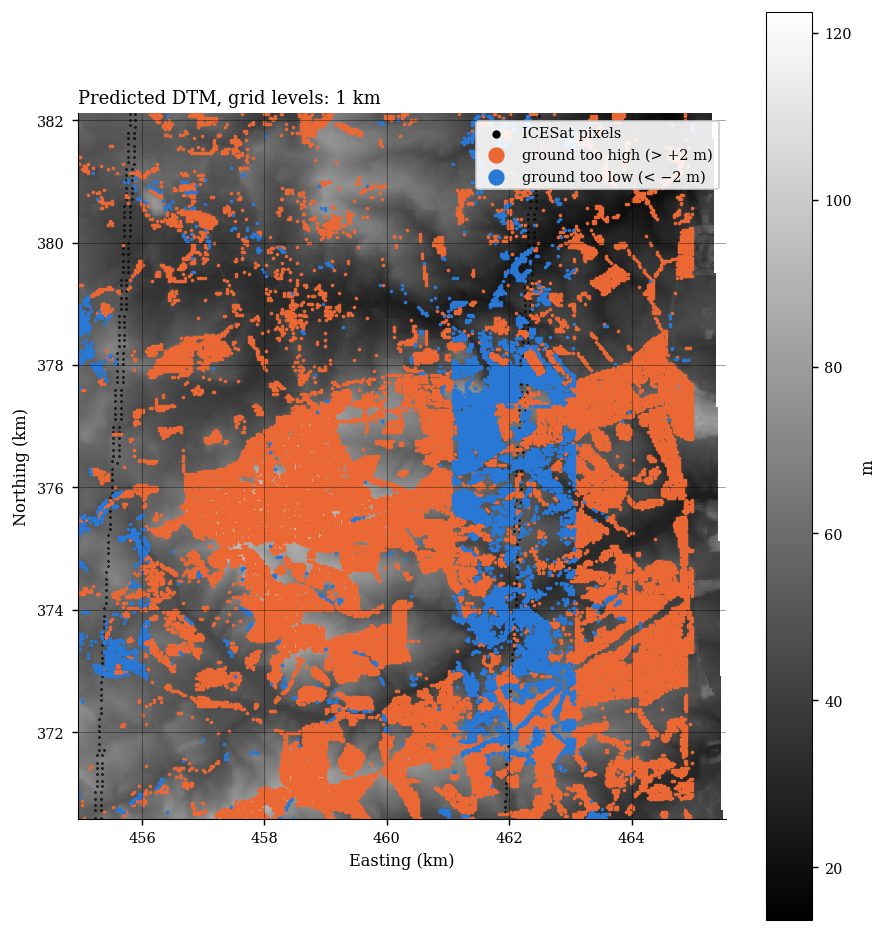

levels 4 km: |error| > 2 m at 25.2% of off-track pixels


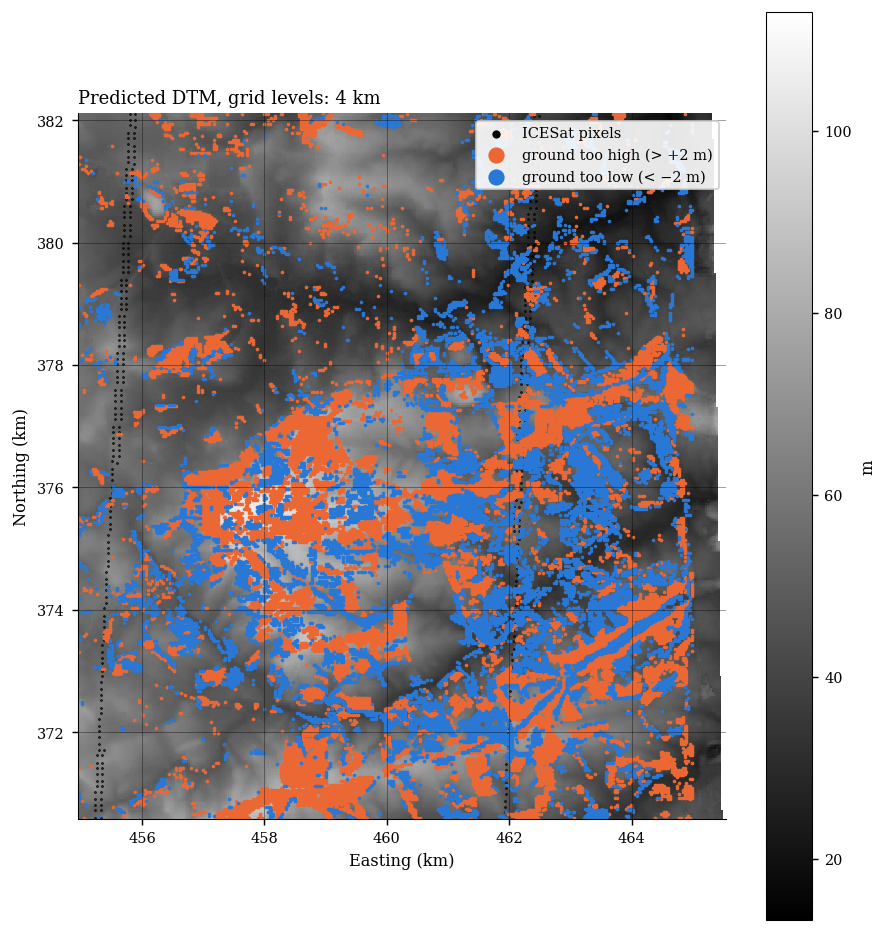

levels 16 km: |error| > 2 m at 24.2% of off-track pixels


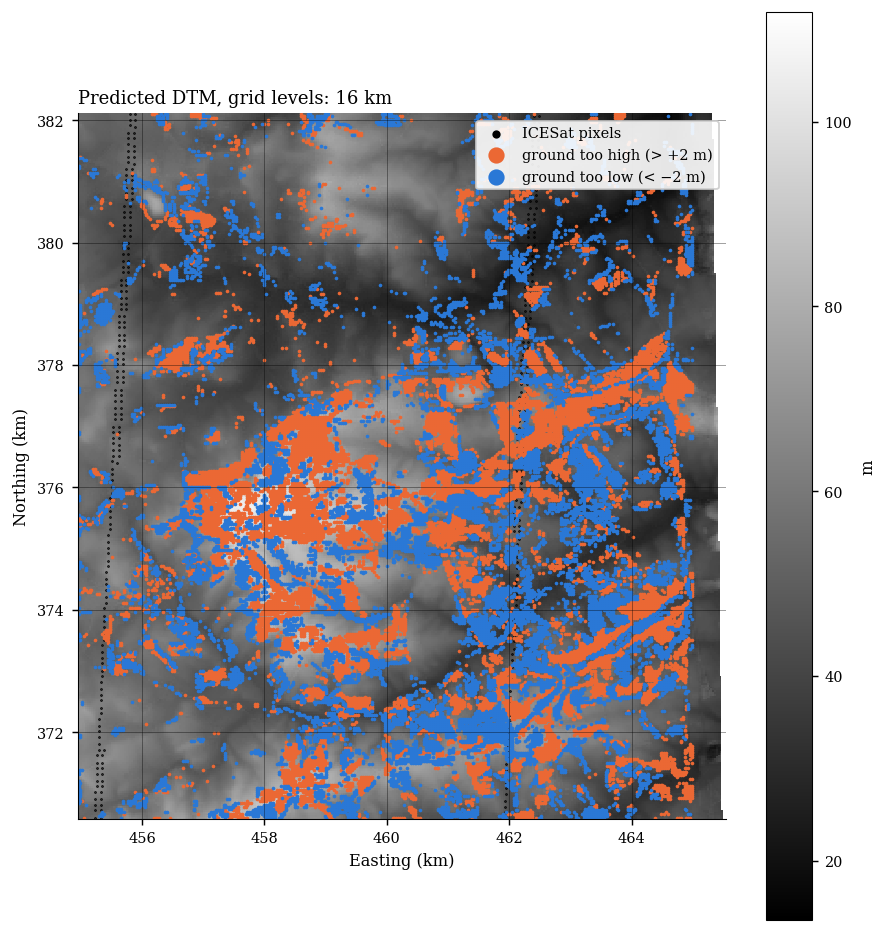

levels 1 km + 4 km + 16 km: |error| > 2 m at 24.2% of off-track pixels


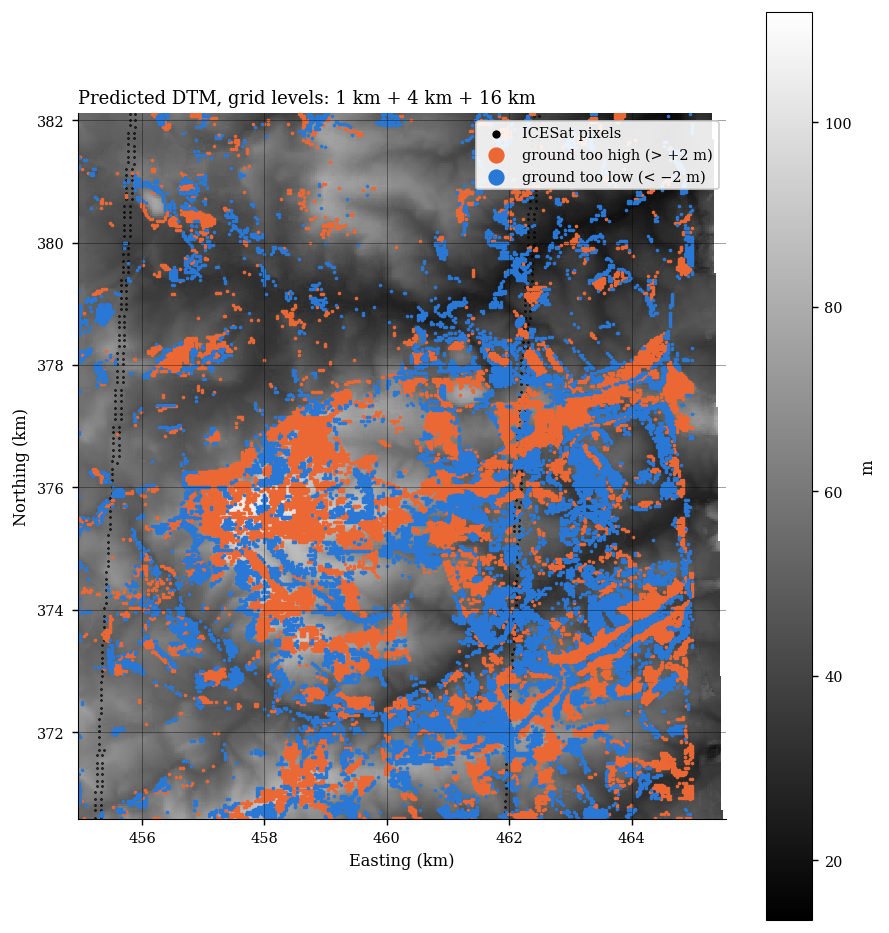

In [ ]:
# ------- single level test (to find out which one contributes the most) -----
import types
from contextlib import contextmanager
import numpy as np
import matplotlib.pyplot as plt
from affine import Affine
from scipy.ndimage import distance_transform_edt

C_FULL, C_LO, C_L1, C_L2, C_REF = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"


@contextmanager
def only_levels(model, keep):
  """read pass specific grid levels"""
  orig = type(model)._write_pass

  def patched(self, *args, **kwargs):
    levels = orig(self, *args, **kwargs)
    for li, L in enumerate(levels):
      if li not in keep:
        L["count"] = torch.zeros_like(L["count"])
        L["w"] = torch.zeros_like(L["w"])
    return levels

  model._write_pass = types.MethodType(patched, model)       # instance attribute shadows the class method
  try:
    yield
  finally:
    del model._write_pass                                    # back to normal


@torch.no_grad()
def predict_levels(model, e, keep):
  """mu, log-var [H,W] with episode's tracks, reading only levels in keep"""
  with only_levels(model, keep), amp_ctx():
    mu, lv = model(e["x"], e["obs_dh"], e["obs_mask"],
                   origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
  return mu[0, 0].float().cpu().numpy(), lv[0, 0].float().cpu().numpy()

def _met(err, lv):
  s2 = np.exp(lv)
  return dict(rmse=np.sqrt(np.mean(err ** 2)), mae=np.mean(np.abs(err)), bias=np.mean(err),
              rms_sigma=np.sqrt(np.mean(s2)), cover95=np.mean(np.abs(err) <= 1.96 * np.sqrt(s2)),
              nll=np.mean(0.5 * (lv + err ** 2 / s2)))


def level_ablation(model, episodes, dist_edges_km=(0, 0.5, 1, 2, 4, 8, 16, 32, np.inf)):
  model.eval()
  res_km = [r / 1000 for r in model.level_res_m]
  n_lv = len(res_km)
  configs = {f"{res_km[i]:g} km only": {i} for i in range(n_lv)}
  configs["all levels"] = set(range(n_lv))
  names = ["C network alone", "D global offset"] + list(configs)
  pool = {n: dict(err=[], lv=[]) for n in names}
  tgt_all, dist_all, per_ep = [], [], []

  # sanity check
  e0 = episodes[0]
  with torch.no_grad(), amp_ctx():
    mu_ref, _ = model(e0["x"], e0["obs_dh"], e0["obs_mask"], origin_yx=e0["origin"],
                      dsm_hw=e0.get("dsm_hw", (H_DSM, W_DSM)))
  diff = np.abs(predict_levels(model, e0, set(range(n_lv)))[0] - mu_ref[0, 0].float().cpu().numpy()).max()
  print(f"check: all-levels wrapper vs normal, max |difference {diff:.2e} m (should be about ~0)")

  for i, e in enumerate(episodes):
    tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
    obs = obs.astype(bool)
    sel = val.astype(bool) & ~obs
    dist = distance_transform_edt(~obs) * PIXEL_M / 1000 if obs.any() else np.full(obs.shape, np.inf)
    maps, info = global_baselines(model, e)
    preds = {"C network alone": maps["C"], "D global offset": maps["D"]}
    for n, keep in configs.items():
      preds[n] = predict_levels(model, e, keep)
    row = dict(ep=i, icesat_px=info["icesat_px"])
    for n in names:
      mu, lv = preds[n]
      err, lv_sel = (mu - tgt)[sel], lv[sel]
      assert err.shape == lv_sel.shape
      pool[n]["err"].append(err); pool[n]["lv"].append(lv_sel)
      row[n] = np.sqrt(np.mean(err ** 2))
    tgt_all.append(tgt[sel]); dist_all.append(dist[sel]); per_ep.append(row)

  tgt_all, dist_all = np.concatenate(tgt_all), np.concatenate(dist_all)
  E = {n: np.concatenate(pool[n]["err"]) for n in names}
  LV = {n: np.concatenate(pool[n]["lv"]) for n in names}
  M = {n: _met(E[n], LV[n]) for n in names}

  # --- pooled table, with share of the full gain each level achieves ---
  gain_full = M["C network alone"]["rmse"] - M["all levels"]["rmse"]
  print(f"\n{len(tgt_all):,} off-track test pixels | uncorrected DSM RMSE {np.sqrt(np.mean(tgt_all ** 2)):.3f} m")
  print(f"{'':18s} {'RMSE':>7s} {'MAE':>7s} {'bias':>7s} {'RMS σ':>7s} {'cover95':>8s} {'NLL':>7s} "
        f"{'share of gain':>14s}")
  for n in names:
    m = M[n]
    share = (M["C network alone"]["rmse"] - m["rmse"]) / gain_full if gain_full > 0 else np.nan
    print(f"{n:18s} {m['rmse']:7.3f} {m['mae']:7.3f} {m['bias']:+7.3f} {m['rms_sigma']:7.3f} "
          f"{m['cover95']:8.3f} {m['nll']:7.3f} {share:14.0%}")
  print("share of gain = (RMSE network alone - RMSE row) / (RMSE network alone - RMSE all levels)")

  # --- per episode ---
  print(f"\n{'ep':>3s} {'ICESat px':>10s} " + " ".join(f"{n:>16s}" for n in names))
  for r in per_ep:
    print(f"{r['ep']:3d} {r['icesat_px']:10,d} " + " ".join(f"{r[n]:16.3f}" for n in names))

  # --- RMSE and RMS sigma by the distance to the tracks ---
  edges = np.asarray(dist_edges_km, float)
  b = np.digitize(dist_all, edges) - 1
  labels, curves, sig = [], {n: [] for n in names}, {n: [] for n in names}
  for j in range(len(edges) - 1):
    m = b == j
    if m.sum() < 200:
      continue
    labels.append(f"{edges[j]:g} - {edges[j + 1]:g}")
    for n in names:
      curves[n].append(np.sqrt(np.mean(E[n][m] ** 2)))
      sig[n].append(np.sqrt(np.mean(np.exp(LV[n][m]))))
  pos = np.arange(len(labels))
  style = {
      "C network alone": dict(color=C_REF, ls=":", lw=1.5),
      "D global offset": dict(color=C_REF, ls="--", lw=1.5)}
  for n, col, mk in zip(configs, (C_LO, C_L1, C_L2, C_FULL), ("^", "s", "D", "o")):
    style[n] = dict(color=col, marker=mk, ms=7, lw=2)
  fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
  for n in names:
    a1.plot(pos, curves[n], **style[n], label=n)
    a2.plot(pos, sig[n], **style[n], label=n)
  a1.set_title("Model RMSE"); a2.set_title("RMS predicted σ"); a1.set_ylabel("m")
  for ax in (a1, a2):
    ax.set_xticks(pos); ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_xlabel("distance to nearest ICESat-2 pixel (km)"); ax.grid(alpha=0.3)
  ax.legend(fontsize=8)
  fig.suptitle("One grid level at a time v all levels - test strip")
  plt.tight_layout(); plt.show()

  return M, per_ep



def show_level_errors(model, e, keep, err_thresh_m=2.0, max_dots=30000, seed=0):
  """Same map as show_dtm_errors, for the grid read with only the levels in `keep`
  (e.g. {0} = 1 km only, {0, 1, 2} = all levels)."""
  mu, _ = predict_levels(model, e, keep)
  tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
  obs = obs.astype(bool)
  sel = val.astype(bool) & ~obs
  oy, ox = e["origin"]
  h, w = mu.shape
  dsm = RAW_DSM[oy:oy + h, ox:ox + w]
  dtm_hat = np.where(np.isfinite(dsm), dsm + mu, np.nan)
  err = np.where(sel, mu - tgt, np.nan)
  T = DSM_PROFILE["transform"] * Affine.translation(ox, oy)
  to_xy = lambda r, c: (T.c + (c + 0.5) * T.a, T.f + (r + 0.5) * T.e)
  rng = np.random.default_rng(seed)

  def draw(ax):
    r, c = np.nonzero(obs)
    ax.scatter(*to_xy(r, c), s=0.2, color="black", label="ICESat pixels")
    for mask, col, lab in ((err > err_thresh_m, "#eb6834", f"ground too high (> +{err_thresh_m:g} m)"),
                          (err < -err_thresh_m, "#2a78d6", f"ground too low (< −{err_thresh_m:g} m)")):
      r, c = np.nonzero(mask)
      if len(r) > max_dots:
          k = rng.choice(len(r), max_dots, replace=False); r, c = r[k], c[k]
      ax.scatter(*to_xy(r, c), s=1.0, color=col, label=lab)
    ax.legend(loc="upper right", markerscale=8, fontsize=8, framealpha=0.9)

  res_km = [model.level_res_m[i] / 1000 for i in sorted(keep)]
  title = " + ".join(f"{r:g} km" for r in res_km)
  print(f"levels {title}: |error| > {err_thresh_m:g} m at {np.mean(np.abs(err[sel]) > err_thresh_m):.1%} "
        f"of off-track pixels")
  show_map(dtm_hat, T, DSM_PROFILE["crs"], title=f"Predicted DTM, grid levels: {title}", cmap="gray",
            cbar_label="m", extra=draw)



M_LVL, PER_EP_LVL = level_ablation(model, TEST_SET[1:])
for keep in ({0}, {1}, {2}, {0, 1, 2}):              # 1 km, 4 km, 16 km, all levels
  show_level_errors(model, TEST_SET[2], keep)



check: trained attention before vs after the swaps, max |difference| 2.58e-03 m (should be 0)

Learned attention vs Gassian kernel (equal share per level)
357,953 off-track test pixels | uncorrected DSM RMSE 6.475 m
                          RMSE     MAE    bias   RMS σ  cover95     NLL  vs learned
learned attention        2.087   1.213  +0.095   1.847    0.947   0.718      +0.000
gaussian ell=0.25 node   2.197   1.276  +0.199   1.981    0.937   0.783      +0.110
gaussian ell=0.5 node    2.174   1.259  +0.221   1.989    0.943   0.757      +0.088
gaussian ell=1 node      2.173   1.256  +0.239   1.997    0.945   0.747      +0.086

 ep  ICESat px      learned attention gaussian ell=0.25 node  gaussian ell=0.5 node    gaussian ell=1 node
  0        520                  1.289                  1.365                  1.341                  1.336
  1        370                  2.395                  2.551                  2.526                  2.525
  2        436                  2.447     

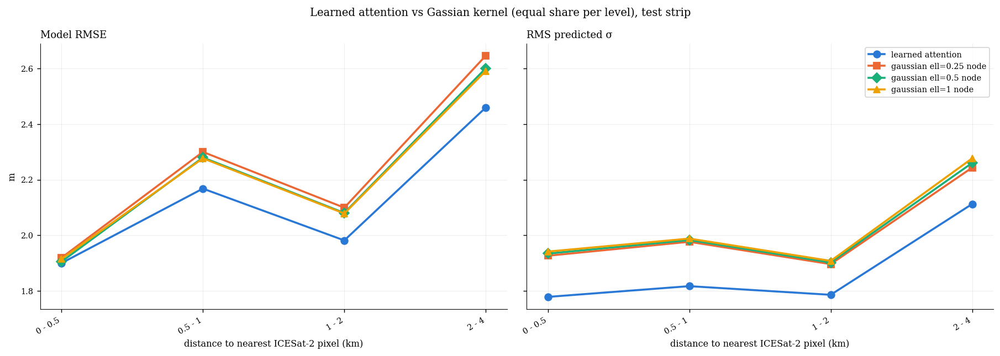

check: trained attention before vs after the swaps, max |difference| 4.24e-04 m (should be 0)

Learned attention vs Bilinear interpolation
357,953 off-track test pixels | uncorrected DSM RMSE 6.475 m
                          RMSE     MAE    bias   RMS σ  cover95     NLL  vs learned
learned attention        2.087   1.213  +0.095   1.847    0.947   0.718      +0.000
bilinear                 2.178   1.262  +0.216   1.987    0.942   0.763      +0.091

 ep  ICESat px      learned attention               bilinear
  0        520                  1.289                  1.345
  1        370                  2.395                  2.531
  2        436                  2.447                  2.515


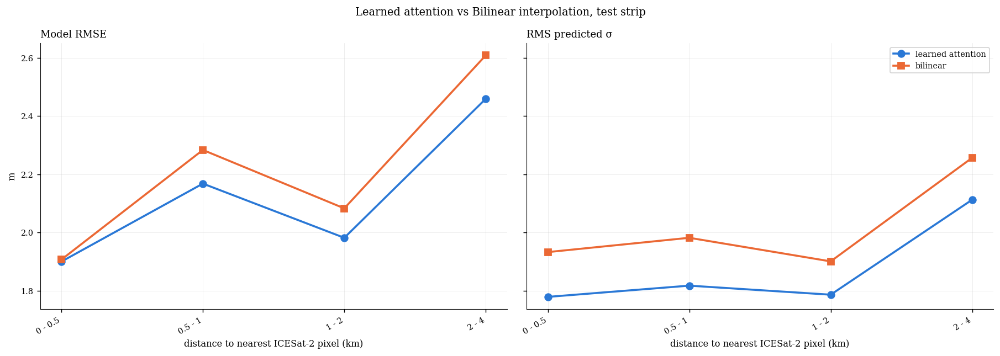

In [ ]:
# ------- learned graph attention vs fixed interpolation of node weights ---------
# learned: trained graph attention
# bilinear: classic bilinear weights from pixels position
# gaussian: exp(-d^2 / (2 * ell^2)), d in node spacings of that level

from contextlib import contextmanager
import numpy as np
import matplotlib.pyplot as plt
from affine import Affine
from scipy.ndimage import distance_transform_edt

C_SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100")  # learned first, then the fixed variants


def _level_geometry(pix_xy, L):
  """The 4 nodes around each pixel on one level (same as the trained read)"""
  gx = pix_xy[:, 0] / L['rx'] - 0.5
  gy = pix_xy[:, 1] / L['ry'] - 0.5
  x0, y0 = gx.floor().long(), gy.floor().long()
  xs = torch.stack([x0, x0 + 1, x0, x0 + 1], -1)
  ys = torch.stack([y0, y0, y0 + 1, y0 + 1], -1)
  inb = (xs >= 0) & (xs < L['Wg']) & (ys >=0) & (ys < L['Hg'])
  idx = ys.clamp(0, L['Hg'] - 1) * L['Wg'] + xs.clamp(0, L['Wg'] - 1)
  cnt = L['count'][idx]
  valid = inb & (cnt > 0)
  dx = (gx[:, None] - xs.float()).float()
  dy = (gy[:, None] - ys.float()).float()
  return idx, valid, dx, dy, cnt


def fixed_forward(kind, ell=0.5):
  """replacement for GridDiffuser.forward: same inputs and outputs, fixed weights instead of attention"""
  assert kind in ("bilinear", "gaussian")

  def forward(q_feat, pix_xy, levels):
    alphas, has, ws, logcs, dists, masks = [], [], [], [], [], []
    for L in levels:
      idx, valid, dx, dy, cnt = _level_geometry(pix_xy, L)
      if kind == "bilinear":
        k = (1 - dx.abs()).clamp(min=0) * (1 - dy.abs()).clamp(min=0)
      else:
        k = torch.exp(-(dx ** 2 + dy ** 2) / (2 * ell ** 2))
      k = k * valid
      ksum = k.sum(-1, keepdim=True)
      alphas.append(k / ksum.clamp_min(1e-12))
      has.append(ksum.squeeze(-1) > 0)
      masks.append(valid)
      ws.append(L['w'][idx]); logcs.append(torch.log1p(cnt))
      dists.append((dx ** 2 + dy ** 2).sqrt() * L['res_km'])

    A = torch.stack(alphas, 1)                                         # [N, levels, 4]
    H = torch.stack(has, -1)                                            # [N, levels]
    A = A * (H / H.sum(-1, keepdim=True).clamp_min(1)).unsqueeze(-1)    # equal share per level with data
    alpha = A.reshape(A.shape[0], -1)                                   # [N, 12]
    M = torch.cat(masks, -1)
    dW = (alpha.unsqueeze(-1) * torch.cat(ws, 1)).sum(1)
    # support features for the variance head, computed as in the trained read
    support = (alpha * torch.cat(logcs, -1)).sum(-1)
    dmin = torch.cat(dists, -1).masked_fill(~M, 1e3).amin(-1).clamp(max=100.0)
    aux = torch.stack([support, torch.log1p(dmin), M.any(-1).float()], -1)
    return dW, aux
  return forward


@contextmanager
def fixed_blend(model, kind, ell=0.5):
  """Change the blending within the block"""
  gat = model.grid_gat
  gat.forward = fixed_forward(kind, ell)                               # instance attribute shadows the class method
  try:
    yield
  finally:
    del gat.forward                                                    # change back to trained attention


@torch.no_grad()
def predict_blend(model, e, kind=None, ell=0.5):
  """mu, logvar [H, W] with the episode track; kind=None: trained attention"""
  def run():
    with amp_ctx():
      mu, lv = model(e["x"], e["obs_dh"], e["obs_mask"],
                     origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
    return mu[0, 0].float().cpu().numpy(), lv[0, 0].float().cpu().numpy()
  if kind is None:
    return run()
  with fixed_blend(model, kind, ell):
    return run()

def _compare(model, episodes, variants, title, dist_edges_km=(0, 0.5, 1, 2, 4, 8, 16, 32, np.inf)):
  """variants: {name: (kind, ell)}, first entry = trained attention (kind None)"""
  model.eval()
  names = list(variants)
  e0 = episodes[0]
  ref0 = predict_blend(model, e0)[0]
  pool = {n: dict(err=[], lv=[]) for n in names}
  tgt_all, dist_all, per_ep = [], [], []
  for i, e in enumerate(episodes):
    tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
    obs = obs.astype(bool)
    sel = val.astype(bool) & ~obs
    dist = distance_transform_edt(~obs) * PIXEL_M / 1000 if obs.any() else np.full(obs.shape, np.inf)
    row = dict(ep=i, icesat_px=int(obs.sum()))
    for n in names:
      kind, ell = variants[n]
      mu, lv = predict_blend(model, e, kind, ell)
      err, lv_sel = (mu - tgt)[sel], lv[sel]
      assert err.shape == lv_sel.shape
      pool[n]["err"].append(err); pool[n]["lv"].append(lv_sel)
      row[n] = np.sqrt(np.mean(err ** 2))
    tgt_all.append(tgt[sel]); dist_all.append(dist[sel]); per_ep.append(row)

  back = np.abs(predict_blend(model, e0)[0] - ref0).max()            # attention restored after swaps check
  print(f"check: trained attention before vs after the swaps, max |difference| {back:.2e} m (should be 0)")

  tgt_all, dist_all = np.concatenate(tgt_all), np.concatenate(dist_all)
  E = {n: np.concatenate(pool[n]["err"]) for n in names}
  LV = {n: np.concatenate(pool[n]["lv"]) for n in names}
  M = {n: _met(E[n], LV[n]) for n in names}

  ref = names[0]
  print(f"\n{title}\n{len(tgt_all):,} off-track test pixels | uncorrected DSM RMSE {np.sqrt(np.mean(tgt_all ** 2)):.3f} m")
  print(f"{'':22s} {'RMSE':>7s} {'MAE':>7s} {'bias':>7s} {'RMS σ':>7s} {'cover95':>8s} {'NLL':>7s} {'vs learned':>11s}")
  for n in names:
    m = M[n]
    print(f"{n:22s} {m['rmse']:7.3f} {m['mae']:7.3f} {m['bias']:+7.3f} {m['rms_sigma']:7.3f} "
          f"{m['cover95']:8.3f} {m['nll']:7.3f} {m['rmse'] - M[ref]['rmse']:+11.3f}")
  print(f"\n{'ep':>3s} {'ICESat px':>10s} " + " ".join(f"{n:>22s}" for n in names))
  for r in per_ep:
    print(f"{r['ep']:3d} {r['icesat_px']:10,d} " + " ".join(f"{r[n]:22.3f}" for n in names))

  edges = np.asarray(dist_edges_km, float)
  b = np.digitize(dist_all, edges) - 1
  labels, curves, sig = [], {n: [] for n in names}, {n: [] for n in names}
  for j in range(len(edges) - 1):
    m = b == j
    if m.sum() < 200:
      continue
    labels.append(f"{edges[j]:g} - {edges[j + 1]:g}")
    for n in names:
      curves[n].append(np.sqrt(np.mean(E[n][m] ** 2)))
      sig[n].append(np.sqrt(np.mean(np.exp(LV[n][m]))))
  pos = np.arange(len(labels))
  fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
  for n, col, mk in zip(names, C_SERIES, ("o", "s", "D", "^")):
    a1.plot(pos, curves[n], color=col, marker=mk, ms=7, lw=2, label=n)
    a2.plot(pos, sig[n], color=col, marker=mk, ms=7, lw=2, label=n)
  a1.set_title("Model RMSE"); a2.set_title("RMS predicted σ"); a1.set_ylabel("m")
  for ax in (a1, a2):
    ax.set_xticks(pos); ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_xlabel("distance to nearest ICESat-2 pixel (km)"); ax.grid(alpha=0.3)
  ax.legend(fontsize=8)
  fig.suptitle(f"{title}, test strip")
  plt.tight_layout(); plt.show()
  return M, per_ep


def gaussian_ablation(model, episodes, ells=(0.25, 0.5, 1.0)):
  variants = {"learned attention": (None, None)}
  variants.update({f"gaussian ell={ell:g} node" : ("gaussian", ell) for ell in ells})
  return _compare(model, episodes, variants, "Learned attention vs Gassian kernel (equal share per level)")

def bilinear_ablation(model, episodes):
  variants = {"learned attention": (None, None), "bilinear": ("bilinear", None)}
  return _compare(model, episodes, variants, "Learned attention vs Bilinear interpolation")

# --- map ---
def show_blend_errors(model, e, kind=None, ell=0.5, err_thresh_m=2.0, max_dots=30000, seed=0):
  mu, _ = predict_blend(model, e, kind, ell)
  tgt, val, obs = (e[k][0, 0].cpu().numpy() for k in ("target", "valid", "obs_mask"))
  obs = obs.astype(bool)
  sel = val.astype(bool) & ~obs
  oy, ox = e["origin"]
  h, w = mu.shape
  dsm = RAW_DSM[oy:oy + h, ox:ox + w]
  dtm_hat = np.where(np.isfinite(dsm), dsm + mu, np.nan)
  err = np.where(sel, mu - tgt, np.nan)
  T = DSM_PROFILE["transform"] * Affine.translation(ox, oy)
  to_xy = lambda r, c: (T.c + (c + 0.5) * T.a, T.f + (r + 0.5) * T.e)
  rng = np.random.default_rng(seed)

  def draw(ax):
    r, c = np.nonzero(obs)
    ax.scatter(*to_xy(r, c), s=0.2, color="black", label="ICESat pixels")
    for mask, col, lab in ((err > err_thresh_m, "#eb6834", f"ground too high (> +{err_thresh_m:g} m)"),
                          (err < -err_thresh_m, "#2a78d6", f"ground too low (< −{err_thresh_m:g} m)")):
      r, c = np.nonzero(mask)
      if len(r) > max_dots:
          k = rng.choice(len(r), max_dots, replace=False); r, c = r[k], c[k]
      ax.scatter(*to_xy(r, c), s=1.0, color=col, label=lab)
    ax.legend(loc="upper right", markerscale=8, fontsize=8, framealpha=0.9)

  name = "learned attention" if kind is None else ("bilinear" if kind == "bilinear" else f"gaussian ℓ={ell:g}")
  print(f"{name}: |error| > {err_thresh_m:g} m at {np.mean(np.abs(err[sel]) > err_thresh_m):.1%} of off-track pixels")
  show_map(dtm_hat, T, DSM_PROFILE["crs"], title=f"Predicted DTM, {name}", cmap="gray", cbar_label="m", extra=draw)


M_GAUSS, PER_EP_GAUSS = gaussian_ablation(model, TEST_SET[1:])
M_BILIN, PER_EP_BILIN = bilinear_ablation(model, TEST_SET[1:])




learned attention: |error| > 2 m at 24.2% of off-track pixels


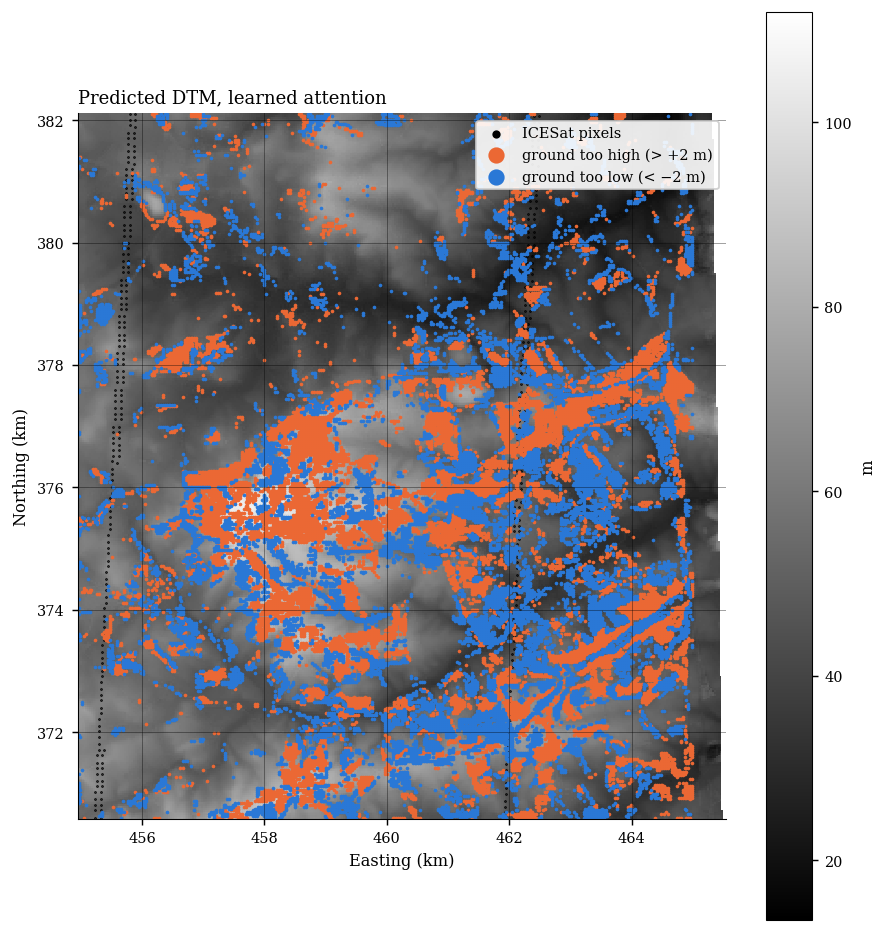

bilinear: |error| > 2 m at 24.8% of off-track pixels


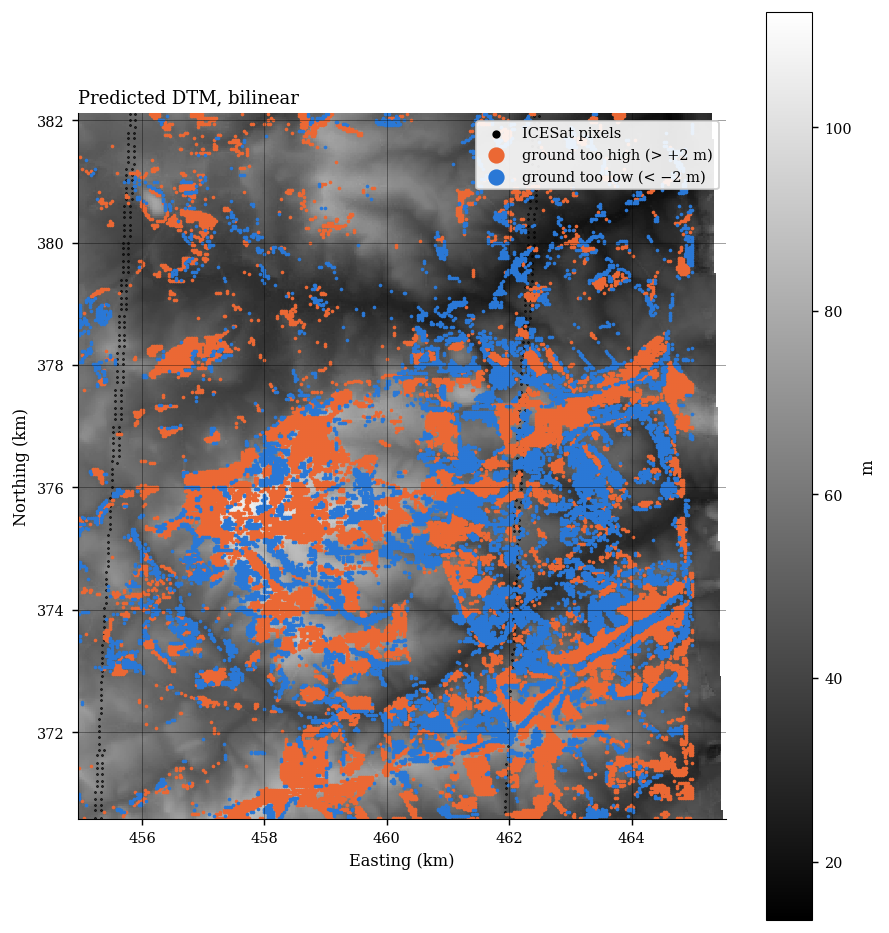

gaussian ℓ=0.5: |error| > 2 m at 24.8% of off-track pixels


/tmp/ipykernel_13121/831069152.py:102: UserWarning: Glyph 8467 (\N{SCRIPT SMALL L}) missing from font(s) DejaVu Serif.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 8467 (\N{SCRIPT SMALL L}) missing from font(s) DejaVu Serif.
  fig.canvas.print_figure(bytes_io, **kw)


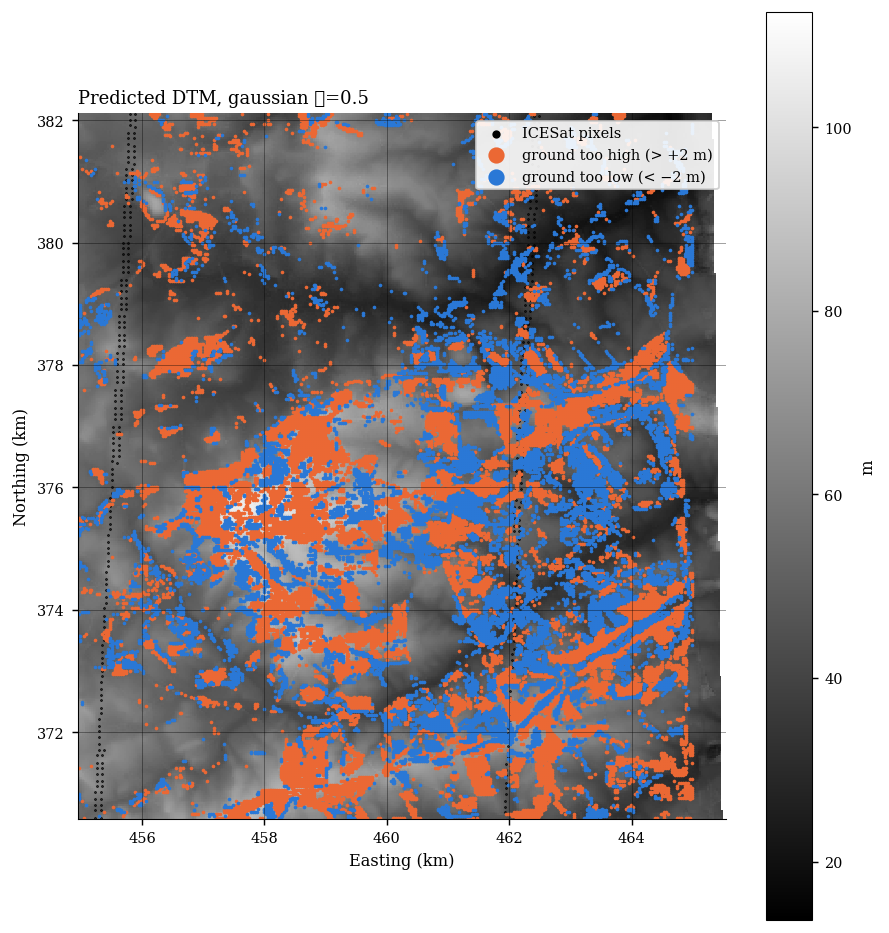

In [ ]:
show_blend_errors(model, TEST_SET[2])                        # learned attention
show_blend_errors(model, TEST_SET[2], "bilinear")
show_blend_errors(model, TEST_SET[2], "gaussian", ell=0.5)

### Note all figures past here are used in the write-up. except for the error breakdown of Site A (pre-training)

### test for lambda optimization and overfitting

In [ ]:
from scipy.ndimage import distance_transform_edt
from contextlib import contextmanager

MIN_ICESAT_PX = 200
TEST_NOISE_M = 1.0
REDRAW_SEED = 77
MAX_TRIES = 100


def ensure_icesat(episodes, min_px=MIN_ICESAT_PX, noise_m=TEST_NOISE_M, seed=REDRAW_SEED, max_tries=MAX_TRIES):
  gen = torch.Generator().manual_seed(seed)
  out = []
  print(f"{'block':>5s} {'ICESat px before':>17s} {'after':>7s} {'of which inside block':>22s} {'tries':>6s}")
  for i, e in enumerate(episodes):
    n_before = int(e["obs_mask"].sum())
    if n_before >= min_px:                                              # 1a
      out.append(e)
      print(f"{i:5d} {n_before:17,d} {'kept':>7s}")
      continue

    val = e["valid"][0, 0].bool()
    tgt = e["target"][0, 0]
    ch, cw = val.shape
    for t in range(1, max_tries + 1):                                   # 1b
      tracks = simulate_icesat_mask(ch, cw, pixel_m=PIXEL_M, generator=gen, device=val.device)
      obs = tracks & val
      if int(obs.sum()) >= min_px:
        break
    else:
      raise RuntimeError(f"block {i}: fewer than {min_px} ICESat px after {max_tries} draws; lower MIN_ICESAT_PX")

    noise = (torch.randn(ch, cw, generator=gen) * noise_m).to(tgt.device)   # 1c
    e2 = dict(e)                                                        # 1d (shallow copy)
    e2["obs_mask"] = obs[None, None]
    e2["obs_dh"] = (tgt + noise)[None, None]
    e2["tracks_redrawn"] = True
    inside = int((obs & e["score_mask"][0, 0].bool()).sum()) if "score_mask" in e else -1
    print(f"{i:5d} {n_before:17,d} {int(obs.sum()):7,d} {inside:22,d} {t:6d}")
    out.append(e2)
  return out

TEST_SET_R = ensure_icesat(TEST_SET)

block  ICESat px before   after  of which inside block  tries
    0                 0     664                    509      1
    1               520    kept
    2               370    kept
    3               436    kept


lambda sweep on all levels | trained lambda [0.884 0.917 1.351] | 251,136 scored px
 lambda x    RMSE    bias  cover95     NLL   RMSE by distance:    0–0.5 km    0.5–1 km      1–2 km    2–inf km
    empty   5.092  +2.249    0.972   0.988                           4.687       4.805       4.740       6.733
     0.25   2.161  +0.134    0.946   0.784                           1.948       2.204       2.021       2.699
        1   2.145  +0.130    0.949   0.772                           1.932       2.188       2.001       2.691
        4   2.156  +0.132    0.949   0.780                           1.942       2.195       2.010       2.713
       16   2.193  +0.154    0.946   0.801                           1.975       2.221       2.047       2.768
       64   2.280  +0.205    0.940   0.831                           2.054       2.288       2.132       2.896
      256   2.531  +0.309    0.915   0.952                           2.291       2.499       2.365       3.253

lowest RMSE at lambda x 1: 

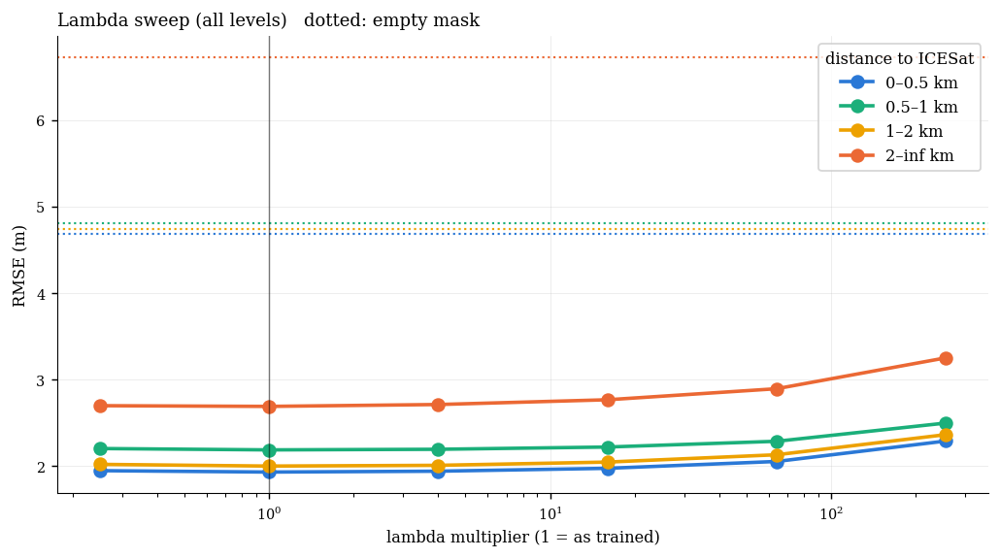

lambda sweep on levels [0] | trained lambda [0.884 0.917 1.351] | 251,136 scored px
 lambda x    RMSE    bias  cover95     NLL   RMSE by distance:    0–0.5 km    0.5–1 km      1–2 km    2–inf km
    empty   5.092  +2.249    0.972   0.988                           4.687       4.805       4.740       6.733
     0.25   2.145  +0.130    0.949   0.773                           1.930       2.188       2.001       2.691
        1   2.145  +0.130    0.949   0.772                           1.932       2.188       2.001       2.691
        4   2.146  +0.130    0.949   0.772                           1.934       2.188       2.001       2.691
       16   2.146  +0.130    0.949   0.772                           1.936       2.189       2.001       2.691
       64   2.148  +0.131    0.949   0.773                           1.941       2.190       2.001       2.691
      256   2.150  +0.136    0.949   0.775                           1.950       2.193       2.001       2.691

lowest RMSE at lambda x 0.2

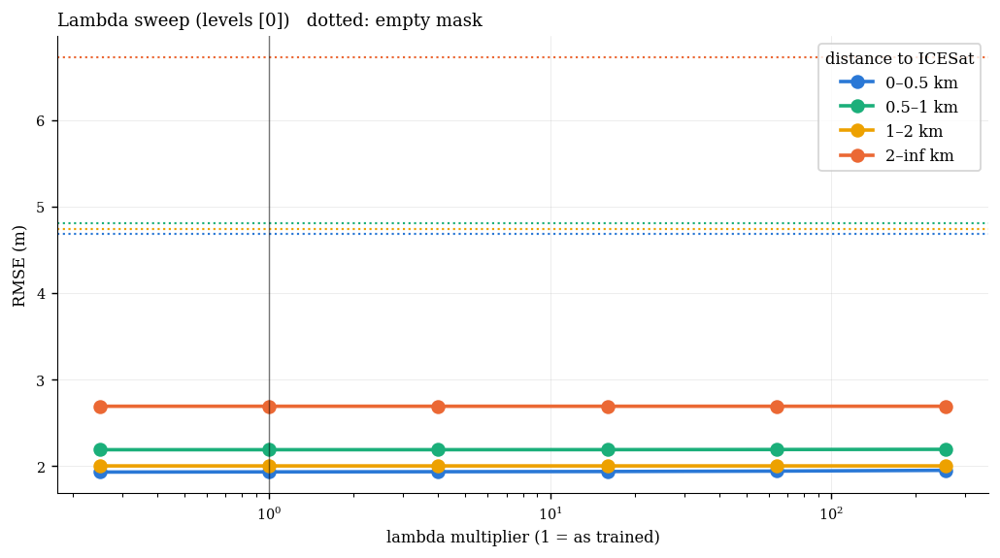

In [ ]:
SCALES = (0.25, 1, 4, 16, 64, 256)
DIST_EDGES_KM = (0, 0.5, 1, 2, np.inf)


@contextmanager
def scaled_lambda(model, scale, levels=None):
  orig = model.log_lam.data.clone()
  idx = range(len(orig)) if levels is None else levels
  try:
    with torch.no_grad():
      for li in idx:
        model.log_lam.data[li] = orig[li] + math.log(scale)
    yield
  finally:
    model.log_lam.data.copy_(orig)                                      # trained lambda back


def lambda_sweep(model, episodes, scales=SCALES, levels=None, dist_edges=DIST_EDGES_KM, title=""):
  assert 1 in scales, "keep 1 (= the trained lambda) in the scales: it is the reference"
  model.eval()
  prep = []
  for e in episodes:
    tgt = e["target"][0, 0].cpu().numpy()
    val = e["valid"][0, 0].cpu().numpy().astype(bool)
    obs = e["obs_mask"][0, 0].cpu().numpy().astype(bool)
    sel = val & ~obs
    if "score_mask" in e:
      sel &= e["score_mask"][0, 0].cpu().numpy().astype(bool)
    dist = distance_transform_edt(~obs) * PIXEL_M / 1000 if obs.any() else np.full(obs.shape, np.inf)
    prep.append((e, tgt, sel, dist[sel]))
  dist_all = np.concatenate([p[3] for p in prep])
  b = np.digitize(dist_all, np.asarray(dist_edges)[1:-1])
  n_bins = len(dist_edges) - 1
  labels = [f"{dist_edges[j]:g}–{dist_edges[j + 1]:g} km" for j in range(n_bins)]

  def collect(empty):
    err, lv = [], []
    for e, tgt, sel, _ in prep:
      mu, l = run_episode(model, e, empty=empty)
      err.append((mu - tgt)[sel]); lv.append(l[sel])
    err, lv = np.concatenate(err), np.concatenate(lv)
    s2 = np.exp(lv)
    return dict(rmse=np.sqrt(np.mean(err ** 2)), bias=err.mean(),
                cover95=np.mean(np.abs(err) <= 1.96 * np.sqrt(s2)), nll=np.mean(0.5 * (lv + err ** 2 / s2)),
                bins=[np.sqrt(np.mean(err[b == j] ** 2)) if (b == j).sum() >= 200 else np.nan
                      for j in range(n_bins)])

  rows = {"empty": collect(True)}
  for s in scales:
    with scaled_lambda(model, s, levels):
      rows[s] = collect(False)

  lam0 = model.log_lam.exp().detach().cpu().numpy()
  which = "all levels" if levels is None else f"levels {list(levels)}"
  print(f"lambda sweep on {which} | trained lambda {np.round(lam0, 3)} | {len(dist_all):,} scored px")
  head = " ".join(f"{l:>11s}" for l in labels)
  print(f"{'lambda x':>9s} {'RMSE':>7s} {'bias':>7s} {'cover95':>8s} {'NLL':>7s}   RMSE by distance: {head}")
  for k, r in rows.items():
    name = "empty" if k == "empty" else f"{k:g}"
    bins = " ".join(f"{v:11.3f}" for v in r["bins"])
    print(f"{name:>9s} {r['rmse']:7.3f} {r['bias']:+7.3f} {r['cover95']:8.3f} {r['nll']:7.3f}   {' ' * 18}{bins}")

  best = min(scales, key=lambda s: rows[s]["rmse"])
  gain = rows[1]["rmse"] - rows[best]["rmse"]
  print(f"\nlowest RMSE at lambda x {best:g}: {rows[best]['rmse']:.3f} m vs {rows[1]['rmse']:.3f} m as trained "
        f"({gain:+.3f} m)")
  if best > 1 and gain > 0.05:
    print("-> more shrinkage helps: the node fits over-adapt (report as a limitation: lambda under-regularised)")
  elif best < 1 and gain > 0.05:
    print("-> less shrinkage helps: the nodes are over-regularised")
  else:
    print("-> the trained lambda is (close to) the best: over-adaptation is not what limits the model")

  fig, ax = plt.subplots(figsize=(8, 4.5))
  cols = ["#2a78d6", "#1baf7a", "#eda100", "#eb6834", "#8a8a85"]
  for j in range(n_bins):
    ys = [rows[s]["bins"][j] for s in scales]
    ax.plot(scales, ys, color=cols[j % len(cols)], marker="o", ms=7, lw=2, label=labels[j])
    ax.axhline(rows["empty"]["bins"][j], color=cols[j % len(cols)], ls=":", lw=1.2)
  ax.axvline(1, color="black", lw=0.8, alpha=0.5)
  ax.set_xscale("log"); ax.set_xlabel("lambda multiplier (1 = as trained)"); ax.set_ylabel("RMSE (m)")
  ax.set_title(f"Lambda sweep ({which}){' - ' + title if title else ''}   dotted: empty mask")
  ax.grid(alpha=0.3); ax.legend(title="distance to ICESat", fontsize=9)
  plt.tight_layout(); plt.show()
  return rows


SWEEP_ALL = lambda_sweep(model, TEST_SET_R[1:])                  # lambda x scale on all three levels
SWEEP_1KM = lambda_sweep(model, TEST_SET_R[1:], levels=[0])      # only the 1 km level (the sparsest nodes)

##Test on real ICESat-2 pixels

### functions and main directory



In [ ]:
# ========= new paths for testing folder ============
V3_DIR = "/content/drive/MyDrive/dsm_dtm_calibration_TTT/icesat testing"
V3_NASA_ATL08 = f"{V3_DIR}/nasa/atl08"
V3_DIGIMAP = f"{V3_DIR}/digimap"
V3_GEE = f"{V3_DIR}/gee"
V3_GRID_DIR = f"{V3_DIR}/grid"
if not os.path.exists(V3_GRID_DIR):
  os.makedirs(V3_GRID_DIR)

In [ ]:
# ==== vertical datum shift pyproj files ===
import os, ssl, shutil, urllib.request
import numpy as np, rasterio, pyproj, certifi
from pyproj import CRS, Transformer


GRIDS = ("uk_os_OSGM15_GB.tif",
         "us_nga_egm08_25.tif")
ctx = ssl.create_default_context(cafile=certifi.where())
for f in GRIDS:
  path = os.path.join(V3_GRID_DIR, f)
  if os.path.exists(path) and os.path.getsize(path) > 0:
    print(f"found {f} ({os.path.getsize(path) / 1e6:.1f} MB)")
    continue
  print(f"downloading {f} ...")
  tmp = path + ".part"
  try:
    with urllib.request.urlopen(f"https://cdn.proj.org/{f}", context=ctx) as r, open(tmp, "wb") as out:
      shutil.copyfileobj(r, out)
  except Exception as err:                                   # fall back to the system downloader
    print(f"  python download failed ({err}); trying wget")
    os.system(f"wget -q -O {tmp} https://cdn.proj.org/{f}")
  assert os.path.exists(tmp) and os.path.getsize(tmp) > 0, f"could not download {f}: download it in a browser from https://cdn.proj.org/{f} and put it in {GRID_DIR}"
  os.replace(tmp, path)
  print(f"saved {path} ({os.path.getsize(path) / 1e6:.1f} MB")

pyproj.datadir.append_data_dir(V3_GRID_DIR)
pyproj.network.set_network_enabled(False)

found uk_os_OSGM15_GB.tif (1.5 MB)
found us_nga_egm08_25.tif (80.6 MB)


In [ ]:
# preprocessing of digimap for merging + aggregation
import glob
from rasterio.merge import merge
import numpy as np
import rasterio
from rasterio.warp import reproject, Resampling
from osgeo import gdal

def digimap_merge(input_folder, output_filepath):
  print("=" * 50)
  print("STARTING TILE MERGE (VRT)")
  print("=" * 50)

  raw_tiles = [f for f in glob.glob(f"{input_folder}/*.tif")
                if not f.endswith("_merge.tif") and not f.endswith("_average.tif")]
  if not raw_tiles:
      print(f"ERROR: No valid raw tiles found in {input_folder}")
      return None

  print(f"Building virtual mosaic from {len(raw_tiles)} tiles...")

  safe_nodata = -9999.0
  opts = gdal.BuildVRTOptions(
      outputSRS="EPSG:27700",   # same BNG forcing as before
      VRTNodata=safe_nodata,
      resampleAlg="nearest",
  )
  vrt = gdal.BuildVRT(output_filepath, raw_tiles, options=opts)
  vrt.FlushCache()
  vrt = None   # closes and writes the .vrt

  # Quick verification on a decimated read (cheap, doesn't load full 1 m grid)
  with rasterio.open(output_filepath) as src:
      print("\nMERGE COMPLETE. VERIFICATION:")
      print(f"  Shape:       {src.width} x {src.height} pixels")
      f = 50
      preview = src.read(1, out_shape=(src.height // f, src.width // f),
                          masked=True)
      valid = preview.compressed()
      valid = valid[~np.isnan(valid)]
      if valid.size:
          print(f"  Min Elev:    {valid.min():.2f}m (approx)")
          print(f"  Max Elev:    {valid.max():.2f}m (approx)")
          print(f"  Valid frac:  {valid.size / preview.size * 100:.1f}% (approx)")
      else:
          print("  CRITICAL ERROR: Mosaic appears blank!")
  print("=" * 50)
  return output_filepath


def align_digi_to_copernicus(
    digimap_filepath,
    copernicus_target_path,
    output_resampled_path
):
  print("=" * 60)
  print("STARTING DIGIMAP TO COPERNICUS ALIGNMENT & AGGREGATION")
  print("=" * 60)

  # inspection of target parameters
  with rasterio.open(copernicus_target_path) as src_cop:
      target_profile = src_cop.profile.copy()
      copernicus_crs = src_cop.crs
      copernicus_transform = src_cop.transform
      copernicus_width = src_cop.width
      copernicus_height = src_cop.height
      copernicus_bounds = src_cop.bounds
      copernicus_nodata = src_cop.nodata if src_cop.nodata is not None else np.nan

  print(f"[TARGET COPERNICUS]")
  print(f"  Shape:       {copernicus_width} x {copernicus_height} pixels")
  print(f"  CRS:         {copernicus_crs}")
  print(f"  Bounds:      {copernicus_bounds}")
  print(f"  NoData Val:  {copernicus_nodata}")

  # inspection of source parameters
  with rasterio.open(digimap_filepath) as src_digi:
      digimap_crs = src_digi.crs
      digimap_bounds = src_digi.bounds
      digimap_nodata = src_digi.nodata if src_digi.nodata is not None else np.nan

      print(f"\n[SOURCE DIGIMAP]")
      print(f"  Shape:       {src_digi.width} x {src_digi.height} pixels")
      print(f"  CRS:         {digimap_crs}")
      print(f"  Bounds:      {digimap_bounds}")
      print(f"  NoData Val:  {digimap_nodata}")

      # initialization with explicit array
      resampled = np.full(
          shape=(copernicus_height, copernicus_width),
          fill_value=copernicus_nodata,
          dtype=np.float32
      )

      # Reprojection and resampling
      print(f"\nResampling {digimap_filepath} (1m) -> Copernicus (30m)...")
      reproject(
          source=rasterio.band(src_digi, 1),
          destination=resampled,
          src_transform=src_digi.transform,
          src_crs=digimap_crs,
          src_nodata=digimap_nodata,
          dst_transform=copernicus_transform,
          dst_crs=copernicus_crs,
          dst_nodata=copernicus_nodata,
          resampling=Resampling.average
      )

  target_profile.update({
      'dtype': rasterio.float32,
      'count': 1,
      'nodata': copernicus_nodata,
      'compress': 'lzw'
  })

  # Save resampled raster
  with rasterio.open(output_resampled_path, 'w', **target_profile) as dst:
      dst.write(resampled, 1)

  # Debug diagnostics
  total_pixels = resampled.size
  nan_pixels = np.isnan(resampled).sum() if np.isnan(copernicus_nodata) else (resampled == copernicus_nodata).sum()
  valid_data = resampled[~np.isnan(resampled)] if np.isnan(copernicus_nodata) else resampled[resampled != copernicus_nodata]

  print("\n" + "-" * 40)
  print("RESAMPLING DIAGNOSTIC RESULTS:")
  print("-" * 40)
  print(f"Output File:       {output_resampled_path}")
  print(f"Total Grid Cells:  {total_pixels} ({resampled.shape[0]}x{resampled.shape[1]})")
  print(f"NoData/NaN Cells:  {nan_pixels} ({nan_pixels / total_pixels * 100:.2f}%)")
  print(f"Valid Data Cells:  {len(valid_data)} ({len(valid_data) / total_pixels * 100:.2f}%)")

  if len(valid_data) > 0:
      print(f"Elevation Min:     {valid_data.min():.2f} meters")
      print(f"Elevation Max:     {valid_data.max():.2f} meters")
      print(f"Elevation Mean:    {valid_data.mean():.2f} meters")
  else:
      print("CRITICAL WARNING: Output raster contains NO valid elevation data!")
  print("=" * 60 + "\n")


def align_gee_features_to_master(gee_filepath, master_filepath, output_filepath):
  print("=" * 60)
  print("SNAPPING GEE FEATURES TO MASTER GRID")
  print("=" * 60)

  # 1. Read Master Parameters (The Fused DSM)
  with rasterio.open(master_filepath) as master:
      master_meta = master.profile.copy()
      master_transform = master.transform
      master_crs = master.crs
      master_width = master.width
      master_height = master.height

  # 2. Read GEE Features
  with rasterio.open(gee_filepath) as gee:
      gee_crs = gee.crs
      gee_transform = gee.transform
      gee_nodata = gee.nodata if gee.nodata is not None else np.nan
      num_bands = gee.count

      # Prepare an empty array to hold all the bands (Shape: Bands, Height, Width)
      resampled_stack = np.empty((num_bands, master_height, master_width), dtype=np.float32)

      print(f"Resampling {num_bands} GEE feature bands to match master grid...")

      # 3. Loop through each band and reproject it to the master grid
      for i in range(1, num_bands + 1):
          # Using bilinear for continuous variables (Slope, EVI, Height, etc.)
          reproject(
              source=rasterio.band(gee, i),
              destination=resampled_stack[i-1],
              src_transform=gee_transform,
              src_crs=gee_crs,
              src_nodata=gee_nodata,
              dst_transform=master_transform,
              dst_crs=master_crs,
              dst_nodata=np.nan, # Force NaNs for empty space
              resampling=Resampling.bilinear
          )
          print(f" - Band {i} aligned.")

  # 4. Update metadata for the new multi-band file
  master_meta.update({
      'dtype': rasterio.float32,
      'count': num_bands,       # Keep the 8 bands
      'nodata': np.nan,         # Use standard NaN
      'compress': 'lzw'
  })

  # 5. Save the aligned feature stack
  with rasterio.open(output_filepath, 'w', **master_meta) as dst:
      dst.write(resampled_stack)

  print(f"\nSUCCESS: GEE Features aligned. New shape: {resampled_stack.shape}")
  print("=" * 60)


In [ ]:
# vertical datum shift
to_odn = Transformer.from_crs("EPSG:4937", "EPSG:4258+5701", always_xy=True, allow_ballpark=False)
to_egm = Transformer.from_crs("EPSG:4979", "EPSG:4326+3855", always_xy=True, allow_ballpark=False)

def shift_to_EGM2008(src_dtm, dst_dtm):
  with rasterio.open(src_dtm) as src:
    dtm = src.read(1).astype(np.float64)
    prof, T, crs, nodata = src.profile, src.transform, CRS.from_user_input(src.crs), src.nodata
  ok = np.isfinite(dtm) if nodata is None or np.isnan(nodata) else (np.isfinite(dtm) & (dtm != nodata))

  r, c = np.nonzero(ok)
  x = T.c + (c + 0.5) * T.a + (r + 0.5) * T.b
  y = T.f + (c + 0.5) * T.d + (r + 0.5) * T.e
  if crs.is_geographic:
    lon, lat = x, y
  else:
    lon, lat = Transformer.from_crs(crs, "EPSG:4326", always_xy=True).transform(x, y)
  print(f"{len(lon):,} valid pixels | lon {lon.min():.3f} to {lon.max():.3f} | lat {lat.min():.3f} to {lat.max():.3f}")

  _, _, H_odn0 = to_odn.transform(lon, lat, np.zeros_like(lon), errcheck=True)
  _, _, H_egm0 = to_egm.transform(lon, lat, np.zeros_like(lon), errcheck=True)
  assert np.all(np.isfinite(H_odn0)) and np.all(np.isfinite(H_egm0)), "non-finite geoid heights"
  offset = H_egm0 - H_odn0

  out = np.full(dtm.shape, np.nan if nodata is None else nodata, np.float32)
  out[r, c] = (dtm[r, c] + offset).astype(np.float32)
  prof.update(dtype="float32", compress="deflate")
  with rasterio.open(dst_dtm, "w", **prof) as dst:
    dst.write(out, 1)
    dst.update_tags(VERTICAL_DATUM="EGM2008 height (EPSG:3855), converted from ODN (EPSG:5701) via OSGM15")
  print(f"offset (EGM2008 - ODN): min {offset.min():+.3f} | mean {offset.mean():+.3f} | max {offset.max():+.3f} m")
  print("saved", dst_dtm)

In [ ]:
import ee, re
from rasterio.warp import transform_bounds

def ee_name(s):
  """Make a string valid as an Earth Engine task description / file prefix."""
  return re.sub(r"[^A-Za-z0-9.,:;_-]", "_", s)[:100]

def download_dsm(bounds, tile, crs="EPSG:27700", project_name='capable-hangout-510214-k5'):
  ee.Authenticate()
  ee.Initialize(project=project_name)

  # boundary
  lon_min, lat_min, lon_max, lat_max = transform_bounds("EPSG:27700", "EPSG:4326", *bounds,
                                                      densify_pts=21)
  roi = ee.Geometry.BBox(lon_min, lat_min, lon_max, lat_max)

  # Copernicus GLO-30 INSAR
  copernicus_dsm = ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1") \
    .select('DEM') \
    .mosaic() \
    .clip(roi)

  print(f"Exporting Copernicus for tile {tile}, bounds={bounds}")
  task = ee.batch.Export.image.toDrive(
      image=copernicus_dsm,
      description=ee_name(f'Copernicus_GLO30_2024_{tile}'),
      folder=ee_name(f"Copernicus_tile_{tile}"),
      scale=30,
      region=roi,
      crs=crs,
      maxPixels=1e10
  )
  task.start()

def download_feat(bounds, tile, scale, crs="EPSG:27700", project_name='capable-hangout-510214-k5'):
  ee.Authenticate()
  ee.Initialize(project=project_name)

  TARGET_SCALE = 30
  lon_min, lat_min, lon_max, lat_max = transform_bounds("EPSG:27700", "EPSG:4326", *bounds,
                                                      densify_pts=21)
  roi = ee.Geometry.BBox(lon_min, lat_min, lon_max, lat_max)

  cop_col = (ee.ImageCollection("COPERNICUS/DEM/GLO30_2024_1")
            .filterBounds(roi)
            .select('DEM'))
  fused_dsm = (cop_col.mosaic().setDefaultProjection(crs='EPSG:27700')
            .reproject(crs='EPSG:27700', scale=TARGET_SCALE)
            .rename('Fused_DSM'))



  slope = ee.Terrain.slope(fused_dsm).rename('Slope')
  aspect = ee.Terrain.aspect(fused_dsm).rename('Aspect')

  weight = ee.Kernel.fixed(3, 3, [
                          [1, 1, 1],
                          [1, 0, 1],
                          [1, 1, 1]
                          ])
  focal_sum = fused_dsm.reduceNeighborhood(reducer=ee.Reducer.sum(), kernel=weight)
  focal_sum_sq = fused_dsm.pow(2).reduceNeighborhood(reducer=ee.Reducer.sum(), kernel=weight)

  tri = (focal_sum_sq
          .subtract(fused_dsm.multiply(focal_sum).multiply(2))
          .add(fused_dsm.pow(2).multiply(8))
          .sqrt()
          .rename('TRI'))

  canopy_height = ee.Image('users/nlang/ETH_GlobalCanopyHeight_2020_10m_v1').rename('Canopy_Height')

  # Note on LAI: I have left this as 'Lai' per your modification.
  lai = (ee.ImageCollection('MODIS/061/MCD15A3H')
          .filterDate('2021-01-01', '2021-12-31')
          .select('Lai')
          .median()
          .multiply(0.1)
          .rename('LAI'))

  def calculate_evi(image):
      evi = image.expression(
          '2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 10000))', {
              'NIR': image.select('B8'),
              'RED': image.select('B4'),
              'BLUE': image.select('B2')
          }).rename('EVI')
      return image.addBands(evi)

  evi = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
          .filterBounds(roi)
          .filterDate('2021-01-01', '2021-12-31')
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 70))
          .map(calculate_evi)
          .select('EVI')
          .median())

  building_height = ee.Image("JRC/GHSL/P2023A/GHS_BUILT_H/2018").select('built_height').rename('Building_Height')

  world_cover = ee.Image('ESA/WorldCover/v200/2021').select('Map')
  valid_land_mask = world_cover.neq(80).multiply(world_cover.neq(70))

  # THE FIX: Added .toFloat() to cast all bands to 32-bit float for GeoTIFF compatibility
  feature_stack = ee.Image.cat(
      [fused_dsm, slope, aspect, tri, canopy_height, lai, evi, building_height]
  ).updateMask(valid_land_mask).clip(roi).toFloat()

  print(f"Exporting to Google Drive to folder GEE_FEATURE_TILE_{tile}")
  task = ee.batch.Export.image.toDrive(
      image=feature_stack,
      description=ee_name(f'GEE_FEATURE_STACK_{tile}'),
      folder=ee_name(f'GEE_FEATURE_TILE_{tile}'),
      region=roi,
      scale=TARGET_SCALE,
      crs='EPSG:27700',
      maxPixels=1e13,
      fileFormat='GeoTIFF'
  )

  task.start()

  while task.active():
      print(f"Task status: {task.status()['state']}")
      time.sleep(30)

  print(f"Export finished with status: {task.status()['state']}")

  if task.status()['state'] == 'FAILED':
      print(f"\nFATAL ERROR DETAILS: {task.status()['error_message']}")


def _align(copernicus_dir,
          gee_directory,
          digimap_raw_folder,
          digimap_merge_file,
           digimap_align_file,
          gee_align_directory,
          tile):
  # merge and align digimap to copernicus scale
  print("Merging and aligning digimap tiles...")
  for dir in (digimap_merge_file, gee_align_directory):
    os.makedirs(os.path.dirname(dir), exist_ok=True)
  digimap_merge(digimap_raw_folder, digimap_merge_file)
  align_digi_to_copernicus(
      digimap_merge_file,
      copernicus_dir,
      digimap_align_file
  )
  align_gee_features_to_master(gee_directory, copernicus_dir, gee_align_directory)
  print("Finished.")



In [ ]:
# ===== NEW: inference with real ICESat-2 ATL08: checkpoint + DSM + features + ATL08 -> DTM, delta_h, sigma =====
# Uses from your notebook: ProbabilisticCalibrator, build_inputs (8-band GEE stack), standardize, amp_ctx, DEVICE
import glob, gc
import numpy as np
import rasterio
import h5py
import pyproj
import torch

BEAMS = ("gt1l", "gt1r", "gt2l", "gt2r", "gt3l", "gt3r")

def build_inputs(dsm, dsm_ok, feat, feat_ok):
  assert feat.shape[0] == 8, f"Expected length 8 got length {feat.shape[0]}"
  # radian-ize the aspect
  aspect = np.radians(feat[2])
  X = np.stack([dsm, feat[1], np.sin(aspect), np.cos(aspect), feat[3], feat[4], feat[5], feat[6], feat[7]]).astype(np.float32)
  X_ok = np.stack([dsm_ok, feat_ok[1], feat_ok[2], feat_ok[2], feat_ok[3], feat_ok[4], feat_ok[5], feat_ok[6], feat_ok[7]])
  return X, X_ok

def standardize(X, X_ok, means, stds):
  Xn = (X - np.asarray(means, np.float32)[:, None, None]) / np.asarray(stds, np.float32)[:, None, None]
  Xn[~X_ok] = 0.0
  return Xn.astype(np.float32)


def load_calibrator(ckpt_path):
  """Model with the checkpoint's own architecture and weights, plus its training statistics."""
  ck = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
  cfg = dict(ck["cfg"])
  cfg["grad_checkpoint"] = False                     # no gradients at inference
  model = ProbabilisticCalibrator(**cfg).to(DEVICE)
  model.load_state_dict(ck["model"])
  model.eval()
  stats = ck["stats"]
  print(f"loaded {ckpt_path} | step {ck['step'] + 1} | best val loss {ck['best']:.4f}")
  return model, stats, cfg


def read_raster(path, band=None):
  """(array float32, valid bool, profile); valid excludes nodata and NaN."""
  with rasterio.open(path) as src:
    arr = (src.read(band) if band is not None else src.read()).astype(np.float32)
    nodata, profile = src.nodata, src.profile
  ok = np.isfinite(arr)
  if nodata is not None and np.isfinite(nodata):
    ok &= arr != nodata
  return arr, ok, profile


def load_atl08(files, dsm_crs, dsm_geoid_epsg=3855, max_unc_m=5.0):
  """ATL08 100 m land segments -> x, y in the DSM's CRS and ground height in the DSM's geoid."""
  lon, lat, h = [], [], []
  for f in files:
    with h5py.File(f, "r") as h5:
      for beam in BEAMS:
        g = f"{beam}/land_segments"
        if g not in h5:
          continue
        hb = h5[f"{g}/terrain/h_te_best_fit"][:].astype(np.float64)
        unc = h5[f"{g}/terrain/h_te_uncertainty"][:].astype(np.float64)
        keep = np.isfinite(hb) & (hb < 1e30) & (unc < max_unc_m)     # fill value ~3.4e38
        lat.append(h5[f"{g}/latitude"][:][keep]); lon.append(h5[f"{g}/longitude"][:][keep])
        h.append(hb[keep])
  if not h:
    print("no ATL08 segments found")
    return np.zeros(0), np.zeros(0), np.zeros(0)
  lon, lat, h_ell = np.concatenate(lon), np.concatenate(lat), np.concatenate(h)
  pyproj.network.set_network_enabled(True)           # PROJ downloads the geoid grid when needed
  to_geoid = pyproj.Transformer.from_crs("EPSG:4979", f"EPSG:4326+{dsm_geoid_epsg}", always_xy=True)
  _, _, h_geo = to_geoid.transform(lon, lat, h_ell)
  shift = np.nanmean(h_ell - h_geo)
  assert np.isfinite(shift) and abs(shift) > 0.5, "ellipsoid -> geoid conversion did nothing (geoid grid missing)"
  x, y = pyproj.Transformer.from_crs("EPSG:4326", dsm_crs, always_xy=True).transform(lon, lat)
  print(f"{len(h_geo):,} ATL08 segments | ellipsoid -> geoid {shift:+.1f} m on average")
  return np.asarray(x), np.asarray(y), np.asarray(h_geo)


def rasterize_obs(x, y, h_ground, dsm, dsm_ok, transform, dh_range):
  """Points -> obs_dh [H, W] (mean ground - DSM per pixel) and obs_mask [H, W]; gross outliers dropped."""
  H, W = dsm.shape
  rows, cols = rasterio.transform.rowcol(transform, x, y)
  rows, cols, h = np.asarray(rows), np.asarray(cols), np.asarray(h_ground, np.float64)
  keep = (rows >= 0) & (rows < H) & (cols >= 0) & (cols < W) & np.isfinite(h)
  rows, cols, h = rows[keep], cols[keep], h[keep]
  keep = dsm_ok[rows, cols]
  rows, cols, h = rows[keep], cols[keep], h[keep]
  dh = h - dsm[rows, cols]
  keep = (dh >= dh_range[0]) & (dh <= dh_range[1])
  print(f"{len(dh):,} points on valid DSM pixels | {int((~keep).sum()):,} outside {dh_range} m dropped")
  rows, cols, dh = rows[keep], cols[keep], dh[keep]
  s, n = np.zeros((H, W)), np.zeros((H, W), np.int64)
  np.add.at(s, (rows, cols), dh)
  np.add.at(n, (rows, cols), 1)
  obs_mask = n > 0
  return np.where(obs_mask, s / np.maximum(n, 1), 0.0).astype(np.float32), obs_mask


@torch.no_grad()
def run_calibrator(model, X_norm, obs_dh, obs_mask, win_batch=256):
  """Pass 1: closed-form last-layer adaptation from the ICESat pixels. Pass 2: Hann-blended read
  over every pixel. Inputs stay on the CPU; windows go to the GPU in batches."""
  old = model.win_batch
  model.win_batch = win_batch
  try:
    with amp_ctx():
      mu, lv = model(torch.from_numpy(np.ascontiguousarray(X_norm))[None],
                      torch.from_numpy(obs_dh)[None, None],
                      torch.from_numpy(obs_mask)[None, None],
                      origin_yx=(0, 0), dsm_hw=X_norm.shape[1:])
  finally:
    model.win_batch = old
    gc.collect()
    if DEVICE == "cuda":
      torch.cuda.empty_cache()
  return mu[0, 0].float().cpu().numpy(), np.exp(0.5 * lv[0, 0].float().cpu().numpy())


def save_tif(path, arr, profile):
  p = profile.copy()
  p.update(driver="GTiff", dtype="float32", count=1, nodata=np.nan, compress="deflate")
  with rasterio.open(path, "w", **p) as dst:
    dst.write(arr.astype(np.float32), 1)


def calibrate(ckpt_path, feat_path, atl08_files, dsm_path=None, out_prefix=None, dsm_geoid_epsg=3855, points=None):
  """Whole pipeline for one area. feat_path: 8-band GEE stack (fused_dsm, slope, aspect, tri, canopy,
  lai, evi, building_height) on the DSM grid. dsm_path=None takes the DSM from band 0 of that stack.
  atl08_files: list of .h5 paths, or a glob pattern. Returns dict of arrays; writes GeoTIFFs if out_prefix."""

  model, S, cfg = load_calibrator(ckpt_path)

  feat, feat_ok, prof = read_raster(feat_path)
  assert feat.shape[0] == 8, f"expected 8 feature bands, got {feat.shape[0]}"
  if dsm_path is None:
    dsm, dsm_ok = feat[0], feat_ok[0]
  else:
    dsm, dsm_ok, p2 = read_raster(dsm_path, 1)
    assert dsm.shape == feat.shape[1:] and p2["transform"].almost_equals(prof["transform"]), \
        "DSM and features are on different grids"
  crs = rasterio.crs.CRS.from_user_input(prof["crs"])
  px = abs(prof["transform"].a)
  assert crs.is_projected, "rasters must be in a projected CRS (metres)"
  assert abs(px / cfg["pixel_m"] - 1) < 0.05, f"pixel {px:.2f} m, model trained at {cfg['pixel_m']:.2f} m"
  print(f"DSM {dsm.shape[0]} x {dsm.shape[1]} px at {px:.1f} m | {crs.to_string()}")

  X, X_ok = build_inputs(dsm, dsm_ok, feat, feat_ok)                  # same mapping as training
  stds = S.get("global_stds", S.get("global_std"))                     # either key name
  X_norm = standardize(X, X_ok, S["global_means"], stds)              # TRAINING statistics, never the new area's
  del X, feat

  if points is not None:                                              # new
    x, y, h = points
  else:
    files = sorted(glob.glob(atl08_files)) if isinstance(atl08_files, str) else list(atl08_files)
    x, y, h = load_atl08(files, crs.to_wkt(), dsm_geoid_epsg)
  obs_dh, obs_mask = rasterize_obs(x, y, h, dsm, dsm_ok, prof["transform"], (S["target_min"], S["target_max"]))
  print(f"ICESat pixels: {int(obs_mask.sum()):,} ({obs_mask.mean():.3%} of the DSM)")

  mu, sigma = run_calibrator(model, X_norm, obs_dh, obs_mask)
  mu = np.where(dsm_ok, mu, np.nan)
  sigma = np.where(dsm_ok, sigma, np.nan)
  dtm = np.where(dsm_ok, dsm + np.clip(mu, S["target_min"], S["target_max"]), np.nan)

  if out_prefix:
    for kind, arr in (("dtm", dtm), ("delta_h", mu), ("sigma", sigma)):
      save_tif(f"{out_prefix}_{kind}.tif", arr, prof)
      print("saved", f"{out_prefix}_{kind}.tif")
  return dict(dtm=dtm, delta_h=mu, sigma=sigma, obs_dh=obs_dh, obs_mask=obs_mask, dsm=dsm, profile=prof)

In [ ]:
# ====== download data from earthacess =======
!pip -q install earthaccess
import os, glob, shutil
import earthaccess
from rasterio.warp import transform_bounds

def _size_mb(r):
    """Granule size in MB, whether this earthaccess version has size as a method or a value."""
    s = r.size
    return float(s() if callable(s) else s)

_EARTHDATA_LOGGED_IN = False

def download_atl08(bounds, out_dir, start="2022-01-01", end="2024-12-31", crs="EPSG:27700",
                   version="007", dry_run=False, max_gb=None, stage_dir="/content/atl08_stage"):
  global _EARTHDATA_LOGGED_IN
  if not _EARTHDATA_LOGGED_IN:
    earthaccess.login(strategy="interactive", persist=True)
    _EARTHDATA_LOGGED_IN = True

  # bounding box in lon/lat (densified edges)
  bbox = bounds if crs == "EPSG:4326" else transform_bounds(crs, "EPSG:4326", *bounds, densify_pts=21)
  results = earthaccess.search_data(short_name="ATL08", version=version,
                                    bounding_box=tuple(bbox), temporal=(start, end))

  # skip granules already downloaded
  os.makedirs(out_dir, exist_ok=True)
  have = set(os.listdir(out_dir))
  todo = [r for r in results if not all(os.path.basename(u) in have for u in r.data_links())]
  gb_all = sum(_size_mb(r) for r in results) / 1024
  gb_todo = sum(_size_mb(r) for r in todo) / 1024
  print(f"bbox {tuple(round(v, 4) for v in bbox)} | {start} to {end}")
  print(f"{len(results)} granules ({gb_all:.2f} GB) | already here: {len(results) - len(todo)} | "
        f"to download: {len(todo)} ({gb_todo:.2f} GB)")
  if dry_run or not todo:
    return sorted(glob.glob(f"{out_dir}/*.h5"))
  if max_gb is not None and gb_todo > max_gb:
    raise RuntimeError(f"{gb_todo:.2f} GB exceeds max_gb={max_gb}: narrow the dates or raise the limit")

  os.makedirs(stage_dir, exist_ok=True)
  local = earthaccess.download(todo, local_path=stage_dir)
  for f in local:
    shutil.copy2(f, os.path.join(out_dir, os.path.basename(f)))
    os.remove(f)
  files = sorted(glob.glob(f"{out_dir}/*.h5"))
  print(f"done: {len(files)} ATL08 files in {out_dir}")
  return files

In [ ]:
TILES = {
    "tile_1": f"{V3_DIGIMAP}/raw/tile 1",
    "tile_2": f"{V3_DIGIMAP}/raw/tile 2",
    "tile_3": f"{V3_DIGIMAP}/raw/tile 3",
    "tile_4": f"{V3_DIGIMAP}/raw/tile 4"
}

def bounds(folder):
  """Union bounds (left, bottom, right, top) of all .tif files in 'folder'"""
  files = [f for f in glob.glob(f"{folder}/*.tif")
            if not f.endswith(("_merge.tif", "_average.tif"))]
  assert files, f"no .tif files in {folder}"
  L, B, R, T = [], [], [], []
  for f in files:
    with rasterio.open(f) as src:
      b = src.bounds
      L.append(b.left); B.append(b.bottom); R.append(b.right); T.append(b.top)
  print(f"{len(files)} tiles")
  return (min(L), min(B), max(R), max(T))

In [ ]:

tile_bounds = bounds(TILES["tile_1"])

90 tiles


In [ ]:
copernicus_file = f"{V3_GEE}/copernicus/Copernicus_GLO30_2024_1.tif"
gee_features_file = f"{V3_GEE}/features/GEE_FEATURE_STACK_1.tif"
aligned_features_file = f"{V3_GEE}/features/GEE_FEATURE_STACK_1_aligned.tif"
tile_1_merge = f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge.vrt"
tile_1_align = f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge_aligned.tif"
tile_1_folder = f"{V3_DIGIMAP}/raw/tile 1"
tile_1_align_EGM2008 = f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge_aligned_EGM2008.tif"

### Downloads

In [ ]:
# download dsm and features (run once)
download_dsm(tile_bounds, 1, crs="EPSG:27700")
download_feat(tile_bounds, 1, 30, crs="EPSG:27700")

In [ ]:
_align(copernicus_file, gee_features_file, tile_1_folder, tile_1_merge, tile_1_align, aligned_features_file, 1)
shift_to_EGM2008(tile_1_align, tile_1_align_EGM2008)

In [ ]:
# download from earthaccess
download_atl08(tile_bounds, V3_NASA_ATL08, dry_run=True)
files = download_atl08(tile_bounds, V3_NASA_ATL08)

### analysis

In [ ]:
import os, re, glob
import numpy as np
import pandas as pd
import h5py
import pyproj
import rasterio
import matplotlib.pyplot as plt

C_STRONG, C_WEAK, C_REF = "#2a78d6", "#eb6834", "#8a8a85"

def _beam_type(h5, beam):
  """'strong' / 'weak' from the beam's own attribute; fallback: spacecraft orientation
  (orbit_info/sc_orient: 0 backward -> left beams strong, 1 forward -> right beams strong)."""
  t = h5[beam].attrs.get("atlas_beam_type", None)
  if t is not None:
    return t.decode() if isinstance(t, bytes) else str(t)
  if "orbit_info/sc_orient" in h5:
    o = int(h5["orbit_info/sc_orient"][0])
    if o in (0, 1):
      strong_side = "1" if o == o else "r"
      return "strong" if beam.endswith(strong_side) else "weak"
  return "unknown"


def read_atl08_segments(files, bbox_wgs84):
  """One row per ATL08 100 m land segment inside bbox (lon_min, lat_min, lon_max, lat_max)."""
  lon0, lat0, lon1, lat1 = bbox_wgs84
  parts = []
  for f in files:
    m = re.search(r"ATL08_(\d{8})", os.path.basename(f))
    date = pd.to_datetime(m.group(1), format="%Y%m%d") if m else pd.NaT
    with h5py.File(f, "r") as h5:
      for beam in BEAMS:
        g = f"{beam}/land_segments"
        if g not in h5:
          continue
        la, lo = h5[f"{g}/latitude"][:], h5[f"{g}/longitude"][:]
        inb = (lo >= lon0) & (lo <= lon1) & (la >= lat0) & (la <= lat1)
        if not inb.any():
          continue
        def get(path):
          p = f"{g}/{path}"
          return h5[p][:][inb].astype(np.float64) if p in h5 else np.full(int(inb.sum()), np.nan)
        parts.append(pd.DataFrame(dict(
          file=os.path.basename(f), date=date, beam=beam, beam_type=_beam_type(h5, beam),
          lon=lo[inb], lat=la[inb],
          h_te=get("terrain/h_te_best_fit"),            # ground height, WGS84 ellipsoid (m)
          h_te_unc=get("terrain/h_te_uncertainty"),
          n_te_ph=get("terrain/n_te_photons"),          # ground photons in the segment
          n_seg_ph=get("n_seg_ph"),                     # all signal photons in the segment
          h_canopy=get("canopy/h_canopy"),              # canopy height above ground (m)
          night=get("night_flag"), msw=get("msw_flag"))))
  if not parts:
    print("no ATL08 segments inside the tile")
    return pd.DataFrame()
  df = pd.concat(parts, ignore_index=True)
  for c in ("h_te", "h_te_unc", "h_canopy", "n_te_ph", "n_seg_ph", "night", "msw"):
    df.loc[df[c].abs() > 1e9, c] = np.nan                     # fill values (~3.4e38, 2^31-1) -> NaN
  return df


def summarize_atl08(df):
  ok = df.h_te.notna()
  print(f"{len(df):,} segments inside the tile from {df.file.nunique()} files | "
        f"{df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d}")
  print(f"with a ground height: {ok.sum():,} ({ok.mean():.1%})")
  t = df[ok].copy()
  q = lambda s: f"{s.median():6.0f} {s.quantile(0.1):6.0f} {s.quantile(0.9):6.0f}"
  print(f"\nground photons per segment (median / 10th / 90th pct): {q(t.n_te_ph)}")
  print(f"segments with < 10 ground photons: {(t.n_te_ph < 10).mean():.1%}\n")

  t["light"] = np.where(t.night == 1, "night", np.where(t.night == 0, "day", "?"))
  print(f"{'beam':7s} {'light':6s} {'segments':>9s} {'ground ph med':>14s} {'unc med (m)':>12s}")
  for (b, l), s in t.groupby(["beam_type", "light"]):
    print(f"{b:7s} {l:6s} {len(s):9,d} {s.n_te_ph.median():14.0f} {s.h_te_unc.median():12.2f}")

  t["canopy"] = pd.cut(t.h_canopy, [-np.inf, 2, 5, 10, 20, np.inf],
                      labels=["< 2 m", "2-5 m", "5-10 m", "10-20 m", "> 20 m"])
  print(f"\n{'canopy':8s} {'segments':>9s} {'ground ph med':>14s} {'unc med (m)':>12s}")
  for c, s in t.groupby("canopy", observed=True):
    print(f"{c:8s} {len(s):9,d} {s.n_te_ph.median():14.0f} {s.h_te_unc.median():12.2f}")
  print(f"{'no value':8s} {t.h_canopy.isna().sum():9,d}   (no canopy height: open ground or too few canopy photons)")

  print("\nsegments with a ground height per year:", t.groupby(t.date.dt.year).size().to_dict())
  return t


def plot_atl08(t, bbox_wgs84):
  """Left: where the segments are, coloured by ground photons. Right: ground photons vs canopy height."""
  fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5.5))
  sc = a1.scatter(t.lon, t.lat, c=np.log10(t.n_te_ph.clip(lower=1)), s=1, cmap="viridis")
  fig.colorbar(sc, ax=a1, label="log10 ground photons per segment")
  lon0, lat0, lon1, lat1 = bbox_wgs84
  a1.plot([lon0, lon1, lon1, lon0, lon0], [lat0, lat0, lat1, lat1, lat0], color="black", lw=1)
  a1.set_xlabel("longitude"); a1.set_ylabel("latitude"); a1.set_title("ATL08 segments with a ground height")
  a1.grid(alpha=0.3)
  for b, col in (("strong", C_STRONG), ("weak", C_WEAK)):
    s = t[(t.beam_type == b) & t.h_canopy.notna()]
    if len(s) < 50:
      continue
    bins = np.arange(0, 35, 2.5)
    k = np.digitize(s.h_canopy, bins) - 1
    med = [s.n_te_ph[k == i].median() if (k == i).sum() >= 20 else np.nan for i in range(len(bins) - 1)]
    a2.plot(bins[:-1] + 1.25, med, color=col, marker="o", ms=6, lw=2, label=f"{b} beams")
  a2.set_yscale("log"); a2.set_xlabel("ATL08 canopy height (m)"); a2.set_ylabel("median ground photons per segment")
  a2.set_title("Ground photons under canopy"); a2.grid(alpha=0.3); a2.legend()
  plt.tight_layout(); plt.show()


40,327 segments inside the tile from 50 files | 2022-02-20 to 2024-12-25
with a ground height: 40,327 (100.0%)

ground photons per segment (median / 10th / 90th pct):     41     11    139
segments with < 10 ground photons: 8.8%

beam    light   segments  ground ph med  unc med (m)
strong  day       12,114             57         5.41
strong  night     11,888             75         3.68
weak    day        8,327             19        14.95
weak    night      7,998             33         7.91

canopy    segments  ground ph med  unc med (m)
< 2 m          434            103         2.59
2-5 m        7,473             49         6.80
5-10 m       8,700             36         7.43
10-20 m      9,152             27         9.50
> 20 m       3,152             19        10.98
no value    11,416   (no canopy height: open ground or too few canopy photons)

segments with a ground height per year: {2022: 16849, 2023: 13485, 2024: 9993}


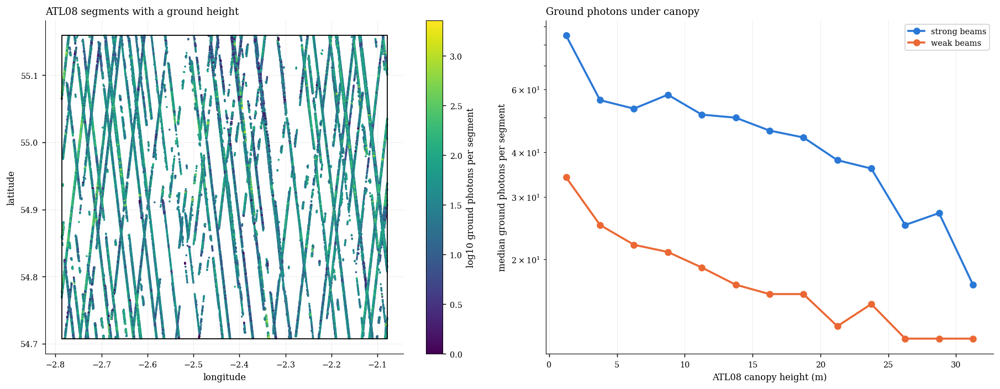

In [ ]:
icesat_files = sorted(glob.glob(f"{V3_NASA_ATL08}/tile 1/*.h5"))
BBOX = transform_bounds("EPSG:27700", "EPSG:4326", *tile_bounds, densify_pts=21)

seg = read_atl08_segments(icesat_files, BBOX)
t = summarize_atl08(seg)
plot_atl08(t, BBOX)

In [ ]:
def compare_with_lidar(t, dtm_egm_path, geoid_epsg=3855):
  """ATL08 ground (converted to EGM2008) minus the 30 m Digimap DTM (EGM2008) at each segment centre."""
  to_geoid = pyproj.Transformer.from_crs("EPSG:4979", f"EPSG:4326+{geoid_epsg}", always_xy=True,
                                          allow_ballpark=False)
  _, _, h_geo = to_geoid.transform(t.lon.values, t.lat.values, t.h_te.values, errcheck=True)
  with rasterio.open(dtm_egm_path) as src:
    x, y = pyproj.Transformer.from_crs("EPSG:4326", src.crs, always_xy=True).transform(t.lon.values, t.lat.values)
    dtm = np.array([v[0] for v in src.sample(zip(x, y))], dtype=np.float64)
    if src.nodata is not None and np.isfinite(src.nodata):
        dtm[dtm == src.nodata] = np.nan
  t = t.assign(diff=h_geo - dtm)
  t = t[np.isfinite(t["diff"])]
  rob = lambda d: f"{d.median():+6.2f} {np.sqrt(np.mean(d ** 2)):6.2f} {1.4826 * (d - d.median()).abs().median():6.2f}"
  print(f"{len(t):,} segments over valid lidar | ATL08 ground - lidar DTM (m): median, RMSE, robust std")
  print(f"  all            {rob(t['diff'])}")
  for b, s in t.groupby("beam_type"):
    print(f"  {b:6s} beams   {rob(s['diff'])}")
  for c, s in t.groupby("canopy", observed=True):
    print(f"  canopy {str(c):7s} {rob(s['diff'])}   ({len(s):,})")
  return t


CMP = compare_with_lidar(t, tile_1_align_EGM2008)

39,958 segments over valid lidar | ATL08 ground - lidar DTM (m): median, RMSE, robust std
  all             -0.20   2.60   0.91
  strong beams    -0.19   2.45   0.89
  weak   beams    -0.21   2.79   0.95
  canopy < 2 m    -0.21   0.82   0.67   (431)
  canopy 2-5 m    -0.40   1.57   1.20   (7,386)
  canopy 5-10 m   -0.34   2.41   1.08   (8,660)
  canopy 10-20 m  -0.28   3.04   1.15   (9,060)
  canopy > 20 m   -0.29   5.45   1.36   (3,122)


In [ ]:
# ====== ATL08 tail investigation, candidate filters and inference with the filtered points =======
import numpy as np
import pandas as pd
import pyproj

def tail_stats(cmp, big_m=5.0):
  """Share of large differences between atl08 and lidar and their signs, by canopy, beam, photons,
  uncertainty"""
  d = cmp["diff"]
  pct = lambda s: " ".join(f"{np.percentile(s, p):+6.1f}" for p in (1, 5, 50, 95, 99))
  def block(title, groups):
    print(f"\n{title:14s} {'n':>7s} {'|d|>%g' % big_m:>8s} {'d>+%g' % big_m:>8s} {'d<-%g' % big_m:>8s}   "
          f"percentiles 1 / 5 / 50 / 95 / 99 (m)")

    for k, s in groups:
      ds = s["diff"]
      print(f"{str(k):14s} {len(s):7,d} {np.mean(ds.abs() > big_m):8.1%} {np.mean(ds > big_m):8.1%} "
            f"{np.mean(ds < -big_m):8.1%}   {pct(ds)}")
  print(f"all: {len(cmp):,} segments | |d| > {big_m:g} m: {np.mean(d.abs() > big_m):.1%} "
        f"(above lidar ground {np.mean(d > big_m):.1%}, below {np.mean(d < -big_m):.1%})")
  block("canopy", cmp.groupby("canopy", observed=True))
  block("beam", cmp.groupby("beam_type"))
  block("light", cmp.groupby("light"))
  block("ground photons", cmp.groupby(pd.cut(cmp.n_te_ph, [0, 5, 10, 20, 50, 100, np.inf]), observed=True))
  block("uncertainty m", cmp.groupby(pd.cut(cmp.h_te_unc, [0, 0.5, 1, 2, 3, 5, np.inf]), observed=True))

# candidate filters
def along_track_deviation(df, window=5):
  """|ground height - running median of its neighbours on the same beam pass| (m).
  Segments are ordered by latitude within each file + beam."""
  out = pd.Series(np.nan, index=df.index)
  for _, g in df.groupby(["file", "beam"]):
    g = g.sort_values("lat")
    med = g.h_te.rolling(window, center=True, min_periods=3).median()
    out.loc[g.index] = (g.h_te - med).abs()
  return out

def apply_filter(df, max_unc=None, min_ph=None, strong_only=False, night_only=False, max_dev=None):
  keep = df.h_te.notna()
  if max_unc is not None:
      keep &= df.h_te_unc < max_unc
  if min_ph is not None:
      keep &= df.n_te_ph >= min_ph
  if strong_only:
      keep &= df.beam_type == "strong"
  if night_only:
      keep &= df.night == 1
  if max_dev is not None:
      keep &= df.dev < max_dev
  return df[keep]

CANDIDATES = {
  "none":                       dict(),
  "uncertainty < 2 m":          dict(max_unc=2.0),
  "ground photons >= 20":       dict(min_ph=20),
  "strong beams":               dict(strong_only=True),
  "night":                      dict(night_only=True),
  "along-track dev < 3 m":      dict(max_dev=3.0),
  "unc < 2 + dev < 3":          dict(max_unc=2.0, max_dev=3.0),
  "unc < 2 + ph >= 20 + dev < 3": dict(max_unc=2.0, min_ph=20, max_dev=3.0),
}


def compare_filters(cmp, candidates=CANDIDATES, big_m=5.0):
  """For each filter: share of segments kept, RMSE / robust spread / share of large differences."""
  if "dev" not in cmp:
    cmp = cmp.assign(dev=along_track_deviation(cmp))
  print(f"{'filter':30s} {'kept':>7s} {'RMSE':>6s} {'robust':>7s} {'median':>7s} {'|d|>%g' % big_m:>7s} "
        f"{'RMSE canopy>10':>15s}")
  for name, kw in candidates.items():
    s = apply_filter(cmp, **kw)
    d = s["diff"]
    tall = s[s.h_canopy > 10]["diff"]
    print(f"{name:30s} {len(s) / len(cmp):7.1%} {np.sqrt(np.mean(d ** 2)):6.2f} "
          f"{1.4826 * (d - d.median()).abs().median():7.2f} {d.median():+7.2f} {np.mean(d.abs() > big_m):7.1%} "
          f"{np.sqrt(np.mean(tall ** 2)) if len(tall) else np.nan:15.2f}")
  return cmp


def segments_to_points(df, dsm_crs, geoid_epsg=3855):
  """x, y in the DSM's CRS and ground height in the DSM's geoid, from a (filtered) segment table."""
  to_geoid = pyproj.Transformer.from_crs("EPSG:4979", f"EPSG:4326+{geoid_epsg}", always_xy=True,
                                          allow_ballpark=False)
  _, _, h = to_geoid.transform(df.lon.values, df.lat.values, df.h_te.values, errcheck=True)
  x, y = pyproj.Transformer.from_crs("EPSG:4326", dsm_crs, always_xy=True).transform(df.lon.values, df.lat.values)
  print(f"{len(df):,} filtered ATL08 points")
  return np.asarray(x), np.asarray(y), np.asarray(h)



In [ ]:
t = t.assign(dev=along_track_deviation(t))
t_f = apply_filter(t, min_ph=20, max_dev=3.0)

In [ ]:
copernicus_file = f"{V3_GEE}/copernicus/Copernicus_GLO30_2024_1.tif"
gee_features_file = f"{V3_GEE}/features/GEE_FEATURE_STACK_1.tif"
aligned_features_file = f"{V3_GEE}/features/GEE_FEATURE_STACK_1_aligned.tif"
tile_1_merge = f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge.vrt"
tile_1_align = f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge_aligned.tif"
tile_1_folder = f"{V3_DIGIMAP}/raw/tile 1"
tile_1_align_EGM2008 = f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge_aligned_EGM2008.tif"

###Pretraining noise

In [ ]:
# ========== testing pre-trained icesat noise of 1.0 fix on Tile B =============
from rasterio.transform import array_bounds
from rasterio.warp import transform_bounds
from scipy.ndimage import distance_transform_edt


CANOPY_BAND = 5
C_REAL, C_GAUSS, C_EMP, C_CLEAN, C_EMPTY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"

TRAIN_SIGMA = 1.0
FILTER = dict(min_ph=20, max_dev=3.0)
N_SEEDS = 5
TOL_M = 0.05
EMP_EDGES = (0, 2, 5, 10, 15, 20, 30, np.inf)

def load_site(site, stats, cfg, canopy_band=CANOPY_BAND):
  if not os.path.exists(site["dtm"]):
    print("lidar not in EGM2008 yet -> converting with shift_to_EGM2008")
    shift_to_EGM2008(site["dtm_odn"], site["dtm"])

  feat, feat_ok, prof = read_raster(site["feat"])
  assert feat.shape[0] == 8, f"expected 8 feature bands, got {feat.shape[0]}"
  dsm, dsm_ok = feat[0], feat_ok[0]
  dtm, dtm_ok, prof_t = read_raster(site["dtm"], 1)
  assert dtm.shape == dsm.shape and prof_t["transform"].almost_equals(prof["transform"]), \
    "lidar is not on the stack's grid (run the _align step for B first)"
  pixel_m = abs(prof["transform"].a)
  assert abs(pixel_m / cfg["pixel_m"] - 1) < 0.05, f"pixel {pixel_m:.2f} m, model trained at {cfg['pixel_m']:.2f} m"

  X, X_ok = build_inputs(dsm, dsm_ok, feat, feat_ok)
  stds = stats.get("global_stds", stats.get("global_std"))
  Xn = standardize(X, X_ok, stats["global_means"], stds)
  del X

  target = (dtm - dsm).astype(np.float32)
  valid = dsm_ok & dtm_ok & (target >= stats["target_min"]) & (target <= stats["target_max"])
  target = np.where(valid, target, 0.0).astype(np.float32)

  k = canopy_band - 1
  canopy = np.where(feat_ok[k], feat[k], 0.0).clip(min=0).astype(np.float32)

  H, W = dsm.shape
  print(f"site B: {W} x {H} px at {pixel_m:g} m ({W * pixel_m / 1000:.1f} x {H * pixel_m / 1000:.1f} km) | "
        f"valid lidar {valid.mean():.1%} | uncorrected DSM RMSE {np.sqrt(np.mean(target[valid] ** 2)):.2f} m")
  return dict(Xn=Xn, dsm=dsm, dsm_ok=dsm_ok, target=target, valid=valid, canopy=canopy,
              prof=prof, H=H, W=W, pixel_m=pixel_m)


def real_atl08_on_grid(site, atl08_dir, stats, flt=FILTER):
  crs, T = site["prof"]["crs"], site["prof"]["transform"]
  bounds = array_bounds(site["H"], site["W"], T)                  # (left, bottom, right, top) in BNG

  files = sorted(glob.glob(f"{atl08_dir}/*.h5"))                  # 2a  CHANGED
  if not files:
    print("no ATL08 files for B yet -> download_atl08")
    files = download_atl08(bounds, atl08_dir, crs=crs.to_string(), max_gb=5)
  assert files, f"no .h5 files in {atl08_dir}"

  bbox = transform_bounds(crs, "EPSG:4326", *bounds, densify_pts=21)
  seg = read_atl08_segments(files, bbox)                          # 2b
  seg = seg[seg.h_te.notna()]
  seg = seg.assign(dev=along_track_deviation(seg))
  seg_f = apply_filter(seg, **flt)
  print(f"ATL08 at B: {len(files)} files | {len(seg):,} segments with a ground height -> "
        f"{len(seg_f):,} after the filter")

  x, y, h = segments_to_points(seg_f, crs.to_string())            # 2c

  obs_dh_real, has_atl08 = rasterize_obs(x, y, h, site["dsm"], site["dsm_ok"], T,   # 2d  CHANGED
                                          (stats["target_min"], stats["target_max"]))

  obs_mask = has_atl08 & site["valid"]                            # 2e
  print(f"track pixels: {has_atl08.sum():,} with ATL08 -> {obs_mask.sum():,} also with valid lidar "
        f"(used in every condition)")
  return obs_dh_real, obs_mask



In [ ]:
TILE_1 = dict(
    feat=f"{V3_GEE}/features/GEE_FEATURE_STACK_1_aligned.tif",
    dtm=f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge_aligned_EGM2008.tif",
    dtm_odn=f"{V3_DIGIMAP}/stitched/tile 1/tile_1_merge_aligned.tif",
    atl08_dir=f"{V3_NASA_ATL08}/tile 1",
)

# paths to checkpoint
checkpoint = f"{BASE_DIR}/model_v3/checkpoints/realistic_icesat/best.pt"

CALIB_STACK = TILE_1["feat"]

model, STATS_CK, CFG = load_calibrator(checkpoint)

C_REAL, C_GAUSS, C_EMP, C_CLEAN, C_EMPTY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8a85"

B = load_site(TILE_1, STATS_CK, CFG)

OBS_DH_REAL, OBS_MASK = real_atl08_on_grid(B, TILE_1["atl08_dir"], STATS_CK)

loaded /content/drive/MyDrive/dsm_dtm_calibration_TTT/model_v3/checkpoints/realistic_icesat/best.pt | step 2200 | best val loss 0.3199
site B: 1522 x 1686 px at 30 m (45.7 x 50.6 km) | valid lidar 97.3% | uncorrected DSM RMSE 4.10 m
ATL08 at B: 78 files | 41,230 segments with a ground height -> 26,912 after the filter
26,912 filtered ATL08 points
26,294 points on valid DSM pixels | 7 outside (-30.0, 10.0) m dropped
track pixels: 25,846 with ATL08 -> 25,554 also with valid lidar (used in every condition)


In [ ]:
def describe_noise(d, label):
  rob = 1.4826 * np.median(np.abs(d - np.median(d)))
  print(f"{label:22s} n {d.size:7,d} | median {np.median(d):+6.2f} | RMSE {np.sqrt(np.mean(d ** 2)):5.2f} | "
        f"robust sd {rob:5.2f} | |d| > 5 m {np.mean(np.abs(d) > 5):5.1%}")

REAL_NOISE_B = (OBS_DH_REAL - B["target"])[OBS_MASK]
print(f"\nreal ATL08 - lidar at B (the model was trained with median 0, RMSE {TRAIN_SIGMA:g}, no outliers):")
describe_noise(REAL_NOISE_B, "all")
can_obs = B["canopy"][OBS_MASK]
for lo, hi in ((0, 2), (2, 5), (5, 10), (10, 20), (20, np.inf)):
  m = (can_obs >= lo) & (can_obs < hi)
  if m.sum() >= 50:
      describe_noise(REAL_NOISE_B[m], f"canopy {lo:g}-{hi:g} m")
if abs(np.median(REAL_NOISE_B)) > 0.5:
  print("WARNING: median ATL08 - lidar is above 0.5 m: check that DSM, lidar and ATL08 are all EGM2008")


real ATL08 - lidar at B (the model was trained with median 0, RMSE 1, no outliers):
all                    n  25,554 | median  -0.12 | RMSE  1.30 | robust sd  0.74 | |d| > 5 m  0.9%
canopy 0-2 m           n     443 | median  -0.11 | RMSE  1.53 | robust sd  0.44 | |d| > 5 m  0.9%
canopy 2-5 m           n   5,737 | median  -0.08 | RMSE  1.07 | robust sd  0.64 | |d| > 5 m  0.5%
canopy 5-10 m          n  15,184 | median  -0.13 | RMSE  1.24 | robust sd  0.75 | |d| > 5 m  0.6%
canopy 10-20 m         n   3,652 | median  -0.15 | RMSE  1.71 | robust sd  0.87 | |d| > 5 m  2.3%
canopy 20-inf m        n     538 | median  -0.12 | RMSE  1.83 | robust sd  0.86 | |d| > 5 m  2.0%


In [ ]:
def sample_band_at(df, stack_path, band):
  with rasterio.open(stack_path) as src:
    tr = pyproj.Transformer.from_crs("EPSG:4326", src.crs, always_xy=True)
    x, y = tr.transform(df.lon.values, df.lat.values)
    v = np.array([s[band - 1] for s in src.sample(zip(x, y))], dtype=np.float64)
    nod = src.nodata
  if nod is not None and np.isfinite(nod):
    v[v == nod] = np.nan
  return v


def residual_pools(cal, edges=EMP_EDGES, min_n=200):
  d = cal["diff"].to_numpy(np.float64)
  c = np.nan_to_num(cal["canopy_gee"].to_numpy(np.float64), nan=0.0).clip(min=0)
  cls = np.digitize(c, edges[1:-1])                   # class 0 .. len(edges) - 2 per segment
  n_cls = len(edges) - 1
  raw = [d[cls == k] for k in range(n_cls)]
  ok = [k for k in range(n_cls) if len(raw[k]) >= min_n]
  assert ok, "no canopy class has enough calibration segments: lower min_n"
  pools = []
  print(f"{'canopy class':14s} {'own n':>7s}  {'sampled from':12s} {'median':>7s} {'robust sd':>9s}")
  for k in range(n_cls):
    use = k if k in ok else min(ok, key=lambda j: abs(j - k))
    p = raw[use]
    pools.append(p)
    src = "own" if use == k else f"class {use}"
    print(f"{edges[k]:g}-{edges[k + 1]:g} m{'':6s} {len(raw[k]):7,d}  {src:12s} {np.median(p):+7.2f} "
          f"{1.4826 * np.median(np.abs(p - np.median(p))):9.2f}")
  return pools


CAL = CMP if "dev" in CMP else CMP.assign(dev=along_track_deviation(CMP))
CAL = apply_filter(CAL, **FILTER)
CAL = CAL.assign(canopy_gee=sample_band_at(CAL, CALIB_STACK, CANOPY_BAND))
print(f"calibration tile: {len(CAL):,} filtered segments")
POOLS = residual_pools(CAL)

calibration tile: 25,993 filtered segments
canopy class     own n  sampled from  median robust sd
0-2 m           555  own            -0.08      0.40
2-5 m         5,788  own            -0.08      0.65
5-10 m        15,419  own            -0.13      0.75
10-15 m         2,711  own            -0.15      0.85
15-20 m           978  own            -0.15      0.97
20-30 m           520  own            -0.13      0.84
30-inf m            22  class 5        -0.13      0.84


In [ ]:
def predict_site(model, Xn, obs_dh, obs_mask):                                  # 4a  CHANGED
  mu, sigma = run_calibrator(model, Xn, np.ascontiguousarray(obs_dh, np.float32),
                              np.ascontiguousarray(obs_mask, bool))
  return mu, 2.0 * np.log(sigma)


def gauss_values(target, obs_mask, rng, sigma=TRAIN_SIGMA):                     # 4b (ii)
  out = np.zeros_like(target)
  out[obs_mask] = target[obs_mask] + sigma * rng.standard_normal(int(obs_mask.sum()))
  return out


def empirical_values(target, obs_mask, canopy, rng, pools=POOLS, edges=EMP_EDGES):   # 4b (iii)
  out = np.zeros_like(target)
  cls = np.digitize(canopy[obs_mask], edges[1:-1])
  noise = np.zeros(cls.size, np.float32)
  for k, pool in enumerate(pools):
      m = cls == k
      if m.any():
          noise[m] = rng.choice(pool, int(m.sum()), replace=True)   # one measured error per pixel
  out[obs_mask] = target[obs_mask] + noise
  return out


def metrics(err, lv):
  s2 = np.exp(lv)
  return dict(rmse=np.sqrt(np.mean(err ** 2)), mae=np.mean(np.abs(err)), bias=np.mean(err),
              rms_sigma=np.sqrt(np.mean(s2)), cover95=np.mean(np.abs(err) <= 1.96 * np.sqrt(s2)),
              nll=np.mean(0.5 * (lv + err ** 2 / s2)))


SCORE = B["valid"] & ~OBS_MASK                                                  # 4c
tgt = B["target"]
zeros = np.zeros_like(tgt)
RUNS = {}            # condition -> list of dicts (one per seed): metrics + err / lv at the scored pixels

def record(name, obs_dh, obs_mask):
  mu, lv = predict_site(model, B["Xn"], obs_dh, obs_mask)
  err, l = (mu - tgt)[SCORE], lv[SCORE]
  RUNS.setdefault(name, []).append(dict(metrics(err, l), err=err, lv=l))

record("empty (network alone)", zeros, np.zeros_like(OBS_MASK))
record("(i) real ATL08", OBS_DH_REAL, OBS_MASK)
for s in range(N_SEEDS):
  record(f"(ii) lidar + Gaussian {TRAIN_SIGMA:g} m", gauss_values(tgt, OBS_MASK, np.random.default_rng(s)), OBS_MASK)
  record("(iii) lidar + empirical", empirical_values(tgt, OBS_MASK, B["canopy"], np.random.default_rng(100 + s)), OBS_MASK)
record("(iv) lidar, no noise", tgt, OBS_MASK)

print(f"scored on {SCORE.sum():,} off-track pixels with valid lidar | {OBS_MASK.sum():,} track pixels written\n")
print(f"{'condition':30s} {'RMSE':>14s} {'bias':>8s} {'rms σ':>7s} {'cover95':>8s} {'NLL':>7s}")
for name, runs in RUNS.items():
  r = np.array([x["rmse"] for x in runs])
  sd = f" ± {r.std():.3f}" if len(runs) > 1 else " " * 8
  avg = lambda k: np.mean([x[k] for x in runs])
  print(f"{name:30s} {r.mean():6.3f}{sd} {avg('bias'):+8.3f} {avg('rms_sigma'):7.3f} "
        f"{avg('cover95'):8.3f} {avg('nll'):7.3f}")


scored on 2,471,272 off-track pixels with valid lidar | 25,554 track pixels written

condition                                RMSE     bias   rms σ  cover95     NLL
empty (network alone)           3.444           +0.412   3.547    0.957   1.146
(i) real ATL08                  2.507           -0.361   1.903    0.927   1.092
(ii) lidar + Gaussian 1 m       2.458 ± 0.001   +0.016   1.903    0.937   1.048
(iii) lidar + empirical         2.476 ± 0.002   -0.292   1.903    0.922   1.108
(iv) lidar, no noise            2.458           +0.012   1.903    0.937   1.048


In [ ]:
R = {n: np.mean([x["rmse"] for x in runs]) for n, runs in RUNS.items()}
C95 = {n: np.mean([x["cover95"] for x in runs]) for n, runs in RUNS.items()}
k_empty, k_real, k_clean = "empty (network alone)", "(i) real ATL08", "(iv) lidar, no noise"
k_gauss, k_emp = f"(ii) lidar + Gaussian {TRAIN_SIGMA:g} m", "(iii) lidar + empirical"
tol = max(TOL_M, 2 * np.std([x["rmse"] for x in RUNS[k_gauss]]))

adapt_gain = R[k_empty] - R[k_real]     # does real ICESat help at all?
gap = R[k_real] - R[k_gauss]            # real vs the noise the model was trained for
emp_left = R[k_real] - R[k_emp]         # what the empirical simulator does NOT explain
headroom = R[k_real] - R[k_clean]       # total room from better ICESat handling

print(f"tolerance {tol:.3f} m\n")
print(f"real ICESat gain over network alone   empty - (i)  {adapt_gain:+.3f} m")
print(f"real vs trained-for noise             (i) - (ii)   {gap:+.3f} m")
print(f"left unexplained by empirical noise   (i) - (iii)  {emp_left:+.3f} m")
print(f"headroom to perfect ICESat            (i) - (iv)   {headroom:+.3f} m")
print(f"cover95: real {C95[k_real]:.3f} | trained-for noise {C95[k_gauss]:.3f} | empirical {C95[k_emp]:.3f}\n")

if adapt_gain < tol:
  print("NOTE: real ICESat barely improves on the network alone at B. Check that first (support pixels,\n"
        "      datum, the adaptation itself) before drawing conclusions about the noise model.")
if gap <= tol:
  print("VERDICT: the 1.0 m Gaussian training noise is NOT limiting at B -> no retrain needed;\n"
        "         the F4 noise runs become a robustness section, not a fix.")
elif abs(emp_left) <= tol:
  print("VERDICT: real noise costs accuracy AND the empirical simulator reproduces it ->\n"
        "         retraining with empirical noise (F4) is justified.")
else:
  print("VERDICT: real noise costs accuracy, but per-pixel empirical noise does NOT reproduce it ->\n"
        "         the difference is in something per-pixel resampling misses (errors correlated along a\n"
        "         track, a site-level bias). A better per-pixel noise model alone will not close the gap.")
if C95[k_real] < C95[k_gauss] - 0.03:
  print("ALSO: coverage drops with real ATL08 -> σ is overconfident with real data, even if RMSE is close.")

tolerance 0.050 m

real ICESat gain over network alone   empty - (i)  +0.937 m
real vs trained-for noise             (i) - (ii)   +0.049 m
left unexplained by empirical noise   (i) - (iii)  +0.031 m
headroom to perfect ICESat            (i) - (iv)   +0.049 m
cover95: real 0.927 | trained-for noise 0.937 | empirical 0.922

VERDICT: the 1.0 m Gaussian training noise is NOT limiting at B -> no retrain needed;
         the F4 noise runs become a robustness section, not a fix.


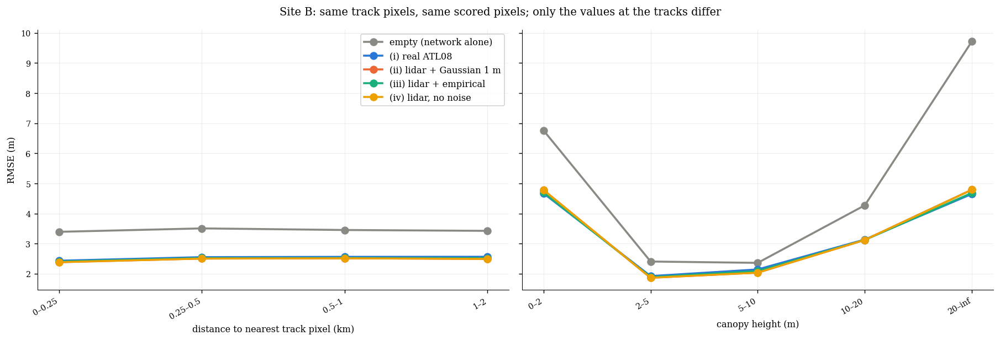

In [ ]:
dist_km = (distance_transform_edt(~OBS_MASK) * B["pixel_m"] / 1000)[SCORE]
can_s = B["canopy"][SCORE]
binnings = (("distance to nearest track pixel (km)", dist_km, (0, 0.25, 0.5, 1, 2, 4, 8, np.inf)),
            ("canopy height (m)", can_s, (0, 2, 5, 10, 20, np.inf)))
colors = {k_empty: C_EMPTY, k_real: C_REAL, k_gauss: C_GAUSS, k_emp: C_EMP, k_clean: C_CLEAN}

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
for ax, (xlabel, v, edges) in zip(axes, binnings):
  b = np.digitize(v, edges[1:-1])
  keep = [j for j in range(len(edges) - 1) if (b == j).sum() >= 200]
  labels = [f"{edges[j]:g}–{edges[j + 1]:g}" for j in keep]
  pos = np.arange(len(keep))
  for name, runs in RUNS.items():
    rm = [np.mean([np.sqrt(np.mean(x["err"][b == j] ** 2)) for x in runs]) for j in keep]
    ax.plot(pos, rm, color=colors[name], marker="o", ms=7, lw=2, label=name)
  ax.set_xticks(pos); ax.set_xticklabels(labels, rotation=30, ha="right")
  ax.set_xlabel(xlabel); ax.grid(alpha=0.3)
axes[0].set_ylabel("RMSE (m)"); axes[0].legend(fontsize=9)
fig.suptitle("Site B: same track pixels, same scored pixels; only the values at the tracks differ")
plt.tight_layout(); plt.show()

In [ ]:
# ==============================================================================
# CHANGED: private helpers renamed _style -> _site_style, _metrics -> _site_metrics: other notebook cells
# (the tile A zero-mask / TTT tests) define their own _metrics / _style and were overwriting these.
# =====================================================================================================
# NEW: evaluation tables and plots for ONE site with real ATL08 (B, C-val, D, ...). One site per heading.
#
# Per site, in this order:
#   S   = prepare_site(SITE, STATS_CK, CFG)                 # inputs, lidar target, canopy (optionally a box)
#   OBS = site_icesat(S, SITE["atl08_dir"])                  # real ATL08 on the site's grid
#   P   = predict_methods(S, OBS, models={"M0": model}, baselines={"FABDEM": path, ...})
#   metrics_table(P, S, OBS); canopy_table(P, S, OBS)
#   add_classical_baselines(P, S, OBS); table5([(P, S, OBS)], ROWS)   # Table 5 (B3-B5, CIs, CRPS)
#   paper_style()                                          # once: print-ready fonts / lines / 300 dpi
#   plot_distance(...); plot_canopy(...); plot_error_maps(...); plot_rasters(..., "M0 full")
#   each plot takes save="figures/site_B_xxx.pdf"
#
# Rows ("methods") in every table and plot:
#   uncorrected DSM              mu = 0
#   <baseline>                   mu = baseline DEM - DSM (FABDEM / FathomDEM, if paths given; no sigma)
#   <model> network alone        empty observation mask (no ICESat)
#   <model> + global offset      network alone + one scalar: mean(ATL08 delta_h - mu) over the track pixels
#   <model> full                 closed-form last-layer adaptation with the real ATL08 tracks
# Several models (e.g. {"M0": m0, "M1": m1}) give M0 vs M1 on exactly the same pixels.
#
# Scored pixels (identical for every method): valid lidar AND not an ATL08 pixel. Every ATL08 pixel on a
# valid DSM pixel is used as support, as at deployment (also where the lidar has a gap).
#
# Needs from your notebook: read_raster, build_inputs, standardize, rasterize_obs, run_calibrator,
#   shift_to_EGM2008, download_atl08, read_atl08_segments, along_track_deviation, apply_filter,
#   segments_to_points. Plots are self-contained matplotlib (no show_map needed).
# =====================================================================================================
import os, glob
import numpy as np
import pandas as pd
import rasterio
import matplotlib.pyplot as plt
from affine import Affine
from rasterio.transform import array_bounds
from rasterio.warp import transform_bounds
from scipy.ndimage import distance_transform_edt

FILTER = dict(min_ph=20, max_dev=3.0)                  # the ATL08 filter you chose
CANOPY_EDGES = (0, 2, 5, 10, 20, np.inf)
DIST_EDGES_KM = (0, 0.25, 0.5, 1, 2, 4, 8, np.inf)
C_HIGH, C_LOW, C_REF = "#eb6834", "#2a78d6", "#8a8a85"
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8e5bd0", "#d03f6c", "#1a1a19", "#5aa9b8"]


# ---------- 1) the site: inputs, lidar target, canopy ----------------------------------------------------
def prepare_site(site, stats, cfg, canopy_band=5, box=None, building_band=8):
    """site: dict(feat, dtm, dtm_odn, atl08_dir). box: optional (y0, x0, y1, x1) in pixels to cut the site
    to (e.g. the C-val box); everything below then works on that box only, with its own transform.
      1a lidar in EGM2008 (converted with shift_to_EGM2008 if the file does not exist yet)
      1b stack + lidar on one grid; DSM = band 1 of the stack
      1c optional crop to `box`
      1d inputs: build_inputs, standardize with tile A's statistics (never the site's own)
      1e target delta_h = lidar - DSM; valid = both exist and inside the training range; raw canopy"""
    if not os.path.exists(site["dtm"]):                                          # 1a
        print("lidar not in EGM2008 yet -> shift_to_EGM2008")
        shift_to_EGM2008(site["dtm_odn"], site["dtm"])

    feat, feat_ok, prof = read_raster(site["feat"])                              # 1b
    assert feat.shape[0] == 8, f"expected 8 feature bands, got {feat.shape[0]}"
    dtm, dtm_ok, prof_t = read_raster(site["dtm"], 1)
    assert dtm.shape == feat.shape[1:] and prof_t["transform"].almost_equals(prof["transform"]), \
        "lidar is not on the stack's grid (run _align for this site first)"
    T = prof["transform"]

    if box is not None:                                                          # 1c
        y0, x0, y1, x1 = box
        feat, feat_ok = feat[:, y0:y1, x0:x1], feat_ok[:, y0:y1, x0:x1]
        dtm, dtm_ok = dtm[y0:y1, x0:x1], dtm_ok[y0:y1, x0:x1]
        T = T * Affine.translation(x0, y0)

    dsm, dsm_ok = feat[0], feat_ok[0]
    pixel_m = abs(T.a)
    assert abs(pixel_m / cfg["pixel_m"] - 1) < 0.05, f"pixel {pixel_m:.2f} m, model trained at {cfg['pixel_m']:.2f} m"

    X, X_ok = build_inputs(dsm, dsm_ok, feat, feat_ok)                           # 1d
    Xn = standardize(X, X_ok, stats["global_means"], stats.get("global_stds", stats.get("global_std")))
    del X

    target = (dtm - dsm).astype(np.float32)                                      # 1e
    valid = dsm_ok & dtm_ok & (target >= stats["target_min"]) & (target <= stats["target_max"])
    k = canopy_band - 1
    canopy = np.where(feat_ok[k], feat[k], 0.0).clip(min=0).astype(np.float32)
    kb = building_band - 1                                                       # CHANGED: building height
    bldg = np.where(feat_ok[kb], feat[kb], 0.0).clip(min=0).astype(np.float32)   # (for the B4 / B5 baselines)

    H, W = dsm.shape
    print(f"site: {W} x {H} px at {pixel_m:g} m ({W * pixel_m / 1000:.1f} x {H * pixel_m / 1000:.1f} km)"
          f"{' | box ' + str(box) if box is not None else ''} | valid lidar {valid.mean():.1%}")
    return dict(Xn=Xn, dsm=dsm, dsm_ok=dsm_ok, target=np.where(valid, target, 0.0).astype(np.float32),
                valid=valid, canopy=canopy, bldg=bldg, transform=T, crs=prof["crs"], H=H, W=W, pixel_m=pixel_m,
                stats=stats)


# ---------- 2) real ATL08 on the site's grid --------------------------------------------------------------
def site_icesat(S, atl08_dir, flt=FILTER, start="2022-01-01", end="2024-12-31", max_gb=5):
    """2a download if the folder is empty (the site's own bounds), 2b read + filter (your chosen filter),
    2c convert to EGM2008 / site CRS, 2d rasterise with your rasterize_obs (training delta_h range).
    Returns dict(obs_dh, obs_mask, n_segments)."""
    bounds = array_bounds(S["H"], S["W"], S["transform"])
    files = sorted(glob.glob(f"{atl08_dir}/*.h5"))                               # 2a
    if not files:
        files = download_atl08(bounds, atl08_dir, start=start, end=end, crs=S["crs"].to_string(), max_gb=max_gb)
    assert files, f"no .h5 files in {atl08_dir}"

    bbox = transform_bounds(S["crs"], "EPSG:4326", *bounds, densify_pts=21)      # 2b
    seg = read_atl08_segments(files, bbox)
    seg = seg[seg.h_te.notna()]
    seg = seg.assign(dev=along_track_deviation(seg))
    seg_f = apply_filter(seg, **flt)
    print(f"ATL08: {len(files)} files | {len(seg):,} segments -> {len(seg_f):,} after the filter")

    x, y, h = segments_to_points(seg_f, S["crs"].to_string())                    # 2c
    obs_dh, obs_mask = rasterize_obs(x, y, h, S["dsm"], S["dsm_ok"], S["transform"],   # 2d
                                     (S["stats"]["target_min"], S["stats"]["target_max"]))
    d = (obs_dh - S["target"])[obs_mask & S["valid"]]
    print(f"ATL08 pixels: {obs_mask.sum():,} | of which with lidar: {(obs_mask & S['valid']).sum():,} | "
          f"ATL08 - lidar there: median {np.median(d):+.2f} m, RMSE {np.sqrt(np.mean(d ** 2)):.2f} m")
    return dict(obs_dh=obs_dh, obs_mask=obs_mask, n_segments=len(seg_f))


# ---------- 3) one prediction per method -----------------------------------------------------------------
def _read_baseline(path, S, box=None):
    with rasterio.open(path) as src:
        a = src.read(1).astype(np.float32); T = src.transform; nod = src.nodata
    if nod is not None and np.isfinite(nod):
        a[a == nod] = np.nan
    if a.shape != (S["H"], S["W"]):                       # the site was cut to a box: cut the baseline too
        assert box is not None, f"{path}: shape {a.shape} differs from the site and no box was given"
        y0, x0, y1, x1 = box
        a, T = a[y0:y1, x0:x1], T * Affine.translation(x0, y0)
    assert T.almost_equals(S["transform"]), f"{path} is not on the site's grid"
    return a


def predict_methods(S, OBS, models, baselines=None, box=None):
    """models: {"M0": model, ...} (loaded, eval). baselines: {"FABDEM": path, ...} on the site's full grid
    (box: the same box given to prepare_site, so the baselines are cut identically).
    Returns {method: dict(mu=[H, W], sigma=[H, W] or None)}."""
    P = {"uncorrected DSM": dict(mu=np.zeros((S["H"], S["W"]), np.float32), sigma=None)}
    for name, path in (baselines or {}).items():
        dem = _read_baseline(path, S, box)
        P[name] = dict(mu=np.where(np.isfinite(dem), dem - S["dsm"], np.nan).astype(np.float32), sigma=None)

    zeros_dh = np.zeros((S["H"], S["W"]), np.float32)
    zeros_m = np.zeros((S["H"], S["W"]), bool)
    obs_dh = np.ascontiguousarray(OBS["obs_dh"], np.float32)
    obs_mask = np.ascontiguousarray(OBS["obs_mask"], bool)
    for name, m in models.items():
        m.eval()
        mu0, s0 = run_calibrator(m, S["Xn"], zeros_dh, zeros_m)                 # no ICESat
        P[f"{name} network alone"] = dict(mu=mu0, sigma=s0)
        b = float(np.mean(obs_dh[obs_mask] - mu0[obs_mask])) if obs_mask.any() else 0.0
        P[f"{name} + global offset"] = dict(mu=mu0 + b, sigma=s0)               # one scalar, network sigma
        mu1, s1 = run_calibrator(m, S["Xn"], obs_dh, obs_mask)                  # closed-form adaptation
        P[f"{name} full"] = dict(mu=mu1, sigma=s1)
        print(f"{name}: global offset {b:+.3f} m | max |full - network alone| {np.abs(mu1 - mu0).max():.2f} m")
    return P


# ---------- 4) tables ----------------------------------------------------------------------------------------
def _score_mask(S, OBS, P):
    """valid lidar, not an ATL08 pixel, finite in every method (baselines can have gaps), and inside
    S["score"] if the site has one (tile A block episodes: the block, not its context ring)."""
    sel = S["valid"] & ~OBS["obs_mask"]
    if "score" in S:                                                              # CHANGED
        sel &= S["score"]
    for p in P.values():
        sel &= np.isfinite(p["mu"])
    return sel


def _site_metrics(err, sigma, thresh):
    r = dict(RMSE=np.sqrt(np.mean(err ** 2)), MAE=np.mean(np.abs(err)), bias=np.mean(err),
             NMAD=1.4826 * np.median(np.abs(err - np.median(err))),
             **{f"|e|>{thresh:g}m": np.mean(np.abs(err) > thresh)})
    if sigma is not None:
        s2 = sigma.astype(np.float64) ** 2
        r.update(**{"RMS σ": np.sqrt(np.mean(s2)), "cover95": np.mean(np.abs(err) <= 1.96 * np.sqrt(s2)),
                    "NLL": np.mean(0.5 * (np.log(s2) + err ** 2 / s2))})
    return r


def metrics_table(P, S, OBS, thresh=2.0):
    """RMSE / MAE / bias / NMAD / share |e| > thresh, and RMS σ / cover95 / NLL where a σ exists."""
    sel = _score_mask(S, OBS, P)
    rows = {}
    for name, p in P.items():
        err = (p["mu"] - S["target"])[sel]
        rows[name] = _site_metrics(err, None if p["sigma"] is None else p["sigma"][sel], thresh)
    df = pd.DataFrame(rows).T
    print(f"{sel.sum():,} scored pixels (valid lidar, off the ATL08 pixels, finite in every method)")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 160):
        print(df.to_string(na_rep="—"))
    return df


def canopy_table(P, S, OBS, edges=CANOPY_EDGES, min_px=200):
    """RMSE and bias per canopy-height class (m) per method."""
    sel = _score_mask(S, OBS, P)
    c = S["canopy"][sel]
    cls = np.digitize(c, np.asarray(edges)[1:-1])
    labels = [f"{edges[j]:g}-{edges[j + 1]:g} m" for j in range(len(edges) - 1)]
    rmse, bias = {}, {}
    for name, p in P.items():
        err = (p["mu"] - S["target"])[sel]
        rmse[name] = {labels[j]: np.sqrt(np.mean(err[cls == j] ** 2)) if (cls == j).sum() >= min_px else np.nan
                      for j in range(len(labels))}
        bias[name] = {labels[j]: err[cls == j].mean() if (cls == j).sum() >= min_px else np.nan
                      for j in range(len(labels))}
    n = pd.Series({labels[j]: int((cls == j).sum()) for j in range(len(labels))}, name="pixels")
    R, B = pd.DataFrame(rmse).T, pd.DataFrame(bias).T
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 160):
        print("pixels per canopy class:\n" + n.to_string() + "\n\nRMSE (m) by canopy height:\n" + R.to_string(na_rep="—")
              + "\n\nbias (m) by canopy height:\n" + B.to_string(na_rep="—"))
    return R, B


# ---------- 5) figures for the dissertation ------------------------------------------------------------------
# CHANGED (v2): publication layout. Every figure is ONE horizontal row of panels labelled (a), (b), ...,
# with one shared legend under the row, method names written out (LABELS), fixed colours per method
# (the same method has the same colour in every figure), no figure suptitle by default (the caption goes
# in the dissertation), and `save=".../fig.pdf"` writes a 300 dpi vector / raster file.
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib import colors as mcolors

LABELS = {                                    # internal name -> name printed in figures (edit freely)
    "uncorrected DSM": "Copernicus GLO-30 DSM",
    "FABDEM": "FABDEM",
    "FathomDEM": "FathomDEM",
    "network alone": "Network only",
    "+ global offset": "Network + global ATL08 offset",
    "full": "Network + ATL08 adaptation",
    "DSM + ATL08 offset": "Copernicus + global ATL08 offset",          # CHANGED: Table 5 baselines B3-B5
    "ridge regression": "Regional ridge regression",
    "regression kriging": "Regression kriging",
}
ROLE_COLORS = {                               # fixed per method role (colour follows the method, not its rank)
    "uncorrected DSM": "#8a8a85", "FABDEM": "#6250d6", "FathomDEM": "#e87ba4",
    "network alone": "#eb6834", "+ global offset": "#1baf7a", "full": "#2a78d6",
    "DSM + ATL08 offset": "#008300", "ridge regression": "#eda100", "regression kriging": "#e34948",
}
C_HIGH, C_LOW, C_TRACK = "#d95926", "#2a78d6", "#0b0b0b"     # too high / too low / ATL08 pixels
PANEL = "abcdefghijklmnopqrstuvwxyz"


def paper_style(font_size=9, family="serif"):
    """Matplotlib settings for print: small serif text, thin spines, light grid, 300 dpi when saved.
    Call once before plotting (family="sans-serif" if your dissertation uses a sans font)."""
    plt.rcParams.update({
        "font.family": family, "font.size": font_size, "axes.titlesize": font_size + 1,
        "axes.labelsize": font_size, "xtick.labelsize": font_size - 1, "ytick.labelsize": font_size - 1,
        "legend.fontsize": font_size - 1, "axes.spines.top": False, "axes.spines.right": False,
        "axes.linewidth": 0.6, "grid.linewidth": 0.4, "grid.alpha": 0.5, "lines.linewidth": 1.6,
        "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight", "axes.titlelocation": "left",
    })


def _role(name):
    """('full', 'M0') for 'M0 full'; ('FABDEM', None) for a baseline."""
    for r in ("network alone", "+ global offset", "full"):
        if name.endswith(" " + r):
            return r, name[: -len(r) - 1]
    return name, None


def _label(name, multi_model):
    r, m = _role(name)
    base = LABELS.get(r, r)
    return f"{base} ({m})" if (m and multi_model) else base


def _site_style(name, model_order):
    """Colour from the role; a second model (e.g. M1) gets the same colour, dashed, other marker."""
    r, m = _role(name)
    k = model_order.index(m) if m in model_order else 0
    ls = "--" if (name == "uncorrected DSM" or k == 1) else ("-." if k > 1 else "-")
    return dict(color=ROLE_COLORS.get(r, "#52514e"), ls=ls, marker="osD^v"[k % 5])


def _models(P):
    out = []
    for n in P:
        _, m = _role(n)
        if m and m not in out:
            out.append(m)
    return out


def _save(fig, save):
    if save:
        fig.savefig(save)
        print("saved", save)


def _extent_km(S):
    T = S["transform"]
    x0, y0 = T.c, T.f
    return (x0 / 1000, (x0 + S["W"] * T.a) / 1000, (y0 + S["H"] * T.e) / 1000, y0 / 1000)


def _window_mask(S, window_km):
    """Pixels inside window_km = (east_min, east_max, north_min, north_max) in km (None = whole site)."""
    if window_km is None:
        return np.ones((S["H"], S["W"]), bool)
    T = S["transform"]
    e = (T.c + (np.arange(S["W"]) + 0.5) * T.a) / 1000
    n = (T.f + (np.arange(S["H"]) + 0.5) * T.e) / 1000
    e0, e1, n0, n1 = window_km
    return ((n >= n0) & (n <= n1))[:, None] & ((e >= e0) & (e <= e1))[None, :]


def _hillshade(z, pixel_m, azimuth=315.0, altitude=45.0):
    """Standard hillshade (0..1) of the DSM, used as a quiet background under the error maps."""
    z = np.where(np.isfinite(z), z, np.nanmean(z))
    gy, gx = np.gradient(z, pixel_m)
    slope = np.arctan(np.hypot(gx, gy))
    aspect = np.arctan2(-gx, gy)
    az, alt = np.radians(azimuth), np.radians(altitude)
    hs = np.sin(alt) * np.cos(slope) + np.cos(alt) * np.sin(slope) * np.cos(az - aspect)
    return np.clip(hs, 0, 1)


def _map_aspect(S, window_km=None):
    """height / width of the mapped area, so map panels get the right shape (no empty side margins)."""
    if window_km is not None:
        return (window_km[3] - window_km[2]) / (window_km[1] - window_km[0])
    return S["H"] / S["W"]


def _row(n, panel_w=3.1, panel_h=3.1, extra_h=0.0):
    fig, axes = plt.subplots(1, n, figsize=(panel_w * n, panel_h + extra_h), squeeze=False,
                             constrained_layout=True)
    return fig, axes[0]


def plot_distance(P, S, OBS, edges=DIST_EDGES_KM, methods=None, min_px=200, title=None, save=None):
    """(a) RMSE and (b) RMS predicted σ vs distance to the nearest ATL08 pixel. One legend under the row."""
    methods = [m for m in (list(P) if methods is None else methods) if m in P]
    order, multi = _models(P), len(_models(P)) > 1
    sel = _score_mask(S, OBS, P)
    dist = (distance_transform_edt(~OBS["obs_mask"]) * S["pixel_m"] / 1000)[sel]
    b = np.digitize(dist, np.asarray(edges)[1:-1])
    keep = [j for j in range(len(edges) - 1) if (b == j).sum() >= min_px]
    labels = [f"{edges[j]:g}–{edges[j + 1]:g}" for j in keep]
    pos = np.arange(len(keep))
    fig, (a1, a2) = _row(2, panel_w=3.6, panel_h=2.8)
    handles = []
    for name in methods:
        p, st = P[name], _site_style(name, order)
        err = (p["mu"] - S["target"])[sel]
        h, = a1.plot(pos, [np.sqrt(np.mean(err[b == j] ** 2)) for j in keep], ms=4.5, **st,
                     label=_label(name, multi))
        handles.append(h)
        if p["sigma"] is not None:
            s = p["sigma"][sel]
            a2.plot(pos, [np.sqrt(np.mean(s[b == j] ** 2)) for j in keep], ms=4.5, **st)
    for ax, t in ((a1, "(a) RMSE"), (a2, "(b) RMS predicted σ")):
        ax.set_xticks(pos); ax.set_xticklabels(labels)
        ax.set_xlabel("Distance to nearest ATL08 pixel (km)"); ax.set_ylabel("m")
        ax.set_title(t); ax.grid(True, axis="y")
    fig.legend(handles=handles, loc="outside lower center", ncol=min(len(handles), 3), frameon=False)
    if title:
        fig.suptitle(title)
    _save(fig, save); plt.show()


def plot_canopy(P, S, OBS, edges=CANOPY_EDGES, methods=None, min_px=200, title=None, save=None):
    """Grouped bars: RMSE per canopy-height class, one bar per method; n pixels under each class."""
    methods = [m for m in (list(P) if methods is None else methods) if m in P]
    order, multi = _models(P), len(_models(P)) > 1
    sel = _score_mask(S, OBS, P)
    cls = np.digitize(S["canopy"][sel], np.asarray(edges)[1:-1])
    keep = [j for j in range(len(edges) - 1) if (cls == j).sum() >= min_px]
    fig, (ax,) = _row(1, panel_w=6.6, panel_h=2.9)
    w = 0.8 / len(methods)
    for i, name in enumerate(methods):
        err = (P[name]["mu"] - S["target"])[sel]
        y = [np.sqrt(np.mean(err[cls == j] ** 2)) for j in keep]
        st = _site_style(name, order)
        ax.bar(np.arange(len(keep)) + (i - (len(methods) - 1) / 2) * w, y, width=w * 0.92,
               color=st["color"], hatch="///" if st["ls"] != "-" and name != "uncorrected DSM" else None,
               edgecolor="white", linewidth=0.4, label=_label(name, multi))
    top = "∞"
    ax.set_xticks(np.arange(len(keep)))
    ax.set_xticklabels([f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", top) + f"\n(n = {int((cls == j).sum()) / 1e3:.0f}k)"
                        for j in keep])
    ax.set_xlabel("Canopy height (m)"); ax.set_ylabel("RMSE (m)"); ax.grid(True, axis="y")
    ax.set_axisbelow(True)
    fig.legend(loc="outside lower center", ncol=min(len(methods), 3), frameon=False)
    if title:
        fig.suptitle(title)
    _save(fig, save); plt.show()


def plot_error_maps(P, S, OBS, methods=None, thresh=2.0, window_km=None, show_tracks=True, title=None,
                    save=None, ncols=None):
    """One row: per method, the pixels where the ground is > thresh too high (orange) or too low (blue)
    vs lidar, drawn per pixel over a hillshade of the DSM; ATL08 pixels in black.
    window_km = (east_min, east_max, north_min, north_max) zooms all panels to the same window; the
    share in each panel title is then computed in that window. (ncols: ignored, always one row; kept so
    older calls still run.)"""
    methods = list(P) if methods is None else methods
    skipped = [m for m in methods if m not in P]
    methods = [m for m in methods if m in P]
    if skipped:
        print(f"not in P, skipped: {skipped} | available: {list(P)}")
    multi = len(_models(P)) > 1
    win = _window_mask(S, window_km)
    sel = _score_mask(S, OBS, P) & win
    ext = _extent_km(S)
    hs = _hillshade(np.where(S["dsm_ok"], S["dsm"], np.nan), S["pixel_m"])
    fig, axes = _row(len(methods), panel_w=3.0, panel_h=3.0 * _map_aspect(S, window_km), extra_h=0.9)
    for i, (ax, name) in enumerate(zip(axes, methods)):
        err = np.where(sel, P[name]["mu"] - S["target"], np.nan)
        ax.imshow(hs, cmap="gray", vmin=0, vmax=1, extent=ext, interpolation="nearest", alpha=0.9)
        over = np.zeros((S["H"], S["W"], 4), np.float32)                       # per-pixel colour layer
        over[err > thresh] = mcolors.to_rgba(C_HIGH, 0.9)
        over[err < -thresh] = mcolors.to_rgba(C_LOW, 0.9)
        if show_tracks:
            over[OBS["obs_mask"] & win] = mcolors.to_rgba(C_TRACK, 1.0)
        ax.imshow(over, extent=ext, interpolation="nearest")
        share = np.mean(np.abs(err[sel]) > thresh)
        ax.set_title(f"({PANEL[i]}) {_label(name, multi)}\n|error| > {thresh:g} m: {share:.1%}", fontsize=9)
        ax.set_xlabel("Easting (km)")
        if i == 0:
            ax.set_ylabel("Northing (km)")
        else:
            ax.tick_params(labelleft=False)
        if window_km is not None:
            ax.set_xlim(window_km[0], window_km[1]); ax.set_ylim(window_km[2], window_km[3])
        ax.set_aspect("equal")
    handles = [Patch(color=C_HIGH, label=f"ground too high (> +{thresh:g} m)"),
               Patch(color=C_LOW, label=f"ground too low (< −{thresh:g} m)")]
    if show_tracks:
        handles.append(Patch(color=C_TRACK, label="ATL08 pixels"))
    fig.legend(handles=handles, loc="outside lower center", ncol=len(handles), frameon=False)
    if title:
        fig.suptitle(title)
    _save(fig, save); plt.show()


def plot_rasters(P, S, OBS, method, err_lim=5.0, window_km=None, title=None, save=None):
    """One row for one method (name it in the caption): (a) reference Δh, (b) predicted Δh (same diverging scale), (c) predicted σ,
    (d) error predicted − reference (diverging, ±err_lim m). Colour bars under each panel."""
    p = P[method]
    ext = _extent_km(S)
    tgt = np.where(S["valid"], S["target"], np.nan)
    mu = np.where(S["dsm_ok"], p["mu"], np.nan)
    lim = float(np.nanpercentile(np.abs(tgt), 99))
    panels = [("Reference Δh (lidar DTM − DSM)", tgt, "RdBu", -lim, lim, "m"),
              ("Predicted Δh", mu, "RdBu", -lim, lim, "m")]
    if p["sigma"] is not None:
        sg = np.where(S["dsm_ok"], p["sigma"], np.nan)
        panels.append(("Predicted σ", sg, "Blues", 0, float(np.nanpercentile(sg, 99)), "m"))
    panels.append(("Error (predicted − reference)", np.where(S["valid"], p["mu"] - S["target"], np.nan),
                   "RdBu_r", -err_lim, err_lim, "m"))
    fig, axes = _row(len(panels), panel_w=3.0, panel_h=3.0 * _map_aspect(S, window_km), extra_h=0.9)
    for i, (ax, (t, a, cmap, v0, v1, unit)) in enumerate(zip(axes, panels)):
        im = ax.imshow(a, cmap=cmap, vmin=v0, vmax=v1, extent=ext, interpolation="nearest")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.02, aspect=30)
        cb.set_label(unit); cb.outline.set_linewidth(0.4)
        ax.set_title(f"({PANEL[i]}) {t}", fontsize=9)
        ax.tick_params(labelbottom=False)
        if i == 0:
            ax.set_ylabel("Northing (km)")
        else:
            ax.tick_params(labelleft=False)
        if window_km is not None:
            ax.set_xlim(window_km[0], window_km[1]); ax.set_ylim(window_km[2], window_km[3])
        ax.set_aspect("equal")
    if title:
        fig.suptitle(title)
    _save(fig, save); plt.show()


# ---------- 6) NEW: Table 5 -- classical baselines B3-B5, extended metrics, block-bootstrap intervals ---------
#   add_classical_baselines(P, S, OBS)   adds to P (same pixels as everything else):
#       "DSM + ATL08 offset"   B3  mu = mean(ATL08 delta_h) everywhere (one scalar, no network)
#       "ridge regression"     B4  per 16 km cell: delta_h ~ b0 + b1 * canopy + b2 * building height, ridge fit
#                                  on the ATL08 pixels of that cell (site-wide fit for cells with < 30 pixels)
#       "regression kriging"   B5  B4 + ordinary kriging of the B4 residuals at the ATL08 pixels
#                                  (exponential variogram fitted to those residuals, 32 nearest neighbours);
#                                  sigma = kriging standard deviation -> Cov. 95 % and CRPS
#   episode_items(model, TEST_A, ...)    tile A block episodes (simulated tracks) -> the same (P, S, OBS) form,
#                                        scored inside each block only (score_mask, no context pixels)
#   table5(items, ROWS)                  RMSE, ME, NMAD, |e|95, Cov. 95 %, CRPS with 95 % block-bootstrap
#                                        intervals; items = [(P, S, OBS)] for a site, or one per test block
from scipy.spatial import cKDTree
from scipy.optimize import curve_fit
from scipy.ndimage import map_coordinates
from scipy.stats import norm


def add_dsm_offset(P, S, OBS, name="DSM + ATL08 offset"):
    """B3: the Copernicus DSM plus ONE scalar, the mean ATL08 delta_h over the track pixels (no network)."""
    o = OBS["obs_mask"]
    b = float(np.mean(OBS["obs_dh"][o])) if o.any() else 0.0
    P[name] = dict(mu=np.full((S["H"], S["W"]), b, np.float32), sigma=None)
    return b


def _cell_index(S, cell_km):
    """Cell of every pixel for square cells of cell_km, laid out like the model's grid level
    (number of cells = ceil(size / cell), spread evenly over the site)."""
    res_px = cell_km * 1000 / S["pixel_m"]
    Hg, Wg = max(1, int(np.ceil(S["H"] / res_px))), max(1, int(np.ceil(S["W"] / res_px)))
    cy = np.minimum((np.arange(S["H"]) * Hg // S["H"]), Hg - 1)
    cx = np.minimum((np.arange(S["W"]) * Wg // S["W"]), Wg - 1)
    return cy[:, None] * Wg + cx[None, :], Hg * Wg


def ridge_baseline(S, OBS, cell_km=16.0, lam=1.0, min_pts=30):
    """B4: per cell, ridge regression of the ATL08 delta_h on standardised canopy and building height
    (the intercept is not penalised). Returns mu [H, W] and the residuals at the ATL08 pixels."""
    bldg = S.get("bldg")
    if bldg is None:
        print("no building band in S: B4 / B5 use canopy only")
        bldg = np.zeros((S["H"], S["W"]), np.float32)
    o = OBS["obs_mask"]
    y = OBS["obs_dh"][o].astype(np.float64)
    feats = [S["canopy"].astype(np.float64), np.nan_to_num(bldg).astype(np.float64)]
    mz = [f[o].mean() for f in feats]
    sz = [max(f[o].std(), 1e-6) for f in feats]
    Z = [(f - m) / s for f, m, s in zip(feats, mz, sz)]                     # standardised by the ATL08 pixels
    X_all = np.stack([np.ones((S["H"], S["W"]))] + Z, -1)                 # [H, W, 3]
    cell, n_cells = _cell_index(S, cell_km)
    pen = lam * np.diag([0.0, 1.0, 1.0])

    def solve(Xo, yo):
        return np.linalg.solve(Xo.T @ Xo + pen + 1e-9 * np.eye(3), Xo.T @ yo)

    Xo, co = X_all[o], cell[o]
    beta_site = solve(Xo, y)
    mu = np.empty((S["H"], S["W"]), np.float64)
    n_local = 0
    for k in range(n_cells):
        m = co == k
        beta = solve(Xo[m], y[m]) if m.sum() >= min_pts else beta_site
        n_local += m.sum() >= min_pts
        pix = cell == k
        mu[pix] = X_all[pix] @ beta
    print(f"B4 ridge: {n_cells} cells of {cell_km:g} km, {n_local} fitted locally (>= {min_pts} ATL08 px), "
          f"the rest with the site-wide fit")
    return mu.astype(np.float32), (y - mu[o])


def _exp_vgm(h, c0, c, a):
    return c0 + c * (1.0 - np.exp(-h / a))


def fit_residual_variogram(xy, r, max_lag_m=10000.0, short_m=2000.0, n_bins=20, n_long=2_000_000, seed=0):
    """Exponential variogram (nugget c0, partial sill c, range parameter a in m) of the residuals r at xy.
    Short lags from all pairs within short_m (KD-tree), long lags from random pairs."""
    rng = np.random.default_rng(seed)
    tree = cKDTree(xy)
    pr = tree.query_pairs(short_m, output_type="ndarray")
    if len(pr) > 3_000_000:
        pr = pr[rng.choice(len(pr), 3_000_000, replace=False)]
    i, j = rng.integers(0, len(r), n_long), rng.integers(0, len(r), n_long)
    d_long = np.hypot(*(xy[i] - xy[j]).T)
    keep = (d_long > short_m) & (d_long <= max_lag_m)
    I = np.concatenate([pr[:, 0], i[keep]]); J = np.concatenate([pr[:, 1], j[keep]])
    d = np.hypot(*(xy[I] - xy[J]).T)
    g = 0.5 * (r[I] - r[J]) ** 2
    edges = np.geomspace(max(30.0, d[d > 0].min()), max_lag_m, n_bins + 1)
    b = np.digitize(d, edges) - 1
    ok = [k for k in range(n_bins) if (b == k).sum() >= 30]
    h = np.array([d[b == k].mean() for k in ok]); gm = np.array([g[b == k].mean() for k in ok])
    n = np.array([(b == k).sum() for k in ok])
    v = float(np.var(r))
    try:
        (c0, c, a), _ = curve_fit(_exp_vgm, h, gm, p0=(0.3 * v, 0.7 * v, 1000.0),
                                  bounds=([0, 0, 30.0], [10 * v, 10 * v, 1e5]), sigma=1 / np.sqrt(n), maxfev=20000)
    except RuntimeError:
        c0, c, a = v, 1e-6, 1000.0                                        # no spatial structure: pure nugget
    print(f"B5 residual variogram: nugget {c0:.3f} m², partial sill {c:.3f} m², range parameter {a / 1000:.2f} km "
          f"(practical range ~{3 * a / 1000:.1f} km)")
    return (c0, c, a), (h, gm)


def ordinary_kriging(xy_obs, r_obs, xy_pred, params, k=32, batch=20000):
    """Ordinary kriging with the k nearest observations. Returns prediction and kriging variance."""
    c0, c, a = params
    k = min(k, len(r_obs))
    tree = cKDTree(xy_obs)
    pred = np.empty(len(xy_pred)); var = np.empty(len(xy_pred))
    for s in range(0, len(xy_pred), batch):
        q = xy_pred[s:s + batch]
        d0, idx = tree.query(q, k)
        d0, idx = d0.reshape(len(q), k), idx.reshape(len(q), k)
        P_ = xy_obs[idx]                                                   # [b, k, 2]
        Dij = np.linalg.norm(P_[:, :, None, :] - P_[:, None, :, :], axis=-1)
        C = c * np.exp(-Dij / a) + c0 * np.eye(k)[None]                    # nugget on the diagonal only
        A = np.ones((len(q), k + 1, k + 1)); A[:, :k, :k] = C; A[:, k, k] = 0.0
        rhs = np.ones((len(q), k + 1)); rhs[:, :k] = c * np.exp(-d0 / a)
        sol = np.linalg.solve(A, rhs[..., None])[..., 0]
        w, mu_l = sol[:, :k], sol[:, k]
        pred[s:s + batch] = (w * r_obs[idx]).sum(1)
        var[s:s + batch] = (c0 + c) - (w * rhs[:, :k]).sum(1) - mu_l
    return pred, np.maximum(var, 1e-6)


def regression_kriging(S, OBS, mu4, resid, step_px=4, k=32, atl08_noise_var=0.0):
    """B5: B4 + ordinary kriging of the B4 residuals. Kriging runs on a grid every step_px pixels and is
    interpolated bilinearly to every pixel (the residual field is smooth at that scale).
    The kriging variance is that of a NEW ATL08-like value (the nugget includes ATL08 noise). To get the
    uncertainty of the lidar ground instead, pass the ATL08 noise variance: it is subtracted (atl08_noise_var)."""
    o = OBS["obs_mask"]
    rr, cc = np.nonzero(o)
    xy_obs = np.stack([cc, -rr], 1).astype(np.float64) * S["pixel_m"]       # metres, north up
    params, _ = fit_residual_variogram(xy_obs, resid)
    gr = np.arange(step_px // 2, S["H"], step_px); gc = np.arange(step_px // 2, S["W"], step_px)
    GR, GC = np.meshgrid(gr, gc, indexing="ij")
    xy_pred = np.stack([GC.ravel(), -GR.ravel()], 1).astype(np.float64) * S["pixel_m"]
    p, v = ordinary_kriging(xy_obs, resid, xy_pred, params, k=k)
    rows = (np.arange(S["H"]) - step_px // 2) / step_px
    cols = (np.arange(S["W"]) - step_px // 2) / step_px
    R, Cc = np.meshgrid(rows, cols, indexing="ij")
    up = lambda a: map_coordinates(a.reshape(GR.shape), [R, Cc], order=1, mode="nearest")
    v = np.maximum(up(v) - atl08_noise_var, 1e-6)
    return (mu4 + up(p)).astype(np.float32), np.sqrt(v).astype(np.float32)


def add_classical_baselines(P, S, OBS, cell_km=16.0, lam=1.0, kriging=True, atl08_noise_var=0.0):
    """Adds B3, B4 and (if kriging) B5 to P. atl08_noise_var: see regression_kriging (0 = conservative σ)."""
    b = add_dsm_offset(P, S, OBS)
    mu4, resid = ridge_baseline(S, OBS, cell_km=cell_km, lam=lam)
    P["ridge regression"] = dict(mu=mu4, sigma=None)
    if kriging:
        mu5, s5 = regression_kriging(S, OBS, mu4, resid, atl08_noise_var=atl08_noise_var)
        P["regression kriging"] = dict(mu=mu5, sigma=s5)
    print(f"B3 global ATL08 offset {b:+.3f} m")
    return P


# ---------- tile A block episodes (simulated tracks) in the same form ------------------------------------------------
def episode_items(model, episodes, canopy_full, bldg_full, raw_dsm=None, transform_full=None, name="M0",
                  classical=True, atl08_noise_var=0.0):
    """One (P, S, OBS) per block episode. Scored pixels: valid lidar, off-track, INSIDE the block (score_mask).
    canopy_full / bldg_full / raw_dsm: [H_DSM, W_DSM] arrays of tile A (raw canopy and building height, DSM)."""
    import torch
    items = []
    model.eval()
    for i, e in enumerate(episodes):
        y0, x0 = e["origin"]
        h, w = e["target"].shape[-2:]
        npy = lambda k: e[k][0, 0].detach().cpu().numpy()
        valid = npy("valid").astype(bool)
        S = dict(target=np.where(valid, npy("target"), 0.0).astype(np.float32), valid=valid,
                 score=npy("score_mask").astype(bool) if "score_mask" in e else np.ones((h, w), bool),
                 canopy=np.nan_to_num(canopy_full[y0:y0 + h, x0:x0 + w]).clip(min=0).astype(np.float32),
                 bldg=np.nan_to_num(bldg_full[y0:y0 + h, x0:x0 + w]).clip(min=0).astype(np.float32),
                 H=h, W=w, pixel_m=PIXEL_M)
        dsm = raw_dsm[y0:y0 + h, x0:x0 + w] if raw_dsm is not None else np.zeros((h, w), np.float32)
        S.update(dsm=dsm, dsm_ok=np.isfinite(dsm))
        if transform_full is not None:
            S["transform"] = transform_full * Affine.translation(x0, y0)
        OBS = dict(obs_dh=np.where(npy("obs_mask"), npy("obs_dh"), 0.0).astype(np.float32),
                   obs_mask=npy("obs_mask").astype(bool))
        P = {"uncorrected DSM": dict(mu=np.zeros((h, w), np.float32), sigma=None)}
        hw = e.get("dsm_hw", (H_DSM, W_DSM))
        with torch.no_grad(), amp_ctx():
            mu0, lv0 = model(e["x"], torch.zeros_like(e["obs_dh"]), torch.zeros_like(e["obs_mask"]),
                             origin_yx=e["origin"], dsm_hw=hw)
            mu1, lv1 = model(e["x"], e["obs_dh"], e["obs_mask"], origin_yx=e["origin"], dsm_hw=hw)
        f = lambda t: t[0, 0].float().cpu().numpy()
        P[f"{name} network alone"] = dict(mu=f(mu0), sigma=np.exp(0.5 * f(lv0)))
        P[f"{name} full"] = dict(mu=f(mu1), sigma=np.exp(0.5 * f(lv1)))
        if classical and OBS["obs_mask"].sum() >= 30:
            add_classical_baselines(P, S, OBS, atl08_noise_var=atl08_noise_var)
        print(f"block {i}: {OBS['obs_mask'].sum():,} ICESat px | {_score_mask(S, OBS, P).sum():,} scored px")
        items.append((P, S, OBS))
    return items


# ---------- the table ----------------------------------------------------------------------------------------------
def _crps_gauss(err, s):
    """CRPS of a Gaussian N(mu, s^2) for the observation (err = mu - y), closed form."""
    z = err / s
    return s * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))


def table5(items, rows, block_km=2.0, n_boot=1000, sub_per_block=500, seed=0, digits=3, thresh=2.0):
    """items: [(P, S, OBS), ...] pooled (one site, or the test blocks). rows: {"B0": "uncorrected DSM", ...}
    (methods missing from P are skipped). Point estimates use every scored pixel; the 95 % intervals come
    from resampling block_km x block_km blocks with replacement (n_boot times), identical resamples for all
    methods. NMAD / |e|95 intervals use up to sub_per_block random pixels per block (speed).
    block_km is the size of the RESAMPLING blocks for the intervals only (not an evaluation or inference
    block): it must exceed the residual autocorrelation range (~0.4 km) and give many blocks.
    thresh: the |e| > thresh column (share of pixels with an error larger than thresh metres).
    Returns (table of strings for the paper, table of numbers)."""
    rng = np.random.default_rng(seed)
    rows = {k: v for k, v in rows.items() if all(v in it[0] for it in items)}
    E, SG, BID = {r: [] for r in rows}, {r: [] for r in rows}, []
    off = 0
    for P, S, OBS in items:
        sel = _score_mask(S, OBS, {v: P[v] for v in rows.values()})
        bpx = max(1, int(round(block_km * 1000 / S["pixel_m"])))
        rr, cc = np.nonzero(sel)
        nbx = int(np.ceil(S["W"] / bpx))
        BID.append(off + (rr // bpx) * nbx + cc // bpx)
        off += int(np.ceil(S["H"] / bpx)) * nbx
        for r, m in rows.items():
            E[r].append((P[m]["mu"] - S["target"])[sel].astype(np.float64))
            SG[r].append(None if P[m]["sigma"] is None else P[m]["sigma"][sel].astype(np.float64))
    bid = np.concatenate(BID)
    ub, inv = np.unique(bid, return_inverse=True)
    nB = len(ub)
    draws = rng.integers(0, nB, (n_boot, nB))                              # same resamples for every method
    W = np.stack([np.bincount(d, minlength=nB) for d in draws])            # [n_boot, nB] block multiplicities
    order = np.argsort(inv, kind="stable")
    starts = np.r_[0, np.cumsum(np.bincount(inv, minlength=nB))]
    pick = []                                                              # per block: up to sub_per_block pixels
    for b in range(nB):
        idx = order[starts[b]:starts[b + 1]]
        pick.append(idx if len(idx) <= sub_per_block else rng.choice(idx, sub_per_block, replace=False))
    print(f"{len(bid):,} scored pixels in {nB} blocks of {block_km:g} km | {n_boot} block-bootstrap resamples")

    num, txt = {}, {}
    for r in rows:
        e = np.concatenate(E[r])
        s = None if any(x is None for x in SG[r]) else np.concatenate(SG[r])
        n_b = np.bincount(inv, minlength=nB).astype(float)
        sums = dict(se=np.bincount(inv, e ** 2, nB), s=np.bincount(inv, e, nB))
        big = (np.abs(e) > thresh).astype(float)                                       # CHANGED: |e| > thresh
        point = dict(RMSE=np.sqrt(np.mean(e ** 2)), ME=np.mean(e),
                     NMAD=1.4826 * np.median(np.abs(e - np.median(e))), e95=np.percentile(np.abs(e), 95),
                     big=big.mean())
        boot = dict(RMSE=np.sqrt(W @ sums["se"] / (W @ n_b)), ME=W @ sums["s"] / (W @ n_b),
                    big=W @ np.bincount(inv, big, nB) / (W @ n_b))
        if s is not None:
            cov = (np.abs(e) <= 1.96 * s).astype(float); crps = _crps_gauss(e, s)
            point.update(cov95=cov.mean(), CRPS=crps.mean())
            boot.update(cov95=W @ np.bincount(inv, cov, nB) / (W @ n_b), CRPS=W @ np.bincount(inv, crps, nB) / (W @ n_b))
        sub = [e[p] for p in pick]
        nm, q95 = np.empty(n_boot), np.empty(n_boot)
        for t, d in enumerate(draws):
            x = np.concatenate([sub[b] for b in d])
            nm[t] = 1.4826 * np.median(np.abs(x - np.median(x))); q95[t] = np.percentile(np.abs(x), 95)
        boot.update(NMAD=nm, e95=q95)
        num[r] = {k: point[k] for k in point}
        num[r].update({f"{k} lo": np.percentile(boot[k], 2.5) for k in point})
        num[r].update({f"{k} hi": np.percentile(boot[k], 97.5) for k in point})
        f = lambda v: f"{v:.{digits}f}"
        txt[r] = {k: f"{f(point[k])} [{f(num[r][k + ' lo'])}, {f(num[r][k + ' hi'])}]" for k in point}
    cols = ["RMSE", "ME", "NMAD", "e95", "big", "cov95", "CRPS"]
    T_txt = pd.DataFrame(txt).T.reindex(columns=cols).fillna("–")
    T_txt.columns = ["RMSE (m)", "ME (m)", "NMAD (m)", "|e|95 (m)", f"|e| > {thresh:g} m", "Cov. 95%", "CRPS (m)"]
    T_txt.insert(0, "Method", [_label(rows[r], False) for r in T_txt.index])
    with pd.option_context("display.width", 220, "display.max_colwidth", 40):
        print(T_txt.to_string())
    return T_txt, pd.DataFrame(num).T




In [ ]:
paper_style()

###Comparison with baseline DEMs (FABDEM, FATHOM)

In [ ]:
import zipfile
import rasterio
from rasterio.merge import merge
from rasterio.warp import reproject, transform_bounds, Resampling


# ---------- tile names ------------------------
def fabdem_name(lat, lon):
    return f"{'N' if lat >= 0 else 'S'}{abs(lat):02d}{'E' if lon >= 0 else 'W'}{abs(lon):03d}_FABDEM_V1-2.tif"


def fathom_name(lat, lon):
    return f"{'n' if lat >= 0 else 's'}{abs(lat):02d}{'e' if lon >= 0 else 'w'}{abs(lon):03d}.tif"


# -------- the tiles a site needs -----------------------
def site_lonlat_bounds(template_path, buffer_deg=0.01):
    """(lon_min, lat_min, lon_max, lat_max) of the template, plus a small buffer for the bilinear edge."""
    with rasterio.open(template_path) as t:
        w, s, e, n = transform_bounds(t.crs, "EPSG:4326", *t.bounds, densify_pts=21)
    return w - buffer_deg, s - buffer_deg, e + buffer_deg, n + buffer_deg


def tiles_for_site(template_path, name_fn, buffer_deg=0.01):
    w, s, e, n = site_lonlat_bounds(template_path, buffer_deg)
    return [name_fn(lat, lon) for lat in range(math.floor(s), math.floor(n) + 1)
            for lon in range(math.floor(w), math.floor(e) + 1)]


# -------- find tiles inside the zips -----------------
def index_zips(zip_paths):
    """{tile file name (lower case): GDAL path inside its zip} for every .tif in the given zips."""
    zip_paths = [zip_paths] if isinstance(zip_paths, str) else list(zip_paths)
    idx = {}
    for zp in zip_paths:
        with zipfile.ZipFile(zp) as z:
            for m in z.namelist():
                if m.lower().endswith(".tif"):
                    idx[os.path.basename(m).lower()] = f"/vsizip/{zp}/{m}"
    return idx


# ---------- one product on one site's grid -------------------------------
def same_grid(path, template_path):
    with rasterio.open(path) as a, rasterio.open(template_path) as t:
        return (a.height, a.width) == (t.height, t.width) and a.transform.almost_equals(t.transform) and a.crs == t.crs


def dem_on_grid(template_path, zip_paths, name_fn, out_path, scale=1.0, label="DEM", overwrite=False,
                buffer_deg=0.01):
    """A global 1-degree-tiled DEM (inside zips) -> a GeoTIFF on exactly the template's grid (metres)."""
    if os.path.exists(out_path) and not overwrite:                                   # 6) already made
        assert same_grid(out_path, template_path), f"{out_path} exists but is not on the template grid"
        print(f"{label}: already on the grid -> {out_path}")
        return out_path

    names = tiles_for_site(template_path, name_fn, buffer_deg)
    idx = index_zips(zip_paths)
    have = [idx[n.lower()] for n in names if n.lower() in idx]
    missing = [n for n in names if n.lower() not in idx]
    if missing:
        print(f"{label}: not in the zip(s) (open sea, or wrong zip): {missing}")
    assert have, f"{label}: none of {names} found; zip(s) hold e.g. {sorted(idx)[:3]}"

    # 3) CHANGED: snap the mosaic bounds OUTWARD onto the tiles' own 1" pixel grid. With arbitrary bounds,
    #    rasterio.merge rounds its read/write windows to whole pixels, which shifts the mosaic by up to a
    #    pixel (~20-30 m): the striped slope errors the co-registration check found.
    w, s, e, n = site_lonlat_bounds(template_path, buffer_deg)
    with rasterio.open(have[0]) as s0:
        T0, (rx, ry) = s0.transform, s0.res
        reg = s0.tags().get("AREA_OR_POINT", "not set (Area)")
    w = T0.c + math.floor((w - T0.c) / rx) * rx
    e = T0.c + math.ceil((e - T0.c) / rx) * rx
    n = T0.f - math.floor((T0.f - n) / ry) * ry
    s = T0.f - math.ceil((T0.f - s) / ry) * ry
    print(f"{label}: tile pixel {rx * 3600:.3f}\" x {ry * 3600:.3f}\" | registration tag: {reg}")
    srcs = [rasterio.open(p) for p in have]
    try:
        mosaic, m_tr = merge(srcs, bounds=(w, s, e, n), res=(rx, ry), nodata=np.nan, dtype="float32")
        src_crs = srcs[0].crs
    finally:
        for s in srcs:
            s.close()

    with rasterio.open(template_path) as t:                                          # 4)
        prof = t.profile.copy()
        out = np.full((t.height, t.width), np.nan, np.float32)
        reproject(mosaic[0], out, src_transform=m_tr, src_crs=src_crs, src_nodata=np.nan,
                  dst_transform=t.transform, dst_crs=t.crs, dst_nodata=np.nan,
                  resampling=Resampling.bilinear)
    out *= scale                                                                     # 5)

    os.makedirs(os.path.dirname(out_path) or ".", exist_ok=True)
    prof.update(driver="GTiff", count=1, dtype="float32", nodata=np.nan, compress="deflate")
    with rasterio.open(out_path, "w", **prof) as dst:
        dst.write(out, 1)
        dst.update_tags(SOURCE=label, VERTICAL_DATUM="EGM2008 (EPSG:3855)", TILES=",".join(os.path.basename(h) for h in have))
    print(f"{label}: {len(have)} tile(s) | {np.isfinite(out).mean():.1%} valid | "
          f"{np.nanmin(out):.1f} to {np.nanmax(out):.1f} m -> {out_path}")
    return out_path


def fabdem_on_grid(template_path, fabdem_zips, out_path, **kw):
    """FABDEM V1-2: metres. fabdem_zips: e.g. both UK zips (N50W010-N60E000, N50E000-N60E010)."""
    return dem_on_grid(template_path, fabdem_zips, fabdem_name, out_path, scale=1.0, label="FABDEM", **kw)


def fathomdem_on_grid(template_path, fathom_zips, out_path, **kw):
    """FathomDEM: stored in centimetres -> metres."""
    return dem_on_grid(template_path, fathom_zips, fathom_name, out_path, scale=0.01, label="FathomDEM", **kw)


# ---------- the one call per site ---------
def baselines_for_site(template_path, out_dir, name, fabdem_zips=None, fathom_zips=None, overwrite=False):
    """template_path: the site's ALIGNED feature stack (its 30 m BNG grid). Returns {product: path} for the
    products you give zips for, ready for site_eval.predict_methods(..., baselines=...)."""
    out = {}
    if fabdem_zips:
        out["FABDEM"] = fabdem_on_grid(template_path, fabdem_zips, f"{out_dir}/FABDEM_{name}.tif", overwrite=overwrite)
    if fathom_zips:
        out["FathomDEM"] = fathomdem_on_grid(template_path, fathom_zips, f"{out_dir}/FathomDEM_{name}.tif",
                                             overwrite=overwrite)
    return out



In [ ]:
# FABDEM for Tile 1

FABDEM_ZIPS = [f"{V3_DIR}/fabdem/N50W010-N60E000_FABDEM_V1-2.zip",
               f"{V3_DIR}/fabdem/N50E000-N60E010_FABDEM_V1-2.zip"]
BASE_B = baselines_for_site(TILE_1["feat"], f"{V3_DIR}/baseline_testing/sites", "B", FABDEM_ZIPS, overwrite=True)



FABDEM: tile pixel 1.000" x 1.000" | registration tag: Point
FABDEM: 2 tile(s) | 100.0% valid | 24.2 to 867.2 m -> /content/drive/MyDrive/dsm_dtm_calibration_TTT/icesat testing/baseline_testing/sites/FABDEM_B.tif


M0: global offset -0.509 m | max |full - network alone| 22.32 m
2,471,272 scored pixels (valid lidar, off the ATL08 pixels, finite in every method)
                    RMSE   MAE   bias  NMAD  |e|>2m  RMS σ  cover95   NLL
uncorrected DSM    4.106 2.027  1.180 1.118   0.222      —        —     —
FABDEM             2.779 1.479  0.203 1.003   0.174      —        —     —
M0 network alone   3.444 1.844  0.412 1.081   0.231  3.547    0.957 1.146
M0 + global offset 3.421 2.060 -0.097 1.081   0.279  3.547    0.895 1.427
M0 full            2.507 1.461 -0.361 1.077   0.209  1.903    0.927 1.092
pixels per canopy class:
0-2 m         34902
2-5 m        477195
5-10 m      1403325
10-20 m      464510
20-inf m      91340

RMSE (m) by canopy height:
                    0-2 m  2-5 m  5-10 m  10-20 m  20-inf m
uncorrected DSM     7.919  2.570   2.499    5.348    12.500
FABDEM              4.313  1.821   2.005    3.736     7.193
M0 network alone    6.763  2.408   2.363    4.275     9.719
M0 + global off

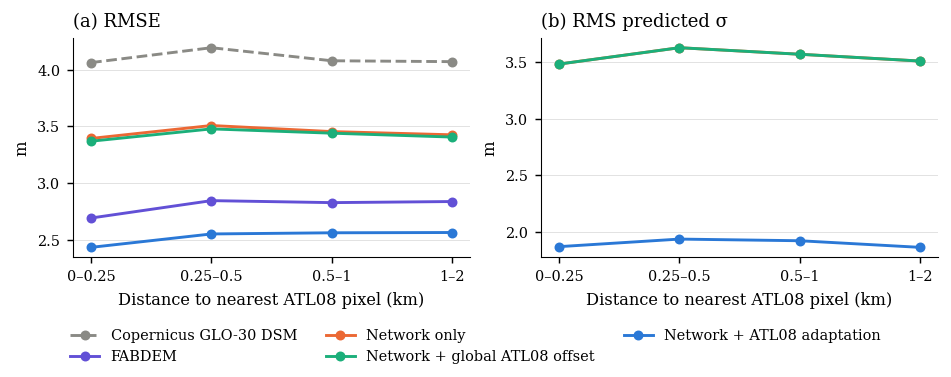

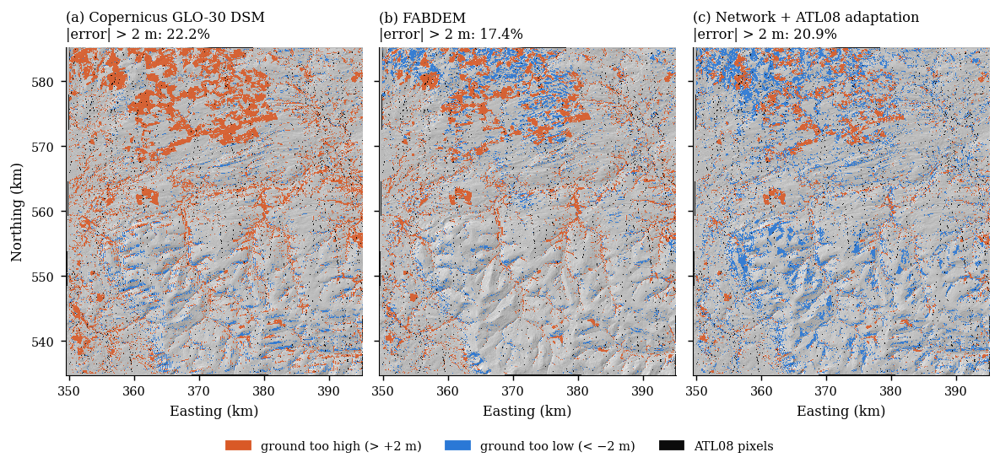

M0: global offset -0.509 m | max |full - network alone| 22.32 m
B4 ridge: 12 cells of 16 km, 12 fitted locally (>= 30 ATL08 px), the rest with the site-wide fit
B5 residual variogram: nugget 3.651 m², partial sill 6.111 m², range parameter 0.59 km (practical range ~1.8 km)
B3 global ATL08 offset -1.130 m
2,471,272 scored pixels in 598 blocks of 2 km | 1000 block-bootstrap resamples
                                Method              RMSE (m)                   ME (m)              NMAD (m)               |e|95 (m)             |e| > 2 m              Cov. 95%              CRPS (m)
B0               Copernicus GLO-30 DSM  4.106 [3.874, 4.355]     1.180 [1.036, 1.342]  1.118 [1.077, 1.169]  10.482 [9.627, 11.458]  0.222 [0.210, 0.235]                     –                     –
B1                              FABDEM  2.779 [2.636, 2.936]     0.203 [0.128, 0.281]  1.003 [0.971, 1.038]    6.001 [5.556, 6.541]  0.174 [0.162, 0.187]                     –                     –
B3    Copernicus + gl

In [ ]:
S_B = dict(B, transform=B["prof"]["transform"], crs=B["prof"]["crs"], stats=STATS_CK)
S_B["bldg"] = np.nan_to_num(read_raster(TILE_1["feat"], 8)[0]).clip(min=0)   # building height (the noise-test B lacks it)
OBS_B = dict(obs_dh=OBS_DH_REAL, obs_mask=OBS_MASK)

P_B = predict_methods(S_B, OBS_B, models={"M0": model}, baselines=BASE_B)
metrics_table(P_B, S_B, OBS_B); canopy_table(P_B, S_B, OBS_B)
plot_distance(P_B, S_B, OBS_B); plot_error_maps(P_B, S_B, OBS_B, methods=["uncorrected DSM", "FABDEM",
                                                 "M0 full"])

P_B = predict_methods(S_B, OBS_B, models={"M0": model}, baselines=BASE_B)    # B0, B1 (FABDEM), B6, Ours
add_classical_baselines(P_B, S_B, OBS_B, atl08_noise_var=0.74 ** 2)         # B3, B4, B5

ROWS = {"B0": "uncorrected DSM", "B1": "FABDEM", "B2": "FathomDEM", "B3": "DSM + ATL08 offset",
        "B4": "ridge regression", "B5": "regression kriging", "B6": "M0 network alone", "Ours": "M0 full"}
T5_B, T5_B_NUM = table5([(P_B, S_B, OBS_B)], ROWS)      # B2 is skipped until FathomDEM exists

In [ ]:
# ========= coregistration =================

import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import shift as nd_shift


def _gradients(z, pixel_m):
    """dz/dEast and dz/dNorth (m/m). Rows run southwards, so dz/dNorth = -dz/drow / pixel."""
    g_row, g_col = np.gradient(z, pixel_m)
    return g_col, -g_row


def shift_dem(dem, dx_m, dy_m, pixel_m):
    """Move the DEM's content by (dx east, dy north) metres, bilinear, NaN kept as NaN."""
    ok = np.isfinite(dem)
    filled = np.where(ok, dem, np.nanmean(dem))
    s = (-dy_m / pixel_m, dx_m / pixel_m)                   # (rows, cols): north = up = fewer rows
    out = nd_shift(filled, s, order=1, mode="nearest")
    ok_s = nd_shift(ok.astype(np.float32), s, order=1, mode="constant", cval=0.0) > 0.999
    return np.where(ok_s, out, np.nan).astype(np.float32)


def _stats(e):
    return dict(rmse=float(np.sqrt(np.mean(e ** 2))), nmad=float(1.4826 * np.median(np.abs(e - np.median(e)))),
                bias=float(np.mean(e)), n=int(e.size))


def coregistration_check(S, dem, name="DEM", ref=None, canopy_max=5.0, slope_min_deg=3.0, slope_max_deg=60.0,
                         n_iter=4, trim_k=3.0, plot=True, save=None):
    """S: site dict. dem: [H, W] array on the site grid (e.g. FABDEM, or S["dsm"] for Copernicus).
    ref: reference surface (default: lidar DTM = DSM + target). Returns dict with dx, dy (m) and stats."""
    z_ref = (S["dsm"] + S["target"]) if ref is None else ref
    ref_ok = S["valid"] if ref is None else np.isfinite(ref)
    z_ref = np.where(ref_ok, z_ref, np.nan).astype(np.float64)
    gE, gN = _gradients(z_ref, S["pixel_m"])                 # NaN next to gaps -> excluded below
    tan_s = np.hypot(gE, gN)
    slope = np.degrees(np.arctan(tan_s))

    # 1) pixels where the DEM should equal the ground: open (low canopy), on a slope (so a shift shows)
    base = (np.isfinite(gE) & np.isfinite(gN) & (S["canopy"] < canopy_max)
            & (slope >= slope_min_deg) & (slope <= slope_max_deg))
    print(f"{name}: {base.sum():,} open-ground slope pixels (canopy < {canopy_max:g} m, "
          f"slope {slope_min_deg:g}-{slope_max_deg:g} deg)")

    def fit(cur):
        """one least-squares fit of e = -dx*gE - dy*gN + c, with outliers trimmed at trim_k * NMAD."""
        e = cur - z_ref
        m = base & np.isfinite(e)
        for _ in range(3):                                   # trim, refit
            A = np.stack([-gE[m], -gN[m], np.ones(m.sum())], 1)
            coef, *_ = np.linalg.lstsq(A, e[m], rcond=None)
            r = e[m] - A @ coef
            nm = 1.4826 * np.median(np.abs(r - np.median(r)))
            keep = np.abs(r - np.median(r)) <= trim_k * max(nm, 1e-3)
            idx = np.flatnonzero(m)
            m = np.zeros_like(m); m.flat[idx[keep]] = True
        return coef[0], coef[1], m

    # 2) iterate: estimate, shift the DEM back by the estimate, estimate what is left
    dem = np.asarray(dem, np.float64)
    dx_tot, dy_tot, cur = 0.0, 0.0, dem
    for it in range(n_iter):
        dx, dy, m_fit = fit(cur)
        dx_tot += dx; dy_tot += dy
        cur = shift_dem(dem, -dx_tot, -dy_tot, S["pixel_m"])    # undo the total shift found so far
        if np.hypot(dx, dy) < 0.05:                              # < 5 cm left: converged
            break

    # 3) before / after on the SAME pixels (open-ground slopes, finite in both)
    e0, e1 = dem - z_ref, cur - z_ref
    same = base & np.isfinite(e0) & np.isfinite(e1) & (np.abs(e0) < 50)
    before, after = _stats(e0[same]), _stats(e1[same])
    d = float(np.hypot(dx_tot, dy_tot))
    print(f"  shift of {name} relative to the reference: dx {dx_tot:+.2f} m east, dy {dy_tot:+.2f} m north "
          f"| |d| {d:.2f} m = {d / S['pixel_m']:.2f} px | {it + 1} iteration(s)")
    print(f"  open-ground slopes: RMSE {before['rmse']:.3f} -> {after['rmse']:.3f} m | "
          f"NMAD {before['nmad']:.3f} -> {after['nmad']:.3f} m | bias {before['bias']:+.3f} -> {after['bias']:+.3f} m")
    verdict = ("aligned (< 0.1 px)" if d < 0.1 * S["pixel_m"] else
               "small shift (0.1-0.3 px)" if d < 0.3 * S["pixel_m"] else
               "clear misregistration (>= 0.3 px): correct before comparing")
    print(f"  -> {verdict}")

    if plot:
        _plot_coreg(e0, e1, gE, gN, tan_s, slope, same, dx_tot, dy_tot, name, save)
    return dict(dx=dx_tot, dy=dy_tot, shift_m=d, shift_px=d / S["pixel_m"], before=before, after=after,
                corrected=cur.astype(np.float32))


def _plot_coreg(e0, e1, gE, gN, tan_s, slope, m, dx, dy, name, save):
    up = (np.degrees(np.arctan2(gE[m], gN[m])) + 360) % 360       # upslope direction, deg clockwise from N
    t = np.where(tan_s[m] > 0.05, tan_s[m], np.nan)
    bins = np.arange(0, 361, 15)
    k = np.digitize(up, bins) - 1
    cen = bins[:-1] + 7.5
    med0 = [np.nanmedian((e0[m] / t)[k == j]) if (k == j).sum() > 50 else np.nan for j in range(len(cen))]
    med1 = [np.nanmedian((e1[m] / t)[k == j]) if (k == j).sum() > 50 else np.nan for j in range(len(cen))]
    th = np.radians(np.arange(0, 361))
    fitted = -(dx * np.sin(th) + dy * np.cos(th))                  # e / tan(slope) predicted by the shift

    s_edges = (3, 5, 10, 15, 20, 30, 60)
    sk = np.digitize(slope[m], s_edges[1:-1])
    nm = lambda e: 1.4826 * np.median(np.abs(e - np.median(e)))
    n0 = [nm(e0[m][sk == j]) if (sk == j).sum() > 200 else np.nan for j in range(len(s_edges) - 1)]
    n1 = [nm(e1[m][sk == j]) if (sk == j).sum() > 200 else np.nan for j in range(len(s_edges) - 1)]

    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.9), constrained_layout=True)
    a1.axhline(0, color="#8a8a85", lw=0.6)
    a1.plot(cen, med0, "o", color="#eb6834", ms=4, label="before")
    a1.plot(np.degrees(th), fitted, "-", color="#eb6834", lw=1.2, label="fitted shift")
    a1.plot(cen, med1, "s", color="#2a78d6", ms=4, label="after correction")
    a1.set_xticks(range(0, 361, 90)); a1.set_xlim(0, 360)
    a1.set_xlabel("Upslope direction (° from north)"); a1.set_ylabel("error / tan(slope) (m)")
    a1.set_title("(a) Error vs terrain aspect"); a1.grid(True, axis="y")
    pos = np.arange(len(s_edges) - 1)
    a2.plot(pos, n0, "o-", color="#eb6834", ms=4, label="before")
    a2.plot(pos, n1, "s-", color="#2a78d6", ms=4, label="after correction")
    a2.set_xticks(pos); a2.set_xticklabels([f"{s_edges[j]}–{s_edges[j + 1]}" for j in pos])
    a2.set_xlabel("Slope (°)"); a2.set_ylabel("NMAD (m)"); a2.set_title("(b) Error spread vs slope")
    a2.grid(True, axis="y")
    h, l = a1.get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=3, frameon=False)
    if save:
        fig.savefig(save); print("saved", save)
    plt.show()


def registration_tag(path):
    """'Area' or 'Point' pixel registration of a GeoTIFF (also inside a zip: a /vsizip/... path)."""
    import rasterio
    with rasterio.open(path) as s:
        return s.tags().get("AREA_OR_POINT", "not set (GDAL assumes Area)")


FABDEM vs lidar: 337,709 open-ground slope pixels (canopy < 5 m, slope 3-60 deg)
  shift of FABDEM vs lidar relative to the reference: dx +0.35 m east, dy +6.39 m north | |d| 6.40 m = 0.21 px | 3 iteration(s)
  open-ground slopes: RMSE 2.264 -> 2.174 m | NMAD 0.801 -> 0.447 m | bias -0.131 -> -0.058 m
  -> small shift (0.1-0.3 px)


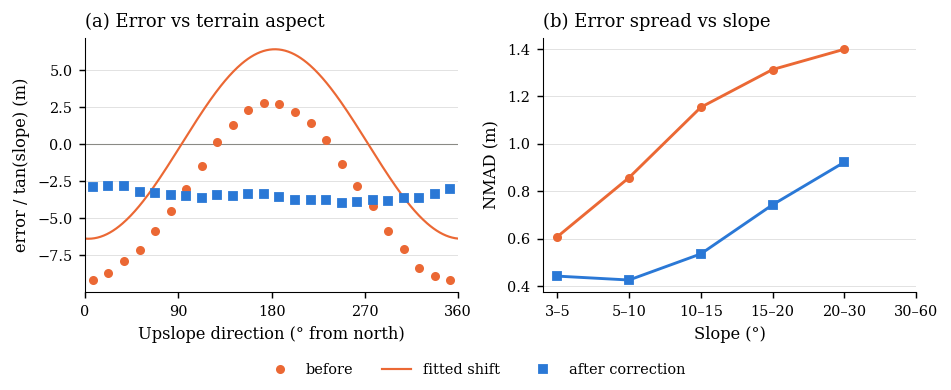

Copernicus DSM vs lidar: 337,709 open-ground slope pixels (canopy < 5 m, slope 3-60 deg)
  shift of Copernicus DSM vs lidar relative to the reference: dx +0.41 m east, dy +4.62 m north | |d| 4.63 m = 0.15 px | 2 iteration(s)
  open-ground slopes: RMSE 3.506 -> 3.455 m | NMAD 1.097 -> 1.049 m | bias +0.368 -> +0.420 m
  -> small shift (0.1-0.3 px)


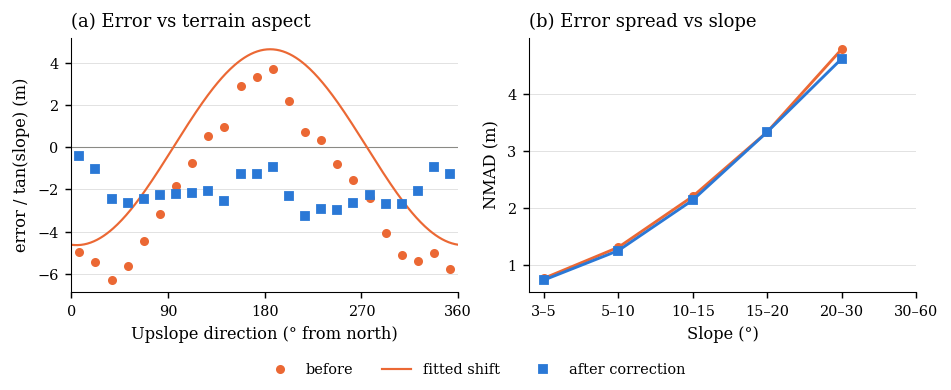

FABDEM vs Copernicus DSM: 343,148 open-ground slope pixels (canopy < 5 m, slope 3-60 deg)
  shift of FABDEM vs Copernicus DSM relative to the reference: dx -0.04 m east, dy +1.47 m north | |d| 1.47 m = 0.05 px | 3 iteration(s)
  open-ground slopes: RMSE 2.143 -> 2.136 m | NMAD 1.113 -> 1.109 m | bias -0.525 -> -0.508 m
  -> aligned (< 0.1 px)


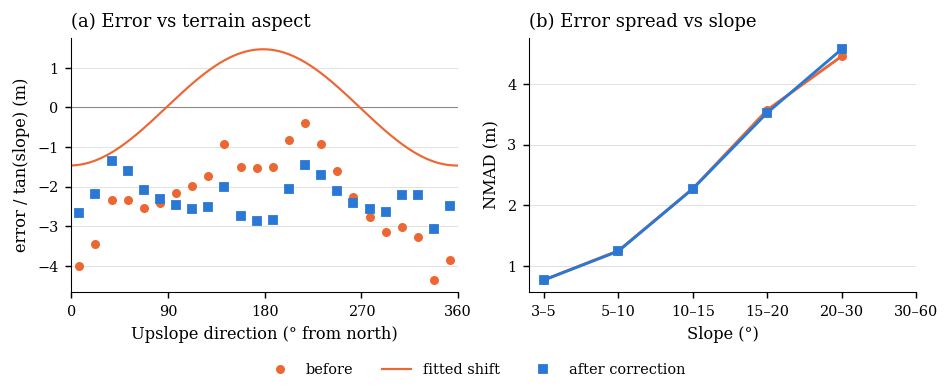

FABDEM: Point | stack: Area


In [ ]:
fab = _read_baseline(BASE_B["FABDEM"], S_B)
CR_FAB  = coregistration_check(S_B, fab, "FABDEM vs lidar")
CR_DSM  = coregistration_check(S_B, S_B["dsm"], "Copernicus DSM vs lidar")
CR_FvsC = coregistration_check(S_B, fab, "FABDEM vs Copernicus DSM", ref=S_B["dsm"])

idx = index_zips(FABDEM_ZIPS)
print("FABDEM:", registration_tag(next(iter(idx.values()))), "| stack:", registration_tag(TILE_1["feat"]))

FABDEM vs Copernicus: 343,148 open-ground slope pixels (canopy < 5 m, slope 3-60 deg)
  shift of FABDEM vs Copernicus relative to the reference: dx -0.04 m east, dy +1.47 m north | |d| 1.47 m = 0.05 px | 3 iteration(s)
  open-ground slopes: RMSE 2.143 -> 2.136 m | NMAD 1.113 -> 1.109 m | bias -0.525 -> -0.508 m
  -> aligned (< 0.1 px)


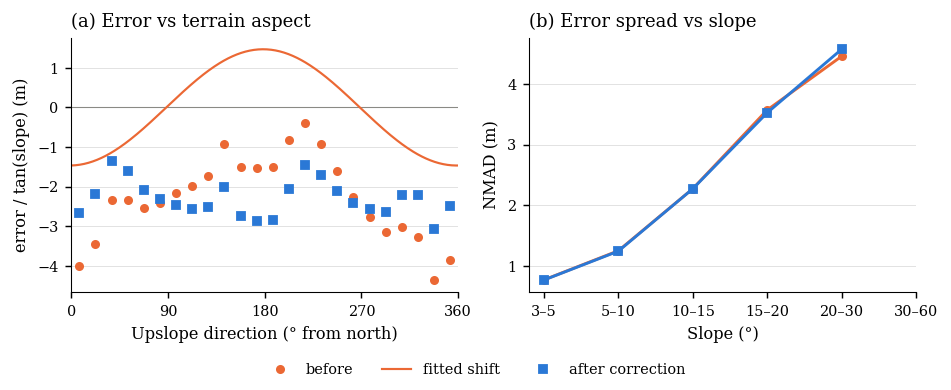

Copernicus DSM vs LiDAR: 337,709 open-ground slope pixels (canopy < 5 m, slope 3-60 deg)
  shift of Copernicus DSM vs LiDAR relative to the reference: dx +0.41 m east, dy +4.62 m north | |d| 4.63 m = 0.15 px | 2 iteration(s)
  open-ground slopes: RMSE 3.506 -> 3.455 m | NMAD 1.097 -> 1.049 m | bias +0.368 -> +0.420 m
  -> small shift (0.1-0.3 px)


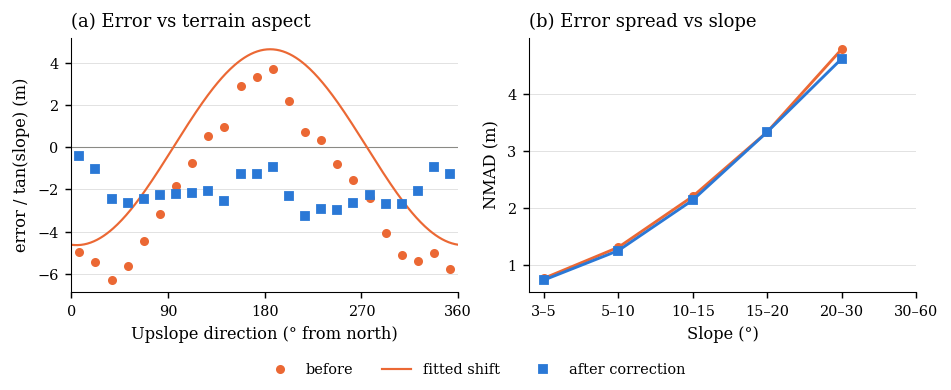

FABDEM vs LiDAR: 337,709 open-ground slope pixels (canopy < 5 m, slope 3-60 deg)
  shift of FABDEM vs LiDAR relative to the reference: dx +0.35 m east, dy +6.39 m north | |d| 6.40 m = 0.21 px | 3 iteration(s)
  open-ground slopes: RMSE 2.263 -> 2.173 m | NMAD 0.801 -> 0.447 m | bias -0.131 -> -0.058 m
  -> small shift (0.1-0.3 px)


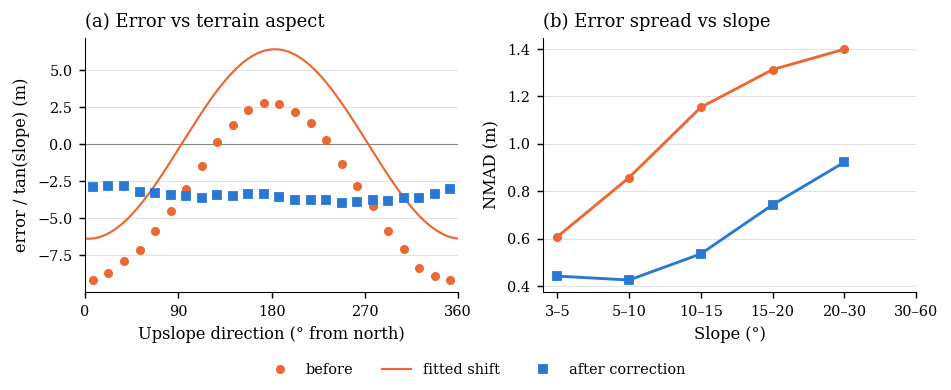

Ours (M0 full) vs LiDAR: 337,709 open-ground slope pixels (canopy < 5 m, slope 3-60 deg)
  shift of Ours (M0 full) vs LiDAR relative to the reference: dx -0.02 m east, dy +1.68 m north | |d| 1.68 m = 0.06 px | 2 iteration(s)
  open-ground slopes: RMSE 2.420 -> 2.400 m | NMAD 1.026 -> 1.022 m | bias -0.365 -> -0.345 m
  -> aligned (< 0.1 px)


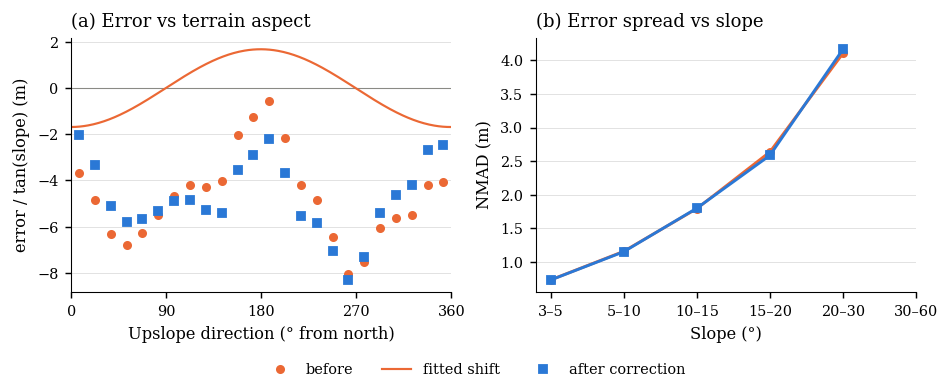

,dx_m,dy_m,shift_m,shift_px,nmad_before,nmad_after
Copernicus DSM,0.406,4.617,4.635,0.154,1.097,1.049
FABDEM,0.347,6.394,6.403,0.213,0.801,0.447
Ours (M0 full),-0.016,1.684,1.684,0.056,1.026,1.022


In [ ]:
import pandas as pd
DSM_B = np.where(S_B["dsm_ok"], S_B["dsm"], np.nan)
SURF_B = {"Copernicus DSM": DSM_B,
          "FABDEM": DSM_B + P_B["FABDEM"]["mu"],          # P stores surface - DSM
          "Ours (M0 full)": DSM_B + P_B["M0 full"]["mu"]}

# (1) registration check that never touches the LiDAR
CR_FC = coregistration_check(S_B, SURF_B["FABDEM"], "FABDEM vs Copernicus", ref=DSM_B)

# (2) the same check, same settings, for every surface against the LiDAR (diagnostic only)
CR_B = {k: coregistration_check(S_B, v, f"{k} vs LiDAR") for k, v in SURF_B.items()}
pd.DataFrame({k: dict(dx_m=r["dx"], dy_m=r["dy"], shift_m=r["shift_m"], shift_px=r["shift_px"],
                      nmad_before=r["before"]["nmad"], nmad_after=r["after"]["nmad"])
              for k, r in CR_B.items()}).T.round(3)

In [ ]:
P_B["DSM co-reg."]    = dict(mu=CR_B["Copernicus DSM"]["corrected"] - DSM_B, sigma=None)
P_B["FABDEM co-reg."] = dict(mu=CR_B["FABDEM"]["corrected"] - DSM_B, sigma=None)
P_B["Ours co-reg."]   = dict(mu=CR_B["Ours (M0 full)"]["corrected"] - DSM_B, sigma=P_B["M0 full"]["sigma"])
ROWS_CR = {"B0": "uncorrected DSM", "B0 co-reg.": "DSM co-reg.", "B1": "FABDEM", "B1 co-reg.": "FABDEM co-reg.",
           "Ours": "M0 full", "Ours co-reg.": "Ours co-reg."}
T5_CR, _ = table5([(P_B, S_B, OBS_B)], ROWS_CR)

2,466,612 scored pixels in 598 blocks of 2 km | 1000 block-bootstrap resamples
                                  Method              RMSE (m)                   ME (m)              NMAD (m)               |e|95 (m)             |e| > 2 m              Cov. 95%              CRPS (m)
B0                 Copernicus GLO-30 DSM  4.104 [3.873, 4.354]     1.178 [1.034, 1.340]  1.116 [1.075, 1.165]  10.475 [9.609, 11.418]  0.221 [0.210, 0.235]                     –                     –
B0 co-reg.                   DSM co-reg.  4.030 [3.796, 4.278]     1.162 [1.021, 1.326]  1.090 [1.045, 1.131]  10.343 [9.452, 11.273]  0.211 [0.199, 0.225]                     –                     –
B1                                FABDEM  2.774 [2.632, 2.932]     0.200 [0.125, 0.278]  1.002 [0.969, 1.036]    5.989 [5.536, 6.525]  0.174 [0.162, 0.187]                     –                     –
B1 co-reg.                FABDEM co-reg.  2.723 [2.581, 2.883]     0.176 [0.102, 0.253]  0.767 [0.738, 0.807]    5.951 [5

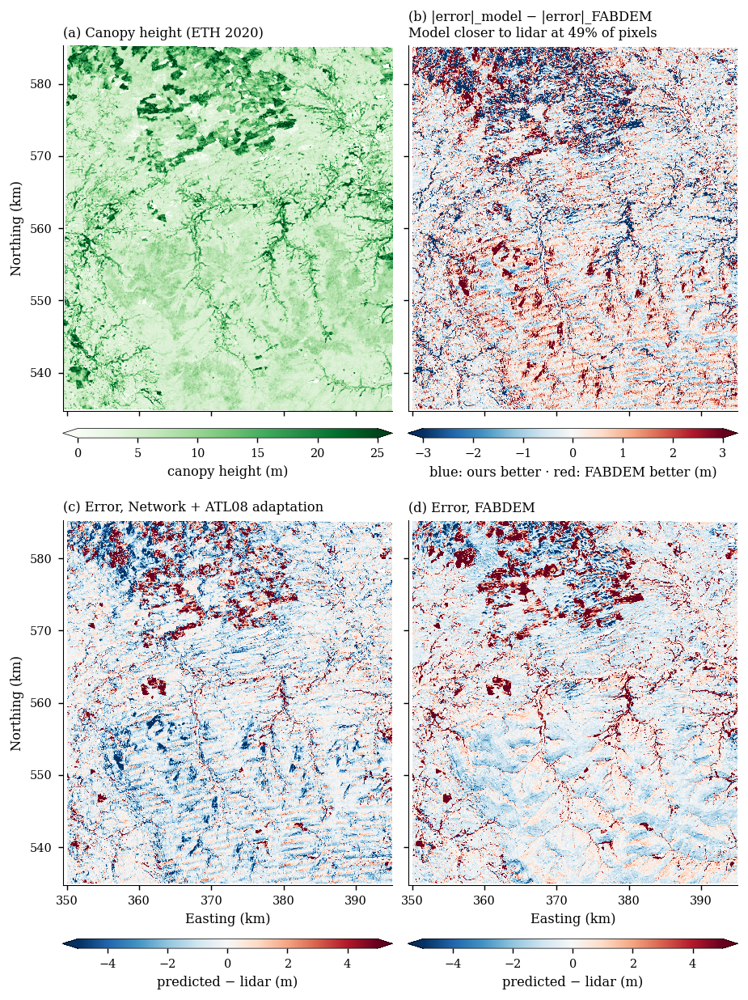

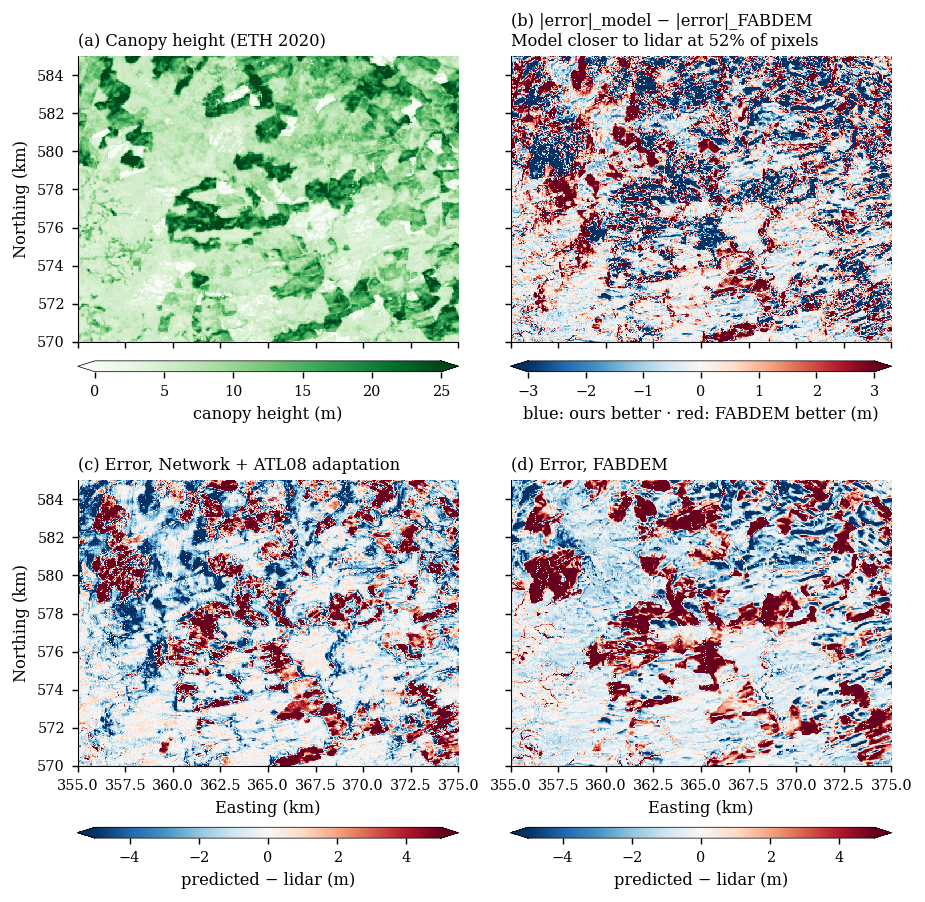

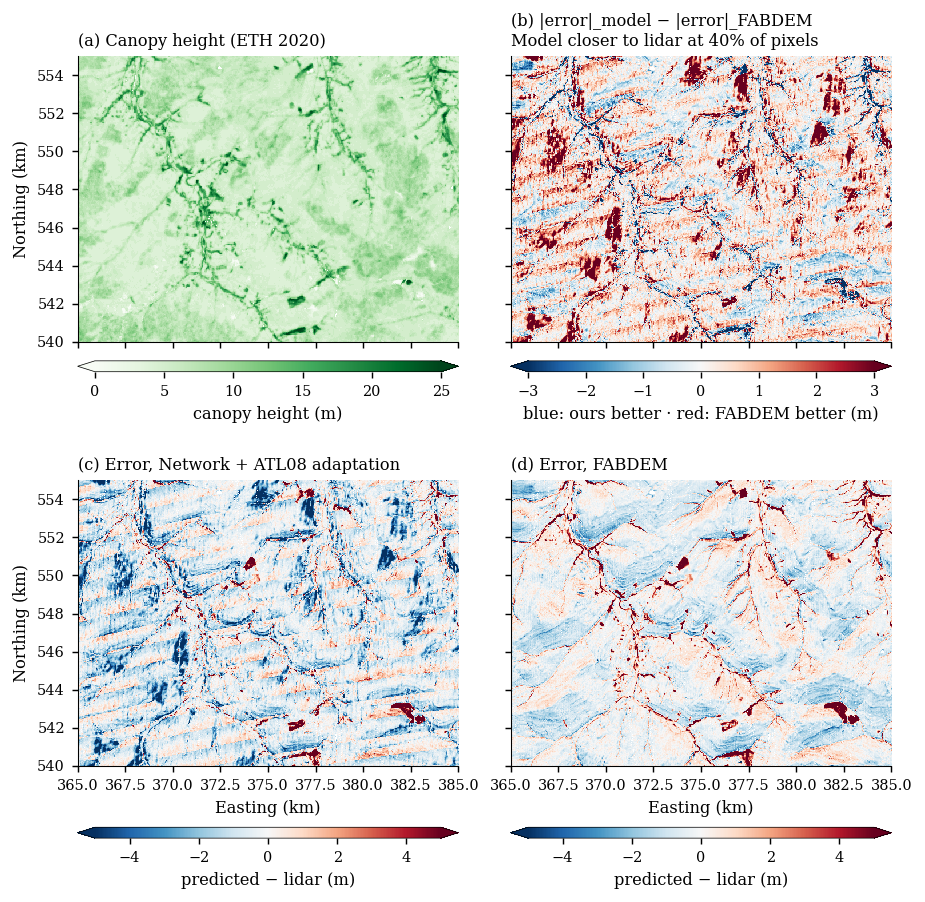

In [ ]:
def plot_canopy_error_2x2(P, S, OBS, ours="M0 full", other="FABDEM", window_km=None,
                          err_lim=5.0, diff_lim=3.0, canopy_max=25.0, save=None):
    sel = _score_mask(S, OBS, P) & _window_mask(S, window_km)            # same scored pixels everywhere
    e_ours = np.where(sel, P[ours]["mu"] - S["target"], np.nan)
    e_oth = np.where(sel, P[other]["mu"] - S["target"], np.nan)
    diff = np.abs(e_ours) - np.abs(e_oth)                               # < 0: ours closer to the lidar
    better = np.mean(diff[sel] < 0)
    can = np.where(S["dsm_ok"], S["canopy"], np.nan)
    ext = _extent_km(S)

    panels = [
        ("(a) Canopy height (ETH 2020)", can, "Greens", 0, canopy_max, "canopy height (m)"),
        (f"(b) |error|_model − |error|_{_label(other, False)}\nModel closer to lidar at {better:.0%} of pixels",
         diff, "RdBu_r", -diff_lim, diff_lim, f"blue: ours better · red: {_label(other, False)} better (m)"),
        (f"(c) Error, {_label(ours, False)}", e_ours, "RdBu_r", -err_lim, err_lim, "predicted − lidar (m)"),
        (f"(d) Error, {_label(other, False)}", e_oth, "RdBu_r", -err_lim, err_lim, "predicted − lidar (m)"),
    ]
    a = _map_aspect(S, window_km)
    fig, axes = plt.subplots(2, 2, figsize=(7.0, 7.0 * a + 1.6), constrained_layout=True)
    for i, (ax, (t, arr, cmap, v0, v1, cb_lab)) in enumerate(zip(axes.ravel(), panels)):
        im = ax.imshow(arr, cmap=cmap, vmin=v0, vmax=v1, extent=ext, interpolation="nearest")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03, aspect=35, extend="both")
        cb.set_label(cb_lab); cb.outline.set_linewidth(0.4)
        ax.set_title(t, fontsize=9)
        ax.tick_params(labelbottom=(i >= 2), labelleft=(i % 2 == 0))
        if i % 2 == 0: ax.set_ylabel("Northing (km)")
        if i >= 2: ax.set_xlabel("Easting (km)")
        if window_km is not None:
            ax.set_xlim(window_km[0], window_km[1]); ax.set_ylim(window_km[2], window_km[3])
        ax.set_aspect("equal")
    if save:
        fig.savefig(save); print("saved", save)
    plt.show()


paper_style()
plot_canopy_error_2x2(P_B, S_B, OBS_B)                                           # whole site B
plot_canopy_error_2x2(P_B, S_B, OBS_B, window_km=(355, 375, 570, 585))           # forest window (north)
plot_canopy_error_2x2(P_B, S_B, OBS_B, window_km=(365, 385, 540, 555))           # open uplands (south)


In [ ]:
sel = _score_mask(S_B, OBS_B, P_B)
em = np.abs(P_B["M0 full"]["mu"] - S_B["target"])[sel]
ef = np.abs(P_B["FABDEM"]["mu"] - S_B["target"])[sel]
c = S_B["canopy"][sel]
for lo, hi in zip((0, 2, 5, 10, 20), (2, 5, 10, 20, np.inf)):
    m = (c >= lo) & (c < hi)
    print(f"{lo:g}-{hi:g} m | n {m.sum():9,d} | ours better at {np.mean(em[m] < ef[m]):4.0%} of pixels | "
          f"mean |e| ours {em[m].mean():.2f} vs FABDEM {ef[m].mean():.2f} | "
          f"wins by > 3 m: ours {np.mean(ef[m] - em[m] > 3):5.1%}, FABDEM {np.mean(em[m] - ef[m] > 3):5.1%}")

0-2 m | n    34,795 | ours better at  52% of pixels | mean |e| ours 2.50 vs FABDEM 2.39 | wins by > 3 m: ours  7.8%, FABDEM  9.1%
2-5 m | n   476,987 | ours better at  50% of pixels | mean |e| ours 0.97 vs FABDEM 0.89 | wins by > 3 m: ours  0.9%, FABDEM  1.9%
5-10 m | n 1,401,898 | ours better at  47% of pixels | mean |e| ours 1.23 vs FABDEM 1.05 | wins by > 3 m: ours  1.7%, FABDEM  3.6%
10-20 m | n   462,032 | ours better at  53% of pixels | mean |e| ours 2.17 vs FABDEM 2.50 | wins by > 3 m: ours 13.1%, FABDEM  8.0%
20-inf m | n    90,900 | ours better at  68% of pixels | mean |e| ours 3.60 vs FABDEM 5.64 | wins by > 3 m: ours 38.1%, FABDEM  9.9%


###All the test plots from training moved to here (Site B)

In [ ]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import distance_transform_edt


# ----------  a band of the site's stack that prepare_site does not keep (e.g. building height) ----------
def site_band(site, band, box=None):
    """One band (1-based) of the site's aligned stack, NaN where invalid, cut to `box` like prepare_site."""
    a, ok, _ = read_raster(site["feat"], band)
    a = np.where(ok, a, np.nan).astype(np.float32)
    if box is not None:
        y0, x0, y1, x1 = box
        a = a[y0:y1, x0:x1]
    return a



def site_block_table(P, S, OBS, methods=("M0 full", "FABDEM"), block_km=5.0, tall_m=5.0, bldg=None,
                     bldg_m=2.0, min_valid=0.1):
    """Per block of block_km: landscape (tall-canopy share, building share, elevation, std of true Δh)
    and per method RMSE / bias (+ RMS σ and cover95 where the method has σ). Same scored pixels for all
    methods (valid lidar, off the ATL08 pixels). Returns a DataFrame and prints a short summary."""
    methods = [m for m in methods if m in P]
    sel = _score_mask(S, OBS, P)
    B = int(round(block_km * 1000 / S["pixel_m"]))
    rows = []
    for by in range(0, S["H"], B):
        for bx in range(0, S["W"], B):
            sl = (slice(by, by + B), slice(bx, bx + B))
            ok = sel[sl]
            if ok.sum() < min_valid * B * B:
                continue
            c = S["canopy"][sl][S["dsm_ok"][sl]]
            r = dict(by=by, bx=bx, n=int(ok.sum()), canopy_frac=float(np.mean(c > tall_m)),
                     elev=float(S["dsm"][sl][S["dsm_ok"][sl]].mean()), dh_std=float(S["target"][sl][ok].std()))
            if bldg is not None:
                b = bldg[sl][np.isfinite(bldg[sl])]
                r["bldg_frac"] = float(np.mean(b > bldg_m)) if b.size else np.nan
            for name in methods:
                e = (P[name]["mu"][sl] - S["target"][sl])[ok]
                r[f"rmse | {name}"] = float(np.sqrt(np.mean(e ** 2)))
                r[f"bias | {name}"] = float(np.mean(e))
                if P[name]["sigma"] is not None:
                    s = P[name]["sigma"][sl][ok].astype(np.float64)
                    r[f"rms_sigma | {name}"] = float(np.sqrt(np.mean(s ** 2)))
                    r[f"cover95 | {name}"] = float(np.mean(np.abs(e) <= 1.96 * s))
            rows.append(r)
    df = pd.DataFrame(rows)
    df.attrs.update(B=B, block_km=block_km, tall_m=tall_m, methods=methods)
    print(f"{len(df)} blocks of {block_km:g} km ({B} px) with >= {min_valid:.0%} scored pixels")
    if len(methods) >= 2:
        a, b = methods[0], methods[1]
        d = df[f"rmse | {a}"] - df[f"rmse | {b}"]
        print(f"{_label(a, False)} lower RMSE than {_label(b, False)} in {(d < 0).sum()} of {len(df)} blocks "
              f"(median difference {d.median():+.2f} m)")
    cols = ["canopy_frac"] + (["bldg_frac"] if bldg is not None else []) + ["elev", "dh_std"] + \
           [c for c in df.columns if c.startswith(("rmse |", "rms_sigma |", "cover95 |"))]
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 160):
        print(df[cols].describe().loc[["mean", "50%", "min", "max"]].rename(index={"50%": "median"}).to_string())
    return df


def _block_grid(df, S, key):
    B = df.attrs["B"]
    g = np.full((math.ceil(S["H"] / B), math.ceil(S["W"] / B)), np.nan)
    for _, r in df.iterrows():
        g[int(r["by"]) // B, int(r["bx"]) // B] = r[key]
    return g


def _block_extent(df, S):
    """Extent of the block grid in km (the last row / column of blocks may reach past the site edge)."""
    T, B = S["transform"], df.attrs["B"]
    nby, nbx = math.ceil(S["H"] / B), math.ceil(S["W"] / B)
    x0, y0 = T.c, T.f
    return (x0 / 1000, (x0 + nbx * B * T.a) / 1000, (y0 + nby * B * T.e) / 1000, y0 / 1000)


# ---------- 2) block maps, one row ---------------------------------------------------------------------------
def plot_block_maps(df, S, ours="M0 full", other="FABDEM", rmse_max=None, diff_lim=2.0, save=None):
    """(a) share of tall canopy, (b) RMSE ours, (c) RMSE other, (d) RMSE ours − other (blue: ours better)."""
    methods = df.attrs["methods"]
    has_other = other in methods
    ext = _block_extent(df, S)
    vmax = rmse_max or float(np.nanpercentile(
        df[[c for c in (f"rmse | {ours}", f"rmse | {other}") if c in df]].to_numpy(), 98))
    panels = [(f"Share of canopy > {df.attrs['tall_m']:g} m", _block_grid(df, S, "canopy_frac"), "Greens", 0, 1, "share"),
              (f"RMSE, {_label(ours, False)}", _block_grid(df, S, f"rmse | {ours}"), "magma_r", 0, vmax, "m")]
    if has_other:
        panels += [(f"RMSE, {_label(other, False)}", _block_grid(df, S, f"rmse | {other}"), "magma_r", 0, vmax, "m"),
                   ("RMSE difference (Model − " + _label(other, False) + ")",
                    _block_grid(df, S, f"rmse | {ours}") - _block_grid(df, S, f"rmse | {other}"),
                    "RdBu_r", -diff_lim, diff_lim, "m (blue: ours better)")]
    a = S["H"] / S["W"]
    fig, axes = plt.subplots(1, len(panels), figsize=(2.9 * len(panels), 2.9 * a + 1.0), squeeze=False,
                             constrained_layout=True)
    for i, (ax, (t, g, cmap, v0, v1, unit)) in enumerate(zip(axes[0], panels)):
        im = ax.imshow(g, cmap=cmap, vmin=v0, vmax=v1, extent=ext, interpolation="nearest")
        cb = fig.colorbar(im, ax=ax, orientation="horizontal", fraction=0.05, pad=0.03, aspect=30)
        cb.set_label(unit); cb.outline.set_linewidth(0.4)
        ax.set_title(f"({PANEL[i]}) {t}", fontsize=9)
        ax.set_xlim(ext[0], S["transform"].c / 1000 + S["W"] * S["pixel_m"] / 1000)
        ax.set_ylim(S["transform"].f / 1000 - S["H"] * S["pixel_m"] / 1000, ext[3])
        ax.set_xlabel("Easting (km)")
        if i == 0:
            ax.set_ylabel("Northing (km)")
        else:
            ax.tick_params(labelleft=False)
        ax.set_aspect("equal")
    _save(fig, save); plt.show()


# ---------- block scatter: error vs canopy, and calibration ---------------------------------------------------
def plot_block_scatter(df, ours="M0 full", save=None):
    """(a) block RMSE vs share of tall canopy, one colour per method; (b) block RMSE vs RMS σ for the
    methods with σ (on the dashed line = honest σ, above = overconfident)."""
    methods = df.attrs["methods"]
    multi = False
    sig_methods = [m for m in methods if f"rms_sigma | {m}" in df]
    fig, axes = plt.subplots(1, 2 if sig_methods else 1, figsize=(7.2 if sig_methods else 3.8, 3.1),
                             squeeze=False, constrained_layout=True)
    a1 = axes[0][0]
    for name in methods:
        st = _site_style(name, _models_from(methods))
        a1.scatter(df["canopy_frac"], df[f"rmse | {name}"], s=18, color=st["color"], marker=st["marker"],
                   edgecolor="white", linewidth=0.5, label=_label(name, multi))
    a1.set_xlabel(f"Share of canopy > {df.attrs['tall_m']:g} m in block"); a1.set_ylabel("Block RMSE (m)")
    a1.set_title("(a) Block error vs canopy cover"); a1.grid(True)
    if sig_methods:
        a2 = axes[0][1]
        lim = 1.1 * float(np.nanmax(np.concatenate([df[f"rmse | {m}"].to_numpy() for m in sig_methods] +
                                                   [df[f"rms_sigma | {m}"].to_numpy() for m in sig_methods])))
        a2.plot([0, lim], [0, lim], color="#8a8a85", ls="--", lw=1, label="RMSE = RMS σ")
        for name in sig_methods:
            st = _site_style(name, _models_from(methods))
            a2.scatter(df[f"rms_sigma | {name}"], df[f"rmse | {name}"], s=18, color=st["color"],
                       marker=st["marker"], edgecolor="white", linewidth=0.5)
        a2.set_xlim(0, lim); a2.set_ylim(0, lim); a2.set_aspect("equal")
        a2.set_xlabel("Block RMS predicted σ (m)"); a2.set_ylabel("Block RMSE (m)")
        a2.set_title("(b) Block calibration"); a2.grid(True)
    h, l = a1.get_legend_handles_labels()
    if sig_methods:
        h2, l2 = axes[0][1].get_legend_handles_labels(); h, l = h + h2, l + l2
    fig.legend(h, l, loc="outside lower center", ncol=min(len(h), 3), frameon=False)
    _save(fig, save); plt.show()


def _models_from(methods):
    out = []
    for n in methods:
        for r in (" network alone", " + global offset", " full"):
            if n.endswith(r) and n[: -len(r)] not in out:
                out.append(n[: -len(r)])
    return out


# ---------- 4) canopy distribution of the site (optionally against other areas) -----------------------------------
def plot_canopy_hist(S, OBS, others=None, max_m=40, label="Site", save=None):
    """Density of canopy height over the site's scored pixels; others = {"Tile A (training)": array, ...}
    adds the distribution of other areas (e.g. the training area) to show any shift between them."""
    sel = S["valid"] & ~OBS["obs_mask"]
    series = {label: S["canopy"][sel]}
    for k, v in (others or {}).items():
        series[k] = np.asarray(v)[np.isfinite(v)]
    bins = np.linspace(0, max_m, 81)
    cols = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]
    fig, ax = plt.subplots(figsize=(4.6, 2.9), constrained_layout=True)
    for (k, v), c in zip(series.items(), cols):
        ax.hist(np.clip(v, 0, max_m), bins=bins, density=True, histtype="step", lw=1.6, color=c,
                label=f"{k} (median {np.median(v):.1f} m)")
    ax.set_yscale("log"); ax.set_xlabel("Canopy height (m)"); ax.set_ylabel("Density (log)"); ax.grid(True)
    fig.legend(loc="outside lower center", ncol=min(len(series), 2), frameon=False)
    _save(fig, save); plt.show()


# ----------  error across the edges of tall objects ----------------------------------------------------------------
# CHANGED: plot_edge_profile -> plot_edge_profiles: one 2 x 2 figure (rows = edge types, e.g. buildings and canopy;
# columns = RMSE (+ RMS σ, dotted) | mean error), same layout and colours as the site A figure.
def _edge_signed(layer, thresh_m):
    v = np.where(np.isfinite(layer), layer, 0.0)
    tall = v > thresh_m
    return np.where(tall, distance_transform_edt(tall), -distance_transform_edt(~tall))


def plot_edge_profiles(P, S, OBS, layers, methods=("M0 full", "FABDEM"), max_px=30, rf_px=13, min_px=200, save=None):
    """layers: [(array, thresh_m, name), ...], e.g. [(BLDG_B, 2.0, "building"), (S_B["canopy"], 5.0, "canopy")].
    Per edge type: RMSE (and RMS σ, dotted, where the method has σ) and mean error against the signed distance
    to the nearest edge (px; > 0 inside), per method, on the scored pixels (same pixels for every method).
    Grey band: within ±rf_px//2 px of the edge the 13 x 13 receptive field sees both sides."""
    methods = [m for m in methods if m in P]
    order = _models_from(methods)
    half = rf_px // 2
    fig, axes = plt.subplots(len(layers), 2, figsize=(7.4, 2.6 * len(layers) + 0.7), constrained_layout=True,
                             squeeze=False)
    handles = {}
    for r, (layer, thresh_m, name) in enumerate(layers):
        signed = _edge_signed(layer, thresh_m)
        sel = _score_mask(S, OBS, P) & (np.abs(signed) <= max_px)
        d = np.round(signed[sel]).astype(int)
        ks = [k for k in range(-max_px, max_px + 1) if (d == k).sum() >= min_px]
        a1, a2 = axes[r]
        for ax in (a1, a2):
            ax.axvspan(-half, half, color="#8a8a85", alpha=0.15, lw=0)
            ax.axvline(0, color="#1a1a19", lw=0.8)
            ax.set_xlabel(f"Distance to {name} edge (px, > 0 inside)"); ax.set_ylabel("m"); ax.grid(True, axis="y")
            ax.set_xlim(min(min(ks), -half) - 2, max(max(ks), half) + 2)   # the distances that have data
        a2.axhline(0, color="#1a1a19", lw=0.8)
        for m in methods:
            st = _site_style(m, order); lab = _label(m, False)
            e = (P[m]["mu"] - S["target"])[sel]
            h, = a1.plot(ks, [np.sqrt(np.mean(e[d == k] ** 2)) for k in ks], color=st["color"], marker="o", ms=2.5, lw=1.4)
            a2.plot(ks, [np.mean(e[d == k]) for k in ks], color=st["color"], marker="o", ms=2.5, lw=1.4)
            handles.setdefault(f"{lab} RMSE", h)
            if P[m]["sigma"] is not None:
                sg = P[m]["sigma"][sel].astype(np.float64)
                h2, = a1.plot(ks, [np.sqrt(np.mean(sg[d == k] ** 2)) for k in ks], color=st["color"], ls=":",
                              lw=1.6, alpha=0.8)
                handles.setdefault(f"{lab} RMS σ", h2)
        cap = name.capitalize()
        a1.set_title(f"({PANEL[2 * r]}) {cap} edges (> {thresh_m:g} m): RMSE", fontsize=9)
        a2.set_title(f"({PANEL[2 * r + 1]}) {cap} edges: mean error (> 0: ground too high)", fontsize=9)
        print(f"{cap} edges > {thresh_m:g} m: {sel.sum():,} scored px within ±{max_px} px | "
              f"distances drawn {min(ks)} to {max(ks)} px (classes with >= {min_px} px)")
    # legend order as at site A: ours RMSE, ours RMS σ (column 1); other methods, receptive field (column 2)
    keys = [k for k in handles if k.endswith("RMSE") or k.endswith("RMS σ")]
    first = [k for k in keys if k.startswith(_label(methods[0], False))]
    rest = [k for k in keys if k not in first]
    h = [handles[k] for k in first + rest]
    h.append(plt.Rectangle((0, 0), 1, 1, color="#8a8a85", alpha=0.3, label=f"receptive field ({rf_px}×{rf_px}) spans the edge"))
    fig.legend(h, first + rest + [h[-1].get_label()], loc="outside lower center", ncol=2, frameon=False)
    _save(fig, save); plt.show()

91 blocks of 5 km (167 px) with >= 10% scored pixels
Network + ATL08 adaptation lower RMSE than FABDEM in 54 of 91 blocks (median difference -0.22 m)
        canopy_frac  bldg_frac    elev  dh_std  rmse | M0 full  rms_sigma | M0 full  cover95 | M0 full  rmse | FABDEM
mean          0.577      0.067 285.290   3.362           2.344                1.851              0.927          2.531
median        0.576      0.059 260.205   3.214           2.063                1.792              0.949          2.321
min           0.289      0.003  61.921   1.163           1.081                1.014              0.729          0.834
max           0.951      0.285 581.482   6.716           4.749                3.060              0.983          5.292


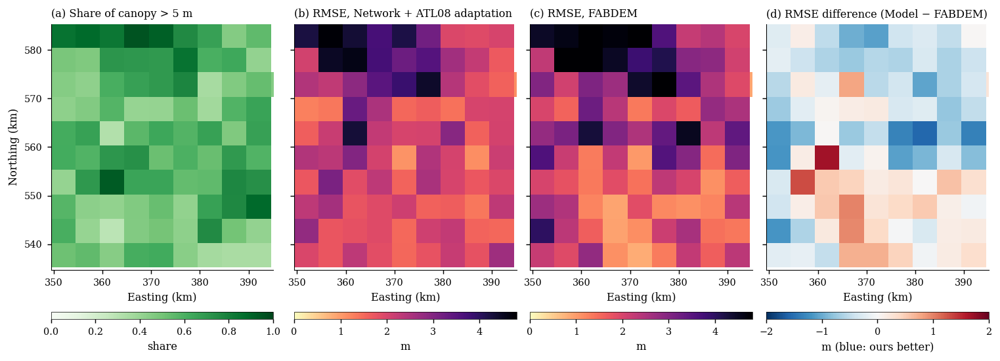

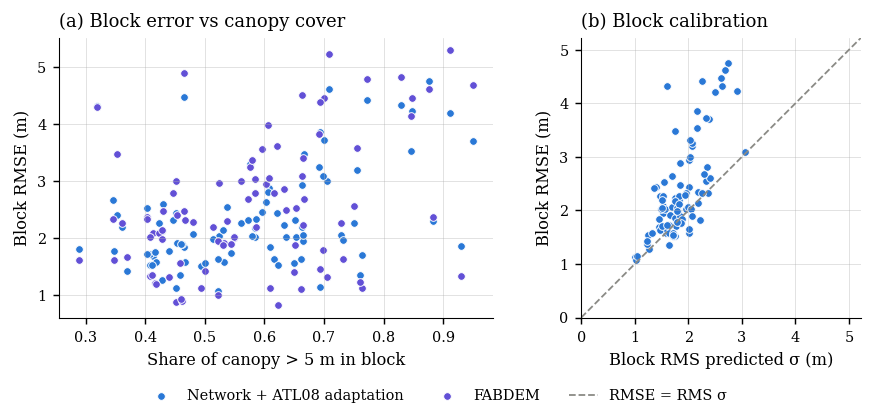

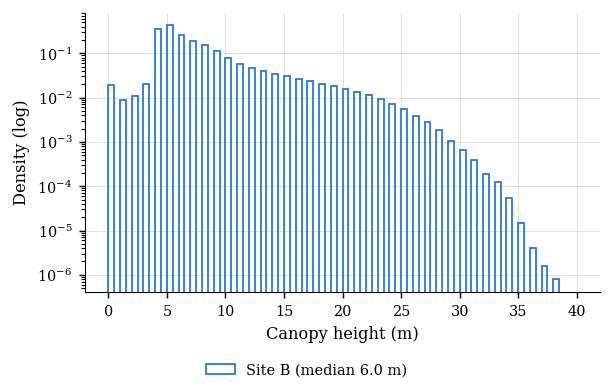

Building edges > 2 m: 2,001,002 scored px within ±30 px | distances drawn -30 to 13 px (classes with >= 200 px)
Canopy edges > 5 m: 2,461,817 scored px within ±30 px | distances drawn -21 to 30 px (classes with >= 200 px)


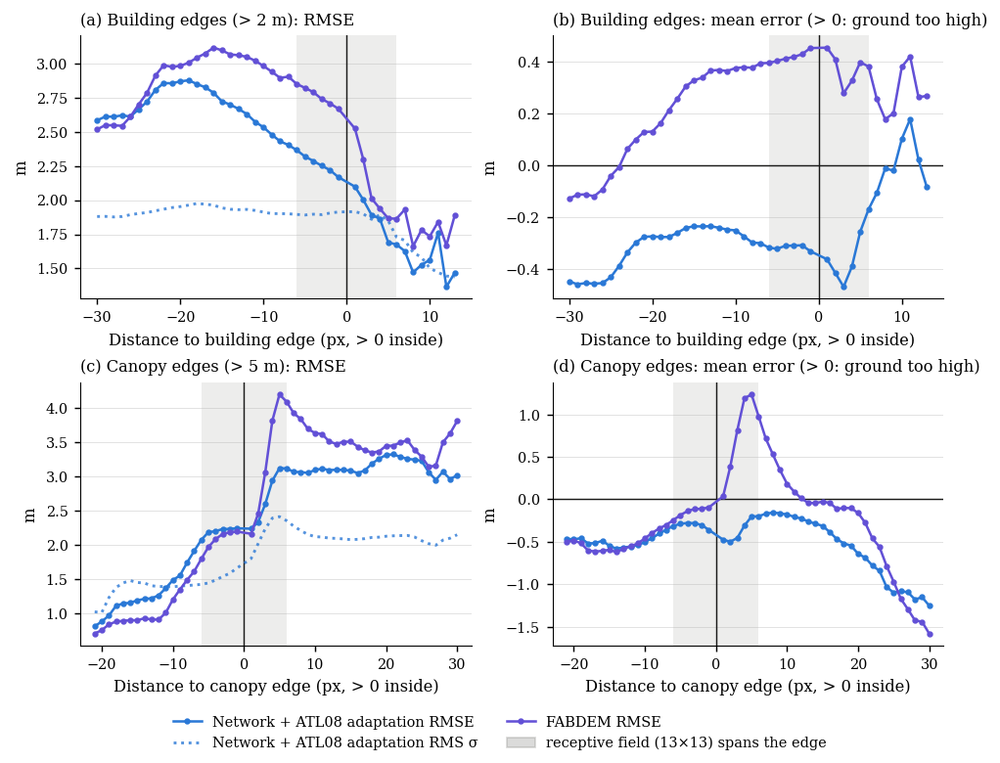

In [ ]:
paper_style()
BLDG_B = site_band(TILE_1, 8)

DF_B = site_block_table(P_B, S_B, OBS_B, bldg=BLDG_B)
plot_block_maps(DF_B, S_B)
plot_block_scatter(DF_B)
plot_canopy_hist(S_B, OBS_B, label="Site B")

plot_edge_profiles(P_B, S_B, OBS_B, [(BLDG_B, 2.0, "building"), (S_B["canopy"], 5.0, "canopy")])

In [ ]:
# ===== Table 5, "Simulated context" rows: tile A test blocks with simulated ICESat =====
F_C = globals().get("F_CANOPY", 4)          # canopy band index in `features` (0-based; band 5 of the stack)
F_B = globals().get("F_BLDG", 7)            # building-height band index (band 8 of the stack)
CANOPY_A = np.where(features_valid[F_C], features[F_C], 0.0)
BLDG_A   = np.where(features_valid[F_B], features[F_B], 0.0)

TEST_A = TEST_SET[1:]                       # the 3 held-out blocks with simulated tracks (block 0 has none)
ITEMS_A = episode_items(model, TEST_A, CANOPY_A, BLDG_A,
                        raw_dsm=RAW_DSM, transform_full=DSM_PROFILE["transform"],
                        atl08_noise_var=1.0)                # simulated tracks: Gaussian 1.0 m noise

ROWS_SIM = {"B0": "uncorrected DSM", "B4": "ridge regression",
            "B6": "M0 network alone", "Ours": "M0 full"}
T5_A, T5_A_NUM = table5(ITEMS_A, ROWS_SIM)

B4 ridge: 1 cells of 16 km, 1 fitted locally (>= 30 ATL08 px), the rest with the site-wide fit
B5 residual variogram: nugget 4.671 m², partial sill 2.768 m², range parameter 1.81 km (practical range ~5.4 km)
B3 global ATL08 offset -1.396 m
block 0: 520 ICESat px | 85,080 scored px
B4 ridge: 1 cells of 16 km, 1 fitted locally (>= 30 ATL08 px), the rest with the site-wide fit
B5 residual variogram: nugget 5.938 m², partial sill 6.859 m², range parameter 0.22 km (practical range ~0.7 km)
B3 global ATL08 offset -2.913 m
block 1: 370 ICESat px | 85,518 scored px
B4 ridge: 1 cells of 16 km, 1 fitted locally (>= 30 ATL08 px), the rest with the site-wide fit
B5 residual variogram: nugget 13.513 m², partial sill 16.229 m², range parameter 100.00 km (practical range ~300.0 km)
B3 global ATL08 offset -4.042 m
block 2: 436 ICESat px | 80,538 scored px
251,136 scored pixels in 75 blocks of 2 km | 1000 block-bootstrap resamples
                          Method              RMSE (m)                ME

In [ ]:
@contextmanager
def only_levels(model, keep):
    """Inside the block, the read only sees the grid levels whose index is in `keep`."""
    orig = type(model)._write_pass

    def patched(self, *a, **k):
        levels = orig(self, *a, **k)
        for li, L in enumerate(levels):
            if li not in keep:
                L["count"] = torch.zeros_like(L["count"])
                L["w"] = torch.zeros_like(L["w"])
        return levels

    model._write_pass = types.MethodType(patched, model)
    try:
        yield
    finally:
        del model._write_pass


def _level_geometry(pix_xy, L):
    gx = pix_xy[:, 0] / L['rx'] - 0.5
    gy = pix_xy[:, 1] / L['ry'] - 0.5
    x0, y0 = gx.floor().long(), gy.floor().long()
    xs = torch.stack([x0, x0 + 1, x0, x0 + 1], -1)
    ys = torch.stack([y0, y0, y0 + 1, y0 + 1], -1)
    inb = (xs >= 0) & (xs < L['Wg']) & (ys >= 0) & (ys < L['Hg'])
    idx = ys.clamp(0, L['Hg'] - 1) * L['Wg'] + xs.clamp(0, L['Wg'] - 1)
    cnt = L['count'][idx]
    return idx, inb & (cnt > 0), (gx[:, None] - xs.float()).float(), (gy[:, None] - ys.float()).float(), cnt


def _fixed_forward(kind, ell=0.5):
    def forward(q_feat, pix_xy, levels):
        alphas, has, ws, logcs, dists, masks = [], [], [], [], [], []
        for L in levels:
            idx, valid, dx, dy, cnt = _level_geometry(pix_xy, L)
            k = ((1 - dx.abs()).clamp(min=0) * (1 - dy.abs()).clamp(min=0) if kind == "bilinear"
                 else torch.exp(-(dx ** 2 + dy ** 2) / (2 * ell ** 2))) * valid
            ksum = k.sum(-1, keepdim=True)
            alphas.append(k / ksum.clamp_min(1e-12)); has.append(ksum.squeeze(-1) > 0); masks.append(valid)
            ws.append(L['w'][idx]); logcs.append(torch.log1p(cnt)); dists.append((dx ** 2 + dy ** 2).sqrt() * L['res_km'])
        A = torch.stack(alphas, 1); Hh = torch.stack(has, 1).float()
        A = A * (Hh / Hh.sum(-1, keepdim=True).clamp_min(1)).unsqueeze(-1)       # equal share per level with data
        alpha = A.reshape(A.shape[0], -1); M = torch.cat(masks, -1)
        dW = (alpha.unsqueeze(-1) * torch.cat(ws, 1)).sum(1)
        support = (alpha * torch.cat(logcs, -1)).sum(-1)
        dmin = torch.cat(dists, -1).masked_fill(~M, 1e3).amin(-1).clamp(max=100.0)
        return dW, torch.stack([support, torch.log1p(dmin), M.any(-1).float()], -1)
    return forward


@contextmanager
def fixed_blend(model, kind, ell=0.5):
    gat = model.grid_gat
    gat.forward = _fixed_forward(kind, ell)
    try:
        yield
    finally:
        del gat.forward


@contextmanager
def fixed_lambda(model, value=1.0):
    """lambda_l = value on every level (log_lam written back afterwards)."""
    orig = model.log_lam.data.clone()
    try:
        with torch.no_grad():
            model.log_lam.data.fill_(math.log(value))
        yield
    finally:
        model.log_lam.data.copy_(orig)


@contextmanager
def constant_support(model, aux_mean):
    """The variance head gets the same support inputs (aux_mean, 3 values) at every pixel."""
    gat = model.grid_gat
    orig = type(gat).forward

    def forward(q_feat, pix_xy, levels):
        dW, aux = orig(gat, q_feat, pix_xy, levels)
        return dW, aux_mean.to(aux.device, aux.dtype).expand_as(aux)
    gat.forward = forward
    try:
        yield
    finally:
        del gat.forward


@contextmanager
def record_support(model, store):
    """Collect the support inputs of every read call (for their mean)."""
    h = model.grid_gat.register_forward_hook(lambda m, i, o: store.append(o[1].detach().float().sum(0).cpu()
                                                                           .tolist() + [o[1].shape[0]]))
    try:
        yield
    finally:
        h.remove()


def _aux_mean(store):
    a = np.array(store)
    return torch.tensor(a[:, :3].sum(0) / a[:, 3].sum(), dtype=torch.float32)


# ---------- metrics and the table ------------------------------------------------------------------------------
def _m(err, sig):
    s2 = sig.astype(np.float64) ** 2
    return dict(RMSE=float(np.sqrt(np.mean(err ** 2))), cov95=float(np.mean(np.abs(err) <= 1.96 * np.sqrt(s2))),
                NLL=float(np.mean(0.5 * (np.log(s2) + err ** 2 / s2))))


def _table(res, b6):
    full = res["Full model"]["RMSE"]
    df = pd.DataFrame(res).T
    df["Share of gain"] = (b6["RMSE"] - df["RMSE"]) / (b6["RMSE"] - full)
    print(f"B6 (network without context): RMSE {b6['RMSE']:.3f} m, Cov. 95 % {b6['cov95']:.3f}, NLL {b6['NLL']:.3f}")
    out = df.copy()
    out["RMSE"] = out["RMSE"].map("{:.3f}".format); out["cov95"] = out["cov95"].map("{:.3f}".format)
    out["NLL"] = out["NLL"].map("{:.3f}".format); out["Share of gain"] = out["Share of gain"].map("{:.0%}".format)
    out.columns = ["RMSE (m)", "Cov. 95%", "NLL", "Share of gain"]
    print(out.to_string())
    return out, df


VARIANTS = (("Full model", None), ("1 km level only", ("levels", {0})), ("4 km level only", ("levels", {1})),
            ("16 km level only", ("levels", {2})), ("Bilinear read", ("blend", "bilinear")),
            ("Gaussian read", ("blend", "gaussian")), ("Fixed λ", ("lambda", 1.0)),
            ("No support features", ("support", None)))


def _ctx(model, spec, aux_mean, ell):
    if spec is None:
        return _null()
    kind, arg = spec
    return {"levels": lambda: only_levels(model, arg), "blend": lambda: fixed_blend(model, arg, ell),
            "lambda": lambda: fixed_lambda(model, arg), "support": lambda: constant_support(model, aux_mean)}[kind]()


@contextmanager
def _null():
    yield


# ---------- a real site (Northumberland, D, ...) -----------------------------------------------------------------------
def ablation_table_site(model, S, OBS, OBS_1YR=None, ell=0.5):
    """S, OBS from site_eval (OBS_1YR from site_icesat_years). Scored: valid lidar, off ALL ATL08 pixels
    (the full set), identical for every row, including the 1-year row."""
    model.eval()
    sel = S["valid"] & ~OBS["obs_mask"]
    if "score" in S:
        sel &= S["score"]
    z_dh, z_m = np.zeros((S["H"], S["W"]), np.float32), np.zeros((S["H"], S["W"]), bool)
    run = lambda o: run_calibrator(model, S["Xn"], np.ascontiguousarray(o["obs_dh"], np.float32),
                                   np.ascontiguousarray(o["obs_mask"], bool))
    mu, sg = run_calibrator(model, S["Xn"], z_dh, z_m)
    b6 = _m((mu - S["target"])[sel], sg[sel])
    store = []
    with record_support(model, store):                       # the full run also gives the mean support inputs
        mu, sg = run(OBS)
    aux_mean = _aux_mean(store)
    res = {"Full model": _m((mu - S["target"])[sel], sg[sel])}
    for name, spec in VARIANTS[1:]:
        with _ctx(model, spec, aux_mean, ell):
            mu, sg = run(OBS)
        res[name] = _m((mu - S["target"])[sel], sg[sel])
        print(f"  {name:22s} RMSE {res[name]['RMSE']:.3f}")
    if OBS_1YR is not None:
        mu, sg = run(OBS_1YR)
        res["One year of ATL08"] = _m((mu - S["target"])[sel], sg[sel])
    return _table(res, b6)


# ---------- tile A test blocks (simulated tracks) ---------------------------------------------------------------------
def ablation_table_blocks(model, episodes, ell=0.5):
    """Pooled over the block episodes; scored inside each block only (score_mask), off-track, valid lidar."""
    model.eval()

    @torch.no_grad()
    def run(e, empty=False):
        o = torch.zeros_like(e["obs_mask"]) if empty else e["obs_mask"]
        d = torch.zeros_like(e["obs_dh"]) if empty else e["obs_dh"]
        with amp_ctx():
            mu, lv = model(e["x"], d, o, origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
        return mu[0, 0].float().cpu().numpy(), np.exp(0.5 * lv[0, 0].float().cpu().numpy())

    prep = []
    for e in episodes:
        npy = lambda k: e[k][0, 0].detach().cpu().numpy()
        sel = npy("valid").astype(bool) & ~npy("obs_mask").astype(bool)
        if "score_mask" in e:
            sel &= npy("score_mask").astype(bool)
        prep.append((e, npy("target"), sel))

    def pooled(ctx_fn=None, empty=False):
        E, SG = [], []
        for e, t, sel in prep:
            if ctx_fn is None:
                mu, sg = run(e, empty)
            else:
                with ctx_fn():
                    mu, sg = run(e, empty)
            E.append((mu - t)[sel]); SG.append(sg[sel])
        return _m(np.concatenate(E), np.concatenate(SG))

    b6 = pooled(empty=True)
    store = []
    with record_support(model, store):
        res = {"Full model": pooled()}
    aux_mean = _aux_mean(store)
    for name, spec in VARIANTS[1:]:
        res[name] = pooled(lambda spec=spec: _ctx(model, spec, aux_mean, ell))
        print(f"  {name:22s} RMSE {res[name]['RMSE']:.3f}")
    return _table(res, b6)


# ---------- one year of ATL08 at a real site --------------------------------------------------------------------------
def site_icesat_years(S, atl08_dir, years, flt=None):
    """Same as site_eval.site_icesat, but only the segments acquired in `years` (e.g. (2023,)). Prints the
    segments per year first, so you can pick a typical year."""
    from rasterio.transform import array_bounds
    from rasterio.warp import transform_bounds
    flt = FILTER if flt is None else flt
    files = sorted(glob.glob(f"{atl08_dir}/*.h5"))
    bounds = array_bounds(S["H"], S["W"], S["transform"])
    bbox = transform_bounds(S["crs"], "EPSG:4326", *bounds, densify_pts=21)
    seg = read_atl08_segments(files, bbox)
    seg = seg[seg.h_te.notna()]
    seg = seg.assign(dev=along_track_deviation(seg))
    seg = apply_filter(seg, **flt)
    print("filtered segments per year:", seg.groupby(seg.date.dt.year).size().to_dict())
    seg = seg[seg.date.dt.year.isin(list(years))]
    x, y, h = segments_to_points(seg, S["crs"].to_string())
    obs_dh, obs_mask = rasterize_obs(x, y, h, S["dsm"], S["dsm_ok"], S["transform"],
                                     (S["stats"]["target_min"], S["stats"]["target_max"]))
    print(f"years {list(years)}: {len(seg):,} segments -> {obs_mask.sum():,} ATL08 pixels")
    return dict(obs_dh=obs_dh, obs_mask=obs_mask, n_segments=len(seg))


# ---------- Table 7 ----------------------------------------------------------------------------------------------------
def lambda_table(model, sigma_eps=1.0):
    """lambda_l = exp(log_lam_l) and the implied prior width tau_l = sigma_eps / sqrt(lambda_l): the ridge fit
    is the MAP estimate under noise N(0, sigma_eps^2) and prior dW ~ N(0, tau^2 I)."""
    lam = model.log_lam.exp().detach().cpu().numpy()
    df = pd.DataFrame({"Level": [f"{r / 1000:g} km" for r in model.level_res_m], "λ": lam,
                       "τ (m)": sigma_eps / np.sqrt(lam)}).set_index("Level")
    print(f"nominal σ_ε = {sigma_eps:g} m")
    print(df.to_string(float_format="{:.3f}".format))
    return df


In [ ]:
# Northumberland, real ATL08 (all rows, including "One year of ATL08")
OBS_B_1YR = site_icesat_years(S_B, TILE_1["atl08_dir"], years=(2023,))   # prints segments per year first
print("="*60)
T6_B, T6_B_NUM = ablation_table_site(model, S_B, OBS_B, OBS_B_1YR)

# tile A test blocks, simulated tracks (no 1-year row)
T6_A, T6_A_NUM = ablation_table_blocks(model, TEST_SET[1:])

filtered segments per year: {2022: 11414, 2023: 9229, 2024: 6269}
9,229 filtered ATL08 points
8,837 points on valid DSM pixels | 1 outside (-30.0, 10.0) m dropped
years [2023]: 9,229 segments -> 8,761 ATL08 pixels
  1 km level only        RMSE 2.824
  4 km level only        RMSE 2.530
  16 km level only       RMSE 2.553
  Bilinear read          RMSE 2.438
  Gaussian read          RMSE 2.442
  Fixed λ                RMSE 2.505
  No support features    RMSE 2.507
B6 (network without context): RMSE 3.444 m, Cov. 95 % 0.957, NLL 1.146
                    RMSE (m) Cov. 95%    NLL Share of gain
Full model             2.507    0.927  1.092          100%
1 km level only        2.824    0.894  1.571           66%
4 km level only        2.530    0.931  1.078           98%
16 km level only       2.553    0.920  1.128           95%
Bilinear read          2.438    0.928  1.070          107%
Gaussian read          2.442    0.928  1.068          107%
Fixed λ                2.505    0.927  1.092      

In [ ]:
T7 = lambda_table(model, sigma_eps=1.0)       # [x] = 1.

nominal σ_ε = 1 m
          λ  τ (m)
Level             
1 km  0.884  1.063
4 km  0.917  1.044
16 km 1.351  0.860


In [ ]:
COND_LABELS = (                                  # prefix in RUNS -> name in the paper
    ("empty", "No ATL08 (network only)"),
    ("(i)", "Real ATL08"),
    ("(ii)", "Lidar + Gaussian noise"),
    ("(iii)", "Lidar + empirical ATL08 noise"),
    ("(iv)", "Lidar, no noise"),
)
COND_SHORT = {"No ATL08 (network only)": "No ATL08", "Real ATL08": "Real", "Lidar + empirical ATL08 noise": "Empirical",
              "Lidar, no noise": "No noise"}
COND_COLORS = {"No ATL08 (network only)": "#8a8a85", "Real ATL08": "#2a78d6", "Lidar + Gaussian noise": "#eb6834",
               "Lidar + empirical ATL08 noise": "#1baf7a", "Lidar, no noise": "#eda100"}
SITE_COLORS = {"Calibration tile": "#6250d6", "Site B": "#2a78d6"}
CLASS_EDGES = (0, 2, 5, 10, 20, np.inf)


def _cond_label(key, train_sigma=None):
    for p, lab in COND_LABELS:
        if key.startswith(p):
            return f"Lidar + Gaussian {train_sigma:g} m noise" if (p == "(ii)" and train_sigma) else lab
    return key


def _color(lab):
    return COND_COLORS.get("Lidar + Gaussian noise" if lab.startswith("Lidar + Gaussian") else lab, "#52514e")


def _save(fig, save):
    if save:
        fig.savefig(save); print("saved", save)


def _stats(d):
    d = np.asarray(d, np.float64)
    return dict(n=d.size, median=np.median(d), mean=np.mean(d), RMSE=np.sqrt(np.mean(d ** 2)),
                robust_sd=1.4826 * np.median(np.abs(d - np.median(d))), share_gt5=np.mean(np.abs(d) > 5))


def _classes(c, edges=CLASS_EDGES):
    return np.digitize(np.nan_to_num(c, nan=0.0), np.asarray(edges)[1:-1])


# ---------- Table: the real ATL08 error, per canopy class, at both sites ---------------------------------------
def noise_stats_table(real_b, canopy_b, cal_diff, cal_canopy, edges=CLASS_EDGES, min_n=50):
    """real_b / canopy_b: ATL08 - lidar and canopy at site B's track pixels (REAL_NOISE_B, B["canopy"][OBS_MASK]);
    cal_diff / cal_canopy: the same for the calibration tile (CAL["diff"], CAL["canopy_gee"])."""
    rows = []
    for site, d, c in (("Calibration tile", np.asarray(cal_diff), np.asarray(cal_canopy)),
                       ("Site B", np.asarray(real_b), np.asarray(canopy_b))):
        cls = _classes(c, edges)
        rows.append(dict(Site=site, Canopy="all", **_stats(d)))
        for j in range(len(edges) - 1):
            m = cls == j
            if m.sum() >= min_n:
                rows.append(dict(Site=site, Canopy=f"{edges[j]:g}–{edges[j + 1]:g} m".replace("inf", "∞"), **_stats(d[m])))
    df = pd.DataFrame(rows).set_index(["Site", "Canopy"])
    show = df.copy()
    show["n"] = show["n"].map("{:,.0f}".format)
    for k in ("median", "mean", "RMSE", "robust_sd"):
        show[k] = show[k].map("{:+.2f}".format if k in ("median", "mean") else "{:.2f}".format)
    show["share_gt5"] = show["share_gt5"].map("{:.1%}".format)
    show.columns = ["n", "Median (m)", "Mean (m)", "RMSE (m)", "Robust SD (m)", "|d| > 5 m"]
    print(show.to_string())
    return show, df


# ---------- Figure: distribution and spread of the real ATL08 error ------------------------------------------------
def plot_noise_distribution(real_b, canopy_b, cal_diff, cal_canopy, sigmas=(0.3, 1.0), lim=8.0,
                            edges=CLASS_EDGES, min_n=50, save=None):
    """(a) density of ATL08 - lidar (log scale, tails visible) at both sites with the Gaussian training
    noise models overlaid; (b) robust SD per canopy class at both sites against the constant training σ."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 2.9), constrained_layout=True)
    bins = np.linspace(-lim, lim, 161)
    x = np.linspace(-lim, lim, 400)
    handles = []
    for site, d in (("Calibration tile", cal_diff), ("Site B", real_b)):
        d = np.asarray(d, np.float64)
        inside = np.abs(d) <= lim                      # density over ALL segments; the few beyond ±lim not drawn
        h = a1.hist(d[inside], bins=bins, weights=np.full(inside.sum(), 1.0 / (d.size * (bins[1] - bins[0]))),
                    histtype="step", lw=1.4, color=SITE_COLORS[site], label=site)[2][0]
        handles.append(h)
        print(f"{site}: {np.mean(~inside):.2%} of the differences lie beyond ±{lim:g} m (not drawn)")
    for s, ls in zip(sigmas, (":", "--", "-.")):
        h, = a1.plot(x, norm.pdf(x, 0, s), color="#0b0b0b", ls=ls, lw=1.0, label=f"Gaussian σ = {s:g} m")
        handles.append(h)
    a1.set_yscale("log"); a1.set_ylim(1e-4, 3); a1.set_xlim(-lim, lim)
    a1.set_xlabel("ATL08 − lidar ground (m)"); a1.set_ylabel("Density (log)"); a1.set_title("(a) Error distribution")
    a1.grid(True, axis="y")

    labels = [f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", "∞") for j in range(len(edges) - 1)]
    pos = np.arange(len(labels))
    for k, (site, d, c) in enumerate((("Calibration tile", cal_diff, cal_canopy), ("Site B", real_b, canopy_b))):
        d, cls = np.asarray(d, np.float64), _classes(np.asarray(c), edges)
        rs = [_stats(d[cls == j])["robust_sd"] if (cls == j).sum() >= min_n else np.nan for j in range(len(labels))]
        rm = [_stats(d[cls == j])["RMSE"] if (cls == j).sum() >= min_n else np.nan for j in range(len(labels))]
        a2.plot(pos + (k - 0.5) * 0.12, rs, "o-", color=SITE_COLORS[site], ms=4, lw=1.4)
        a2.plot(pos + (k - 0.5) * 0.12, rm, "s", color=SITE_COLORS[site], ms=4, mfc="white")
    for s, ls in zip(sigmas, (":", "--", "-.")):
        a2.axhline(s, color="#0b0b0b", ls=ls, lw=1.0)
    a2.set_xticks(pos); a2.set_xticklabels(labels)
    a2.set_xlabel("Canopy height (m)"); a2.set_ylabel("m"); a2.grid(True, axis="y")
    a2.set_title("(b) Spread by canopy class")
    from matplotlib.lines import Line2D
    handles += [Line2D([], [], color="#52514e", marker="o", ls="-", ms=4, label="robust SD"),
                Line2D([], [], color="#52514e", marker="s", ls="none", ms=4, mfc="white", label="RMSE")]
    fig.legend(handles=handles, loc="outside lower center", ncol=3, frameon=False)
    _save(fig, save); plt.show()


# ---------- Table: the five noise conditions at site B -----------------------------------------------------------------
def _run_metrics(r):
    e = r["err"].astype(np.float64); s2 = np.exp(r["lv"].astype(np.float64)); s = np.sqrt(s2)
    z = e / s
    crps = s * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))
    return dict(RMSE=np.sqrt(np.mean(e ** 2)), ME=np.mean(e), RMS_sigma=np.sqrt(np.mean(s2)),
                cov95=np.mean(np.abs(e) <= 1.96 * s), NLL=np.mean(0.5 * (np.log(s2) + e ** 2 / s2)), CRPS=np.mean(crps))


def noise_condition_table(RUNS, train_sigma=None):
    """One row per condition (mean over noise seeds; RMSE also ± seed SD where there are several seeds)."""
    rows = {}
    for key, runs in RUNS.items():
        ms = [_run_metrics(r) for r in runs]
        avg = {k: np.mean([m[k] for m in ms]) for k in ms[0]}
        sd = np.std([m["RMSE"] for m in ms]) if len(ms) > 1 else None
        rows[_cond_label(key, train_sigma)] = dict(
            **{"RMSE (m)": f"{avg['RMSE']:.3f}" + (f" ± {sd:.3f}" if sd is not None else ""),
               "ME (m)": f"{avg['ME']:+.3f}", "RMS σ (m)": f"{avg['RMS_sigma']:.3f}", "Cov. 95%": f"{avg['cov95']:.3f}",
               "NLL": f"{avg['NLL']:.3f}", "CRPS (m)": f"{avg['CRPS']:.3f}", "seeds": len(ms)})
    df = pd.DataFrame(rows).T
    print(df.to_string())
    return df


# ---------- Figure: the five conditions ------------------------------------------------------------------------------
def plot_noise_conditions(RUNS, canopy_scored, train_sigma=None, edges=CLASS_EDGES, min_px=200, save=None):
    """(a) RMSE per condition (bars, ± seed SD); (b) RMSE per canopy class per condition.
    canopy_scored: canopy at the scored pixels, in the same order as RUNS' err (B["canopy"][SCORE])."""
    labs = [_cond_label(k, train_sigma) for k in RUNS]
    cls = _classes(np.asarray(canopy_scored), edges)
    keep = [j for j in range(len(edges) - 1) if (cls == j).sum() >= min_px]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True,
                                 gridspec_kw=dict(width_ratios=[1, 1.4]))
    for i, (key, lab) in enumerate(zip(RUNS, labs)):
        r = [np.sqrt(np.mean(x["err"].astype(np.float64) ** 2)) for x in RUNS[key]]
        a1.bar(i, np.mean(r), width=0.7, color=_color(lab), yerr=np.std(r) if len(r) > 1 else None,
               capsize=2, edgecolor="white", linewidth=0.4, label=lab)
        ys = [np.mean([np.sqrt(np.mean(x["err"][cls == j].astype(np.float64) ** 2)) for x in RUNS[key]]) for j in keep]
        a2.plot(np.arange(len(keep)), ys, "o-", color=_color(lab), ms=4, lw=1.4)
    a1.set_xticks(range(len(labs)))
    a1.set_xticklabels([COND_SHORT.get(l, "Gaussian" if l.startswith("Lidar + Gaussian") else l) for l in labs],
                       rotation=30, ha="right")
    a1.set_ylabel("RMSE (m)"); a1.set_title("(a) RMSE per condition"); a1.grid(True, axis="y"); a1.set_axisbelow(True)
    a2.set_xticks(np.arange(len(keep)))
    a2.set_xticklabels([f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", "∞") for j in keep])
    a2.set_xlabel("Canopy height (m)"); a2.set_ylabel("RMSE (m)"); a2.set_title("(b) By canopy class"); a2.grid(True, axis="y")
    h, l = a1.get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=3, frameon=False)
    _save(fig, save); plt.show()


# ---------- Table: pre-training noise 0.3 m vs 1.0 m -------------------------------------------------------------------
def pretrain_noise_table(models, episodes=None, S=None, OBS=None):
    """models: {"0.3 m": model03, "1.0 m": model}. Rows: models; columns: tile A test blocks (simulated tracks,
    scored inside the blocks) and/or a real site (S, OBS from site_eval), each with ATL08 and without."""
    import torch

    def m(e, s):
        s2 = s.astype(np.float64) ** 2
        return dict(RMSE=np.sqrt(np.mean(e ** 2)), cov95=np.mean(np.abs(e) <= 1.96 * np.sqrt(s2)),
                    NLL=np.mean(0.5 * (np.log(s2) + e ** 2 / s2)))

    out = {}
    for name, mdl in models.items():
        mdl.eval(); row = {}
        if episodes is not None:
            for empty in (False, True):
                E, SG = [], []
                for e in episodes:
                    npy = lambda k: e[k][0, 0].detach().cpu().numpy()
                    sel = npy("valid").astype(bool) & ~npy("obs_mask").astype(bool)
                    if "score_mask" in e:
                        sel &= npy("score_mask").astype(bool)
                    o = torch.zeros_like(e["obs_mask"]) if empty else e["obs_mask"]
                    d = torch.zeros_like(e["obs_dh"]) if empty else e["obs_dh"]
                    with torch.no_grad(), amp_ctx():
                        mu, lv = mdl(e["x"], d, o, origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
                    mu = mu[0, 0].float().cpu().numpy(); sg = np.exp(0.5 * lv[0, 0].float().cpu().numpy())
                    E.append((mu - npy("target"))[sel]); SG.append(sg[sel])
                r = m(np.concatenate(E), np.concatenate(SG))
                tag = "Tile A, no ATL08" if empty else "Tile A, simulated ATL08"
                row.update({(tag, k): v for k, v in r.items()})
        if S is not None:
            sel = S["valid"] & ~OBS["obs_mask"]
            for empty in (False, True):
                od = np.zeros((S["H"], S["W"]), np.float32) if empty else np.ascontiguousarray(OBS["obs_dh"], np.float32)
                om = np.zeros((S["H"], S["W"]), bool) if empty else np.ascontiguousarray(OBS["obs_mask"], bool)
                mu, sg = run_calibrator(mdl, S["Xn"], od, om)
                r = m((mu - S["target"])[sel], sg[sel])
                tag = "Site B, no ATL08" if empty else "Site B, real ATL08"
                row.update({(tag, k): v for k, v in r.items()})
        out[name] = row
    df = pd.DataFrame(out).T
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.to_string())
    return df


                               n Median (m) Mean (m) RMSE (m) Robust SD (m) |d| > 5 m
Site             Canopy                                                              
Calibration tile all      25,993      -0.12    -0.30     1.38          0.74      0.9%
                 0–2 m       555      -0.08    -0.30     2.61          0.40      1.3%
                 2–5 m     5,788      -0.08    -0.25     1.06          0.65      0.4%
                 5–10 m   15,419      -0.13    -0.31     1.25          0.75      0.6%
                 10–20 m   3,689      -0.15    -0.33     1.71          0.88      2.3%
                 20–∞ m      542      -0.12    -0.29     2.75          0.86      2.4%
Site B           all      25,554      -0.12    -0.30     1.30          0.74      0.9%
                 0–2 m       443      -0.11    -0.34     1.53          0.44      0.9%
                 2–5 m     5,737      -0.08    -0.25     1.07          0.64      0.5%
                 5–10 m   15,184      -0.13    -0.31  

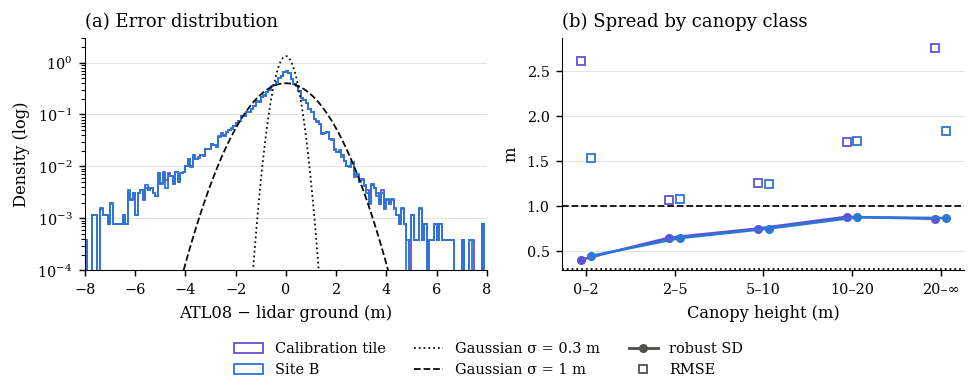



                                    RMSE (m)  ME (m) RMS σ (m) Cov. 95%    NLL CRPS (m) seeds
No ATL08 (network only)                3.444  +0.412     3.547    0.957  1.146    1.340     1
Real ATL08                             2.507  -0.361     1.903    0.927  1.092    1.062     1
Lidar + Gaussian 1 m noise     2.458 ± 0.001  +0.016     1.903    0.937  1.048    1.008     5
Lidar + empirical ATL08 noise  2.476 ± 0.002  -0.292     1.903    0.922  1.108    1.049     5
Lidar, no noise                        2.458  +0.012     1.903    0.937  1.047    1.007     1


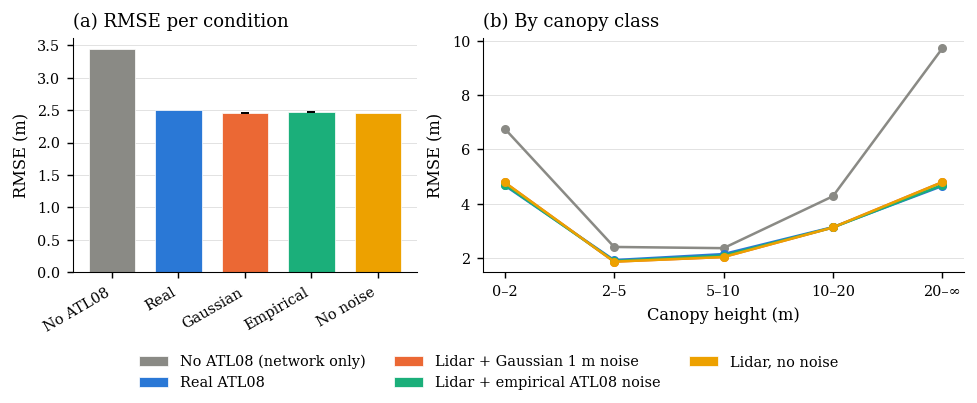



loaded /content/drive/MyDrive/dsm_dtm_calibration_TTT/model_v3/checkpoints/no_augmentation/best.pt | step 2500 | best val loss 0.2400


      Tile A, simulated ATL08             Tile A, no ATL08             Site B, real ATL08             Site B, no ATL08            
                         RMSE cov95   NLL             RMSE cov95   NLL               RMSE cov95   NLL             RMSE cov95   NLL
0.3 m                   2.171 0.948 0.715            5.674 0.929 1.030              2.501 0.944 1.126            3.656 0.964 1.238
1.0 m                   2.145 0.949 0.772            5.092 0.972 0.988              2.507 0.927 1.092            3.444 0.957 1.146


In [ ]:
paper_style()



# Table: real ATL08 − lidar per canopy class, calibration tile vs Northumberland
NT, NT_NUM = noise_stats_table(REAL_NOISE_B, B["canopy"][OBS_MASK], CAL["diff"], CAL["canopy_gee"])
print(f"\n{"="*50}\n")


# Figure: (a) error distribution (log density) vs the Gaussian 0.3 / 1.0 m training noise,
#         (b) robust SD and RMSE per canopy class at both sites vs the constant training σ
plot_noise_distribution(REAL_NOISE_B, B["canopy"][OBS_MASK], CAL["diff"], CAL["canopy_gee"])
print(f"\n{"="*50}\n")


# Table + figure: the five conditions at Northumberland (same track pixels, only the values differ)
NC = noise_condition_table(RUNS, train_sigma=TRAIN_SIGMA)       # RMSE (± seed SD), ME, RMS σ, Cov. 95%, NLL, CRPS
plot_noise_conditions(RUNS, B["canopy"][SCORE], train_sigma=TRAIN_SIGMA)
print(f"\n{"="*50}\n")

# Table: pre-training noise 0.3 m vs 1.0 m, on tile A's test blocks and at Northumberland
ckpt03 = f"{BASE_DIR}/model_v3/checkpoints/no_augmentation/best.pt"
ck03 = torch.load(ckpt03, map_location=DEVICE, weights_only=False)
cfg03 = {k: v for k, v in ck03["cfg"].items() if k != "solve_on_cpu"}   # older checkpoints stored this extra key
model03 = ProbabilisticCalibrator(**cfg03).to(DEVICE)
model03.load_state_dict(ck03["model"])
model03.eval()
print(f"loaded {ckpt03} | step {ck03['step'] + 1} | best val loss {ck03['best']:.4f}")
print(f"\n{"="*50}\n")
PT = pretrain_noise_table({"0.3 m": model03, "1.0 m": model}, episodes=TEST_SET[1:], S=S_B, OBS=OBS_B)

                               n Median ε (m) Mean ε (m) RMS ε (m) Robust SD of ε (m) |ε| > 5 m
Site             Canopy                                                                        
Calibration tile all      25,993        -0.12      -0.30      1.38               0.74      0.9%
                 0–2 m       555        -0.08      -0.30      2.61               0.40      1.3%
                 2–5 m     5,788        -0.08      -0.25      1.06               0.65      0.4%
                 5–10 m   15,419        -0.13      -0.31      1.25               0.75      0.6%
                 10–20 m   3,689        -0.15      -0.33      1.71               0.88      2.3%
                 20–∞ m      542        -0.12      -0.29      2.75               0.86      2.4%
Site B           all      25,554        -0.12      -0.30      1.30               0.74      0.9%
                 0–2 m       443        -0.11      -0.34      1.53               0.44      0.9%
                 2–5 m     5,737        

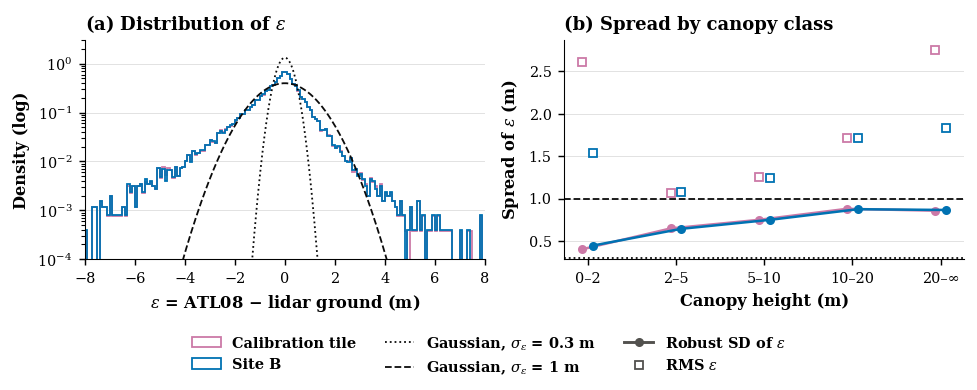



                                    RMSE (m)  ME (m) RMS σ (m) Cov. 95%    NLL CRPS (m) seeds
No ATL08 (network only)                3.444  +0.412     3.547    0.957  1.146    1.340     1
Real ATL08                             2.507  -0.361     1.903    0.927  1.092    1.062     1
Lidar + Gaussian ε, σ_ε = 1 m  2.458 ± 0.001  +0.016     1.903    0.937  1.048    1.008     5
Lidar + empirical ATL08 ε      2.476 ± 0.002  -0.292     1.903    0.922  1.108    1.049     5
Lidar, no noise                        2.458  +0.012     1.903    0.937  1.047    1.007     1


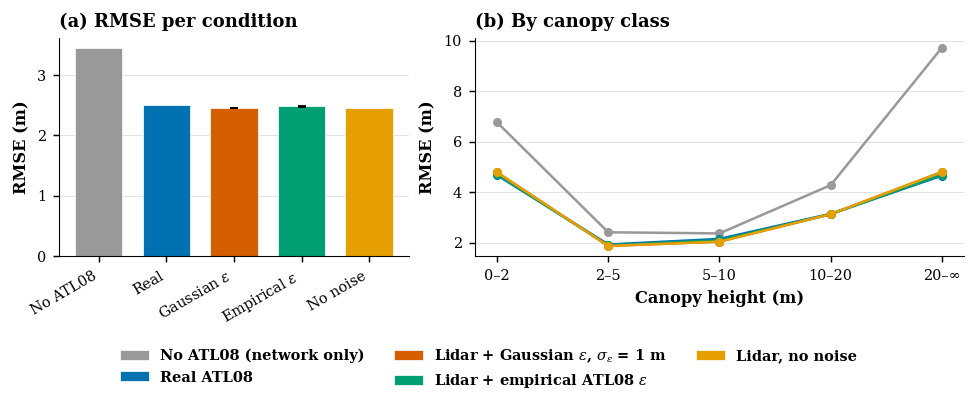



loaded /content/drive/MyDrive/dsm_dtm_calibration_TTT/model_v3/checkpoints/no_augmentation/best.pt | step 2500 | best val loss 0.2400


                   Tile A, simulated ATL08             Tile A, no ATL08             Site B, real ATL08             Site B, no ATL08            
                                      RMSE cov95   NLL             RMSE cov95   NLL               RMSE cov95   NLL             RMSE cov95   NLL
Pre-training noise                                                                                                                             
σ_ε = 0.3 m                          2.171 0.948 0.715            5.674 0.929 1.030              2.501 0.944 1.126            3.656 0.964 1.238
σ_ε = 1.0 m                          2.145 0.949 0.772            5.092 0.972 0.988              2.507 0.927 1.092            3.444 0.957 1.146


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import norm

plt.rcParams["mathtext.fontset"] = "dejavuserif"   # NEW: math symbols (σ_ε) in the same serif as the text
BOLD = dict(fontweight="bold")                       # NEW
LEG = dict(prop={"weight": "bold"}, frameon=False)   # NEW
SIG_EPS = r"$\sigma_\varepsilon$"                     # NEW: the noise level
EPS = r"$\varepsilon$"                                 # NEW: the noise itself

COND_LABELS = (                                  # prefix in RUNS -> name in the paper
    ("empty", "No ATL08 (network only)"),
    ("(i)", "Real ATL08"),
    ("(ii)", "Lidar + Gaussian ε"),
    ("(iii)", "Lidar + empirical ATL08 ε"),
    ("(iv)", "Lidar, no noise"),
)
COND_SHORT = {"No ATL08 (network only)": "No ATL08", "Real ATL08": "Real", "Lidar + empirical ATL08 ε": "Empirical ε",
              "Lidar, no noise": "No noise"}
# CHANGED: Okabe-Ito colours (grey, blue, vermillion, bluish green, orange); site colours purple / blue
COND_COLORS = {"No ATL08 (network only)": "#999999", "Real ATL08": "#0072B2", "Lidar + Gaussian ε": "#D55E00",
               "Lidar + empirical ATL08 ε": "#009E73", "Lidar, no noise": "#E69F00"}
SITE_COLORS = {"Calibration tile": "#CC79A7", "Site B": "#0072B2"}
CLASS_EDGES = (0, 2, 5, 10, 20, np.inf)


def _cond_label(key, train_sigma=None):
    for p, lab in COND_LABELS:
        if key.startswith(p):
            return f"Lidar + Gaussian ε, σ_ε = {train_sigma:g} m" if (p == "(ii)" and train_sigma) else lab
    return key


def _color(lab):
    return COND_COLORS.get("Lidar + Gaussian ε" if lab.startswith("Lidar + Gaussian") else lab, "#52514e")


def _tex(lab):
    """Plain-text label (used in tables) -> figure label with math symbols."""
    return lab.replace("σ_ε", SIG_EPS).replace("ε", EPS) if "σ_ε" in lab else lab.replace("ε", EPS)


def _save(fig, save):
    if save:
        fig.savefig(save); print("saved", save)


def _stats(d):
    d = np.asarray(d, np.float64)
    return dict(n=d.size, median=np.median(d), mean=np.mean(d), RMSE=np.sqrt(np.mean(d ** 2)),
                robust_sd=1.4826 * np.median(np.abs(d - np.median(d))), share_gt5=np.mean(np.abs(d) > 5))


def _classes(c, edges=CLASS_EDGES):
    return np.digitize(np.nan_to_num(c, nan=0.0), np.asarray(edges)[1:-1])


# ---------- Table: the real ATL08 error, per canopy class, at both sites ---------------------------------------
def noise_stats_table(real_b, canopy_b, cal_diff, cal_canopy, edges=CLASS_EDGES, min_n=50):
    """The real noise ε = ATL08 - lidar, per canopy class.
    real_b / canopy_b: ATL08 - lidar and canopy at site B's track pixels (REAL_NOISE_B, B["canopy"][OBS_MASK]);
    cal_diff / cal_canopy: the same for the calibration tile (CAL["diff"], CAL["canopy_gee"])."""
    rows = []
    for site, d, c in (("Calibration tile", np.asarray(cal_diff), np.asarray(cal_canopy)),
                       ("Site B", np.asarray(real_b), np.asarray(canopy_b))):
        cls = _classes(c, edges)
        rows.append(dict(Site=site, Canopy="all", **_stats(d)))
        for j in range(len(edges) - 1):
            m = cls == j
            if m.sum() >= min_n:
                rows.append(dict(Site=site, Canopy=f"{edges[j]:g}–{edges[j + 1]:g} m".replace("inf", "∞"), **_stats(d[m])))
    df = pd.DataFrame(rows).set_index(["Site", "Canopy"])
    show = df.copy()
    show["n"] = show["n"].map("{:,.0f}".format)
    for k in ("median", "mean", "RMSE", "robust_sd"):
        show[k] = show[k].map("{:+.2f}".format if k in ("median", "mean") else "{:.2f}".format)
    show["share_gt5"] = show["share_gt5"].map("{:.1%}".format)
    show.columns = ["n", "Median ε (m)", "Mean ε (m)", "RMS ε (m)", "Robust SD of ε (m)", "|ε| > 5 m"]
    print(show.to_string())
    return show, df


# ---------- Figure: distribution and spread of the real ATL08 error ------------------------------------------------
def plot_noise_distribution(real_b, canopy_b, cal_diff, cal_canopy, sigmas=(0.3, 1.0), lim=8.0,
                            edges=CLASS_EDGES, min_n=50, save=None):
    """(a) density of ATL08 - lidar (log scale, tails visible) at both sites with the Gaussian training
    noise models overlaid; (b) robust SD per canopy class at both sites against the constant training σ_ε."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 2.9), constrained_layout=True)
    bins = np.linspace(-lim, lim, 161)
    x = np.linspace(-lim, lim, 400)
    handles = []
    for site, d in (("Calibration tile", cal_diff), ("Site B", real_b)):
        d = np.asarray(d, np.float64)
        inside = np.abs(d) <= lim                      # density over ALL segments; the few beyond ±lim not drawn
        h = a1.hist(d[inside], bins=bins, weights=np.full(inside.sum(), 1.0 / (d.size * (bins[1] - bins[0]))),
                    histtype="step", lw=1.4, color=SITE_COLORS[site], label=site)[2][0]
        handles.append(h)
        print(f"{site}: {np.mean(~inside):.2%} of the differences lie beyond ±{lim:g} m (not drawn)")
    for s, ls in zip(sigmas, (":", "--", "-.")):
        h, = a1.plot(x, norm.pdf(x, 0, s), color="#0b0b0b", ls=ls, lw=1.0, label=f"Gaussian, {SIG_EPS} = {s:g} m")
        handles.append(h)
    a1.set_yscale("log"); a1.set_ylim(1e-4, 3); a1.set_xlim(-lim, lim)
    a1.set_xlabel(f"{EPS} = ATL08 − lidar ground (m)", **BOLD); a1.set_ylabel("Density (log)", **BOLD)
    a1.set_title(f"(a) Distribution of {EPS}", **BOLD)
    a1.grid(True, axis="y")

    labels = [f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", "∞") for j in range(len(edges) - 1)]
    pos = np.arange(len(labels))
    for k, (site, d, c) in enumerate((("Calibration tile", cal_diff, cal_canopy), ("Site B", real_b, canopy_b))):
        d, cls = np.asarray(d, np.float64), _classes(np.asarray(c), edges)
        rs = [_stats(d[cls == j])["robust_sd"] if (cls == j).sum() >= min_n else np.nan for j in range(len(labels))]
        rm = [_stats(d[cls == j])["RMSE"] if (cls == j).sum() >= min_n else np.nan for j in range(len(labels))]
        a2.plot(pos + (k - 0.5) * 0.12, rs, "o-", color=SITE_COLORS[site], ms=4, lw=1.4)
        a2.plot(pos + (k - 0.5) * 0.12, rm, "s", color=SITE_COLORS[site], ms=4, mfc="white")
    for s, ls in zip(sigmas, (":", "--", "-.")):
        a2.axhline(s, color="#0b0b0b", ls=ls, lw=1.0)
    a2.set_xticks(pos); a2.set_xticklabels(labels)
    a2.set_xlabel("Canopy height (m)", **BOLD); a2.set_ylabel(f"Spread of {EPS} (m)", **BOLD); a2.grid(True, axis="y")
    a2.set_title("(b) Spread by canopy class", **BOLD)
    handles += [Line2D([], [], color="#52514e", marker="o", ls="-", ms=4, label=f"Robust SD of {EPS}"),
                Line2D([], [], color="#52514e", marker="s", ls="none", ms=4, mfc="white", label=f"RMS {EPS}")]
    fig.legend(handles=handles, loc="outside lower center", ncol=3, **LEG)
    _save(fig, save); plt.show()


# ---------- Table: the five noise conditions at site B -----------------------------------------------------------------
def _run_metrics(r):
    e = r["err"].astype(np.float64); s2 = np.exp(r["lv"].astype(np.float64)); s = np.sqrt(s2)
    z = e / s
    crps = s * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))
    return dict(RMSE=np.sqrt(np.mean(e ** 2)), ME=np.mean(e), RMS_sigma=np.sqrt(np.mean(s2)),
                cov95=np.mean(np.abs(e) <= 1.96 * s), NLL=np.mean(0.5 * (np.log(s2) + e ** 2 / s2)), CRPS=np.mean(crps))


def noise_condition_table(RUNS, train_sigma=None):
    """One row per condition (mean over noise seeds; RMSE also ± seed SD where there are several seeds)."""
    rows = {}
    for key, runs in RUNS.items():
        ms = [_run_metrics(r) for r in runs]
        avg = {k: np.mean([m[k] for m in ms]) for k in ms[0]}
        sd = np.std([m["RMSE"] for m in ms]) if len(ms) > 1 else None
        rows[_cond_label(key, train_sigma)] = dict(
            **{"RMSE (m)": f"{avg['RMSE']:.3f}" + (f" ± {sd:.3f}" if sd is not None else ""),
               "ME (m)": f"{avg['ME']:+.3f}", "RMS σ (m)": f"{avg['RMS_sigma']:.3f}", "Cov. 95%": f"{avg['cov95']:.3f}",
               "NLL": f"{avg['NLL']:.3f}", "CRPS (m)": f"{avg['CRPS']:.3f}", "seeds": len(ms)})
    df = pd.DataFrame(rows).T
    print(df.to_string())
    return df


# ---------- Figure: the five conditions ------------------------------------------------------------------------------
def plot_noise_conditions(RUNS, canopy_scored, train_sigma=None, edges=CLASS_EDGES, min_px=200, save=None):
    """(a) RMSE per condition (bars, ± seed SD); (b) RMSE per canopy class per condition.
    canopy_scored: canopy at the scored pixels, in the same order as RUNS' err (B["canopy"][SCORE])."""
    labs = [_cond_label(k, train_sigma) for k in RUNS]
    cls = _classes(np.asarray(canopy_scored), edges)
    keep = [j for j in range(len(edges) - 1) if (cls == j).sum() >= min_px]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True,
                                 gridspec_kw=dict(width_ratios=[1, 1.4]))
    for i, (key, lab) in enumerate(zip(RUNS, labs)):
        r = [np.sqrt(np.mean(x["err"].astype(np.float64) ** 2)) for x in RUNS[key]]
        a1.bar(i, np.mean(r), width=0.7, color=_color(lab), yerr=np.std(r) if len(r) > 1 else None,
               capsize=2, edgecolor="white", linewidth=0.4, label=_tex(lab))
        ys = [np.mean([np.sqrt(np.mean(x["err"][cls == j].astype(np.float64) ** 2)) for x in RUNS[key]]) for j in keep]
        a2.plot(np.arange(len(keep)), ys, "o-", color=_color(lab), ms=4, lw=1.4)
    a1.set_xticks(range(len(labs)))
    a1.set_xticklabels([_tex(COND_SHORT.get(l, "Gaussian ε" if l.startswith("Lidar + Gaussian") else l)) for l in labs],
                       rotation=30, ha="right")
    a1.set_ylabel("RMSE (m)", **BOLD); a1.set_title("(a) RMSE per condition", **BOLD)
    a1.grid(True, axis="y"); a1.set_axisbelow(True)
    a2.set_xticks(np.arange(len(keep)))
    a2.set_xticklabels([f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", "∞") for j in keep])
    a2.set_xlabel("Canopy height (m)", **BOLD); a2.set_ylabel("RMSE (m)", **BOLD)
    a2.set_title("(b) By canopy class", **BOLD); a2.grid(True, axis="y")
    h, l = a1.get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=3, **LEG)
    _save(fig, save); plt.show()


# ---------- Table: pre-training noise 0.3 m vs 1.0 m -------------------------------------------------------------------
def pretrain_noise_table(models, episodes=None, S=None, OBS=None):
    """models: {"σ_ε = 0.3 m": model03, "σ_ε = 1.0 m": model} (the training noise level). Rows: models; columns: tile A test blocks (simulated tracks,
    scored inside the blocks) and/or a real site (S, OBS from site_eval), each with ATL08 and without."""
    import torch

    def m(e, s):
        s2 = s.astype(np.float64) ** 2
        return dict(RMSE=np.sqrt(np.mean(e ** 2)), cov95=np.mean(np.abs(e) <= 1.96 * np.sqrt(s2)),
                    NLL=np.mean(0.5 * (np.log(s2) + e ** 2 / s2)))

    out = {}
    for name, mdl in models.items():
        mdl.eval(); row = {}
        if episodes is not None:
            for empty in (False, True):
                E, SG = [], []
                for e in episodes:
                    npy = lambda k: e[k][0, 0].detach().cpu().numpy()
                    sel = npy("valid").astype(bool) & ~npy("obs_mask").astype(bool)
                    if "score_mask" in e:
                        sel &= npy("score_mask").astype(bool)
                    o = torch.zeros_like(e["obs_mask"]) if empty else e["obs_mask"]
                    d = torch.zeros_like(e["obs_dh"]) if empty else e["obs_dh"]
                    with torch.no_grad(), amp_ctx():
                        mu, lv = mdl(e["x"], d, o, origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
                    mu = mu[0, 0].float().cpu().numpy(); sg = np.exp(0.5 * lv[0, 0].float().cpu().numpy())
                    E.append((mu - npy("target"))[sel]); SG.append(sg[sel])
                r = m(np.concatenate(E), np.concatenate(SG))
                tag = "Tile A, no ATL08" if empty else "Tile A, simulated ATL08"
                row.update({(tag, k): v for k, v in r.items()})
        if S is not None:
            sel = S["valid"] & ~OBS["obs_mask"]
            for empty in (False, True):
                od = np.zeros((S["H"], S["W"]), np.float32) if empty else np.ascontiguousarray(OBS["obs_dh"], np.float32)
                om = np.zeros((S["H"], S["W"]), bool) if empty else np.ascontiguousarray(OBS["obs_mask"], bool)
                mu, sg = run_calibrator(mdl, S["Xn"], od, om)
                r = m((mu - S["target"])[sel], sg[sel])
                tag = "Site B, no ATL08" if empty else "Site B, real ATL08"
                row.update({(tag, k): v for k, v in r.items()})
        out[name] = row
    df = pd.DataFrame(out).T
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    df.index.name = "Pre-training noise"
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.to_string())
    return df


# ---------- run (after noise_need_test.py has run) -------------------------------------------------------------------
paper_style()
SEP = "\n" + "=" * 50 + "\n"

# Table: the real noise ε = ATL08 − lidar per canopy class, calibration tile vs Northumberland
NT, NT_NUM = noise_stats_table(REAL_NOISE_B, B["canopy"][OBS_MASK], CAL["diff"], CAL["canopy_gee"])
print(SEP)

# Figure: (a) distribution of ε (log density) vs the Gaussian training noise, σ_ε = 0.3 / 1.0 m;
#         (b) robust SD and RMS of ε per canopy class at both sites vs the constant σ_ε
plot_noise_distribution(REAL_NOISE_B, B["canopy"][OBS_MASK], CAL["diff"], CAL["canopy_gee"])
print(SEP)

# Table + figure: the five conditions at Northumberland (same track pixels, only the values differ)
NC = noise_condition_table(RUNS, train_sigma=TRAIN_SIGMA)       # RMSE (± seed SD), ME, RMS σ, Cov. 95%, NLL, CRPS
plot_noise_conditions(RUNS, B["canopy"][SCORE], train_sigma=TRAIN_SIGMA)
print(SEP)

# Table: pre-training noise σ_ε = 0.3 m vs 1.0 m, on tile A's test blocks and at Northumberland
ckpt03 = f"{BASE_DIR}/model_v3/checkpoints/no_augmentation/best.pt"
ck03 = torch.load(ckpt03, map_location=DEVICE, weights_only=False)
cfg03 = {k: v for k, v in ck03["cfg"].items() if k != "solve_on_cpu"}   # older checkpoints stored this extra key
model03 = ProbabilisticCalibrator(**cfg03).to(DEVICE)
model03.load_state_dict(ck03["model"])
model03.eval()
print(f"loaded {ckpt03} | step {ck03['step'] + 1} | best val loss {ck03['best']:.4f}")
print(SEP)
PT = pretrain_noise_table({"σ_ε = 0.3 m": model03, "σ_ε = 1.0 m": model}, episodes=TEST_SET[1:], S=S_B, OBS=OBS_B)


                                        n Median ε (m) Mean ε (m) RMS ε (m) Robust SD of ε (m) |ε| > 5 m
Scale                     Canopy                                                                        
ATL08 segments            all      25,993        -0.12      -0.30      1.38               0.74      0.9%
                          0–2 m       555        -0.08      -0.30      2.61               0.40      1.3%
                          2–5 m     5,788        -0.08      -0.25      1.06               0.65      0.4%
                          5–10 m   15,419        -0.13      -0.31      1.25               0.75      0.6%
                          10–20 m   3,689        -0.15      -0.33      1.71               0.88      2.3%
                          20–∞ m      542        -0.12      -0.29      2.75               0.86      2.4%
30 m pixels (model input) all      25,554        -0.12      -0.30      1.30               0.74      0.9%
                          0–2 m       443        -0.11 

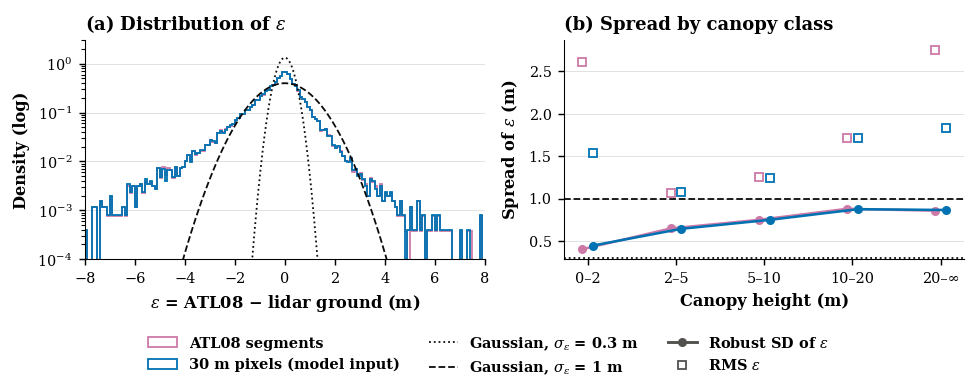



                                                 RMSE (m)  ME (m) RMS σ (m) Cov. 95%    NLL CRPS (m) seeds
No ATL08 (network only)                             3.444  +0.412     3.547    0.957  1.146    1.340     1
Real ATL08                                          2.507  -0.361     1.903    0.927  1.092    1.062     1
Lidar + Gaussian ε, σ_ε = 1 m (as trained)  2.458 ± 0.001  +0.016     1.903    0.937  1.048    1.008     5
Lidar + empirical ATL08 ε                   2.476 ± 0.002  -0.292     1.903    0.922  1.108    1.049     5
Lidar, no noise                                     2.458  +0.012     1.903    0.937  1.047    1.007     1


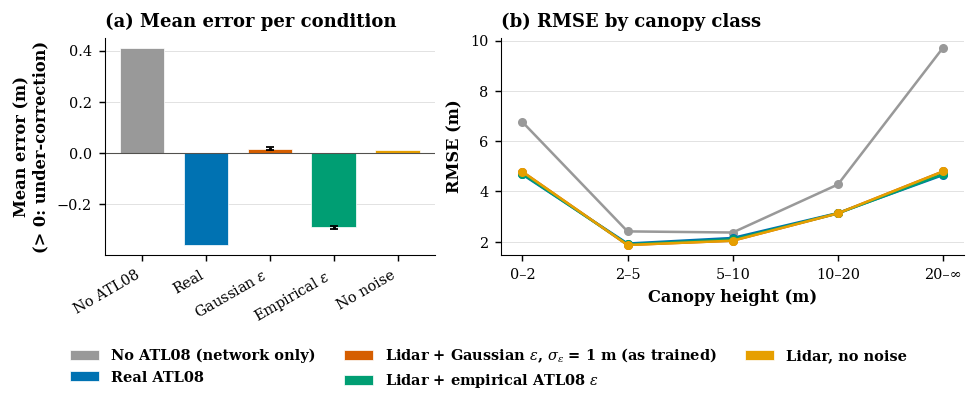



loaded /content/drive/MyDrive/dsm_dtm_calibration_TTT/model_v3/checkpoints/no_augmentation/best.pt | step 2500 | best val loss 0.2400


                   Tile A, simulated ATL08             Tile A, no ATL08             Site B, real ATL08             Site B, no ATL08            
                                      RMSE cov95   NLL             RMSE cov95   NLL               RMSE cov95   NLL             RMSE cov95   NLL
Pre-training noise                                                                                                                             
σ_ε = 0.3 m                          2.171 0.948 0.715            5.674 0.929 1.030              2.501 0.944 1.126            3.656 0.964 1.238
σ_ε = 1.0 m                          2.145 0.949 0.772            5.092 0.972 0.988              2.507 0.927 1.092            3.444 0.957 1.146


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.stats import norm

plt.rcParams["mathtext.fontset"] = "dejavuserif"   # NEW: math symbols (σ_ε) in the same serif as the text
BOLD = dict(fontweight="bold")                       # NEW
LEG = dict(prop={"weight": "bold"}, frameon=False)   # NEW
SIG_EPS = r"$\sigma_\varepsilon$"                     # NEW: the noise level
EPS = r"$\varepsilon$"                                 # NEW: the noise itself

COND_LABELS = (                                  # prefix in RUNS -> name in the paper
    ("empty", "No ATL08 (network only)"),
    ("(i)", "Real ATL08"),
    ("(ii)", "Lidar + Gaussian ε"),
    ("(iii)", "Lidar + empirical ATL08 ε"),
    ("(iv)", "Lidar, no noise"),
)
COND_SHORT = {"No ATL08 (network only)": "No ATL08", "Real ATL08": "Real", "Lidar + empirical ATL08 ε": "Empirical ε",
              "Lidar, no noise": "No noise"}
# CHANGED: Okabe-Ito colours (grey, blue, vermillion, bluish green, orange); site colours purple / blue
COND_COLORS = {"No ATL08 (network only)": "#999999", "Real ATL08": "#0072B2", "Lidar + Gaussian ε": "#D55E00",
               "Lidar + empirical ATL08 ε": "#009E73", "Lidar, no noise": "#E69F00"}
SEG, PIX = "ATL08 segments", "30 m pixels (model input)"               # CHANGED: two scales, one site
SCALE_COLORS = {SEG: "#CC79A7", PIX: "#0072B2"}
CLASS_EDGES = (0, 2, 5, 10, 20, np.inf)


def _cond_label(key, train_sigma=None):
    for p, lab in COND_LABELS:
        if key.startswith(p):
            return f"Lidar + Gaussian ε, σ_ε = {train_sigma:g} m (as trained)" if (p == "(ii)" and train_sigma) else lab
    return key


def _color(lab):
    return COND_COLORS.get("Lidar + Gaussian ε" if lab.startswith("Lidar + Gaussian") else lab, "#52514e")


def _tex(lab):
    """Plain-text label (used in tables) -> figure label with math symbols."""
    return lab.replace("σ_ε", SIG_EPS).replace("ε", EPS) if "σ_ε" in lab else lab.replace("ε", EPS)


def _save(fig, save):
    if save:
        fig.savefig(save); print("saved", save)


def _stats(d):
    d = np.asarray(d, np.float64)
    return dict(n=d.size, median=np.median(d), mean=np.mean(d), RMSE=np.sqrt(np.mean(d ** 2)),
                robust_sd=1.4826 * np.median(np.abs(d - np.median(d))), share_gt5=np.mean(np.abs(d) > 5))


def _classes(c, edges=CLASS_EDGES):
    return np.digitize(np.nan_to_num(c, nan=0.0), np.asarray(edges)[1:-1])


# ---------- Table: the real ATL08 error ε per canopy class, per segment and per 30 m pixel ---------------------------------------
def noise_stats_table(real_b, canopy_b, cal_diff, cal_canopy, edges=CLASS_EDGES, min_n=50):
    """The real noise ε = ATL08 - lidar, per canopy class, at two scales of the same site-B ATL08.
    real_b / canopy_b: per 30 m track pixel, as the model receives it (REAL_NOISE_B, B["canopy"][OBS_MASK]);
    cal_diff / cal_canopy: per ATL08 segment, against the same 30 m lidar (CAL["diff"], CAL["canopy_gee"])."""
    rows = []
    for site, d, c in ((SEG, np.asarray(cal_diff), np.asarray(cal_canopy)),
                       (PIX, np.asarray(real_b), np.asarray(canopy_b))):
        cls = _classes(c, edges)
        rows.append(dict(Site=site, Canopy="all", **_stats(d)))
        for j in range(len(edges) - 1):
            m = cls == j
            if m.sum() >= min_n:
                rows.append(dict(Site=site, Canopy=f"{edges[j]:g}–{edges[j + 1]:g} m".replace("inf", "∞"), **_stats(d[m])))
    df = pd.DataFrame(rows).rename(columns={"Site": "Scale"}).set_index(["Scale", "Canopy"])
    show = df.copy()
    show["n"] = show["n"].map("{:,.0f}".format)
    for k in ("median", "mean", "RMSE", "robust_sd"):
        show[k] = show[k].map("{:+.2f}".format if k in ("median", "mean") else "{:.2f}".format)
    show["share_gt5"] = show["share_gt5"].map("{:.1%}".format)
    show.columns = ["n", "Median ε (m)", "Mean ε (m)", "RMS ε (m)", "Robust SD of ε (m)", "|ε| > 5 m"]
    print(show.to_string())
    return show, df


# ---------- Figure: distribution and spread of the real ATL08 error ------------------------------------------------
def plot_noise_distribution(real_b, canopy_b, cal_diff, cal_canopy, sigmas=(0.3, 1.0), lim=8.0,
                            edges=CLASS_EDGES, min_n=50, save=None):
    """(a) density of ε = ATL08 - lidar (log scale, tails visible), per segment and per 30 m pixel, with the
    Gaussian training noise overlaid; (b) robust SD and RMS of ε per canopy class against the constant σ_ε."""
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 2.9), constrained_layout=True)
    bins = np.linspace(-lim, lim, 161)
    x = np.linspace(-lim, lim, 400)
    handles = []
    for site, d in ((SEG, cal_diff), (PIX, real_b)):
        d = np.asarray(d, np.float64)
        inside = np.abs(d) <= lim                      # density over ALL segments; the few beyond ±lim not drawn
        h = a1.hist(d[inside], bins=bins, weights=np.full(inside.sum(), 1.0 / (d.size * (bins[1] - bins[0]))),
                    histtype="step", lw=1.4, color=SCALE_COLORS[site], label=site)[2][0]
        handles.append(h)
        print(f"{site}: {np.mean(~inside):.2%} of ε beyond ±{lim:g} m (not drawn)")
    for s, ls in zip(sigmas, (":", "--", "-.")):
        h, = a1.plot(x, norm.pdf(x, 0, s), color="#0b0b0b", ls=ls, lw=1.0, label=f"Gaussian, {SIG_EPS} = {s:g} m")
        handles.append(h)
    a1.set_yscale("log"); a1.set_ylim(1e-4, 3); a1.set_xlim(-lim, lim)
    a1.set_xlabel(f"{EPS} = ATL08 − lidar ground (m)", **BOLD); a1.set_ylabel("Density (log)", **BOLD)
    a1.set_title(f"(a) Distribution of {EPS}", **BOLD)
    a1.grid(True, axis="y")

    labels = [f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", "∞") for j in range(len(edges) - 1)]
    pos = np.arange(len(labels))
    for k, (site, d, c) in enumerate(((SEG, cal_diff, cal_canopy), (PIX, real_b, canopy_b))):
        d, cls = np.asarray(d, np.float64), _classes(np.asarray(c), edges)
        rs = [_stats(d[cls == j])["robust_sd"] if (cls == j).sum() >= min_n else np.nan for j in range(len(labels))]
        rm = [_stats(d[cls == j])["RMSE"] if (cls == j).sum() >= min_n else np.nan for j in range(len(labels))]
        a2.plot(pos + (k - 0.5) * 0.12, rs, "o-", color=SCALE_COLORS[site], ms=4, lw=1.4)
        a2.plot(pos + (k - 0.5) * 0.12, rm, "s", color=SCALE_COLORS[site], ms=4, mfc="white")
    for s, ls in zip(sigmas, (":", "--", "-.")):
        a2.axhline(s, color="#0b0b0b", ls=ls, lw=1.0)
    a2.set_xticks(pos); a2.set_xticklabels(labels)
    a2.set_xlabel("Canopy height (m)", **BOLD); a2.set_ylabel(f"Spread of {EPS} (m)", **BOLD); a2.grid(True, axis="y")
    a2.set_title("(b) Spread by canopy class", **BOLD)
    handles += [Line2D([], [], color="#52514e", marker="o", ls="-", ms=4, label=f"Robust SD of {EPS}"),
                Line2D([], [], color="#52514e", marker="s", ls="none", ms=4, mfc="white", label=f"RMS {EPS}")]
    fig.legend(handles=handles, loc="outside lower center", ncol=3, **LEG)
    _save(fig, save); plt.show()


# ---------- Table: the five noise conditions at site B -----------------------------------------------------------------
def _run_metrics(r):
    e = r["err"].astype(np.float64); s2 = np.exp(r["lv"].astype(np.float64)); s = np.sqrt(s2)
    z = e / s
    crps = s * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))
    return dict(RMSE=np.sqrt(np.mean(e ** 2)), ME=np.mean(e), RMS_sigma=np.sqrt(np.mean(s2)),
                cov95=np.mean(np.abs(e) <= 1.96 * s), NLL=np.mean(0.5 * (np.log(s2) + e ** 2 / s2)), CRPS=np.mean(crps))


def noise_condition_table(RUNS, train_sigma=None):
    """One row per condition (mean over noise seeds; RMSE also ± seed SD where there are several seeds)."""
    rows = {}
    for key, runs in RUNS.items():
        ms = [_run_metrics(r) for r in runs]
        avg = {k: np.mean([m[k] for m in ms]) for k in ms[0]}
        sd = np.std([m["RMSE"] for m in ms]) if len(ms) > 1 else None
        rows[_cond_label(key, train_sigma)] = dict(
            **{"RMSE (m)": f"{avg['RMSE']:.3f}" + (f" ± {sd:.3f}" if sd is not None else ""),
               "ME (m)": f"{avg['ME']:+.3f}", "RMS σ (m)": f"{avg['RMS_sigma']:.3f}", "Cov. 95%": f"{avg['cov95']:.3f}",
               "NLL": f"{avg['NLL']:.3f}", "CRPS (m)": f"{avg['CRPS']:.3f}", "seeds": len(ms)})
    df = pd.DataFrame(rows).T
    print(df.to_string())
    return df


# ---------- Figure: the five conditions ------------------------------------------------------------------------------
def plot_noise_conditions(RUNS, canopy_scored, train_sigma=None, edges=CLASS_EDGES, min_px=200, save=None):
    """CHANGED: (a) mean error per condition (bars, ± seed SD; > 0 = predicted ground too high);
    (b) RMSE per canopy class per condition.
    canopy_scored: canopy at the scored pixels, in the same order as RUNS' err (B["canopy"][SCORE])."""
    labs = [_cond_label(k, train_sigma) for k in RUNS]
    cls = _classes(np.asarray(canopy_scored), edges)
    keep = [j for j in range(len(edges) - 1) if (cls == j).sum() >= min_px]
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 3.0), constrained_layout=True,
                                 gridspec_kw=dict(width_ratios=[1, 1.4]))
    for i, (key, lab) in enumerate(zip(RUNS, labs)):
        r = [np.mean(x["err"].astype(np.float64)) for x in RUNS[key]]              # CHANGED: mean error per seed
        a1.bar(i, np.mean(r), width=0.7, color=_color(lab), yerr=np.std(r) if len(r) > 1 else None,
               capsize=2, edgecolor="white", linewidth=0.4, label=_tex(lab))
        ys = [np.mean([np.sqrt(np.mean(x["err"][cls == j].astype(np.float64) ** 2)) for x in RUNS[key]]) for j in keep]
        a2.plot(np.arange(len(keep)), ys, "o-", color=_color(lab), ms=4, lw=1.4)
    a1.set_xticks(range(len(labs)))
    a1.set_xticklabels([_tex(COND_SHORT.get(l, "Gaussian ε" if l.startswith("Lidar + Gaussian") else l)) for l in labs],
                       rotation=30, ha="right")
    a1.axhline(0, color="#52514e", lw=0.6)                                          # NEW: zero line
    a1.set_ylabel("Mean error (m)\n(> 0: under-correction)", **BOLD); a1.set_title("(a) Mean error per condition", **BOLD)
    a1.grid(True, axis="y"); a1.set_axisbelow(True)
    a2.set_xticks(np.arange(len(keep)))
    a2.set_xticklabels([f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", "∞") for j in keep])
    a2.set_xlabel("Canopy height (m)", **BOLD); a2.set_ylabel("RMSE (m)", **BOLD)
    a2.set_title("(b) RMSE by canopy class", **BOLD); a2.grid(True, axis="y")
    h, l = a1.get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=3, **LEG)
    _save(fig, save); plt.show()


# ---------- Table: pre-training noise 0.3 m vs 1.0 m -------------------------------------------------------------------
def pretrain_noise_table(models, episodes=None, S=None, OBS=None):
    """models: {"σ_ε = 0.3 m": model03, "σ_ε = 1.0 m": model} (the training noise level). Rows: models; columns: tile A test blocks (simulated tracks,
    scored inside the blocks) and/or a real site (S, OBS from site_eval), each with ATL08 and without."""
    import torch

    def m(e, s):
        s2 = s.astype(np.float64) ** 2
        return dict(RMSE=np.sqrt(np.mean(e ** 2)), cov95=np.mean(np.abs(e) <= 1.96 * np.sqrt(s2)),
                    NLL=np.mean(0.5 * (np.log(s2) + e ** 2 / s2)))

    out = {}
    for name, mdl in models.items():
        mdl.eval(); row = {}
        if episodes is not None:
            for empty in (False, True):
                E, SG = [], []
                for e in episodes:
                    npy = lambda k: e[k][0, 0].detach().cpu().numpy()
                    sel = npy("valid").astype(bool) & ~npy("obs_mask").astype(bool)
                    if "score_mask" in e:
                        sel &= npy("score_mask").astype(bool)
                    o = torch.zeros_like(e["obs_mask"]) if empty else e["obs_mask"]
                    d = torch.zeros_like(e["obs_dh"]) if empty else e["obs_dh"]
                    with torch.no_grad(), amp_ctx():
                        mu, lv = mdl(e["x"], d, o, origin_yx=e["origin"], dsm_hw=e.get("dsm_hw", (H_DSM, W_DSM)))
                    mu = mu[0, 0].float().cpu().numpy(); sg = np.exp(0.5 * lv[0, 0].float().cpu().numpy())
                    E.append((mu - npy("target"))[sel]); SG.append(sg[sel])
                r = m(np.concatenate(E), np.concatenate(SG))
                tag = "Tile A, no ATL08" if empty else "Tile A, simulated ATL08"
                row.update({(tag, k): v for k, v in r.items()})
        if S is not None:
            sel = S["valid"] & ~OBS["obs_mask"]
            for empty in (False, True):
                od = np.zeros((S["H"], S["W"]), np.float32) if empty else np.ascontiguousarray(OBS["obs_dh"], np.float32)
                om = np.zeros((S["H"], S["W"]), bool) if empty else np.ascontiguousarray(OBS["obs_mask"], bool)
                mu, sg = run_calibrator(mdl, S["Xn"], od, om)
                r = m((mu - S["target"])[sel], sg[sel])
                tag = "Site B, no ATL08" if empty else "Site B, real ATL08"
                row.update({(tag, k): v for k, v in r.items()})
        out[name] = row
    df = pd.DataFrame(out).T
    df.columns = pd.MultiIndex.from_tuples(df.columns)
    df.index.name = "Pre-training noise"
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.to_string())
    return df


# ---------- run -------------------------------------------------------------------
paper_style()
SEP = "\n" + "=" * 50 + "\n"

# Table: the real noise ε = ATL08 − lidar per canopy class at site B, per segment and per 30 m pixel
NT, NT_NUM = noise_stats_table(REAL_NOISE_B, B["canopy"][OBS_MASK], CAL["diff"], CAL["canopy_gee"])
print(SEP)

# Figure: (a) distribution of ε (log density) vs the Gaussian training noise, σ_ε = 0.3 / 1.0 m;
#         (b) robust SD and RMS of ε per canopy class at both sites vs the constant σ_ε
plot_noise_distribution(REAL_NOISE_B, B["canopy"][OBS_MASK], CAL["diff"], CAL["canopy_gee"])
print(SEP)

# Table + figure: the five conditions at Northumberland (same track pixels, only the values differ)
NC = noise_condition_table(RUNS, train_sigma=TRAIN_SIGMA)       # RMSE (± seed SD), ME, RMS σ, Cov. 95%, NLL, CRPS
plot_noise_conditions(RUNS, B["canopy"][SCORE], train_sigma=TRAIN_SIGMA)
print(SEP)

# Table: pre-training noise σ_ε = 0.3 m vs 1.0 m, on tile A's test blocks and at Northumberland
ckpt03 = f"{BASE_DIR}/model_v3/checkpoints/no_augmentation/best.pt"
ck03 = torch.load(ckpt03, map_location=DEVICE, weights_only=False)
cfg03 = {k: v for k, v in ck03["cfg"].items() if k != "solve_on_cpu"}   # older checkpoints stored this extra key
model03 = ProbabilisticCalibrator(**cfg03).to(DEVICE)
model03.load_state_dict(ck03["model"])
model03.eval()
print(f"loaded {ckpt03} | step {ck03['step'] + 1} | best val loss {ck03['best']:.4f}")
print(SEP)
PT = pretrain_noise_table({"σ_ε = 0.3 m": model03, "σ_ε = 1.0 m": model}, episodes=TEST_SET[1:], S=S_B, OBS=OBS_B)


In [ ]:
# ============== ablation studies done on Site B, figures are publication ready ====================

import types
from contextlib import contextmanager, nullcontext
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.ndimage import distance_transform_edt

SERIES = ("#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#6250d6", "#008300")
REF_STYLE = {"Uncorrected DSM": dict(color="#8a8a85", ls="--", marker=None),
             "Network only": dict(color="#52514e", ls=":", marker=None)}
DIST_EDGES_KM_B = (0, 0.25, 0.5, 1, 2, 4, np.inf)

# names used in P (also the panel titles of the maps)
DSM, NET, FULL = "Uncorrected DSM", "Network only", "Network + ATL08 adaptation"


# ---------- switches (same as level_ablation.py / blend_ablation.py) ----------------------------------------
@contextmanager
def _only_levels(model, keep):
    """The read only sees the grid levels in `keep`; the others are emptied after the write."""
    orig = type(model)._write_pass

    def patched(self, *a, **k):
        levels = orig(self, *a, **k)
        for li, L in enumerate(levels):
            if li not in keep:
                L["count"] = torch.zeros_like(L["count"]); L["w"] = torch.zeros_like(L["w"])
        return levels

    model._write_pass = types.MethodType(patched, model)
    try:
        yield
    finally:
        del model._write_pass


def _geom(pix_xy, L):
    gx = pix_xy[:, 0] / L['rx'] - 0.5; gy = pix_xy[:, 1] / L['ry'] - 0.5
    x0, y0 = gx.floor().long(), gy.floor().long()
    xs = torch.stack([x0, x0 + 1, x0, x0 + 1], -1); ys = torch.stack([y0, y0, y0 + 1, y0 + 1], -1)
    inb = (xs >= 0) & (xs < L['Wg']) & (ys >= 0) & (ys < L['Hg'])
    idx = ys.clamp(0, L['Hg'] - 1) * L['Wg'] + xs.clamp(0, L['Wg'] - 1)
    cnt = L['count'][idx]
    return idx, inb & (cnt > 0), (gx[:, None] - xs.float()).float(), (gy[:, None] - ys.float()).float(), cnt


def _fixed_forward(kind, ell=0.5):
    """Replacement read: bilinear or Gaussian weights instead of attention, equal share per level with data."""
    def forward(q_feat, pix_xy, levels):
        alphas, has, ws, logcs, dists, masks = [], [], [], [], [], []
        for L in levels:
            idx, valid, dx, dy, cnt = _geom(pix_xy, L)
            k = ((1 - dx.abs()).clamp(min=0) * (1 - dy.abs()).clamp(min=0) if kind == "bilinear"
                 else torch.exp(-(dx ** 2 + dy ** 2) / (2 * ell ** 2))) * valid
            ks = k.sum(-1, keepdim=True)
            alphas.append(k / ks.clamp_min(1e-12)); has.append(ks.squeeze(-1) > 0); masks.append(valid)
            ws.append(L['w'][idx]); logcs.append(torch.log1p(cnt)); dists.append((dx ** 2 + dy ** 2).sqrt() * L['res_km'])
        A = torch.stack(alphas, 1); Hh = torch.stack(has, 1).float()
        A = A * (Hh / Hh.sum(-1, keepdim=True).clamp_min(1)).unsqueeze(-1)
        alpha = A.reshape(A.shape[0], -1); M = torch.cat(masks, -1)
        dW = (alpha.unsqueeze(-1) * torch.cat(ws, 1)).sum(1)
        support = (alpha * torch.cat(logcs, -1)).sum(-1)
        dmin = torch.cat(dists, -1).masked_fill(~M, 1e3).amin(-1).clamp(max=100.0)
        return dW, torch.stack([support, torch.log1p(dmin), M.any(-1).float()], -1)
    return forward


@contextmanager
def _fixed_blend(model, kind, ell=0.5):
    model.grid_gat.forward = _fixed_forward(kind, ell)
    try:
        yield
    finally:
        del model.grid_gat.forward


# ---------- predictions --------------------------------------------------------------------------------------------
def _predict(model, S, OBS, empty=False, ctx=None):
    od = np.zeros((S["H"], S["W"]), np.float32) if empty else np.ascontiguousarray(OBS["obs_dh"], np.float32)
    om = np.zeros((S["H"], S["W"]), bool) if empty else np.ascontiguousarray(OBS["obs_mask"], bool)
    model.eval()
    with (ctx() if ctx is not None else nullcontext()):
        mu, sg = run_calibrator(model, S["Xn"], od, om)
    return dict(mu=mu.astype(np.float32), sigma=sg.astype(np.float32))


def _base(model, S, OBS, cache):
    """Uncorrected DSM, network only and the full model, predicted once and shared by all four ablations."""
    if cache is None:
        cache = {}
    if FULL not in cache:
        cache[DSM] = dict(mu=np.zeros((S["H"], S["W"]), np.float32), sigma=None)
        cache[NET] = _predict(model, S, OBS, empty=True)
        cache[FULL] = _predict(model, S, OBS)
    return cache


def _net_offset(P, OBS):
    o = OBS["obs_mask"]
    b = float(np.mean(OBS["obs_dh"][o] - P[NET]["mu"][o]))
    return dict(mu=P[NET]["mu"] + b, sigma=P[NET]["sigma"]), b


# ---------- table and distance figure ----------------------------------------------------------------------------
def _metrics(e, s):
    r = dict(RMSE=np.sqrt(np.mean(e ** 2)), MAE=np.mean(np.abs(e)), ME=np.mean(e))
    if s is not None:
        s2 = s.astype(np.float64) ** 2
        r.update(**{"RMS σ": np.sqrt(np.mean(s2)), "Cov. 95%": np.mean(np.abs(e) <= 1.96 * np.sqrt(s2)),
                    "NLL": np.mean(0.5 * (np.log(s2) + e ** 2 / s2))})
    return r


def _table(P, S, OBS, names, extra=None):
    sel = _score_mask(S, OBS, {n: P[n] for n in names})
    rows = {n: _metrics((P[n]["mu"] - S["target"])[sel].astype(np.float64),
                        None if P[n]["sigma"] is None else P[n]["sigma"][sel]) for n in names}
    df = pd.DataFrame(rows).T
    if extra:
        for col, fn in extra.items():
            df[col] = [fn(df, n) for n in df.index]
    print(f"{sel.sum():,} scored pixels (valid lidar, off the ATL08 pixels)")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.to_string(na_rep="–"))
    return df


FIXED = {                                   # colour follows the variant in every figure (not its position)
    "Network + ATL08 adaptation": "#2a78d6", "Network + ATL08 offset": "#1baf7a", "ATL08 mean only": "#e87ba4",
    "1 km level only": "#eb6834", "4 km level only": "#eda100", "16 km level only": "#6250d6",
    "Bilinear read": "#6250d6",
}
GAUSS_COLORS = ("#eb6834", "#eda100", "#e87ba4")


def _style(names):
    st, k, g = {}, 0, 0
    marks = "osD^vP*"
    for i, n in enumerate(names):
        if n in REF_STYLE:
            st[n] = REF_STYLE[n]; continue
        if n in FIXED:
            col = FIXED[n]
        elif n.startswith("Gaussian read"):
            col = GAUSS_COLORS[g % len(GAUSS_COLORS)]; g += 1
        else:
            col = SERIES[k % len(SERIES)]; k += 1
        st[n] = dict(color=col, ls="-", marker=marks[i % len(marks)])
    return st


def plot_distance_variants(P, S, OBS, names, edges=DIST_EDGES_KM_B, min_px=200):
    """(a) RMSE and (b) RMS predicted σ vs distance to the nearest ATL08 pixel, one line per variant."""
    sel = _score_mask(S, OBS, {n: P[n] for n in names})
    dist = (distance_transform_edt(~OBS["obs_mask"]) * S["pixel_m"] / 1000)[sel]
    b = np.digitize(dist, np.asarray(edges)[1:-1])
    keep = [j for j in range(len(edges) - 1) if (b == j).sum() >= min_px]
    labels = [f"{edges[j]:g}–{edges[j + 1]:g}".replace("inf", "∞") for j in keep]
    pos = np.arange(len(keep))
    st = _style(names)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.4, 2.9), constrained_layout=True)
    handles = []
    for n in names:
        e = (P[n]["mu"] - S["target"])[sel]
        kw = dict(color=st[n]["color"], ls=st[n]["ls"], marker=st[n]["marker"], ms=4, lw=1.4)
        h, = a1.plot(pos, [np.sqrt(np.mean(e[b == j] ** 2)) for j in keep], label=n, **kw)
        handles.append(h)
        if P[n]["sigma"] is not None:
            s = P[n]["sigma"][sel].astype(np.float64)
            a2.plot(pos, [np.sqrt(np.mean(s[b == j] ** 2)) for j in keep], **kw)
    for ax, t in ((a1, "(a) RMSE"), (a2, "(b) RMS predicted σ")):
        ax.set_xticks(pos); ax.set_xticklabels(labels)
        ax.set_xlabel("Distance to nearest ATL08 pixel (km)"); ax.set_ylabel("m")
        ax.set_title(t); ax.grid(True, axis="y")
    fig.legend(handles=handles, loc="outside lower center", ncol=min(len(handles), 3), frameon=False)
    plt.show()


# ---------- 1) with vs without ATL08 ---------------------------------------------------------------------------------
def ablation_context(model, S, OBS, cache=None, window_km=None):
    P = _base(model, S, OBS, cache)
    names = [DSM, NET, FULL]
    T = _table(P, S, OBS, names)
    print(f"ATL08 lowers RMSE by {T.loc[NET, 'RMSE'] - T.loc[FULL, 'RMSE']:+.3f} m vs the network alone")
    plot_distance_variants(P, S, OBS, names)
    plot_error_maps({n: P[n] for n in names}, S, OBS, methods=names, window_km=window_km)
    return T, {n: P[n] for n in names}


# ---------- 2) global baselines ---------------------------------------------------------------------------------------
def ablation_global(model, S, OBS, cache=None, window_km=None):
    """ATL08 mean only (no network, σ = SD of the ATL08 values), network only, network + ONE scalar offset
    (mean ATL08 residual vs the network, σ = network σ), and the full model."""
    P = dict(_base(model, S, OBS, cache))
    o = OBS["obs_mask"]
    m_b, s_b = float(np.mean(OBS["obs_dh"][o])), float(np.std(OBS["obs_dh"][o]))
    P["ATL08 mean only"] = dict(mu=np.full((S["H"], S["W"]), m_b, np.float32),
                                sigma=np.full((S["H"], S["W"]), s_b, np.float32))
    P["Network + ATL08 offset"], b = _net_offset(P, OBS)
    print(f"ATL08 mean {m_b:+.3f} m (SD {s_b:.3f}) | offset of the network {b:+.3f} m")
    names = [DSM, "ATL08 mean only", NET, "Network + ATL08 offset", FULL]
    T = _table(P, S, OBS, names)
    plot_distance_variants(P, S, OBS, names)
    plot_error_maps({n: P[n] for n in names}, S, OBS, methods=[DSM, NET, "Network + ATL08 offset", FULL],
                    window_km=window_km)
    return T, {n: P[n] for n in names}


# ---------- 3) one grid level at a time -------------------------------------------------------------------------------
def ablation_levels(model, S, OBS, cache=None, window_km=None):
    P = dict(_base(model, S, OBS, cache))
    n_lv = len(model.level_res_m)
    lv_names = [f"{model.level_res_m[i] / 1000:g} km level only" for i in range(n_lv)]
    for i, n in enumerate(lv_names):
        P[n] = _predict(model, S, OBS, ctx=lambda i=i: _only_levels(model, {i}))
    all_lv = _predict(model, S, OBS, ctx=lambda: _only_levels(model, set(range(n_lv))))
    print(f"check: all-levels wrapper vs normal model, max |difference| "
          f"{np.nanmax(np.abs(all_lv['mu'] - P[FULL]['mu'])):.2e} m (should be ~0)")
    P["Network + ATL08 offset"], _ = _net_offset(P, OBS)
    names = [NET, "Network + ATL08 offset"] + lv_names + [FULL]
    share = lambda df, n: (df.loc[NET, "RMSE"] - df.loc[n, "RMSE"]) / (df.loc[NET, "RMSE"] - df.loc[FULL, "RMSE"])
    T = _table(P, S, OBS, names, extra={"Share of gain": share})
    print("share of gain = (RMSE network only − RMSE row) / (RMSE network only − RMSE full model)")
    plot_distance_variants(P, S, OBS, names)
    plot_error_maps({n: P[n] for n in lv_names + [FULL]}, S, OBS, methods=lv_names + [FULL], window_km=window_km)
    return T, {n: P[n] for n in names}


# ---------- 4) learned attention vs fixed interpolation ------------------------------------------------------------------
def ablation_blend(model, S, OBS, cache=None, ells=(0.25, 0.5, 1.0), map_ell=0.5, window_km=None):
    P = dict(_base(model, S, OBS, cache))
    ref_before = P[FULL]["mu"]
    g_names = [f"Gaussian read ($\\ell$ = {ell:g} node)" for ell in ells]      # mathtext: renders in every font
    for ell, n in zip(ells, g_names):
        P[n] = _predict(model, S, OBS, ctx=lambda ell=ell: _fixed_blend(model, "gaussian", ell))
    P["Bilinear read"] = _predict(model, S, OBS, ctx=lambda: _fixed_blend(model, "bilinear"))
    after = _predict(model, S, OBS)
    print(f"check: trained attention before vs after the swaps, max |difference| "
          f"{np.nanmax(np.abs(after['mu'] - ref_before)):.2e} m (should be ~0)")
    names = [FULL] + g_names + ["Bilinear read"]
    vs = lambda df, n: df.loc[n, "RMSE"] - df.loc[FULL, "RMSE"]
    T = _table(P, S, OBS, names, extra={"RMSE vs learned": vs})
    plot_distance_variants(P, S, OBS, names)
    g_map = f"Gaussian read ($\\ell$ = {map_ell:g} node)"
    maps = [FULL] + ([g_map] if g_map in P else []) + ["Bilinear read"]
    plot_error_maps({n: P[n] for n in maps}, S, OBS, methods=maps, window_km=window_km)
    return T, {n: P[n] for n in names}


2,471,272 scored pixels (valid lidar, off the ATL08 pixels)
                            RMSE   MAE     ME  RMS σ  Cov. 95%   NLL
Uncorrected DSM            4.106 2.027  1.180      –         –     –
Network only               3.444 1.844  0.412  3.547     0.957 1.146
Network + ATL08 adaptation 2.507 1.461 -0.361  1.903     0.927 1.092
ATL08 lowers RMSE by +0.937 m vs the network alone


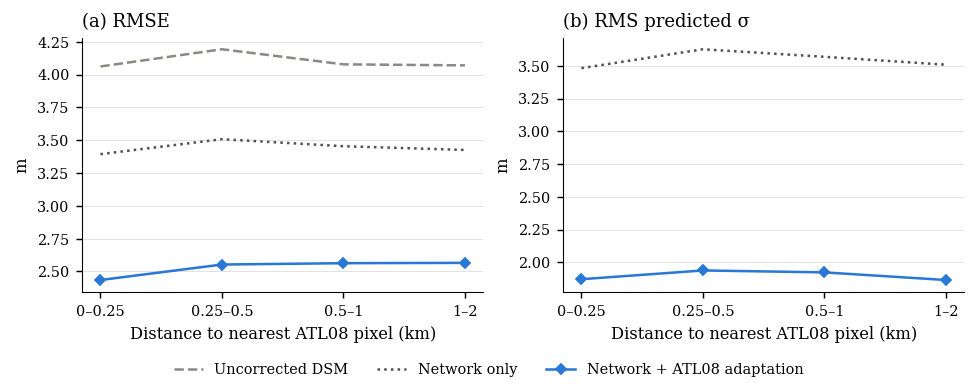

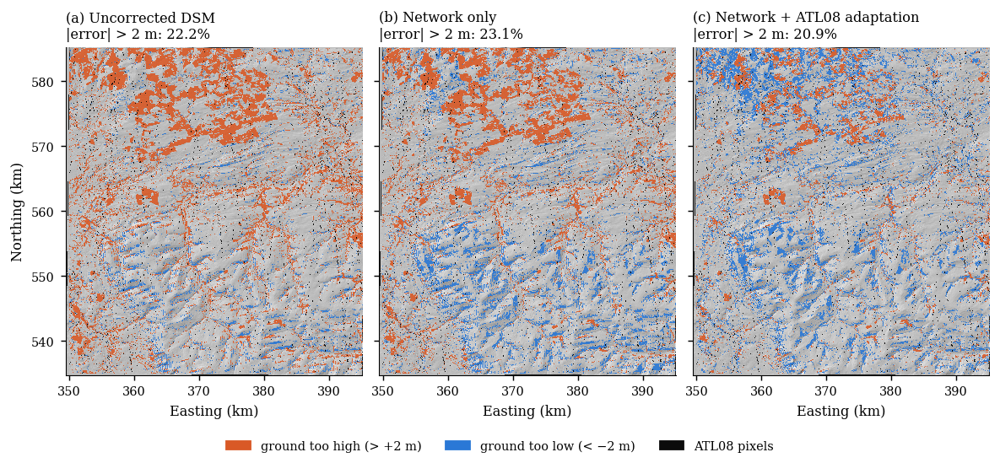



ATL08 mean -1.130 m (SD 3.620) | offset of the network -0.509 m
2,471,272 scored pixels (valid lidar, off the ATL08 pixels)
                            RMSE   MAE     ME  RMS σ  Cov. 95%   NLL
Uncorrected DSM            4.106 2.027  1.180      –         –     –
ATL08 mean only            3.933 2.367  0.050  3.620     0.931 1.877
Network only               3.444 1.844  0.412  3.547     0.957 1.146
Network + ATL08 offset     3.421 2.060 -0.097  3.547     0.895 1.427
Network + ATL08 adaptation 2.507 1.461 -0.361  1.903     0.927 1.092


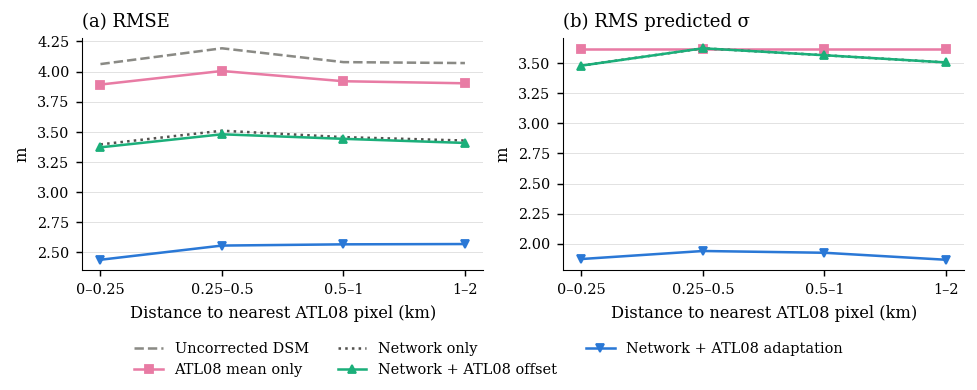

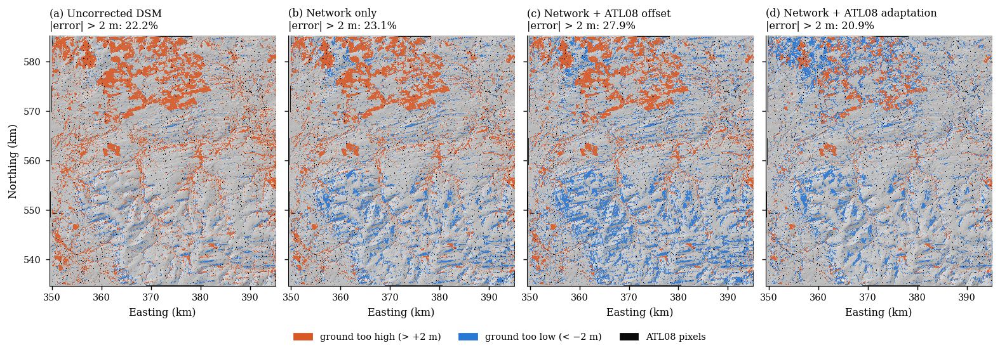



check: all-levels wrapper vs normal model, max |difference| 3.53e-03 m (should be ~0)
2,471,272 scored pixels (valid lidar, off the ATL08 pixels)
                            RMSE   MAE     ME  RMS σ  Cov. 95%   NLL  Share of gain
Network only               3.444 1.844  0.412  3.547     0.957 1.146          0.000
Network + ATL08 offset     3.421 2.060 -0.097  3.547     0.895 1.427          0.025
1 km level only            2.824 1.625 -0.195  2.306     0.894 1.571          0.662
4 km level only            2.530 1.478 -0.351  2.071     0.931 1.078          0.975
16 km level only           2.553 1.484 -0.374  1.872     0.920 1.128          0.951
Network + ATL08 adaptation 2.507 1.461 -0.361  1.903     0.927 1.092          1.000
share of gain = (RMSE network only − RMSE row) / (RMSE network only − RMSE full model)


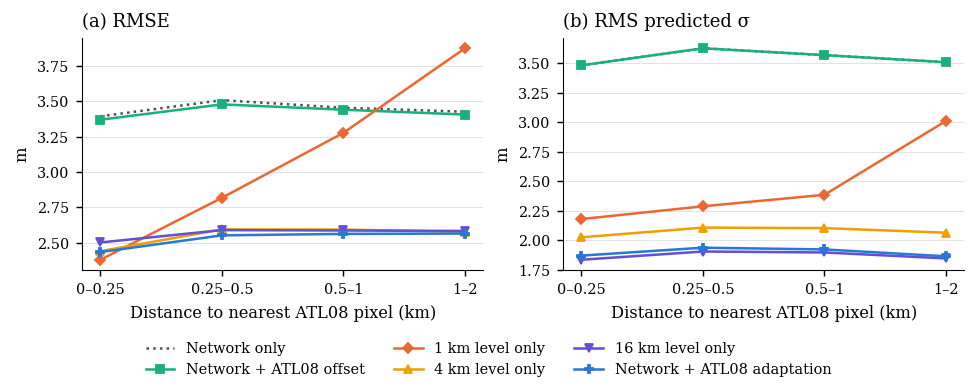

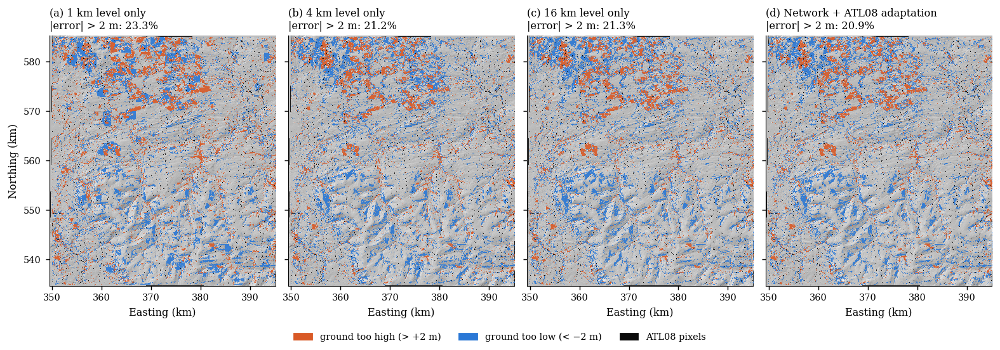



check: trained attention before vs after the swaps, max |difference| 4.23e-03 m (should be ~0)
2,471,272 scored pixels (valid lidar, off the ATL08 pixels)
                                    RMSE   MAE     ME  RMS σ  Cov. 95%   NLL  RMSE vs learned
Network + ATL08 adaptation         2.507 1.461 -0.361  1.903     0.927 1.092            0.000
Gaussian read ($\ell$ = 0.25 node) 2.445 1.439 -0.290  2.050     0.925 1.086           -0.063
Gaussian read ($\ell$ = 0.5 node)  2.442 1.441 -0.291  2.049     0.928 1.068           -0.065
Gaussian read ($\ell$ = 1 node)    2.474 1.458 -0.293  2.048     0.927 1.080           -0.034
Bilinear read                      2.438 1.439 -0.290  2.049     0.928 1.070           -0.069


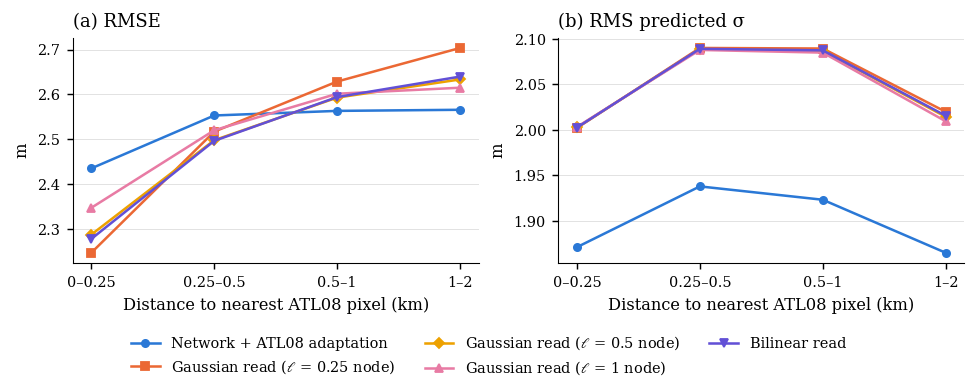

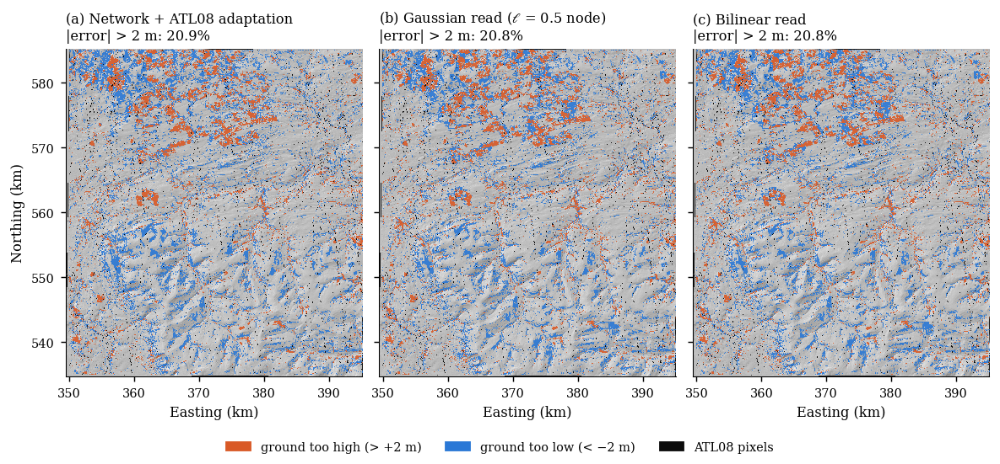

In [ ]:
paper_style()
CACHE = {}                                    # network-only and full model are predicted once, shared by all four
T1, P1 = ablation_context(model, S_B, OBS_B, CACHE)   # with vs without ATL08
print(f"\n{"="*50}\n")
T2, P2 = ablation_global(model, S_B, OBS_B, CACHE)    # DSM | ATL08 mean only | network | network + offset | full
print(f"\n{"="*50}\n")
T3, P3 = ablation_levels(model, S_B, OBS_B, CACHE)    # 1 / 4 / 16 km only vs all, with share of gain
print(f"\n{"="*50}\n")
T4, P4 = ablation_blend(model, S_B, OBS_B, CACHE)     # learned attention vs Gaussian (ℓ = 0.25/0.5/1) vs bilinear

  λ × 0.25  RMSE 2.499 m
  λ × 1     RMSE 2.507 m
  λ × 4     RMSE 2.533 m
  λ × 16    RMSE 2.574 m
  λ × 64    RMSE 2.621 m
  λ × 256   RMSE 2.681 m
check: trained λ restored, max |difference| 0.0e+00 (should be 0)

λ scaled on: all levels | trained λ [0.884 0.917 1.351] | lowest RMSE at λ × 0.25 (2.499 m vs 2.507 m as trained)
              RMSE     ME  cov95   NLL  RMSE 0–0.25 km  RMSE 0.25–0.5 km  RMSE 0.5–1 km  RMSE 1–2 km
λ multiplier                                                                                        
0.250        2.499 -0.364  0.926 1.092           2.424             2.547          2.557        2.565
1.000        2.507 -0.361  0.927 1.092           2.435             2.553          2.563        2.566
4.000        2.533 -0.351  0.925 1.104           2.464             2.576          2.588        2.582
16.000       2.574 -0.337  0.920 1.125           2.509             2.615          2.628        2.613
64.000       2.621 -0.318  0.914 1.151           2.559         

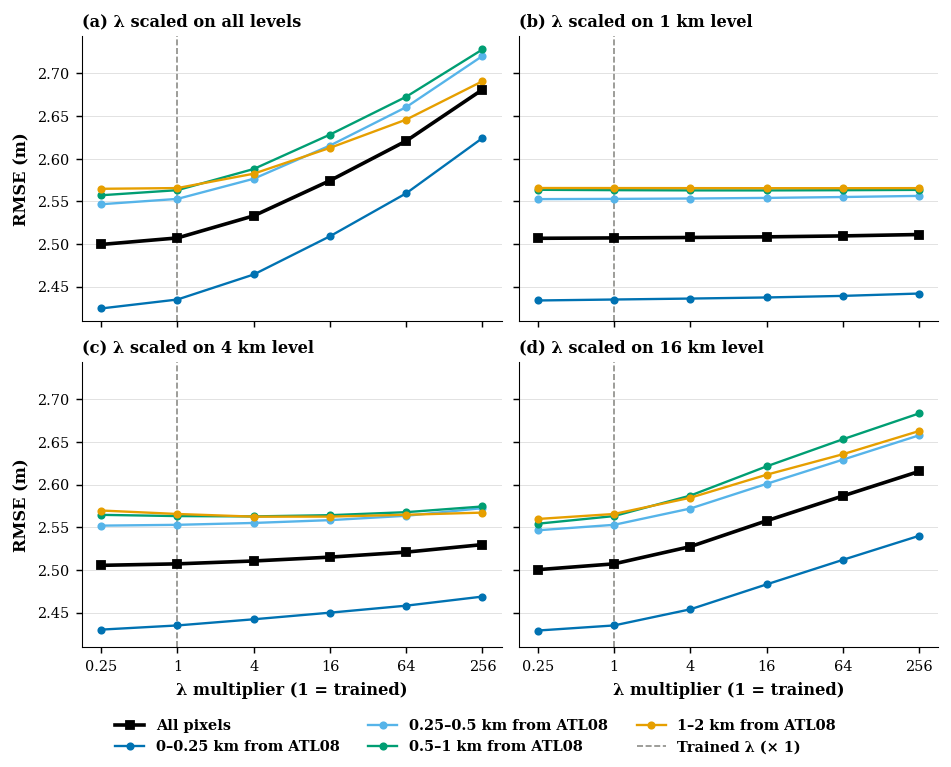

In [ ]:
import math
from contextlib import contextmanager
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.ndimage import distance_transform_edt

SCALES = (0.25, 1, 4, 16, 64, 256)
SWEEP_DIST_KM = (0, 0.25, 0.5, 1, 2, np.inf)


@contextmanager
def scaled_lambda(model, scale, levels=None):
    """λ_l × scale on the chosen levels (all if None) inside the block; trained values restored afterwards."""
    orig = model.log_lam.data.clone()
    try:
        with torch.no_grad():
            for li in (range(len(orig)) if levels is None else levels):
                model.log_lam.data[li] = orig[li] + math.log(scale)
        yield
    finally:
        model.log_lam.data.copy_(orig)


def lambda_sweep_site(model, S, OBS, scales=SCALES, levels=None, dist_edges=SWEEP_DIST_KM, min_px=200):
    """One dense prediction per multiplier. Returns a DataFrame (pooled metrics + RMSE per distance class)."""
    assert 1 in scales, "keep 1 (= the trained λ) in the scales: it is the reference"
    model.eval()
    sel = _score_mask(S, OBS, {})
    tgt = S["target"][sel].astype(np.float64)
    dist = (distance_transform_edt(~OBS["obs_mask"]) * S["pixel_m"] / 1000)[sel]
    b = np.digitize(dist, np.asarray(dist_edges)[1:-1])
    keep = [j for j in range(len(dist_edges) - 1) if (b == j).sum() >= min_px]
    lab = [f"{dist_edges[j]:g}–{dist_edges[j + 1]:g} km".replace("inf", "∞") for j in keep]
    od = np.ascontiguousarray(OBS["obs_dh"], np.float32); om = np.ascontiguousarray(OBS["obs_mask"], bool)
    lam0 = model.log_lam.exp().detach().cpu().numpy().copy()
    rows = {}
    for s in scales:
        with scaled_lambda(model, s, levels):
            mu, sg = run_calibrator(model, S["Xn"], od, om)
        e = mu[sel].astype(np.float64) - tgt
        s2 = sg[sel].astype(np.float64) ** 2
        r = dict(RMSE=np.sqrt(np.mean(e ** 2)), ME=e.mean(), cov95=np.mean(np.abs(e) <= 1.96 * np.sqrt(s2)),
                 NLL=np.mean(0.5 * (np.log(s2) + e ** 2 / s2)))
        r.update({f"RMSE {l}": np.sqrt(np.mean(e[b == j] ** 2)) for l, j in zip(lab, keep)})
        rows[s] = r
        print(f"  λ × {s:<5g} RMSE {r['RMSE']:.3f} m")
    back = np.abs(model.log_lam.exp().detach().cpu().numpy() - lam0).max()
    print(f"check: trained λ restored, max |difference| {back:.1e} (should be 0)")
    df = pd.DataFrame(rows).T
    df.index.name = "λ multiplier"
    df.attrs.update(levels=levels, lam0=lam0, dist_labels=lab)
    which = "all levels" if levels is None else (", ".join(f"{model.level_res_m[i] / 1000:g} km" for i in levels) + (" level" if len(levels) == 1 else " levels"))
    df.attrs["which"] = which
    best = df["RMSE"].idxmin()
    print(f"\nλ scaled on: {which} | trained λ {np.round(lam0, 3)} | lowest RMSE at λ × {best:g} "
          f"({df.loc[best, 'RMSE']:.3f} m vs {df.loc[1, 'RMSE']:.3f} m as trained)")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.to_string())
    return df


BOLD = dict(fontweight="bold")
# CHANGED: Okabe-Ito colour-blind-safe colours, near -> far from the ATL08 tracks
DIST_COLOURS = ("#0072B2", "#56B4E9", "#009E73", "#E69F00", "#D55E00")


def plot_lambda_sweeps(sweeps, ref_rmse=None, ncols=2):
    """CHANGED (design only): sweeps on a grid of ncols columns (2 x 2 for four sweeps), shared axes, one legend
    at the bottom. Each panel: pooled RMSE (black) and RMSE per distance class to the nearest ATL08 pixel
    against the λ multiplier (log scale); dashed line = the trained λ (× 1).
    ref_rmse: optional network-only RMSE, drawn as a dotted grey line (B6)."""
    n = len(sweeps)
    ncols = min(ncols, n); nrows = math.ceil(n / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 2.55 * nrows + 0.7), sharex=True, sharey=True,
                             constrained_layout=True, squeeze=False)
    handles = {}
    for i, df in enumerate(sweeps):
        ax = axes[i // ncols][i % ncols]
        x = df.index.to_numpy(float)
        ax.axvline(1, color="#8a8a85", ls="--", lw=0.9, zorder=1)
        handles.setdefault("Trained λ (× 1)", Line2D([], [], color="#8a8a85", ls="--", lw=0.9))
        if ref_rmse is not None:
            ax.axhline(ref_rmse, color="#52514e", ls=":", lw=1.2, zorder=1)
            handles.setdefault("Network only (B6)", Line2D([], [], color="#52514e", ls=":", lw=1.2))
        for c, l in zip(DIST_COLOURS, df.attrs["dist_labels"]):
            h, = ax.plot(x, df[f"RMSE {l}"], color=c, marker="o", ms=3.5, lw=1.3, zorder=2)
            handles.setdefault(f"{l} from ATL08", h)
        h, = ax.plot(x, df["RMSE"], color="#000000", marker="s", ms=4, lw=2.0, zorder=3)
        handles.setdefault("All pixels", h)
        ax.set_xscale("log"); ax.set_xticks(x); ax.set_xticklabels([f"{v:g}" for v in x])
        ax.minorticks_off(); ax.grid(True, axis="y"); ax.set_axisbelow(True)
        ax.set_title(f"({'abcdefgh'[i]}) λ scaled on {df.attrs['which']}", fontsize=9, **BOLD)
        if i // ncols == nrows - 1 or i + ncols >= n:          # bottom panel of its column
            ax.set_xlabel("λ multiplier (1 = trained)", **BOLD)
            ax.tick_params(labelbottom=True)
        if i % ncols == 0:
            ax.set_ylabel("RMSE (m)", **BOLD)
    for j in range(n, nrows * ncols):                          # empty cell when n is odd
        axes[j // ncols][j % ncols].set_visible(False)
    order = ["All pixels"] + [k for k in handles if k.endswith("from ATL08")] + \
            [k for k in ("Network only (B6)", "Trained λ (× 1)") if k in handles]
    fig.legend([handles[k] for k in order], order, loc="outside lower center", ncol=3,
               prop={"weight": "bold"}, frameon=False)
    plt.show()


paper_style()
SWEEP_ALL = lambda_sweep_site(model, S_B, OBS_B)                 # λ × scale on all three levels
print(f"\n{"="*50}\n")
SWEEP_1KM = lambda_sweep_site(model, S_B, OBS_B, levels=[0])     # only the 1 km level
print(f"\n{"="*50}\n")
SWEEP_4KM = lambda_sweep_site(model, S_B, OBS_B, levels=[1])     # only the 4 km level
print(f"\n{"="*50}\n")
SWEEP_16KM = lambda_sweep_site(model, S_B, OBS_B, levels=[2])     # only the 16 km level
print(f"\n{"="*50}\n")
plot_lambda_sweeps([SWEEP_ALL, SWEEP_1KM, SWEEP_4KM, SWEEP_16KM])

         Pixels  Share  RMSE | Copernicus GLO-30 DSM  Bias | Copernicus GLO-30 DSM  RMSE | FABDEM  Bias | FABDEM  RMSE | Network + ATL08 adaptation  Bias | Network + ATL08 adaptation
Slope                                                                                                                                                                                 
0–5°    1225791  49.6%                         3.127                         0.717          2.152         -0.080                              1.888                             -0.133
5–10°    868819  35.2%                         4.143                         1.215          2.762          0.191                              2.626                             -0.535
10–20°   344886  14.0%                         5.861                         2.329          3.892          0.929                              3.516                             -0.733
20°+      31776   1.3%                         9.591                         5.627   

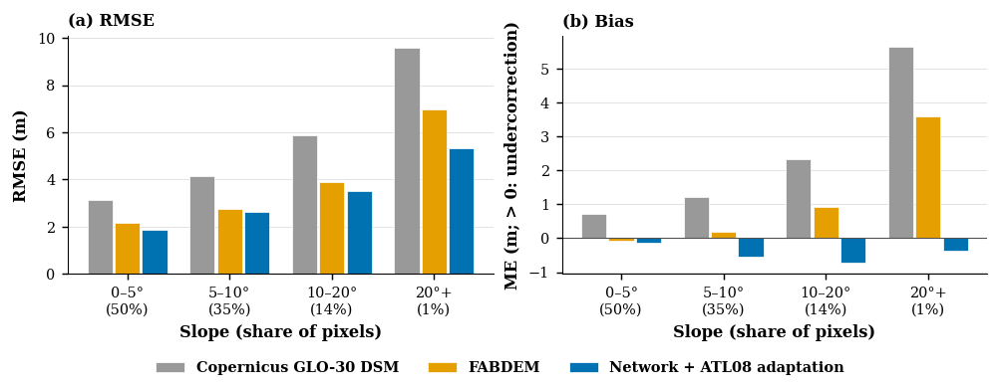

block 0: 520 ICESat px | 85,080 scored px
block 1: 370 ICESat px | 85,518 scored px
block 2: 436 ICESat px | 80,538 scored px
        Pixels  Share  RMSE | Copernicus GLO-30 DSM  Bias | Copernicus GLO-30 DSM  RMSE | Network only (B6)  Bias | Network only (B6)  RMSE | Network + ATL08 adaptation  Bias | Network + ATL08 adaptation
Slope                                                                                                                                                                                                      
0–5°    187159  75.0%                         5.186                         1.908                     3.976                     1.237                              1.658                              0.155
5–10°    43251  17.3%                         9.653                         7.061                     7.352                     5.015                              3.040                              0.090
10–20°   18552   7.4%                        10.288       

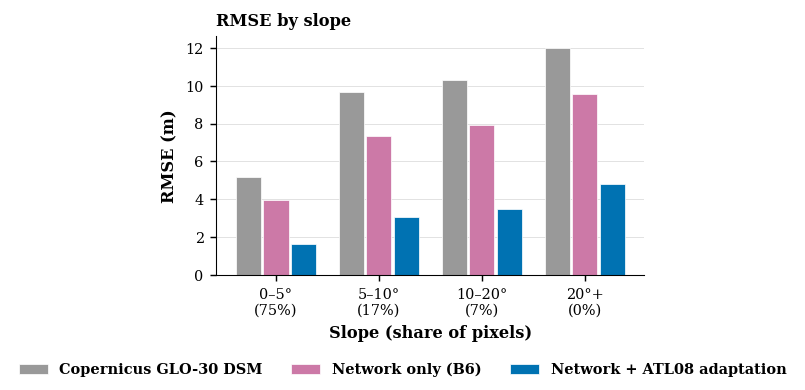

(1) the anomaly class against the reference class
                          canopy 0-2 m  canopy 2-5 m
pixels                       34902.000    477195.000
share_site                       0.014         0.193
dh_mean                         -3.831        -0.067
dh_median                       -0.048         0.243
share_dh_below_m5                0.270         0.024
share_dh_above_p2                0.014         0.048
bldg_share                       0.082         0.023
slope_median                     3.283         4.260
lai_median                       1.000         1.300
evi_median                       0.249         0.453
dist_tall_median_m              90.000       108.167
share_within_60m_of_tall         0.278         0.234
RMSE_dsm                         7.919         2.570
RMSE_ours                        4.673         1.923
share_of_our_sq_error            0.049         0.114
RMSE_fabdem                      4.313         1.821

(2) inside the anomaly class: where does the err

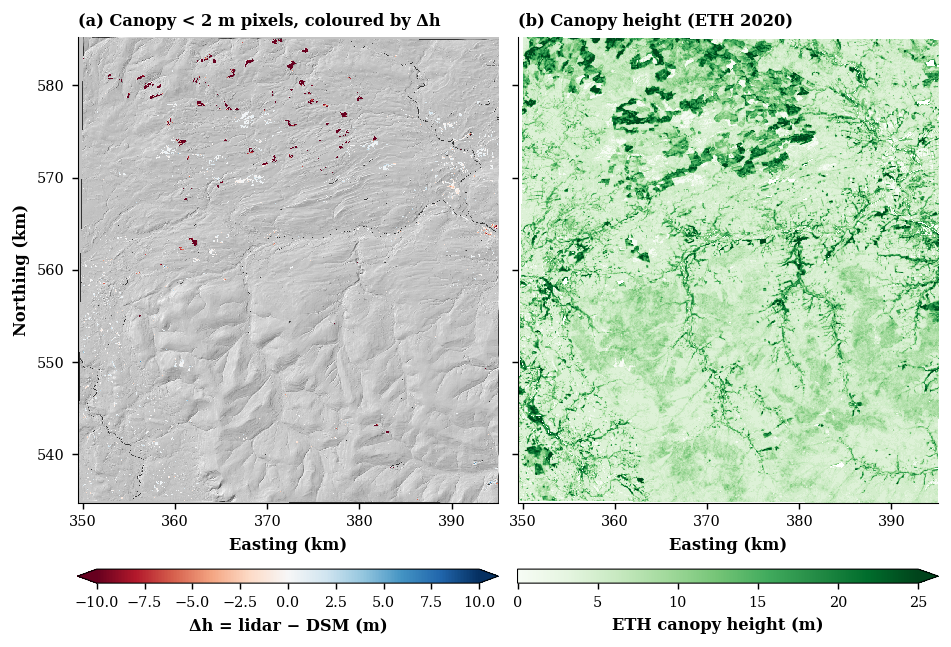

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from scipy.ndimage import distance_transform_edt, label as cc_label

SLOPE_EDGES = (0, 5, 10, 20, np.inf)
# CHANGED: Okabe-Ito colour-blind-safe colours for the bar charts (maps keep their colour scales)
METHOD_STYLE = {                                      # name in P -> (label, colour)
    "uncorrected DSM": ("Copernicus GLO-30 DSM", "#999999"),     # grey
    "FABDEM": ("FABDEM", "#E69F00"),                             # orange
    "M0 network alone": ("Network only (B6)", "#CC79A7"),        # reddish purple
    "M0 full": ("Network + ATL08 adaptation", "#0072B2"),        # blue
}
BOLD = dict(fontweight="bold")                        # NEW: bold axis labels, panel titles, legend, colourbar labels


def stack_band(feat_path, band, S=None):
    """One raw band (1-based) of a site's stack, NaN where invalid (same grid as S if given)."""
    a, ok, _ = read_raster(feat_path, band)
    a = np.where(ok, a, np.nan).astype(np.float32)
    if S is not None:
        assert a.shape == (S["H"], S["W"]), "band is not on the site grid"
    return a


# ---------- (1) error by slope class --------------------------------------------------------------------------
def _class_stats(items, key, edges, methods, min_px=200):
    """Pooled over items [(P, S, OBS)]: per class and method RMSE and bias, plus each class's pixel share."""
    E = {m: [] for m in methods}; V = []
    for P, S, OBS in items:
        sel = _score_mask(S, OBS, {m: P[m] for m in methods}) & np.isfinite(S[key])
        V.append(S[key][sel])
        for m in methods:
            E[m].append((P[m]["mu"] - S["target"])[sel].astype(np.float64))
    v = np.concatenate(V); cls = np.digitize(v, np.asarray(edges)[1:-1])
    labels = [f"{edges[j]:g}–{edges[j + 1]:g}°".replace("–inf°", "°+").replace("inf", "∞") for j in range(len(edges) - 1)]
    keep = [j for j in range(len(labels)) if (cls == j).sum() >= min_px]
    rows = []
    for j in keep:
        r = {"Slope": labels[j], "Pixels": int((cls == j).sum()), "Share": np.mean(cls == j)}
        for m in methods:
            e = np.concatenate(E[m])[cls == j]
            r[f"RMSE | {METHOD_STYLE.get(m, (m,))[0]}"] = np.sqrt(np.mean(e ** 2))
            r[f"Bias | {METHOD_STYLE.get(m, (m,))[0]}"] = e.mean()
        rows.append(r)
    return pd.DataFrame(rows).set_index("Slope")


def plot_by_slope(items, methods, edges=SLOPE_EDGES, show_bias=True, title_site=None):
    """Grouped bars per slope class: (a) RMSE, (b) mean error (if show_bias). Pixel share under each class."""
    df = _class_stats(items, "slope", edges, methods)
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.assign(Share=df["Share"].map("{:.1%}".format)).to_string())
    n_pan = 2 if show_bias else 1
    fig, axes = plt.subplots(1, n_pan, figsize=(3.8 * n_pan, 2.9), constrained_layout=True, squeeze=False)
    x = np.arange(len(df)); w = 0.8 / len(methods)
    for k, (stat, ax) in enumerate(zip(("RMSE", "Bias")[:n_pan], axes[0])):
        for i, m in enumerate(methods):
            lab, col = METHOD_STYLE.get(m, (m, "#52514e"))
            ax.bar(x + (i - (len(methods) - 1) / 2) * w, df[f"{stat} | {lab}"], width=w * 0.92, color=col,
                   edgecolor="white", linewidth=0.4, label=lab)
        ax.set_xticks(x)
        ax.set_xticklabels([f"{s}\n({sh:.0%})" for s, sh in zip(df.index, df["Share"])])
        ax.set_xlabel("Slope (share of pixels)", **BOLD); ax.grid(True, axis="y"); ax.set_axisbelow(True)
        if stat == "Bias":
            ax.axhline(0, color="#52514e", lw=0.6)
            ax.set_ylabel("ME (m; > 0: undercorrection)", **BOLD); ax.set_title("(b) Bias", fontsize=9, **BOLD)
        else:
            ax.set_ylabel("RMSE (m)", **BOLD); ax.set_title("(a) RMSE" if show_bias else "RMSE by slope", fontsize=9, **BOLD)
    h, l = axes[0][0].get_legend_handles_labels()
    fig.legend(h, l, loc="outside lower center", ncol=min(len(methods), 3), frameon=False, prop={"weight": "bold"})
    plt.show()
    return df


def tileA_slope_items(model, episodes, slope_full, canopy_full, bldg_full):
    """Tile A block episodes as (P, S, OBS) with slope attached (no classical baselines)."""
    items = episode_items(model, episodes, canopy_full, bldg_full, classical=False)
    for (P, S, OBS), e in zip(items, episodes):
        y0, x0 = e["origin"]
        S["slope"] = slope_full[y0:y0 + S["H"], x0:x0 + S["W"]].astype(np.float32)
    return items


# ---------- (2) the canopy 0-2 m anomaly at site B -------------------------------------------------------------
def anomaly_tables(S, OBS, P, feat_path, lo=0.0, hi=2.0, tall_m=5.0, ref=(2.0, 5.0)):
    """Compares the canopy lo-hi m pixels with the reference class `ref`, then splits the anomaly class by
    building / distance to tall canopy / slope / sign of delta_h, showing where its error lives."""
    sel = _score_mask(S, OBS, {m: P[m] for m in ("uncorrected DSM", "FABDEM", "M0 full") if m in P})
    slope = stack_band(feat_path, 2, S); lai = stack_band(feat_path, 6, S); evi = stack_band(feat_path, 7, S)
    bldg = S["bldg"]
    tall = S["canopy"] > tall_m
    d_tall = distance_transform_edt(~tall) * S["pixel_m"]                  # m to the nearest canopy > tall_m
    dh = S["target"]
    can = S["canopy"]
    cls = sel & (can >= lo) & (can < hi)
    refm = sel & (can >= ref[0]) & (can < ref[1])
    e_dsm = -dh                                                            # DSM error = 0 - delta_h
    e_our = P["M0 full"]["mu"] - dh
    e_fab = P["FABDEM"]["mu"] - dh if "FABDEM" in P else None
    tot_sq_our = np.sum(e_our[sel] ** 2)

    def describe(m):
        r = dict(pixels=int(m.sum()), share_site=m.sum() / sel.sum(),
                 dh_mean=dh[m].mean(), dh_median=np.median(dh[m]), share_dh_below_m5=np.mean(dh[m] < -5),
                 share_dh_above_p2=np.mean(dh[m] > 2), bldg_share=np.mean(bldg[m] > 0),
                 slope_median=np.nanmedian(slope[m]), lai_median=np.nanmedian(lai[m]), evi_median=np.nanmedian(evi[m]),
                 dist_tall_median_m=np.median(d_tall[m]), share_within_60m_of_tall=np.mean(d_tall[m] <= 60),
                 RMSE_dsm=np.sqrt(np.mean(e_dsm[m] ** 2)), RMSE_ours=np.sqrt(np.mean(e_our[m] ** 2)),
                 share_of_our_sq_error=np.sum(e_our[m] ** 2) / tot_sq_our)
        if e_fab is not None:
            r["RMSE_fabdem"] = np.sqrt(np.mean(e_fab[m] ** 2))
        return r

    T1 = pd.DataFrame({f"canopy {lo:g}-{hi:g} m": describe(cls), f"canopy {ref[0]:g}-{ref[1]:g} m": describe(refm)})
    print("(1) the anomaly class against the reference class")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(T1.to_string())

    groups = {
        "building > 0 m": bldg > 0, "no building": bldg <= 0,
        "within 60 m of canopy > 5 m": d_tall <= 60, "more than 60 m from tall canopy": d_tall > 60,
        "slope >= 10°": slope >= 10, "slope < 10°": slope < 10,
        "delta_h < -5 m (DSM far above ground)": dh < -5, "-5 <= delta_h <= 2 m": (dh >= -5) & (dh <= 2),
        "delta_h > 2 m (DSM below ground)": dh > 2,
    }
    rows = {}
    for name, g in groups.items():
        m = cls & g
        if m.sum() < 50:
            continue
        rows[name] = dict(pixels=int(m.sum()), share_of_class=m.sum() / cls.sum(),
                          share_of_class_sq_err_ours=np.sum(e_our[m] ** 2) / np.sum(e_our[cls] ** 2),
                          dh_mean=dh[m].mean(), RMSE_dsm=np.sqrt(np.mean(e_dsm[m] ** 2)),
                          RMSE_ours=np.sqrt(np.mean(e_our[m] ** 2)),
                          **({"RMSE_fabdem": np.sqrt(np.mean(e_fab[m] ** 2))} if e_fab is not None else {}))
    T2 = pd.DataFrame(rows).T
    print("\n(2) inside the anomaly class: where does the error live?")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(T2.to_string())
    return T1, T2, dict(slope=slope, lai=lai, evi=evi, d_tall=d_tall, cls=cls)


def anomaly_patches(S, OBS, P, extra, dh_thresh=-5.0, min_px=10, top=12):
    """Connected patches of anomaly pixels with delta_h < dh_thresh (DSM far above the lidar ground), largest
    first: area, centre (BNG km, to look up in aerial imagery), mean delta_h, building / LAI / EVI, errors."""
    m = extra["cls"] & (S["target"] < dh_thresh)
    lab, n = cc_label(m)
    if n == 0:
        print("no patches"); return pd.DataFrame()
    sizes = np.bincount(lab.ravel())[1:]
    T = S["transform"]; rows = []
    for k in np.argsort(sizes)[::-1][:top]:
        if sizes[k] < min_px:
            break
        pix = lab == k + 1
        rr, cc = np.nonzero(pix)
        rows.append(dict(area_ha=sizes[k] * S["pixel_m"] ** 2 / 1e4,
                         east_km=(T.c + (cc.mean() + 0.5) * T.a) / 1000, north_km=(T.f + (rr.mean() + 0.5) * T.e) / 1000,
                         dh_mean=S["target"][pix].mean(), bldg_mean=S["bldg"][pix].mean(),
                         lai=np.nanmean(extra["lai"][pix]), evi=np.nanmean(extra["evi"][pix]),
                         slope=np.nanmean(extra["slope"][pix]), dist_tall_m=extra["d_tall"][pix].mean(),
                         err_ours=np.mean(P["M0 full"]["mu"][pix] - S["target"][pix]),
                         err_fabdem=np.mean(P["FABDEM"]["mu"][pix] - S["target"][pix]) if "FABDEM" in P else np.nan))
    df = pd.DataFrame(rows)
    print(f"{n:,} patches of canopy < 2 m with delta_h < {dh_thresh:g} m; the {len(df)} largest:")
    with pd.option_context("display.float_format", "{:.2f}".format, "display.width", 200):
        print(df.to_string())
    return df


def plot_anomaly_map(S, extra, window_km=None, dh_lim=10.0):
    """(a) where the canopy 0-2 m pixels are, coloured by delta_h (lidar - DSM), over a hillshade;
    (b) the canopy map (ETH) of the same area."""
    ext = _extent_km(S)
    hs = _hillshade(np.where(S["dsm_ok"], S["dsm"], np.nan), S["pixel_m"])
    dh = np.where(extra["cls"], S["target"], np.nan)
    a = (S["H"] / S["W"]) if window_km is None else (window_km[3] - window_km[2]) / (window_km[1] - window_km[0])
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 3.6 * a + 0.9), constrained_layout=True)
    a1.imshow(hs, cmap="gray", vmin=0, vmax=1, extent=ext, interpolation="nearest", alpha=0.8)
    im = a1.imshow(dh, cmap="RdBu", vmin=-dh_lim, vmax=dh_lim, extent=ext, interpolation="nearest")
    cb = fig.colorbar(im, ax=a1, orientation="horizontal", fraction=0.05, pad=0.03, aspect=30, extend="both")
    cb.set_label("Δh = lidar − DSM (m)", **BOLD)
    a1.set_title("(a) Canopy < 2 m pixels, coloured by Δh", fontsize=9, **BOLD)
    im2 = a2.imshow(np.where(S["dsm_ok"], S["canopy"], np.nan), cmap="Greens", vmin=0, vmax=25, extent=ext,
                    interpolation="nearest")
    cb2 = fig.colorbar(im2, ax=a2, orientation="horizontal", fraction=0.05, pad=0.03, aspect=30, extend="max")
    cb2.set_label("ETH canopy height (m)", **BOLD)
    a2.set_title("(b) Canopy height (ETH 2020)", fontsize=9, **BOLD)
    for i, ax in enumerate((a1, a2)):
        if window_km is not None:
            ax.set_xlim(window_km[0], window_km[1]); ax.set_ylim(window_km[2], window_km[3])
        ax.set_aspect("equal"); ax.set_xlabel("Easting (km)", **BOLD)
        if i == 0:
            ax.set_ylabel("Northing (km)", **BOLD)
        else:
            ax.tick_params(labelleft=False)
    plt.show()


# ---------- run -------------
paper_style()
FEAT_B = TILE_1["feat"]                                  # site B's stack (the same file used for S_B)

# (1a) site B: DSM, FABDEM, ours by slope; RMSE and bias, pixel share under each class
S_B["slope"] = stack_band(FEAT_B, 2, S_B)
SLOPE_B = plot_by_slope([(P_B, S_B, OBS_B)], ["uncorrected DSM", "FABDEM", "M0 full"])

# (1b) tile A test blocks: DSM, network only, ours; RMSE only
SLOPE_A_FULL = np.where(features_valid[1], features[1], np.nan)
CANOPY_A = np.where(features_valid[4], features[4], 0.0)
BLDG_A = np.where(features_valid[7], features[7], 0.0)
ITEMS_A_SLOPE = tileA_slope_items(model, TEST_SET[1:], SLOPE_A_FULL, CANOPY_A, BLDG_A)
SLOPE_A = plot_by_slope(ITEMS_A_SLOPE, ["uncorrected DSM", "M0 network alone", "M0 full"], show_bias=False)

# (2) the anomaly
AN_T1, AN_T2, AN_X = anomaly_tables(S_B, OBS_B, P_B, FEAT_B)
AN_PATCHES = anomaly_patches(S_B, OBS_B, P_B, AN_X)
plot_anomaly_map(S_B, AN_X)


Gaussian reference: |z| > 3 for 0.27% of pixels
                           Pixels  RMSE (m)  RMS σ (m)  mean z  SD z  cov 50%  cov 68%  cov 80%  cov 90%  cov 95%  cov 99%  max |cov − nominal| (pp)  |z| > 3  sq. error in |z| > 3   NLL
Site A (simulated ATL08)   251136     2.145      1.879   0.081 1.173    0.529    0.707    0.820    0.908    0.949    0.982                     2.876    0.011                 0.201 1.691
Site B (real ATL08)       2471272     2.507      1.903  -0.234 1.311    0.484    0.660    0.777    0.875    0.927    0.971                     2.453    0.019                 0.319 2.011


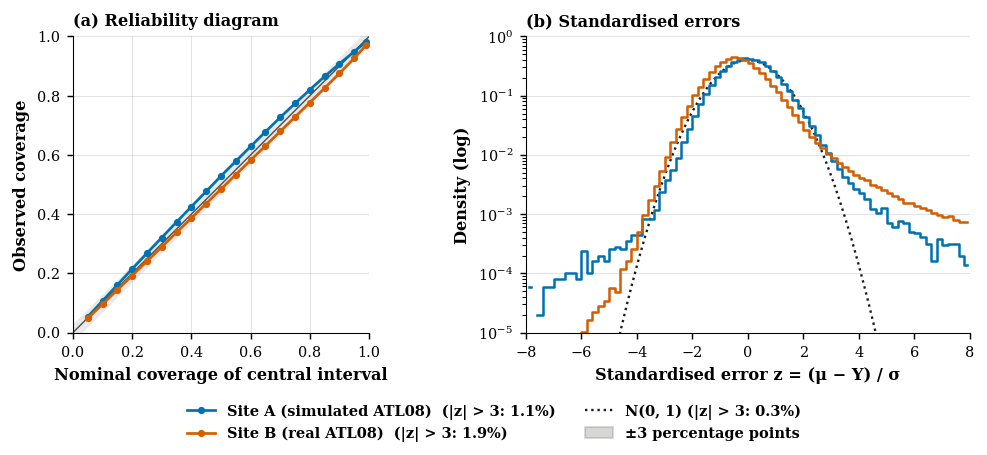

In [ ]:
# calibration plots
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import norm

BOLD = dict(fontweight="bold")
SITE_COLOURS = ("#0072B2", "#D55E00", "#009E73", "#CC79A7")           # Okabe-Ito: blue, vermillion, green, purple
METHOD_LINES = {"M0 full": ("ours", "-"), "M0 network alone": ("network only", "--")}
LEVELS = (0.50, 0.68, 0.80, 0.90, 0.95, 0.99)


def pooled_errors(items, method="M0 full"):
    """Errors e = mu - truth and sigma, pooled over items [(P, S, OBS)] on the scored pixels."""
    E, SG = [], []
    for P, S, OBS in items:
        sel = _score_mask(S, OBS, {method: P[method]}) & np.isfinite(P[method]["sigma"])
        E.append((P[method]["mu"] - S["target"])[sel].astype(np.float64))
        SG.append(P[method]["sigma"][sel].astype(np.float64))
    return np.concatenate(E), np.concatenate(SG)


def calibration_table(sites, methods=("M0 full",), levels=LEVELS, z_tail=3.0):
    """One row per site (and method): pixels, RMSE, RMS sigma, mean and SD of z, observed coverage at each
    nominal level, share of pixels with |z| > z_tail and the share of the squared error they carry, Gaussian NLL."""
    rows = {}
    for site, items in sites.items():
        for m in methods:
            e, s = pooled_errors(items, m)
            z = e / s
            tail = np.abs(z) > z_tail
            r = {"Pixels": len(e), "RMSE (m)": np.sqrt(np.mean(e ** 2)), "RMS σ (m)": np.sqrt(np.mean(s ** 2)),
                 "mean z": z.mean(), "SD z": z.std()}
            r.update({f"cov {p:.0%}": np.mean(np.abs(z) <= norm.ppf(0.5 + p / 2)) for p in levels})
            r["max |cov − nominal| (pp)"] = 100 * max(abs(r[f"cov {p:.0%}"] - p) for p in levels)
            r[f"|z| > {z_tail:g}"] = tail.mean()
            r[f"sq. error in |z| > {z_tail:g}"] = np.sum(e[tail] ** 2) / np.sum(e ** 2)
            r["NLL"] = np.mean(0.5 * np.log(2 * np.pi * s ** 2) + 0.5 * z ** 2)
            rows[site if len(methods) == 1 else f"{site} | {METHOD_LINES.get(m, (m,))[0]}"] = r
    df = pd.DataFrame(rows).T
    df["Pixels"] = df["Pixels"].astype(int)
    print(f"Gaussian reference: |z| > {z_tail:g} for {2 * norm.sf(z_tail):.2%} of pixels")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 250):
        print(df.to_string())
    return df


def plot_calibration(sites, methods=("M0 full",), z_lim=8.0, band_pp=3.0, z_tail=3.0):
    """(a) reliability diagram, one line per site (and method), shaded ±band_pp around the diagonal;
    (b) histogram of z on a log scale with the standard normal; the legend gives each site's |z| > z_tail share."""
    p = np.r_[np.arange(0.05, 0.951, 0.05), 0.99]
    bins = np.linspace(-z_lim, z_lim, 81); bw = bins[1] - bins[0]; zc = (bins[:-1] + bins[1:]) / 2
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.4), constrained_layout=True)

    a1.fill_between([0, 1], [-band_pp / 100, 1 - band_pp / 100], [band_pp / 100, 1 + band_pp / 100],
                    color="#8a8a85", alpha=0.18, lw=0)
    a1.plot([0, 1], [0, 1], color="#52514e", lw=0.8)
    xx = np.linspace(-z_lim, z_lim, 400)
    a2.plot(xx, norm.pdf(xx), color="#1a1a19", ls=":", lw=1.3)

    handles = []
    for k, (site, items) in enumerate(sites.items()):
        col = SITE_COLOURS[k % len(SITE_COLOURS)]
        for m in methods:
            lab_m, ls = METHOD_LINES.get(m, (m, "-"))
            e, s = pooled_errors(items, m)
            z = e / s
            obs = [np.mean(np.abs(z) <= norm.ppf(0.5 + q / 2)) for q in p]
            a1.plot(p, obs, color=col, ls=ls, marker="o", ms=3, lw=1.5)
            h, _ = np.histogram(z, bins=bins)
            a2.step(zc, np.where(h > 0, h / (len(z) * bw), np.nan), where="mid", color=col, ls=ls, lw=1.4)
            name = site if len(methods) == 1 else f"{site}, {lab_m}"
            handles.append(Line2D([], [], color=col, ls=ls, marker="o", ms=3, lw=1.5,
                                  label=f"{name}  (|z| > {z_tail:g}: {np.mean(np.abs(z) > z_tail):.1%})"))

    a1.set_xlim(0, 1); a1.set_ylim(0, 1); a1.set_aspect("equal"); a1.grid(True)
    a1.set_xlabel("Nominal coverage of central interval", **BOLD); a1.set_ylabel("Observed coverage", **BOLD)
    a1.set_title("(a) Reliability diagram", fontsize=9, **BOLD)
    a2.set_yscale("log"); a2.set_xlim(-z_lim, z_lim); a2.set_ylim(1e-5, 1.0); a2.grid(True, axis="y")
    a2.set_xlabel("Standardised error z = (μ − Y) / σ", **BOLD); a2.set_ylabel("Density (log)", **BOLD)
    a2.set_title("(b) Standardised errors", fontsize=9, **BOLD)

    handles += [Line2D([], [], color="#1a1a19", ls=":", lw=1.3,
                       label=f"N(0, 1) (|z| > {z_tail:g}: {2 * norm.sf(z_tail):.1%})"),
                Patch(color="#8a8a85", alpha=0.35, label=f"±{band_pp:g} percentage points")]
    fig.legend(handles=handles, loc="outside lower center", ncol=2 if len(handles) <= 4 else 3, frameon=False, prop={"weight": "bold"})
    plt.show()


# ---------- run -----------------------------------------------------------------------------------------------------
paper_style()
if "ITEMS_A_SLOPE" in globals():                         # already built in the slope cell
    ITEMS_A = ITEMS_A_SLOPE
else:
    CANOPY_A = np.where(features_valid[4], features[4], 0.0)
    BLDG_A = np.where(features_valid[7], features[7], 0.0)
    ITEMS_A = episode_items(model, TEST_SET[1:], CANOPY_A, BLDG_A, classical=False)

CAL_SITES = {"Site A (simulated ATL08)": ITEMS_A,          # keep the names short: they go in the legend
             "Site B (real ATL08)": [(P_B, S_B, OBS_B)]}
CAL_T = calibration_table(CAL_SITES)
plot_calibration(CAL_SITES)


(a, b) σ against distance to the nearest ATL08 pixel
                    Method    Distance  Pixels Share  RMS σ (m)  RMSE (m)  Cov. 95%  RMSE / RMS σ
         Network only (B6)   0–0.25 km   36788 14.6%      4.306     4.691     0.977         1.089
         Network only (B6) 0.25–0.5 km   29881 11.9%      4.337     4.681     0.981         1.079
         Network only (B6)    0.5–1 km   57500 22.9%      4.297     4.805     0.971         1.118
         Network only (B6)      1–2 km   88985 35.4%      4.213     4.740     0.973         1.125
         Network only (B6)       2+ km   37982 15.1%      5.699     6.733     0.964         1.181
Network + ATL08 adaptation   0–0.25 km   36788 14.6%      1.789     1.887     0.961         1.055
Network + ATL08 adaptation 0.25–0.5 km   29881 11.9%      1.807     1.985     0.957         1.099
Network + ATL08 adaptation    0.5–1 km   57500 22.9%      1.818     2.188     0.950         1.204
Network + ATL08 adaptation      1–2 km   88985 35.4%      1.808  

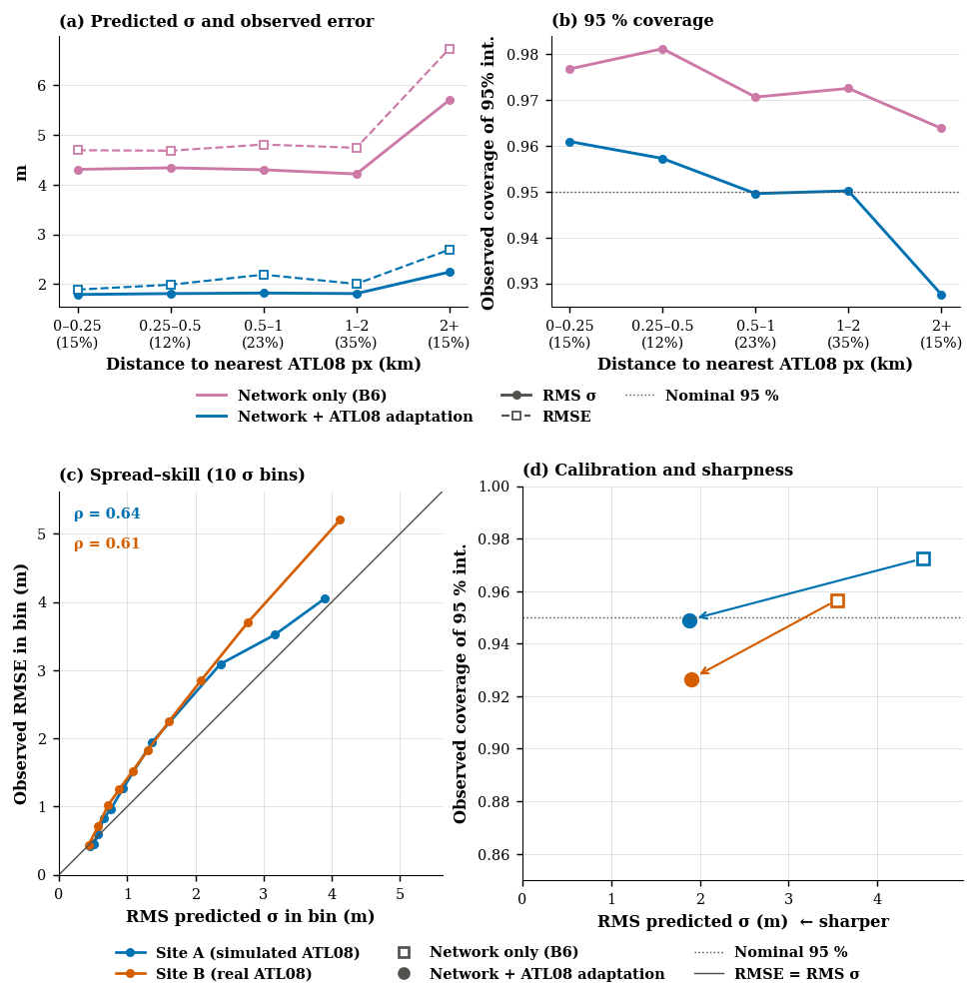

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.ndimage import distance_transform_edt
from scipy.stats import norm, spearmanr

DIST_EDGES_KM = (0, 0.25, 0.5, 1, 2, np.inf)
METHOD_COLOURS = {"M0 full": "#0072B2", "M0 network alone": "#CC79A7"}       # blue / reddish purple
METHOD_NAMES = {"M0 full": "Network + ATL08 adaptation", "M0 network alone": "Network only (B6)"}
Z95 = norm.ppf(0.975)


def _crps(e, s):
    z = e / s
    return s * (z * (2 * norm.cdf(z) - 1) + 2 * norm.pdf(z) - 1 / np.sqrt(np.pi))


def _pooled_with_distance(items, method):
    """e = mu - truth, sigma and distance (km) to the nearest ATL08 pixel, pooled over items, scored pixels."""
    E, SG, D = [], [], []
    for P, S, OBS in items:
        sel = _score_mask(S, OBS, {method: P[method]}) & np.isfinite(P[method]["sigma"])
        d = distance_transform_edt(~OBS["obs_mask"]) * S["pixel_m"] / 1000
        E.append((P[method]["mu"] - S["target"])[sel].astype(np.float64))
        SG.append(P[method]["sigma"][sel].astype(np.float64)); D.append(d[sel])
    return np.concatenate(E), np.concatenate(SG), np.concatenate(D)


# ---------- (1) σ against distance to the nearest ATL08 pixel (site A): table ------------------------------------
def sigma_distance_table(items, methods=("M0 network alone", "M0 full"), edges=DIST_EDGES_KM, min_px=200):
    """Per method and distance class: pixels, share, RMS σ, RMSE, 95 % coverage, RMSE / RMS σ."""
    rows = []
    for m in methods:
        e, s, d = _pooled_with_distance(items, m)
        cls = np.digitize(d, np.asarray(edges)[1:-1])
        for j in range(len(edges) - 1):
            k = cls == j
            if k.sum() < min_px:
                continue
            rows.append({"Method": METHOD_NAMES.get(m, m), "key": m,
                         "Distance": f"{edges[j]:g}–{edges[j + 1]:g} km".replace("–inf km", "+ km"),
                         "Pixels": int(k.sum()), "Share": k.mean(), "RMS σ (m)": np.sqrt(np.mean(s[k] ** 2)),
                         "RMSE (m)": np.sqrt(np.mean(e[k] ** 2)), "Cov. 95%": np.mean(np.abs(e[k]) <= Z95 * s[k]),
                         "RMSE / RMS σ": np.sqrt(np.mean(e[k] ** 2)) / np.sqrt(np.mean(s[k] ** 2))})
    df = pd.DataFrame(rows)
    print("(a, b) σ against distance to the nearest ATL08 pixel")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.drop(columns="key").assign(Share=df["Share"].map("{:.1%}".format)).to_string(index=False))
    return df


def _draw_sigma_distance(a1, a2, df):
    methods = list(dict.fromkeys(df["key"]))
    for m in methods:
        r = df[df["key"] == m]
        x = np.arange(len(r)); c = METHOD_COLOURS.get(m, "#52514e")
        a1.plot(x, r["RMS σ (m)"], color=c, marker="o", ms=4, lw=1.6)
        a1.plot(x, r["RMSE (m)"], color=c, marker="s", ms=4, mfc="white", ls="--", lw=1.2)
        a2.plot(x, r["Cov. 95%"], color=c, marker="o", ms=4, lw=1.6)
    ticks = df[df["key"] == methods[-1]]
    for ax in (a1, a2):
        ax.set_xticks(np.arange(len(ticks)))
        ax.set_xticklabels([f"{t}\n({sh:.0%})" for t, sh in zip(ticks["Distance"].str.replace(" km", ""), ticks["Share"])])
        ax.set_xlabel("Distance to nearest ATL08 px (km)", **BOLD); ax.grid(True, axis="y")
    a1.set_ylabel("m", **BOLD); a1.set_title("(a) Predicted σ and observed error", fontsize=9, **BOLD)
    a2.axhline(0.95, color="#52514e", lw=0.8, ls=":")
    a2.set_ylabel("Observed coverage of 95% int.", **BOLD); a2.set_title("(b) 95 % coverage", fontsize=9, **BOLD)
    handles = [Line2D([], [], color=METHOD_COLOURS.get(m, "#52514e"), lw=1.6, label=METHOD_NAMES.get(m, m)) for m in methods]
    handles += [Line2D([], [], color="#52514e", marker="o", ms=4, lw=1.6, label="RMS σ"),
                Line2D([], [], color="#52514e", marker="s", ms=4, mfc="white", ls="--", lw=1.2, label="RMSE"),
                Line2D([], [], color="#52514e", ls=":", lw=0.8, label="Nominal 95 %")]
    return handles


# ---------- (2) spread-skill: does a larger σ mean a larger error? -------------------------------------------------
def spread_skill_table(sites, methods=("M0 full",), n_bins=10):
    """Pixels in n_bins equal-count bins by predicted σ, per site (and method): RMS σ and RMSE per bin.
    Prints Spearman ρ(σ, |e|) and the range of RMSE / RMS σ over the bins."""
    rows = []
    print(f"(c) spread-skill, {n_bins} σ bins")
    for site, items in sites.items():
        for m in methods:
            lab_m, _ = METHOD_LINES.get(m, (m, "-"))
            e, s = pooled_errors(items, m)
            b = np.argsort(np.argsort(s, kind="stable")) * n_bins // len(s)   # equal-count bins by σ rank
            xs = np.array([np.sqrt(np.mean(s[b == j] ** 2)) for j in range(n_bins)])
            ys = np.array([np.sqrt(np.mean(e[b == j] ** 2)) for j in range(n_bins)])
            rho = spearmanr(s, np.abs(e)).correlation
            rows += [dict(Site=site, key=m, Method=lab_m, Bin=j + 1, rho=rho, **{"RMS σ (m)": xs[j], "RMSE (m)": ys[j],
                          "RMSE / RMS σ": ys[j] / xs[j], "Pixels": int((b == j).sum())}) for j in range(n_bins)]
            print(f"  {site}, {lab_m}: Spearman ρ(σ, |e|) = {rho:.3f} | RMSE / RMS σ from {(ys / xs).min():.2f} "
                  f"(bin {np.argmin(ys / xs) + 1}) to {(ys / xs).max():.2f} (bin {np.argmax(ys / xs) + 1})")
    return pd.DataFrame(rows)


def _draw_spread_skill(ax, df):
    sites = list(dict.fromkeys(df["Site"])); methods = list(dict.fromkeys(df["key"]))
    handles = []
    for k, site in enumerate(sites):
        col = SITE_COLOURS[k % len(SITE_COLOURS)]
        for m in methods:
            r = df[(df["Site"] == site) & (df["key"] == m)]
            ls = METHOD_LINES.get(m, (m, "-"))[1]
            ax.plot(r["RMS σ (m)"], r["RMSE (m)"], color=col, ls=ls, marker="o", ms=4, lw=1.5)
        handles.append(Line2D([], [], color=col, marker="o", ms=4, lw=1.5, label=site))
    lim = 1.08 * max(df["RMS σ (m)"].max(), df["RMSE (m)"].max())
    ax.plot([0, lim], [0, lim], color="#52514e", lw=0.8)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal"); ax.grid(True)
    ax.set_xlabel("RMS predicted σ in bin (m)", **BOLD); ax.set_ylabel("Observed RMSE in bin (m)", **BOLD)
    nb = int(df["Bin"].max())
    ax.set_title(f"(c) Spread–skill ({nb} σ bins)", fontsize=9, **BOLD)
    # ρ per site written inside the panel (keeps the legend short)
    for k, site in enumerate(sites):
        rho = df.loc[(df["Site"] == site) & (df["key"] == methods[-1]), "rho"].iloc[0]
        ax.text(0.04, 0.96 - 0.08 * k, f"ρ = {rho:.2f}", transform=ax.transAxes, ha="left", va="top",
                color=SITE_COLOURS[k % len(SITE_COLOURS)], fontsize=8, **BOLD)
    if len(methods) > 1:
        handles += [Line2D([], [], color="#52514e", ls=METHOD_LINES.get(m, (m, "-"))[1], lw=1.5,
                           label=METHOD_NAMES.get(m, m)) for m in methods]
    handles.append(Line2D([], [], color="#52514e", lw=0.8, label="RMSE = RMS σ"))
    return handles


# ---------- (3) sharpness next to calibration --------------------------------------------------------------------
def sharpness_table(sites, methods=("M0 network alone", "M0 full")):
    """Per site and method: 95 % coverage, RMS σ, mean width of the 95 % interval, RMSE and CRPS."""
    rows = []
    for site, items in sites.items():
        for m in methods:
            e, s = pooled_errors(items, m)
            rows.append({"Site": site, "Method": METHOD_NAMES.get(m, m), "key": m,
                         "Cov. 95%": np.mean(np.abs(e) <= Z95 * s), "RMS σ (m)": np.sqrt(np.mean(s ** 2)),
                         "95% width (m)": 2 * Z95 * s.mean(), "RMSE (m)": np.sqrt(np.mean(e ** 2)),
                         "CRPS (m)": _crps(e, s).mean()})
    df = pd.DataFrame(rows)
    print("(d) calibration and sharpness")
    with pd.option_context("display.float_format", "{:.3f}".format, "display.width", 200):
        print(df.drop(columns="key").set_index(["Site", "Method"]).to_string())
    return df


def _draw_sharpness(ax, df):
    markers = {"M0 network alone": "s", "M0 full": "o"}
    for k, site in enumerate(df["Site"].unique()):
        col = SITE_COLOURS[k % len(SITE_COLOURS)]
        r = df[df["Site"] == site].set_index("key")
        if {"M0 network alone", "M0 full"} <= set(r.index):
            a, b = r.loc["M0 network alone"], r.loc["M0 full"]
            ax.annotate("", xy=(b["RMS σ (m)"], b["Cov. 95%"]), xytext=(a["RMS σ (m)"], a["Cov. 95%"]),
                        arrowprops=dict(arrowstyle="->", color=col, lw=1.2, shrinkA=5, shrinkB=5))
        for key, row in r.iterrows():
            ax.plot(row["RMS σ (m)"], row["Cov. 95%"], marker=markers.get(key, "o"), ms=7, color=col,
                    mfc=col if key == "M0 full" else "white", mew=1.5, ls="none")
    ax.axhline(0.95, color="#52514e", lw=0.8, ls=":")
    ax.set_ylim(min(0.85, df["Cov. 95%"].min() - 0.02), 1.0); ax.set_xlim(0, 1.1 * df["RMS σ (m)"].max()); ax.grid(True)
    ax.set_xlabel("RMS predicted σ (m)  ← sharper", **BOLD); ax.set_ylabel("Observed coverage of 95 % int.", **BOLD)
    ax.set_title("(d) Calibration and sharpness", fontsize=9, **BOLD)
    return [Line2D([], [], color="#52514e", marker="s", mfc="white", mew=1.5, ls="none", ms=6, label="Network only (B6)"),
            Line2D([], [], color="#52514e", marker="o", ls="none", ms=6, label="Network + ATL08 adaptation"),
            Line2D([], [], color="#52514e", ls=":", lw=0.8, label="Nominal 95 %")]


# ---------- NEW: the four panels in one figure ------------------------------------------------------------------
def plot_uncertainty_panel(items_a, sites, spread_methods=("M0 full",), n_bins=10):
    """(a, b) site A: σ, RMSE and coverage against distance to ATL08; (c) spread-skill, both sites;
    (d) coverage against RMS σ, both sites. One legend under each row. Returns the three tables."""
    T_dist = sigma_distance_table(items_a)
    T_ss = spread_skill_table(sites, spread_methods, n_bins)
    T_sh = sharpness_table(sites)
    fig = plt.figure(figsize=(7.4, 7.6), layout="constrained")
    top, bot = fig.subfigures(2, 1, height_ratios=[1.0, 1.25], hspace=0.04)
    a1, a2 = top.subplots(1, 2)
    c1, c2 = bot.subplots(1, 2, gridspec_kw=dict(width_ratios=[1, 1.15]))
    h_top = _draw_sigma_distance(a1, a2, T_dist)
    h_c = _draw_spread_skill(c1, T_ss)
    h_d = _draw_sharpness(c2, T_sh)
    top.legend(handles=h_top, loc="outside lower center", ncol=3, prop={"weight": "bold"}, frameon=False)
    seen, h_bot = set(), []
    for h in h_c[:len(sites)] + h_d + h_c[len(sites):]:          # sites first, then markers / reference lines
        if h.get_label() not in seen:
            seen.add(h.get_label()); h_bot.append(h)
    bot.legend(handles=h_bot, loc="outside lower center", ncol=3, prop={"weight": "bold"}, frameon=False)
    plt.show()
    return T_dist, T_ss, T_sh


# ---------- run ------------------------------------------------------------------------
paper_style()
SIG_DIST_A, SPREAD_SKILL, SHARP = plot_uncertainty_panel(ITEMS_A, CAL_SITES)